<a href="https://colab.research.google.com/github/yudhiardiyanto/TUGT-CONTEXTAWARE-CNN-BiLSTM/blob/main/Skeleton_Only_LOSO_Head_to_Head_Baselines_DURATION_NO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projection Size Experiment and Context Ablation for Multimodal Fall-Risk Prediction

Notebook ini menyatukan seluruh alur eksperimen:

1. **Projection Size Experiment** untuk ukuran proyeksi skeleton 64, 32, 16, dan 8.
2. Pemilihan ukuran proyeksi terbaik berdasarkan pooled out-of-fold ROC-AUC.
3. **Context ablation study** yang membandingkan:
   - **Baseline MLP:** Dense-8 + Phase Duration + Physiological Features.
   - **Proposed Context-Aware MLP:** Dense-8 + Context + Phase Duration + Physiological Features.
4. Evaluasi kedua konfigurasi menggunakan prosedur **Repeated Leave-One-Subject-Out (LOSO)** yang identik.
5. Uji statistik berpasangan untuk menilai kontribusi fitur context.
6. Analisis **cross-validated out-of-fold SHAP** pada proposed context-aware model.
7. Individual prediction explanation menggunakan SHAP waterfall dan custom SHAP explanation.

### Prinsip metodologis

- Unit analisis adalah subjek.
- Preprocessing dipelajari hanya dari training fold.
- Semua ukuran proyeksi dan konfigurasi ablation menggunakan random seed **42, 123, dan 2026**.
- Ukuran proyeksi terbaik dipilih dari prediksi OOF, bukan ditentukan sebelumnya.
- Baseline dan proposed model menggunakan arsitektur MLP, split, seed, threshold, dan konfigurasi training yang sama.
- Satu-satunya perbedaan ablation adalah keberadaan fitur **context**.
- Bobot proposed model pada setiap fold untuk primary seed disimpan dan digunakan kembali untuk OOF SHAP.
- Folder hasil Projection Experiment, Baseline, Proposed Model, Comparison, dan SHAP dipisahkan.

## Dataset selection: Skeleton Only embedding

Set `EMBEDDING_SOURCE = "skeleton_only"` in STEP 3 and update the path
`DATASET_PATHS["skeleton_only"]` to the actual Stage-1 output CSV.
The input CSV must contain one row per subject, 64 `skel_emb_000`–`skel_emb_063` columns,
4 environmental context variables, 5 phase durations, physiological fields, and `fall_risk`
(`HIGH`/`LOW/NO`). The default `PHYSIO_FEATURE_SET = "original_5"` keeps
Stage-2 experiments comparable to the original notebook; use `"all_7"`
only if height and weight are deliberately included.

**Methodological limitation:** a Stage-1 LOSO OOF embedding CSV alone does not
ensure leakage-free Stage-2 LOSO evaluation. For strict end-to-end nested LOSO,
the Stage-1 encoder must be retrained inside each outer Stage-2 fold and all
training-subject embeddings must be generated without access to that fold's
held-out subject. These experiments are exploratory until that condition is met.


In [ ]:
# ============================================================
# STEP 1: MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Model, layers, regularizers

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    ConfusionMatrixDisplay,
)

from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)

TensorFlow : 2.21.0
NumPy      : 2.1.3
Pandas     : 2.2.3


In [ ]:
# ============================================================
# STEP 3: CONFIGURATION, OUTPUT DIRECTORIES, AND RANDOM SEEDS
# ============================================================

import os
import random

from pathlib import Path

import numpy as np
import tensorflow as tf


# ------------------------------------------------------------
# 1. DATASET PATH
# ------------------------------------------------------------

# Choose the source of the 64D embedding used by Stage 2.
# "skeleton_only": embedding from a Stage-1 Skeleton Only encoder.
# "original": original dataset from the previous experiment.
EMBEDDING_SOURCE = "skeleton_only"

DATASET_PATHS = {
    "original": Path(
        "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/"
        "Final_Context_Model_18-7-2026_Multimodal_Fall_Risk/"
        "Tables/multimodal_fall_risk_dataset.csv"
    ),
    "skeleton_only": Path(
        "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/"
        "Multimodal_Fall_Risk_11-10-2026/Tables/"
        "skeleton_only_full_multimodal_83cols.csv"
    ),
}

if EMBEDDING_SOURCE not in DATASET_PATHS:
    raise ValueError(f"Unknown EMBEDDING_SOURCE: {EMBEDDING_SOURCE}")

DATA_PATH = DATASET_PATHS[EMBEDDING_SOURCE]



# ------------------------------------------------------------
# 2. MAIN OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "DATASET-TUG-CONTEXT/"
    "Results/"
    f"REVISI-INASS-{EMBEDDING_SOURCE}-Projection_Context_Ablation_OOF_SHAP_15-10-2026"
)


# ------------------------------------------------------------
# 3. MAIN EXPERIMENT DIRECTORIES
# ------------------------------------------------------------

PROJECTION_DIR = (
    OUTPUT_DIR
    / "01_Projection_Size_Experiment"
)

BASELINE_DIR = (
    OUTPUT_DIR
    / "02_Baseline_Without_Context"
)

PROPOSED_DIR = (
    OUTPUT_DIR
    / "03_Context_Aware_Model"
)

COMPARISON_DIR = (
    OUTPUT_DIR
    / "04_Context_Ablation_Comparison"
)

SHAP_DIR = (
    OUTPUT_DIR
    / "05_OOF_SHAP_Best_Model"
)


# ------------------------------------------------------------
# 4. PROJECTION-EXPERIMENT DIRECTORIES
# ------------------------------------------------------------

PROJECTION_TABLE_DIR = (
    PROJECTION_DIR
    / "Tables"
)

PROJECTION_FIGURE_DIR = (
    PROJECTION_DIR
    / "Figures"
)

PROJECTION_WEIGHT_DIR = (
    PROJECTION_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 5. BASELINE DIRECTORIES
#
# Model:
# Dense Projection
# + Physiological
# + Phase Duration
# ------------------------------------------------------------

BASELINE_TABLE_DIR = (
    BASELINE_DIR
    / "Tables"
)

BASELINE_FIGURE_DIR = (
    BASELINE_DIR
    / "Figures"
)

BASELINE_WEIGHT_DIR = (
    BASELINE_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 6. CONTEXT-AWARE MODEL DIRECTORIES
#
# Model:
# Dense Projection
# + Context
# + Physiological
# + Phase Duration
# ------------------------------------------------------------

PROPOSED_TABLE_DIR = (
    PROPOSED_DIR
    / "Tables"
)

PROPOSED_FIGURE_DIR = (
    PROPOSED_DIR
    / "Figures"
)

PROPOSED_WEIGHT_DIR = (
    PROPOSED_DIR
    / "Fold_Weights"
)


# ------------------------------------------------------------
# 7. COMPARISON DIRECTORIES
# ------------------------------------------------------------

COMPARISON_TABLE_DIR = (
    COMPARISON_DIR
    / "Tables"
)

COMPARISON_FIGURE_DIR = (
    COMPARISON_DIR
    / "Figures"
)


# ------------------------------------------------------------
# 8. SHAP DIRECTORIES
# ------------------------------------------------------------

SHAP_TABLE_DIR = (
    SHAP_DIR
    / "Tables"
)

SHAP_FIGURE_DIR = (
    SHAP_DIR
    / "Figures"
)

SHAP_WEIGHT_DIR = (
    SHAP_DIR
    / "Selected_Fold_Weights"
)


# ------------------------------------------------------------
# 9. CREATE ALL DIRECTORIES
# ------------------------------------------------------------

ALL_DIRECTORIES = [
    OUTPUT_DIR,

    PROJECTION_DIR,
    PROJECTION_TABLE_DIR,
    PROJECTION_FIGURE_DIR,
    PROJECTION_WEIGHT_DIR,

    BASELINE_DIR,
    BASELINE_TABLE_DIR,
    BASELINE_FIGURE_DIR,
    BASELINE_WEIGHT_DIR,

    PROPOSED_DIR,
    PROPOSED_TABLE_DIR,
    PROPOSED_FIGURE_DIR,
    PROPOSED_WEIGHT_DIR,

    COMPARISON_DIR,
    COMPARISON_TABLE_DIR,
    COMPARISON_FIGURE_DIR,

    SHAP_DIR,
    SHAP_TABLE_DIR,
    SHAP_FIGURE_DIR,
    SHAP_WEIGHT_DIR,
]

for directory in ALL_DIRECTORIES:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 10. PROJECTION-SIZE CONFIGURATION
# ------------------------------------------------------------

PROJECTION_SIZES = [
    64,
    32,
    16,
    8,
]


# ------------------------------------------------------------
# 11. RANDOM-SEED CONFIGURATION
# ------------------------------------------------------------

RANDOM_SEEDS = [
    42,
    123,
    2026,
]

PRIMARY_SEED = 42


# ------------------------------------------------------------
# 12. TRAINING CONFIGURATION
# ------------------------------------------------------------

THRESHOLD = 0.50

VALIDATION_SIZE = 0.20

EPOCHS = 300

BATCH_SIZE = 8

PATIENCE = 25

REDUCE_LR_PATIENCE = 8

DROPOUT_RATE = 0.30

LEARNING_RATE = 1e-3

L2_RATE = 1e-4


# ------------------------------------------------------------
# 13. SHAP CONFIGURATION
# ------------------------------------------------------------

SHAP_BACKGROUND_SIZE = 8

SHAP_NSAMPLES = 300


# ------------------------------------------------------------
# 14. MODEL NAMES
# ------------------------------------------------------------

BASELINE_MODEL_NAME = (
    "MLP_Dense8_Duration_Physiological"
)

PROPOSED_MODEL_NAME = (
    "MLP_Dense8_Context_Duration_Physiological"
)


# ------------------------------------------------------------
# 15. REPRODUCIBILITY FUNCTION
# ------------------------------------------------------------

def set_all_seeds(
    seed: int,
) -> None:
    """
    Set random seeds for Python, NumPy, and TensorFlow.
    """

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    tf.keras.utils.set_random_seed(
        seed
    )

    try:
        tf.config.experimental.enable_op_determinism()

    except Exception:
        pass


set_all_seeds(
    PRIMARY_SEED
)


# ------------------------------------------------------------
# 16. CONFIGURATION AUDIT
# ------------------------------------------------------------

print("=" * 78)
print("EXPERIMENT CONFIGURATION")
print("=" * 78)

print(
    "Dataset path                  :",
    DATA_PATH,
)

print(
    "Output directory              :",
    OUTPUT_DIR,
)

print(
    "Projection sizes              :",
    PROJECTION_SIZES,
)

print(
    "Random seeds                  :",
    RANDOM_SEEDS,
)

print(
    "Primary seed                  :",
    PRIMARY_SEED,
)

print(
    "Decision threshold            :",
    THRESHOLD,
)

print(
    "Baseline weight directory     :",
    BASELINE_WEIGHT_DIR,
)

print(
    "Context-aware weight directory:",
    PROPOSED_WEIGHT_DIR,
)

print(
    "SHAP output directory         :",
    SHAP_DIR,
)

print("=" * 78)


# ------------------------------------------------------------
# 17. DIRECTORY VALIDATION
# ------------------------------------------------------------

missing_directories = [
    directory
    for directory in ALL_DIRECTORIES
    if not directory.exists()
]

if missing_directories:
    raise RuntimeError(
        "The following output directories "
        "could not be created:\n- "
        + "\n- ".join(
            str(directory)
            for directory in missing_directories
        )
    )

print(
    "Directory validation          : PASSED"
)

print(
    "Total output directories      :",
    len(ALL_DIRECTORIES),
)

print("=" * 78)

EXPERIMENT CONFIGURATION
Dataset path                  : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk_11-10-2026/Tables/skeleton_only_full_multimodal_83cols.csv
Output directory              : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026
Projection sizes              : [64, 32, 16, 8]
Random seeds                  : [42, 123, 2026]
Primary seed                  : 42
Decision threshold            : 0.5
Baseline weight directory     : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/02_Baseline_Without_Context/Fold_Weights
Context-aware weight directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/03_Context_Aware_Model/Fold_Weights
SHAP output directory         : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INAS

In [ ]:
# ============================================================
# STEP 4: LOAD AND VALIDATE THE SUBJECT-LEVEL DATASET
# ============================================================

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset was not found: {DATA_PATH}\n"
        "Check the dataset location in Google Drive."
    )

df = pd.read_csv(DATA_PATH)

# Preserve identical Stage-2 covariates for fair comparison with the
# original experiment. The reference CSV may also contain height_cm
# and weight_kg; they remain metadata unless explicitly selected.
PHYSIO_FEATURE_SET = "original_5"  # "original_5" or "all_7"

if PHYSIO_FEATURE_SET == "all_7":
    SELECTED_PHYSIO_COLS = [
        "age", "height_cm", "weight_kg", "bmi",
        "body_temperature", "mean_spo2", "mean_heart_rate",
    ]
elif PHYSIO_FEATURE_SET == "original_5":
    SELECTED_PHYSIO_COLS = [
        "age", "bmi", "body_temperature", "mean_spo2", "mean_heart_rate",
    ]
else:
    raise ValueError(f"Invalid PHYSIO_FEATURE_SET: {PHYSIO_FEATURE_SET}")


SKELETON_COLS = [f"skel_emb_{i:03d}" for i in range(64)]

CONTEXT_COLS = [
    "temperature",
    "humidity",
    "light_intensity",
    "pressure",
]

PHYSIO_COLS = SELECTED_PHYSIO_COLS

DURATION_COLS = [
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS",
]

TARGET_COL = "fall_risk"
SUBJECT_COL = "subject"

RAW_FEATURE_COLS = (
    SKELETON_COLS
    + CONTEXT_COLS
    + PHYSIO_COLS
    + DURATION_COLS
)

required_cols = [SUBJECT_COL, TARGET_COL] + RAW_FEATURE_COLS
missing_cols = [
    column
    for column in required_cols
    if column not in df.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

if df[required_cols].isna().any().any():
    missing = df[required_cols].isna().sum()
    raise ValueError(
        "The dataset contains missing values:\n"
        f"{missing[missing > 0]}"
    )

if df[SUBJECT_COL].duplicated().any():
    duplicated = df.loc[
        df[SUBJECT_COL].duplicated(keep=False),
        SUBJECT_COL,
    ].tolist()
    raise ValueError(f"Duplicated subjects: {duplicated}")

label_mapping = {
    "LOW/NO": 0,
    "HIGH": 1,
}

unknown_labels = set(df[TARGET_COL].unique()) - set(label_mapping)

if unknown_labels:
    raise ValueError(f"Unrecognized labels: {unknown_labels}")

X_skeleton = df[SKELETON_COLS].to_numpy(dtype=np.float32)
X_context = df[CONTEXT_COLS].to_numpy(dtype=np.float32)
X_physio = df[PHYSIO_COLS].to_numpy(dtype=np.float32)
X_duration = df[DURATION_COLS].to_numpy(dtype=np.float32)

X_raw = df[RAW_FEATURE_COLS].to_numpy(dtype=np.float32)

y = df[TARGET_COL].map(label_mapping).to_numpy(dtype=np.int32)
subjects = df[SUBJECT_COL].astype(str).to_numpy()

assert X_skeleton.shape[1] == 64
assert X_context.shape[1] == 4
assert X_physio.shape[1] == len(PHYSIO_COLS)
assert X_duration.shape[1] == 5
assert X_raw.shape[1] == 64 + 4 + len(PHYSIO_COLS) + 5
assert len(np.unique(subjects)) == len(subjects)

print("=" * 72)
print("DATASET AUDIT")
print("=" * 72)
print("Embedding source        :", EMBEDDING_SOURCE)
print("Physiological columns  :", PHYSIO_COLS)
print("Subjects                :", len(subjects))
print("LOW/NO                  :", int((y == 0).sum()))
print("HIGH                    :", int((y == 1).sum()))
print("Skeleton embedding      :", X_skeleton.shape)
print("Context                 :", X_context.shape)
print("Physiological           :", X_physio.shape)
print("Phase duration          :", X_duration.shape)
print("Original multimodal     :", X_raw.shape)
print("=" * 72)

display(
    df[
        [SUBJECT_COL, TARGET_COL]
        + CONTEXT_COLS
        + PHYSIO_COLS
        + DURATION_COLS
    ].head()
)

DATASET AUDIT
Embedding source        : skeleton_only
Physiological columns  : ['age', 'bmi', 'body_temperature', 'mean_spo2', 'mean_heart_rate']
Subjects                : 30
LOW/NO                  : 10
HIGH                    : 20
Skeleton embedding      : (30, 64)
Context                 : (30, 4)
Physiological           : (30, 5)
Phase duration          : (30, 5)
Original multimodal     : (30, 78)


,subject,fall_risk,temperature,humidity,light_intensity,pressure,age,bmi,body_temperature,mean_spo2,mean_heart_rate,duration_STS,duration_WO,duration_TR,duration_WI,duration_STTS
0,subject01,HIGH,29.783459,64.625564,103.417293,1004.541729,64.0,24.02,36.8,98.5,70.0,1.280,5.568,5.312,3.952,5.423
1,subject02,HIGH,29.801667,65.177667,94.821333,1004.365333,68.0,15.24,36.8,98.0,55.5,1.216,6.208,3.840,5.136,5.312
2,subject03,HIGH,29.044000,75.988667,292.535333,1010.021333,60.0,22.72,36.0,98.5,69.5,1.760,2.704,2.992,2.528,3.536
3,subject04,LOW/NO,29.221333,75.703333,253.390000,1010.026000,60.0,18.37,36.0,99.0,77.5,0.976,2.992,2.736,2.432,2.964
4,subject05,HIGH,29.746667,63.684667,73.846333,1003.881000,67.0,24.69,36.8,98.5,92.0,0.944,3.712,2.528,4.224,3.248


In [ ]:
# ============================================================
# STEP 5: HELPER FUNCTIONS FOR LOSO, METRICS, AND INPUT PACKING
# ============================================================

def make_inner_validation_split(
    outer_train_idx: np.ndarray,
    y_all: np.ndarray,
    seed: int,
):
    outer_labels = y_all[outer_train_idx]

    inner_train_idx, val_idx = train_test_split(
        outer_train_idx,
        test_size=VALIDATION_SIZE,
        random_state=seed,
        stratify=outer_labels,
    )

    return inner_train_idx, val_idx


def calculate_binary_metrics(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float = THRESHOLD,
):
    y_true = np.asarray(y_true, dtype=np.int32)
    y_prob = np.asarray(y_prob, dtype=np.float64)
    y_pred = (y_prob >= threshold).astype(np.int32)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "specificity_low_no": (
            tn / (tn + fp) if (tn + fp) > 0 else np.nan
        ),
        "sensitivity_high": (
            tp / (tp + fn) if (tp + fn) > 0 else np.nan
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


def class_weight_dict(y_train: np.ndarray):
    classes = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train,
    )

    return {
        int(class_label): float(weight)
        for class_label, weight in zip(classes, weights)
    }


def pack_model_inputs(
    skeleton_values,
    context_values,
    physio_values,
    duration_values,
    include_context: bool,
):
    if include_context:
        return [
            skeleton_values,
            context_values,
            physio_values,
            duration_values,
        ]

    return [
        skeleton_values,
        physio_values,
        duration_values,
    ]


def build_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=0,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=REDUCE_LR_PATIENCE,
            min_lr=1e-6,
            verbose=0,
        ),
    ]

In [ ]:
# ============================================================
# STEP 6: DEFINE THE PARAMETRIC MULTIMODAL MLP
#
# projection_dim:
# - 64, 32, 16, or 8 during the projection experiment.
# - selected projection (expected Dense-8) during ablation.
#
# include_context:
# - False: Dense projection + Physiological + Duration.
# - True : Dense projection + Context + Physiological + Duration.
# ============================================================

def build_multimodal_mlp_model(
    projection_dim: int,
    include_context: bool,
):
    tf.keras.backend.clear_session()

    skeleton_input = layers.Input(
        shape=(64,),
        name="skeleton_embedding_input",
    )

    physiological_input = layers.Input(
        shape=(5,),
        name="physiological_input",
    )

    duration_input = layers.Input(
        shape=(5,),
        name="phase_duration_input",
    )

    model_inputs = [
        skeleton_input,
        physiological_input,
        duration_input,
    ]

    projected_skeleton = layers.Dense(
        projection_dim,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name=f"skeleton_projection_dense_{projection_dim}",
    )(skeleton_input)

    projected_skeleton = layers.BatchNormalization(
        name=f"skeleton_projection_bn_{projection_dim}",
    )(projected_skeleton)

    projected_skeleton = layers.Dropout(
        DROPOUT_RATE,
        name=f"skeleton_projection_dropout_{projection_dim}",
    )(projected_skeleton)

    fusion_inputs = [
        projected_skeleton,
        physiological_input,
        duration_input,
    ]

    if include_context:
        context_input = layers.Input(
            shape=(4,),
            name="context_input",
        )
        model_inputs = [
            skeleton_input,
            context_input,
            physiological_input,
            duration_input,
        ]
        fusion_inputs = [
            projected_skeleton,
            context_input,
            physiological_input,
            duration_input,
        ]

    fusion = layers.Concatenate(
        name="multimodal_concatenation",
    )(fusion_inputs)

    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_64",
    )(fusion)

    x = layers.BatchNormalization(
        name="mlp_batch_normalization_64",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_64",
    )(x)

    x = layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_32",
    )(x)

    x = layers.BatchNormalization(
        name="mlp_batch_normalization_32",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_32",
    )(x)

    x = layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_RATE),
        name="mlp_dense_16",
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="mlp_dropout_16",
    )(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        name="fall_risk_probability",
    )(x)

    configuration_name = (
        "with_context"
        if include_context
        else "without_context"
    )

    model = Model(
        inputs=model_inputs,
        outputs=output,
        name=(
            f"multimodal_mlp_dense_{projection_dim}_"
            f"{configuration_name}"
        ),
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE,
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )

    return model


# Verify dimensions and parameters.
for projection_dim in PROJECTION_SIZES:
    temp_model = build_multimodal_mlp_model(
        projection_dim=projection_dim,
        include_context=True,
    )
    print(
        f"Dense-{projection_dim:>2} | "
        f"Fusion input={projection_dim + 4 + 5 + 5:>2} | "
        f"Parameters={temp_model.count_params():,}"
    )

del temp_model
tf.keras.backend.clear_session()

Dense-64 | Fusion input=78 | Parameters=12,481
Dense-32 | Fusion input=46 | Parameters=8,225
Dense-16 | Fusion input=30 | Parameters=6,097
Dense- 8 | Fusion input=22 | Parameters=5,033


In [ ]:
# ============================================================
# STEP 7: PROJECTION SIZE EXPERIMENT
#
# Repeated LOSO for Dense-64, Dense-32, Dense-16, and Dense-8.
# The complete context-aware configuration is used consistently:
#
# Projected Skeleton + Context + Physiological + Phase Duration.
# ============================================================

loo = LeaveOneOut()

projection_prediction_rows = []
projection_metric_rows = []

for projection_dim in PROJECTION_SIZES:
    print("\n" + "#" * 92)
    print(f"PROJECTION SIZE EXPERIMENT: DENSE-{projection_dim}")
    print("#" * 92)

    for seed in RANDOM_SEEDS:
        set_all_seeds(seed)

        oof_probabilities = np.full(
            len(y),
            np.nan,
            dtype=np.float64,
        )

        for fold, (outer_train_idx, test_idx) in enumerate(
            loo.split(X_raw),
            start=1,
        ):
            fold_seed = seed + fold + projection_dim
            set_all_seeds(fold_seed)

            inner_train_idx, val_idx = make_inner_validation_split(
                outer_train_idx=outer_train_idx,
                y_all=y,
                seed=fold_seed,
            )

            skeleton_scaler = StandardScaler()
            context_scaler = StandardScaler()
            physio_scaler = StandardScaler()
            duration_scaler = StandardScaler()

            Xs_train = skeleton_scaler.fit_transform(
                X_skeleton[inner_train_idx]
            ).astype(np.float32)
            Xs_val = skeleton_scaler.transform(
                X_skeleton[val_idx]
            ).astype(np.float32)
            Xs_test = skeleton_scaler.transform(
                X_skeleton[test_idx]
            ).astype(np.float32)

            Xc_train = context_scaler.fit_transform(
                X_context[inner_train_idx]
            ).astype(np.float32)
            Xc_val = context_scaler.transform(
                X_context[val_idx]
            ).astype(np.float32)
            Xc_test = context_scaler.transform(
                X_context[test_idx]
            ).astype(np.float32)

            Xp_train = physio_scaler.fit_transform(
                X_physio[inner_train_idx]
            ).astype(np.float32)
            Xp_val = physio_scaler.transform(
                X_physio[val_idx]
            ).astype(np.float32)
            Xp_test = physio_scaler.transform(
                X_physio[test_idx]
            ).astype(np.float32)

            Xd_train = duration_scaler.fit_transform(
                X_duration[inner_train_idx]
            ).astype(np.float32)
            Xd_val = duration_scaler.transform(
                X_duration[val_idx]
            ).astype(np.float32)
            Xd_test = duration_scaler.transform(
                X_duration[test_idx]
            ).astype(np.float32)

            model = build_multimodal_mlp_model(
                projection_dim=projection_dim,
                include_context=True,
            )

            history = model.fit(
                pack_model_inputs(
                    Xs_train,
                    Xc_train,
                    Xp_train,
                    Xd_train,
                    include_context=True,
                ),
                y[inner_train_idx],
                validation_data=(
                    pack_model_inputs(
                        Xs_val,
                        Xc_val,
                        Xp_val,
                        Xd_val,
                        include_context=True,
                    ),
                    y[val_idx],
                ),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict(
                    y[inner_train_idx]
                ),
                callbacks=build_callbacks(),
                verbose=0,
            )

            probability = float(
                model.predict(
                    pack_model_inputs(
                        Xs_test,
                        Xc_test,
                        Xp_test,
                        Xd_test,
                        include_context=True,
                    ),
                    verbose=0,
                ).ravel()[0]
            )

            oof_probabilities[int(test_idx[0])] = probability

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                "Incomplete projection OOF predictions: "
                f"projection={projection_dim}, seed={seed}"
            )

        metrics = calculate_binary_metrics(y, oof_probabilities)
        oof_predictions = (
            oof_probabilities >= THRESHOLD
        ).astype(np.int32)

        projection_metric_rows.append({
            "projection_dim": projection_dim,
            "seed": seed,
            **metrics,
        })

        for subject_index in range(len(y)):
            projection_prediction_rows.append({
                "projection_dim": projection_dim,
                "seed": seed,
                "subject": subjects[subject_index],
                "true_label": int(y[subject_index]),
                "probability_high": float(
                    oof_probabilities[subject_index]
                ),
                "predicted_label": int(
                    oof_predictions[subject_index]
                ),
                "correct": int(
                    oof_predictions[subject_index]
                    == y[subject_index]
                ),
            })

projection_predictions_df = pd.DataFrame(
    projection_prediction_rows
)
projection_metrics_df = pd.DataFrame(
    projection_metric_rows
)

projection_predictions_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_OOF_Predictions.csv",
    index=False,
)
projection_metrics_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_Performance_By_Seed.csv",
    index=False,
)

display(projection_metrics_df)


############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-64
############################################################################################



############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-32
############################################################################################

############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-16
############################################################################################

############################################################################################
PROJECTION SIZE EXPERIMENT: DENSE-8
############################################################################################


,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,64,42,0.470,0.722980,0.500000,0.475,0.477376,0.475,0.471210,0.4,0.55,4,6,9,11
1,64,123,0.615,0.757974,0.633333,0.575,0.579365,0.575,0.576380,0.4,0.75,4,6,5,15
2,64,2026,0.490,0.667247,0.633333,0.550,0.562112,0.550,0.548564,0.3,0.80,3,7,4,16
3,32,42,0.665,0.833739,0.633333,0.600,0.595694,0.600,0.597070,0.5,0.70,5,5,6,14
4,32,123,0.595,0.793972,0.533333,0.475,0.475000,0.475,0.475000,0.3,0.65,3,7,7,13
5,32,2026,0.765,0.891007,0.700000,0.650,0.658730,0.650,0.653402,0.5,0.80,5,5,4,16
6,16,42,0.645,0.774538,0.566667,0.575,0.566667,0.575,0.554286,0.6,0.55,6,4,9,11
7,16,123,0.495,0.754337,0.433333,0.425,0.433333,0.425,0.417143,0.4,0.45,4,6,11,9
8,16,2026,0.730,0.876444,0.700000,0.650,0.658730,0.650,0.653402,0.5,0.80,5,5,4,16
9,8,42,0.775,0.880643,0.666667,0.700,0.678571,0.700,0.660633,0.8,0.60,8,2,8,12


In [ ]:
# ============================================================
# STEP 8: SUMMARIZE AND SELECT THE BEST PROJECTION SIZE
# ============================================================

projection_metric_columns = [
    "roc_auc",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "specificity_low_no",
    "sensitivity_high",
]

projection_summary_rows = []

for projection_dim in PROJECTION_SIZES:
    subset = projection_metrics_df[
        projection_metrics_df["projection_dim"]
        == projection_dim
    ]

    summary_row = {
        "projection_dim": projection_dim,
        "fusion_dimension": projection_dim + 4 + 5 + 5,
    }

    for metric in projection_metric_columns:
        summary_row[f"{metric}_mean"] = subset[metric].mean()
        summary_row[f"{metric}_std"] = subset[metric].std(ddof=1)

    projection_summary_rows.append(summary_row)

projection_summary_df = pd.DataFrame(
    projection_summary_rows
).sort_values(
    by=[
        "roc_auc_mean",
        "macro_f1_mean",
        "balanced_accuracy_mean",
        "projection_dim",
    ],
    ascending=[
        False,
        False,
        False,
        True,
    ],
).reset_index(drop=True)

SELECTED_PROJECTION_DIM = int(
    projection_summary_df.iloc[0]["projection_dim"]
)

projection_summary_df.to_csv(
    PROJECTION_TABLE_DIR / "Projection_Size_Summary.csv",
    index=False,
)

with open(
    PROJECTION_DIR / "Selected_Projection.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "selected_projection_dim": SELECTED_PROJECTION_DIM,
            "selection_metric": "mean pooled OOF ROC-AUC",
            "supporting_metrics": [
                "Macro F1",
                "Balanced Accuracy",
            ],
            "random_seeds": RANDOM_SEEDS,
        },
        file,
        indent=2,
    )

print("=" * 72)
print("SELECTED PROJECTION")
print("=" * 72)
print("Projection dimension :", SELECTED_PROJECTION_DIM)
print("=" * 72)

display(projection_summary_df)

SELECTED PROJECTION
Projection dimension : 32


,projection_dim,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std
0,32,46,0.675000,0.085440,0.839573,0.048780,0.622222,0.083887,0.575000,0.090139,0.576475,0.093361,0.575000,0.090139,0.575157,0.091197,0.433333,0.115470,0.716667,0.076376
1,8,22,0.668333,0.151438,0.827394,0.078968,0.566667,0.145297,0.566667,0.170171,0.560029,0.152201,0.566667,0.170171,0.549285,0.152864,0.566667,0.251661,0.566667,0.104083
2,16,30,0.623333,0.118989,0.801773,0.065451,0.566667,0.133333,0.550000,0.114564,0.552910,0.113326,0.550000,0.114564,0.541610,0.118638,0.500000,0.100000,0.600000,0.180278
3,64,78,0.525000,0.078581,0.716067,0.045757,0.588889,0.076980,0.533333,0.052042,0.539617,0.054589,0.533333,0.052042,0.532051,0.054495,0.366667,0.057735,0.700000,0.132288


In [ ]:
print("Selected projection from STEP 8:", SELECTED_PROJECTION_DIM)

model = build_multimodal_mlp_model(
    projection_dim=SELECTED_PROJECTION_DIM,
    include_context=include_context,
)

print("Actual projection layer:")
for layer in model.layers:
    if "skeleton_projection_dense" in layer.name:
        print("Layer:", layer.name)
        print("Units:", layer.units)

assert any(
    "skeleton_projection_dense" in layer.name
    and layer.units == SELECTED_PROJECTION_DIM
    for layer in model.layers
), "Projection mismatch!"

Selected projection from STEP 8: 32
Actual projection layer:
Layer: skeleton_projection_dense_32
Units: 32


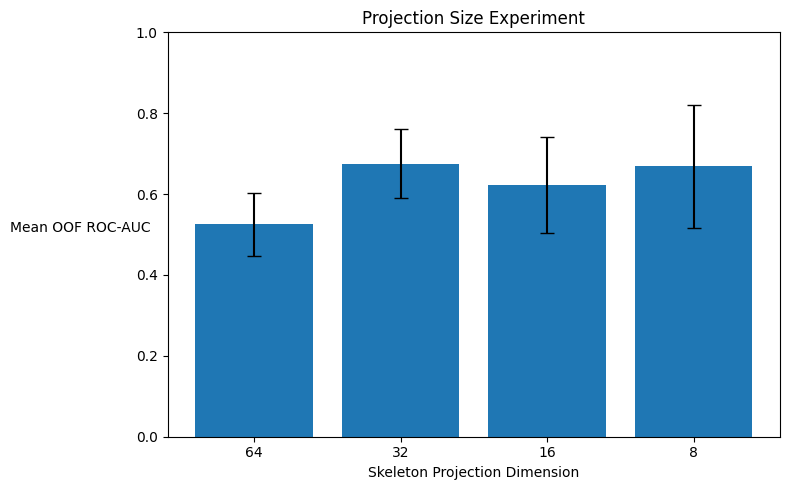

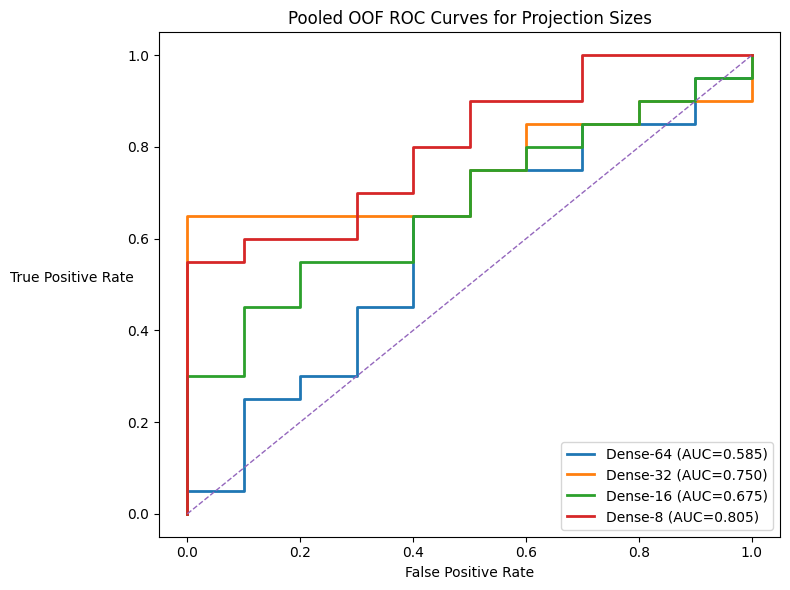

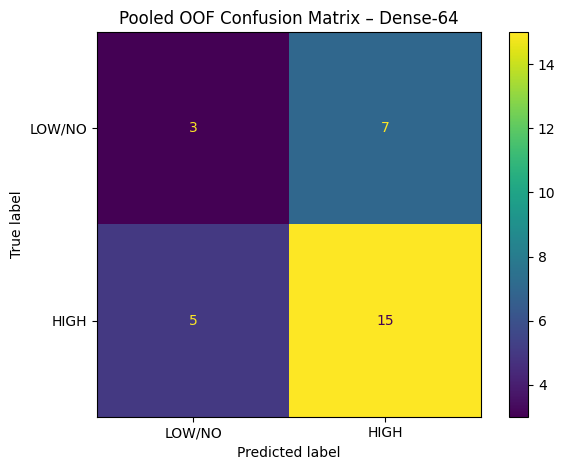

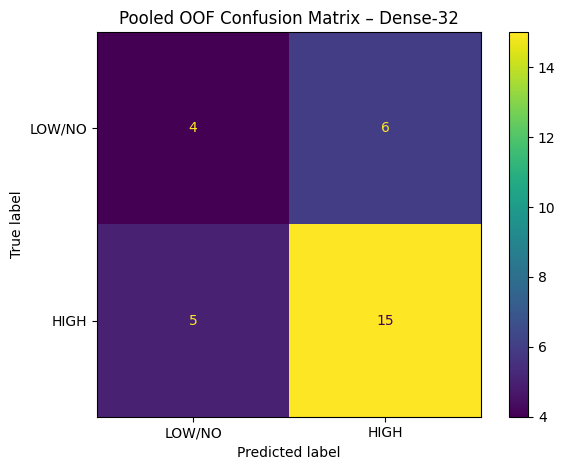

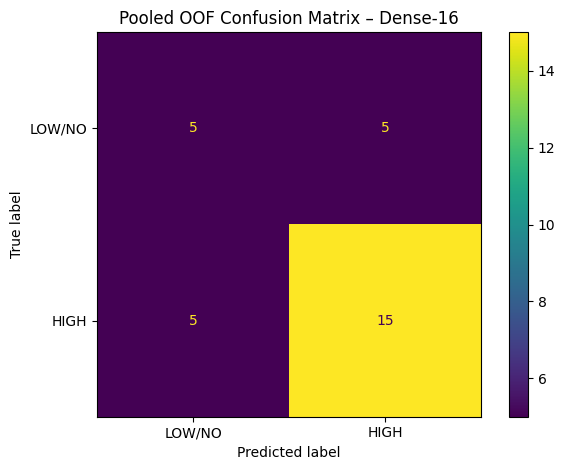

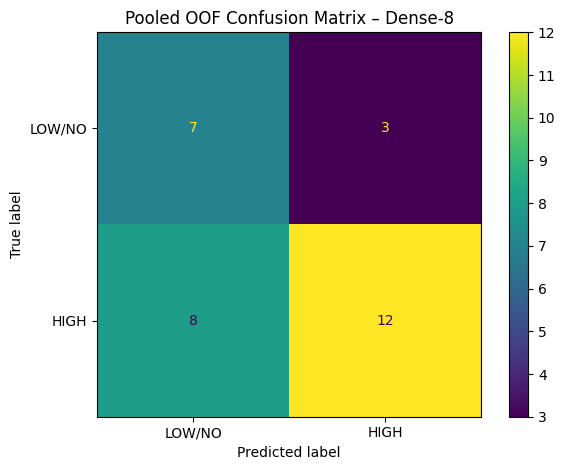

In [ ]:
# ============================================================
# STEP 9: VISUALIZE THE PROJECTION SIZE EXPERIMENT
# ============================================================

plot_df = projection_summary_df.sort_values(
    "projection_dim",
    ascending=False,
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    plot_df["projection_dim"].astype(str),
    plot_df["roc_auc_mean"],
    yerr=plot_df["roc_auc_std"],
    capsize=5,
)
plt.xlabel("Skeleton Projection Dimension")
plt.ylabel("Mean OOF ROC-AUC", rotation=0, labelpad=40)
plt.title("Projection Size Experiment")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(
    PROJECTION_FIGURE_DIR / "Projection_Size_ROC_AUC_Comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

plt.figure(figsize=(8, 6))

for projection_dim in PROJECTION_SIZES:
    subject_probability = (
        projection_predictions_df[
            projection_predictions_df["projection_dim"]
            == projection_dim
        ]
        .groupby(["subject", "true_label"], as_index=False)
        .agg(probability_high=("probability_high", "mean"))
        .set_index("subject")
        .loc[subjects]
    )

    fpr, tpr, _ = roc_curve(
        y,
        subject_probability["probability_high"].to_numpy(),
    )
    auc_value = roc_auc_score(
        y,
        subject_probability["probability_high"].to_numpy(),
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Dense-{projection_dim} (AUC={auc_value:.3f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate", rotation=0, labelpad=40)
plt.title("Pooled OOF ROC Curves for Projection Sizes")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(
    PROJECTION_FIGURE_DIR / "Projection_Size_Pooled_OOF_ROC_Curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

for projection_dim in PROJECTION_SIZES:
    subject_probability = (
        projection_predictions_df[
            projection_predictions_df["projection_dim"]
            == projection_dim
        ]
        .groupby(["subject", "true_label"], as_index=False)
        .agg(probability_high=("probability_high", "mean"))
        .set_index("subject")
        .loc[subjects]
    )

    predicted = (
        subject_probability["probability_high"].to_numpy()
        >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(y, predicted, labels=[0, 1])

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    display_cm.plot(values_format="d")
    plt.title(f"Pooled OOF Confusion Matrix – Dense-{projection_dim}")
    plt.tight_layout()
    plt.savefig(
        PROJECTION_FIGURE_DIR
        / f"Confusion_Matrix_Dense_{projection_dim}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

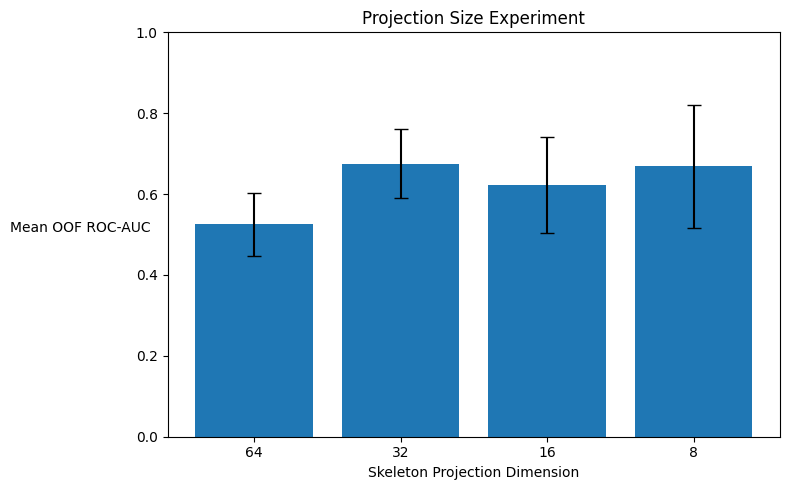

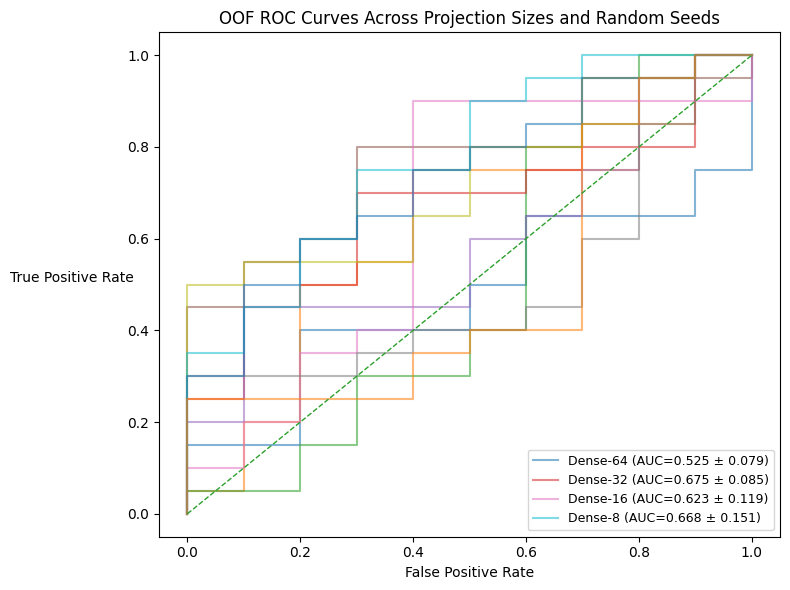

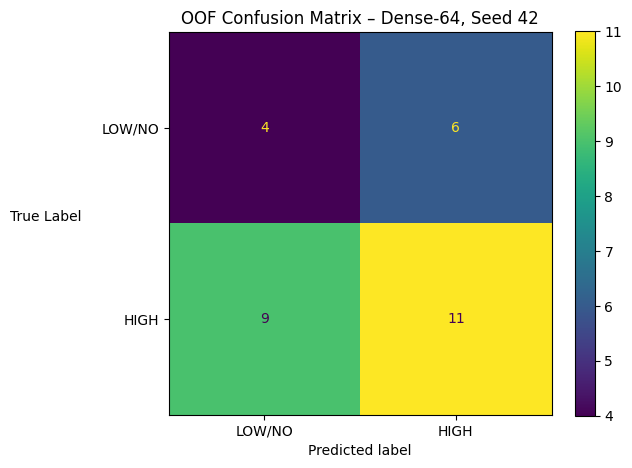

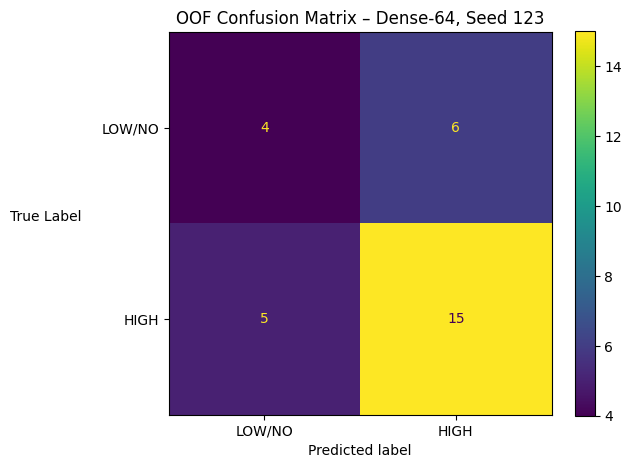

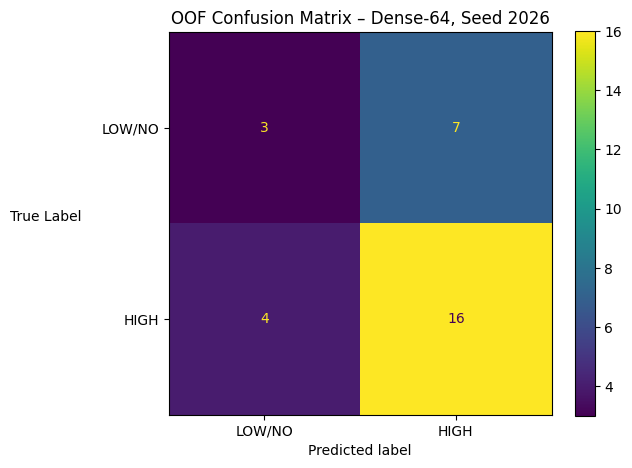

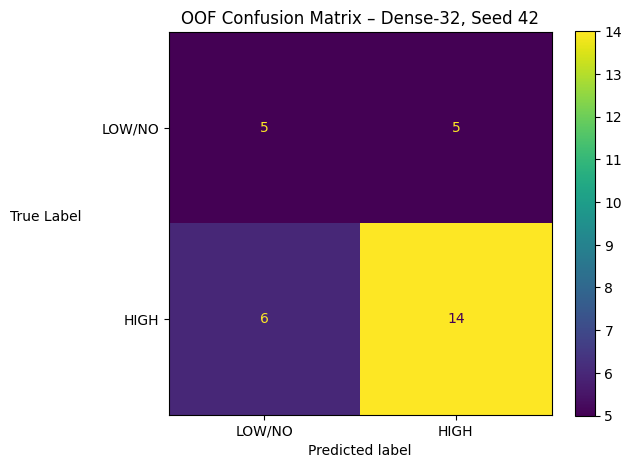

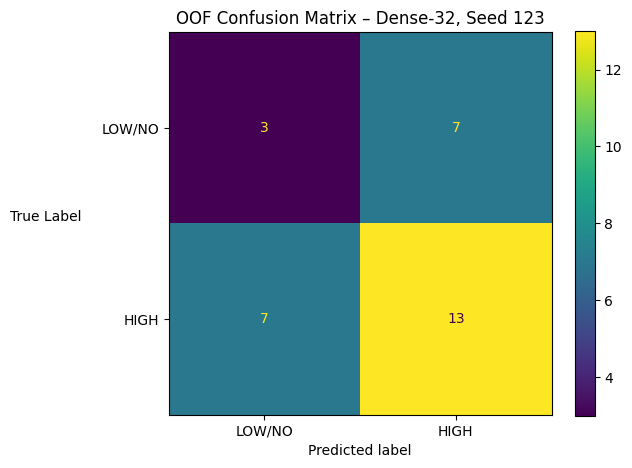

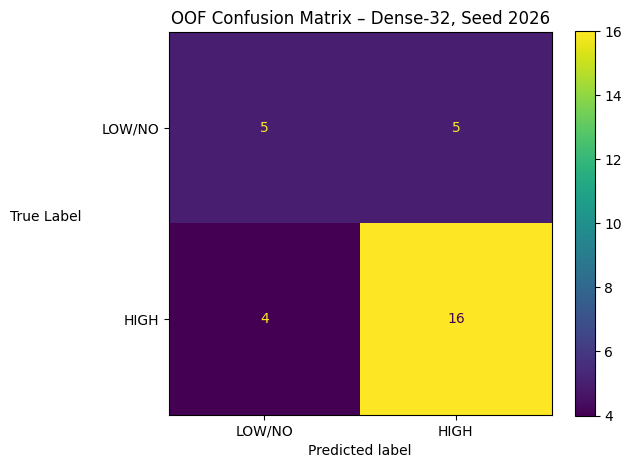

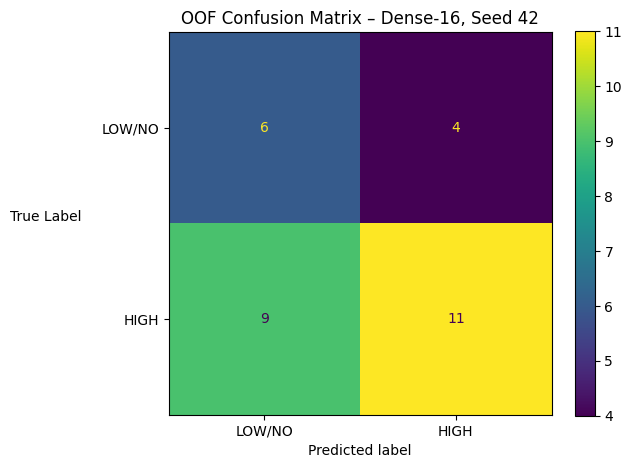

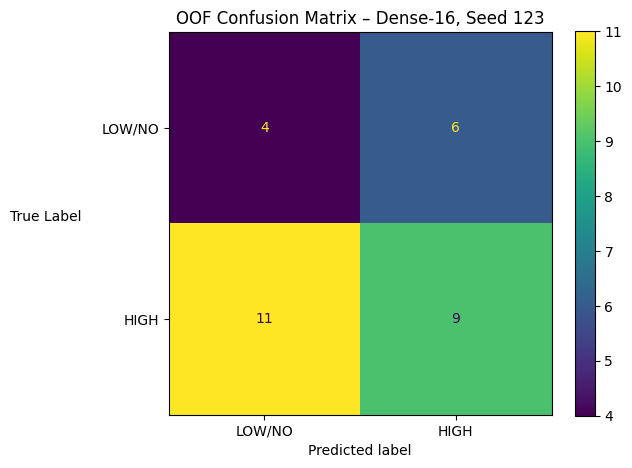

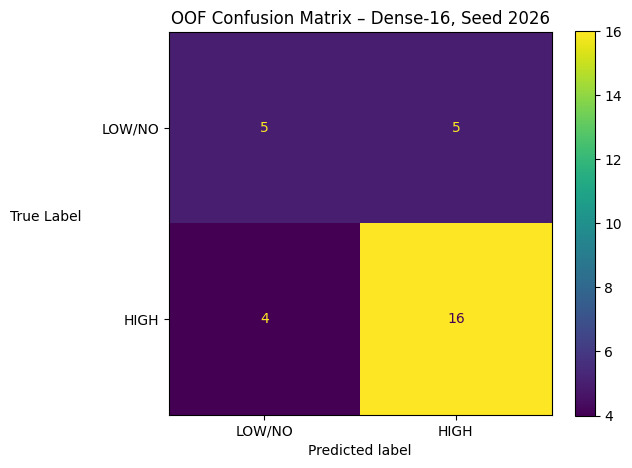

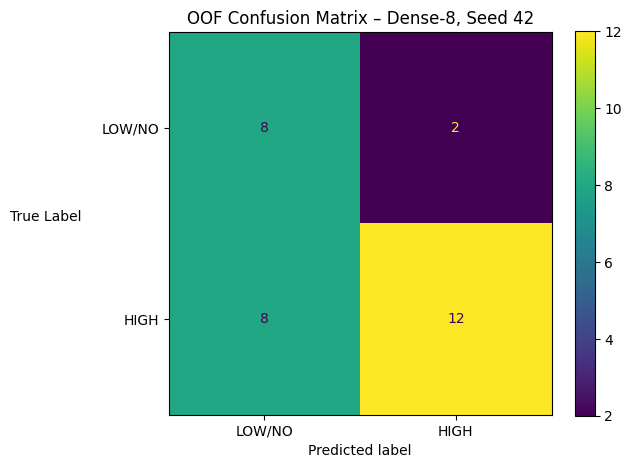

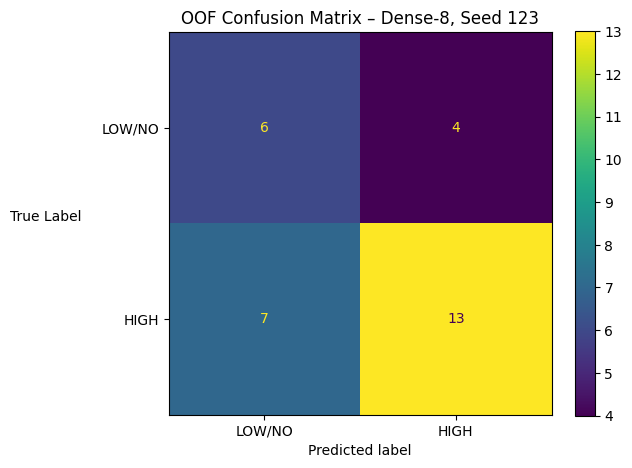

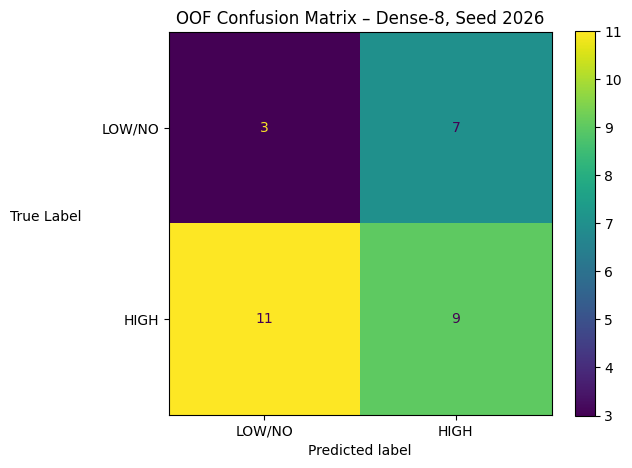

In [ ]:
# ============================================================
# STEP 9: VISUALIZE THE PROJECTION SIZE EXPERIMENT
# Consistent seed-wise evaluation
# ============================================================

plot_df = projection_summary_df.sort_values(
    "projection_dim",
    ascending=False,
)

# ============================================================
# 9A. BAR PLOT: MEAN ROC-AUC ± SD ACROSS SEEDS
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    plot_df["projection_dim"].astype(str),
    plot_df["roc_auc_mean"],
    yerr=plot_df["roc_auc_std"],
    capsize=5,
)

plt.xlabel("Skeleton Projection Dimension")
plt.ylabel(
    "Mean OOF ROC-AUC",
    rotation=0,
    labelpad=40
)
plt.title("Projection Size Experiment")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    PROJECTION_FIGURE_DIR
    / "Projection_Size_ROC_AUC_Comparison_SeedWise.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ============================================================
# 9B. ROC CURVES PER SEED
# ============================================================

plt.figure(figsize=(8, 6))

for projection_dim in PROJECTION_SIZES:

    projection_seed_df = projection_metrics_df[
        projection_metrics_df["projection_dim"]
        == projection_dim
    ]

    mean_auc = projection_seed_df[
        "roc_auc"
    ].mean()

    std_auc = projection_seed_df[
        "roc_auc"
    ].std()

    first_seed = True

    for seed in RANDOM_SEEDS:

        seed_df = (
            projection_predictions_df[
                (
                    projection_predictions_df["projection_dim"]
                    == projection_dim
                )
                &
                (
                    projection_predictions_df["seed"]
                    == seed
                )
            ]
            .set_index("subject")
            .loc[subjects]
        )

        probabilities = seed_df[
            "probability_high"
        ].to_numpy()

        fpr, tpr, _ = roc_curve(
            y,
            probabilities
        )

        if first_seed:
            label = (
                f"Dense-{projection_dim} "
                f"(AUC={mean_auc:.3f} ± {std_auc:.3f})"
            )
            first_seed = False
        else:
            label = None

        plt.plot(
            fpr,
            tpr,
            linewidth=1.5,
            alpha=0.55,
            label=label,
        )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel(
    "True Positive Rate",
    rotation=0,
    labelpad=40
)

plt.title(
    "OOF ROC Curves Across Projection Sizes and Random Seeds"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    PROJECTION_FIGURE_DIR
    / "Projection_Size_OOF_ROC_Curves_By_Seed_SeedWise.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ============================================================
# 9C. CONFUSION MATRICES PER SEED
# ============================================================

for projection_dim in PROJECTION_SIZES:

    for seed in RANDOM_SEEDS:

        seed_df = (
            projection_predictions_df[
                (
                    projection_predictions_df["projection_dim"]
                    == projection_dim
                )
                &
                (
                    projection_predictions_df["seed"]
                    == seed
                )
            ]
            .set_index("subject")
            .loc[subjects]
        )

        probabilities = seed_df[
            "probability_high"
        ].to_numpy()

        predicted = (
            probabilities >= THRESHOLD
        ).astype(int)

        cm = confusion_matrix(
            y,
            predicted,
            labels=[0, 1]
        )

        display_cm = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "LOW/NO",
                "HIGH"
            ],
        )

        display_cm.plot(
            values_format="d"
        )

        plt.ylabel(
            "True Label",
            rotation=0,
            labelpad=40
        )

        plt.title(
            f"OOF Confusion Matrix – "
            f"Dense-{projection_dim}, Seed {seed}"
        )

        plt.tight_layout()

        plt.savefig(
            PROJECTION_FIGURE_DIR
            / (
                f"Confusion_Matrix_"
                f"Dense_{projection_dim}_"
                f"Seed_{seed}.png"
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

# Context Ablation Study

Dua konfigurasi menggunakan **projection dimension terpilih** dan arsitektur MLP yang identik.

| Configuration | Projected Skeleton | Context | Physiological | Phase Duration |
|---|:---:|:---:|:---:|:---:|
| Baseline | ✓ | ✗ | ✓ | ✓ |
| Proposed Context-Aware MLP | ✓ | ✓ | ✓ | ✓ |

Satu-satunya variabel ablation adalah keberadaan fitur context.

In [ ]:
# ============================================================
# STEP 10: RUN REPEATED LOSO CONTEXT ABLATION
#
# Baseline:
# Dense projection + Physiological + Phase Duration
#
# Context-aware:
# Dense projection + Context + Physiological + Phase Duration
#
# IMPORTANT:
# - Both configurations use identical LOSO folds and fold seeds.
# - Primary-seed weights and scalers are saved for BOTH models.
# - The best configuration will be selected automatically and
#   passed to the subsequent OOF SHAP analysis.
# ============================================================
# ============================================================
# SELECT BEST PROJECTION BASED ON EMBEDDING SOURCE
# ============================================================

BEST_PROJECTION_CONFIG = {
    "skeleton_only": 32,
    "attention_fusion": 8,
}

EMBEDDING_SOURCE = "skeleton_only"

SELECTED_PROJECTION_DIM = BEST_PROJECTION_CONFIG[
    EMBEDDING_SOURCE
]

print("=" * 60)
print("Embedding Source :", EMBEDDING_SOURCE)
print("Best Projection  :", SELECTED_PROJECTION_DIM)
print("=" * 60)

ablation_configurations = [
    {
        "model": BASELINE_MODEL_NAME,
        "include_context": False,
    },
    {
        "model": PROPOSED_MODEL_NAME,
        "include_context": True,
    },
]

ablation_prediction_rows = []
ablation_metric_rows = []

baseline_artifact_rows = []
proposed_artifact_rows = []

for configuration in ablation_configurations:
    model_name = configuration["model"]
    include_context = configuration["include_context"]

    print("\n" + "#" * 92)
    print(model_name)
    print("#" * 92)

    for seed in RANDOM_SEEDS:
        set_all_seeds(seed)

        oof_probabilities = np.full(
            len(y),
            np.nan,
            dtype=np.float64,
        )

        for fold, (outer_train_idx, test_idx) in enumerate(
            loo.split(X_raw),
            start=1,
        ):
            # Identical fold seed for baseline and context-aware model.
            fold_seed = (
                seed
                + fold
                + SELECTED_PROJECTION_DIM
            )
            set_all_seeds(fold_seed)

            inner_train_idx, val_idx = make_inner_validation_split(
                outer_train_idx=outer_train_idx,
                y_all=y,
                seed=fold_seed,
            )

            skeleton_scaler = StandardScaler()
            physio_scaler = StandardScaler()
            duration_scaler = StandardScaler()

            Xs_train = skeleton_scaler.fit_transform(
                X_skeleton[inner_train_idx]
            ).astype(np.float32)
            Xs_val = skeleton_scaler.transform(
                X_skeleton[val_idx]
            ).astype(np.float32)
            Xs_test = skeleton_scaler.transform(
                X_skeleton[test_idx]
            ).astype(np.float32)

            Xp_train = physio_scaler.fit_transform(
                X_physio[inner_train_idx]
            ).astype(np.float32)
            Xp_val = physio_scaler.transform(
                X_physio[val_idx]
            ).astype(np.float32)
            Xp_test = physio_scaler.transform(
                X_physio[test_idx]
            ).astype(np.float32)

            Xd_train = duration_scaler.fit_transform(
                X_duration[inner_train_idx]
            ).astype(np.float32)
            Xd_val = duration_scaler.transform(
                X_duration[val_idx]
            ).astype(np.float32)
            Xd_test = duration_scaler.transform(
                X_duration[test_idx]
            ).astype(np.float32)

            if include_context:
                context_scaler = StandardScaler()

                Xc_train = context_scaler.fit_transform(
                    X_context[inner_train_idx]
                ).astype(np.float32)
                Xc_val = context_scaler.transform(
                    X_context[val_idx]
                ).astype(np.float32)
                Xc_test = context_scaler.transform(
                    X_context[test_idx]
                ).astype(np.float32)
            else:
                context_scaler = None
                Xc_train = None
                Xc_val = None
                Xc_test = None

            model = build_multimodal_mlp_model(
                projection_dim=SELECTED_PROJECTION_DIM,
                include_context=include_context,
            )

            history = model.fit(
                pack_model_inputs(
                    Xs_train,
                    Xc_train,
                    Xp_train,
                    Xd_train,
                    include_context=include_context,
                ),
                y[inner_train_idx],
                validation_data=(
                    pack_model_inputs(
                        Xs_val,
                        Xc_val,
                        Xp_val,
                        Xd_val,
                        include_context=include_context,
                    ),
                    y[val_idx],
                ),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict(
                    y[inner_train_idx]
                ),
                callbacks=build_callbacks(),
                verbose=0,
            )

            probability = float(
                model.predict(
                    pack_model_inputs(
                        Xs_test,
                        Xc_test,
                        Xp_test,
                        Xd_test,
                        include_context=include_context,
                    ),
                    verbose=0,
                ).ravel()[0]
            )

            test_position = int(test_idx[0])
            oof_probabilities[test_position] = probability

            # Save primary-seed fold artifacts for BOTH models.
            if seed == PRIMARY_SEED:
                if include_context:
                    weight_path = (
                        PROPOSED_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )
                else:
                    weight_path = (
                        BASELINE_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )

                model.save_weights(weight_path)

                artifact_row = {
                    "model": model_name,
                    "projection_dim": SELECTED_PROJECTION_DIM,
                    "include_context": bool(include_context),
                    "fold": fold,
                    "subject": subjects[test_position],
                    "outer_train_idx": outer_train_idx.tolist(),
                    "inner_train_idx": inner_train_idx.tolist(),
                    "val_idx": val_idx.tolist(),
                    "test_idx": test_idx.tolist(),
                    "skeleton_mean": skeleton_scaler.mean_.tolist(),
                    "skeleton_scale": skeleton_scaler.scale_.tolist(),
                    "physio_mean": physio_scaler.mean_.tolist(),
                    "physio_scale": physio_scaler.scale_.tolist(),
                    "duration_mean": duration_scaler.mean_.tolist(),
                    "duration_scale": duration_scaler.scale_.tolist(),
                    "best_epoch": int(
                        np.argmin(history.history["val_loss"]) + 1
                    ),
                    "weight_path": str(weight_path),
                }

                if include_context:
                    artifact_row["context_mean"] = (
                        context_scaler.mean_.tolist()
                    )
                    artifact_row["context_scale"] = (
                        context_scaler.scale_.tolist()
                    )
                    proposed_artifact_rows.append(artifact_row)
                else:
                    baseline_artifact_rows.append(artifact_row)

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                f"Incomplete OOF predictions for {model_name}, "
                f"seed={seed}"
            )

        metrics = calculate_binary_metrics(
            y,
            oof_probabilities,
        )
        oof_predictions = (
            oof_probabilities >= THRESHOLD
        ).astype(np.int32)

        ablation_metric_rows.append({
            "model": model_name,
            "include_context": include_context,
            "projection_dim": SELECTED_PROJECTION_DIM,
            "seed": seed,
            **metrics,
        })

        for subject_index in range(len(y)):
            ablation_prediction_rows.append({
                "model": model_name,
                "include_context": include_context,
                "projection_dim": SELECTED_PROJECTION_DIM,
                "seed": seed,
                "subject": subjects[subject_index],
                "true_label": int(y[subject_index]),
                "probability_high": float(
                    oof_probabilities[subject_index]
                ),
                "predicted_label": int(
                    oof_predictions[subject_index]
                ),
                "correct": int(
                    oof_predictions[subject_index]
                    == y[subject_index]
                ),
            })

ablation_predictions_df = pd.DataFrame(
    ablation_prediction_rows
)
ablation_metrics_df = pd.DataFrame(
    ablation_metric_rows
)

baseline_artifacts_df = pd.DataFrame(
    baseline_artifact_rows
)
proposed_artifacts_df = pd.DataFrame(
    proposed_artifact_rows
)

baseline_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == PROPOSED_MODEL_NAME
].copy()

baseline_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == PROPOSED_MODEL_NAME
].copy()

baseline_predictions_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_OOF_Predictions.csv",
    index=False,
)
baseline_metrics_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_Performance_By_Seed.csv",
    index=False,
)
baseline_artifacts_df.to_json(
    BASELINE_TABLE_DIR
    / "Baseline_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

proposed_predictions_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_OOF_Predictions.csv",
    index=False,
)
proposed_metrics_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_Performance_By_Seed.csv",
    index=False,
)
proposed_artifacts_df.to_json(
    PROPOSED_TABLE_DIR
    / "Proposed_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

if len(baseline_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Baseline primary-seed fold artifacts are incomplete."
    )

if len(proposed_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Context-aware primary-seed fold artifacts are incomplete."
    )

print("Baseline artifacts     :", len(baseline_artifacts_df))
print("Context-aware artifacts:", len(proposed_artifacts_df))

display(ablation_metrics_df)



############################################################################################
MLP_Dense8_Duration_Physiological
############################################################################################

############################################################################################
MLP_Dense8_Context_Duration_Physiological
############################################################################################
Baseline artifacts     : 30
Context-aware artifacts: 30


,model,include_context,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense8_Duration_Physiological,False,32,42,0.635,0.835228,0.566667,0.550,0.545249,0.550,0.541716,0.5,0.60,5,5,8,12
1,MLP_Dense8_Duration_Physiological,False,32,123,0.550,0.707217,0.600000,0.525,0.528409,0.525,0.523810,0.3,0.75,3,7,5,15
2,MLP_Dense8_Duration_Physiological,False,32,2026,0.570,0.749414,0.600000,0.550,0.550000,0.550,0.550000,0.4,0.70,4,6,6,14
3,MLP_Dense8_Context_Duration_Physiological,True,32,42,0.665,0.833739,0.633333,0.600,0.595694,0.600,0.597070,0.5,0.70,5,5,6,14
4,MLP_Dense8_Context_Duration_Physiological,True,32,123,0.595,0.793972,0.533333,0.475,0.475000,0.475,0.475000,0.3,0.65,3,7,7,13
5,MLP_Dense8_Context_Duration_Physiological,True,32,2026,0.765,0.891007,0.700000,0.650,0.658730,0.650,0.653402,0.5,0.80,5,5,4,16


In [ ]:

# ============================================================
# STEP 10: RUN REPEATED LOSO CONTEXT ABLATION
#          USING SELECTED PROJECTION FROM STEP 8
# ============================================================
#
# Baseline:
#   Skeleton Projection + Physiological + Phase Duration
#
# Context-aware:
#   Skeleton Projection + Context + Physiological
#   + Phase Duration
#
# IMPORTANT:
# - Projection dimension is selected automatically in STEP 8.
# - No hardcoded Dense-8 or Dense-32.
# - Model names match the actual projection dimension.
# - Identical LOSO folds and fold seeds for both models.
# - Primary-seed weights and scalers saved for SHAP.
# ============================================================

# ------------------------------------------------------------
# 10.1 VERIFY SELECTED PROJECTION FROM STEP 8
# ------------------------------------------------------------

if "SELECTED_PROJECTION_DIM" not in globals():
    raise RuntimeError(
        "SELECTED_PROJECTION_DIM not found. "
        "Please run STEP 8 before STEP 10."
    )

SELECTED_PROJECTION_DIM = int(SELECTED_PROJECTION_DIM)

if SELECTED_PROJECTION_DIM not in PROJECTION_SIZES:
    raise ValueError(
        f"Invalid projection: {SELECTED_PROJECTION_DIM}. "
        f"Available projections: {PROJECTION_SIZES}"
    )

# Verify consistency with STEP 8 ranking
expected_projection = int(
    projection_summary_df.iloc[0]["projection_dim"]
)

assert SELECTED_PROJECTION_DIM == expected_projection, (
    f"Projection mismatch! "
    f"STEP 8 selected {expected_projection}, "
    f"but current variable is {SELECTED_PROJECTION_DIM}."
)

# ------------------------------------------------------------
# 10.2 AUTOMATIC MODEL NAMES
# ------------------------------------------------------------

BASELINE_MODEL_NAME = (
    f"MLP_Dense{SELECTED_PROJECTION_DIM}_"
    "Duration_Physiological"
)

PROPOSED_MODEL_NAME = (
    f"MLP_Dense{SELECTED_PROJECTION_DIM}_"
    "Context_Duration_Physiological"
)

print("=" * 80)
print("STEP 10: REPEATED LOSO CONTEXT ABLATION")
print("=" * 80)
print("Selected projection :", SELECTED_PROJECTION_DIM)
print("Baseline model      :", BASELINE_MODEL_NAME)
print("Context-aware model :", PROPOSED_MODEL_NAME)
print("=" * 80)

# ------------------------------------------------------------
# 10.3 ABLATION CONFIGURATIONS
# ------------------------------------------------------------

ablation_configurations = [
    {
        "model": BASELINE_MODEL_NAME,
        "include_context": False,
    },
    {
        "model": PROPOSED_MODEL_NAME,
        "include_context": True,
    },
]

ablation_prediction_rows = []
ablation_metric_rows = []

baseline_artifact_rows = []
proposed_artifact_rows = []

# ------------------------------------------------------------
# 10.4 REPEATED LOSO TRAINING
# ------------------------------------------------------------

for configuration in ablation_configurations:

    model_name = configuration["model"]
    include_context = configuration["include_context"]

    print("\n" + "#" * 92)
    print(model_name)
    print("#" * 92)

    for seed in RANDOM_SEEDS:

        set_all_seeds(seed)

        oof_probabilities = np.full(
            len(y),
            np.nan,
            dtype=np.float64,
        )

        for fold, (outer_train_idx, test_idx) in enumerate(
            loo.split(X_raw),
            start=1,
        ):

            # Identical fold seed for both configurations
            fold_seed = (
                seed
                + fold
                + SELECTED_PROJECTION_DIM
            )

            set_all_seeds(fold_seed)

            inner_train_idx, val_idx = make_inner_validation_split(
                outer_train_idx=outer_train_idx,
                y_all=y,
                seed=fold_seed,
            )

            # ------------------------------------------------
            # SCALERS
            # ------------------------------------------------

            skeleton_scaler = StandardScaler()
            physio_scaler = StandardScaler()
            duration_scaler = StandardScaler()

            Xs_train = skeleton_scaler.fit_transform(
                X_skeleton[inner_train_idx]
            ).astype(np.float32)

            Xs_val = skeleton_scaler.transform(
                X_skeleton[val_idx]
            ).astype(np.float32)

            Xs_test = skeleton_scaler.transform(
                X_skeleton[test_idx]
            ).astype(np.float32)

            Xp_train = physio_scaler.fit_transform(
                X_physio[inner_train_idx]
            ).astype(np.float32)

            Xp_val = physio_scaler.transform(
                X_physio[val_idx]
            ).astype(np.float32)

            Xp_test = physio_scaler.transform(
                X_physio[test_idx]
            ).astype(np.float32)

            Xd_train = duration_scaler.fit_transform(
                X_duration[inner_train_idx]
            ).astype(np.float32)

            Xd_val = duration_scaler.transform(
                X_duration[val_idx]
            ).astype(np.float32)

            Xd_test = duration_scaler.transform(
                X_duration[test_idx]
            ).astype(np.float32)

            # ------------------------------------------------
            # CONTEXT (OPTIONAL)
            # ------------------------------------------------

            if include_context:

                context_scaler = StandardScaler()

                Xc_train = context_scaler.fit_transform(
                    X_context[inner_train_idx]
                ).astype(np.float32)

                Xc_val = context_scaler.transform(
                    X_context[val_idx]
                ).astype(np.float32)

                Xc_test = context_scaler.transform(
                    X_context[test_idx]
                ).astype(np.float32)

            else:

                context_scaler = None
                Xc_train = None
                Xc_val = None
                Xc_test = None

            # ------------------------------------------------
            # BUILD MODEL USING STEP 8 PROJECTION
            # ------------------------------------------------

            model = build_multimodal_mlp_model(
                projection_dim=SELECTED_PROJECTION_DIM,
                include_context=include_context,
            )

            # ------------------------------------------------
            # VERIFY ACTUAL PROJECTION LAYER
            # ------------------------------------------------

            projection_layer = model.get_layer(
                f"skeleton_projection_dense_"
                f"{SELECTED_PROJECTION_DIM}"
            )

            actual_projection = int(projection_layer.units)

            assert actual_projection == SELECTED_PROJECTION_DIM, (
                f"Projection mismatch: "
                f"expected {SELECTED_PROJECTION_DIM}, "
                f"actual {actual_projection}"
            )

            if fold == 1 and seed == RANDOM_SEEDS[0]:
                print(
                    f"Verified {model_name}: "
                    f"actual Dense-{actual_projection}"
                )

            # ------------------------------------------------
            # TRAIN MODEL
            # ------------------------------------------------

            history = model.fit(
                pack_model_inputs(
                    Xs_train,
                    Xc_train,
                    Xp_train,
                    Xd_train,
                    include_context=include_context,
                ),
                y[inner_train_idx],
                validation_data=(
                    pack_model_inputs(
                        Xs_val,
                        Xc_val,
                        Xp_val,
                        Xd_val,
                        include_context=include_context,
                    ),
                    y[val_idx],
                ),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict(
                    y[inner_train_idx]
                ),
                callbacks=build_callbacks(),
                verbose=0,
            )

            # ------------------------------------------------
            # PREDICT HELD-OUT SUBJECT
            # ------------------------------------------------

            probability = float(
                model.predict(
                    pack_model_inputs(
                        Xs_test,
                        Xc_test,
                        Xp_test,
                        Xd_test,
                        include_context=include_context,
                    ),
                    verbose=0,
                ).ravel()[0]
            )

            test_position = int(test_idx[0])

            oof_probabilities[test_position] = probability

            # ------------------------------------------------
            # SAVE PRIMARY-SEED ARTIFACTS
            # ------------------------------------------------

            if seed == PRIMARY_SEED:

                if include_context:

                    weight_path = (
                        PROPOSED_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )

                else:

                    weight_path = (
                        BASELINE_WEIGHT_DIR
                        / (
                            f"fold_{fold:02d}_"
                            f"{subjects[test_position]}.weights.h5"
                        )
                    )

                model.save_weights(weight_path)

                artifact_row = {
                    "model": model_name,
                    "projection_dim": SELECTED_PROJECTION_DIM,
                    "include_context": bool(include_context),
                    "fold": fold,
                    "subject": subjects[test_position],
                    "outer_train_idx": outer_train_idx.tolist(),
                    "inner_train_idx": inner_train_idx.tolist(),
                    "val_idx": val_idx.tolist(),
                    "test_idx": test_idx.tolist(),
                    "skeleton_mean": skeleton_scaler.mean_.tolist(),
                    "skeleton_scale": skeleton_scaler.scale_.tolist(),
                    "physio_mean": physio_scaler.mean_.tolist(),
                    "physio_scale": physio_scaler.scale_.tolist(),
                    "duration_mean": duration_scaler.mean_.tolist(),
                    "duration_scale": duration_scaler.scale_.tolist(),
                    "best_epoch": int(
                        np.argmin(
                            history.history["val_loss"]
                        ) + 1
                    ),
                    "weight_path": str(weight_path),
                }

                if include_context:

                    artifact_row["context_mean"] = (
                        context_scaler.mean_.tolist()
                    )

                    artifact_row["context_scale"] = (
                        context_scaler.scale_.tolist()
                    )

                    proposed_artifact_rows.append(artifact_row)

                else:

                    baseline_artifact_rows.append(artifact_row)

            del model
            tf.keras.backend.clear_session()
            gc.collect()

        # ----------------------------------------------------
        # CHECK COMPLETE OOF PREDICTIONS
        # ----------------------------------------------------

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                f"Incomplete OOF predictions for "
                f"{model_name}, seed={seed}"
            )

        # ----------------------------------------------------
        # EVALUATION
        # ----------------------------------------------------

        metrics = calculate_binary_metrics(
            y,
            oof_probabilities,
        )

        oof_predictions = (
            oof_probabilities >= THRESHOLD
        ).astype(np.int32)

        ablation_metric_rows.append({
            "model": model_name,
            "include_context": include_context,
            "projection_dim": SELECTED_PROJECTION_DIM,
            "seed": seed,
            **metrics,
        })

        for subject_index in range(len(y)):

            ablation_prediction_rows.append({
                "model": model_name,
                "include_context": include_context,
                "projection_dim": SELECTED_PROJECTION_DIM,
                "seed": seed,
                "subject": subjects[subject_index],
                "true_label": int(y[subject_index]),
                "probability_high": float(
                    oof_probabilities[subject_index]
                ),
                "predicted_label": int(
                    oof_predictions[subject_index]
                ),
                "correct": int(
                    oof_predictions[subject_index]
                    == y[subject_index]
                ),
            })

# ------------------------------------------------------------
# 10.5 CREATE RESULT DATAFRAMES
# ------------------------------------------------------------

ablation_predictions_df = pd.DataFrame(
    ablation_prediction_rows
)

ablation_metrics_df = pd.DataFrame(
    ablation_metric_rows
)

baseline_artifacts_df = pd.DataFrame(
    baseline_artifact_rows
)

proposed_artifacts_df = pd.DataFrame(
    proposed_artifact_rows
)

baseline_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_predictions_df = ablation_predictions_df[
    ablation_predictions_df["model"] == PROPOSED_MODEL_NAME
].copy()

baseline_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == BASELINE_MODEL_NAME
].copy()

proposed_metrics_df = ablation_metrics_df[
    ablation_metrics_df["model"] == PROPOSED_MODEL_NAME
].copy()

# ------------------------------------------------------------
# 10.6 SAVE RESULTS
# ------------------------------------------------------------

baseline_predictions_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_OOF_Predictions.csv",
    index=False,
)

baseline_metrics_df.to_csv(
    BASELINE_TABLE_DIR / "Baseline_Performance_By_Seed.csv",
    index=False,
)

baseline_artifacts_df.to_json(
    BASELINE_TABLE_DIR
    / "Baseline_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

proposed_predictions_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_OOF_Predictions.csv",
    index=False,
)

proposed_metrics_df.to_csv(
    PROPOSED_TABLE_DIR / "Proposed_Performance_By_Seed.csv",
    index=False,
)

proposed_artifacts_df.to_json(
    PROPOSED_TABLE_DIR
    / "Proposed_Primary_Seed_Fold_Artifacts.json",
    orient="records",
    indent=2,
)

# ------------------------------------------------------------
# 10.7 FINAL VERIFICATION
# ------------------------------------------------------------

if len(baseline_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Baseline primary-seed fold artifacts are incomplete."
    )

if len(proposed_artifacts_df) != len(subjects):
    raise RuntimeError(
        "Context-aware primary-seed fold artifacts are incomplete."
    )

print("\n" + "=" * 80)
print("STEP 10 COMPLETED")
print("=" * 80)

print("Selected projection :", SELECTED_PROJECTION_DIM)
print("Baseline model      :", BASELINE_MODEL_NAME)
print("Context-aware model :", PROPOSED_MODEL_NAME)

print(
    "Baseline artifacts     :",
    len(baseline_artifacts_df)
)

print(
    "Context-aware artifacts:",
    len(proposed_artifacts_df)
)

print("=" * 80)

display(ablation_metrics_df)


STEP 10: REPEATED LOSO CONTEXT ABLATION
Selected projection : 32
Baseline model      : MLP_Dense32_Duration_Physiological
Context-aware model : MLP_Dense32_Context_Duration_Physiological

############################################################################################
MLP_Dense32_Duration_Physiological
############################################################################################
Verified MLP_Dense32_Duration_Physiological: actual Dense-32

############################################################################################
MLP_Dense32_Context_Duration_Physiological
############################################################################################
Verified MLP_Dense32_Context_Duration_Physiological: actual Dense-32

STEP 10 COMPLETED
Selected projection : 32
Baseline model      : MLP_Dense32_Duration_Physiological
Context-aware model : MLP_Dense32_Context_Duration_Physiological
Baseline artifacts     : 30
Context-aware artifacts: 30


,model,include_context,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense32_Duration_Physiological,False,32,42,0.635,0.835228,0.566667,0.550,0.545249,0.550,0.541716,0.5,0.60,5,5,8,12
1,MLP_Dense32_Duration_Physiological,False,32,123,0.550,0.707217,0.600000,0.525,0.528409,0.525,0.523810,0.3,0.75,3,7,5,15
2,MLP_Dense32_Duration_Physiological,False,32,2026,0.570,0.749414,0.600000,0.550,0.550000,0.550,0.550000,0.4,0.70,4,6,6,14
3,MLP_Dense32_Context_Duration_Physiological,True,32,42,0.665,0.833739,0.633333,0.600,0.595694,0.600,0.597070,0.5,0.70,5,5,6,14
4,MLP_Dense32_Context_Duration_Physiological,True,32,123,0.595,0.793972,0.533333,0.475,0.475000,0.475,0.475000,0.3,0.65,3,7,7,13
5,MLP_Dense32_Context_Duration_Physiological,True,32,2026,0.765,0.891007,0.700000,0.650,0.658730,0.650,0.653402,0.5,0.80,5,5,4,16


In [ ]:
# ============================================================
# STEP 11: SUMMARIZE CONTEXT ABLATION PERFORMANCE
# ============================================================

ablation_metric_columns = [
    "roc_auc",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "specificity_low_no",
    "sensitivity_high",
]

ablation_summary_rows = []

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    subset = ablation_metrics_df[
        ablation_metrics_df["model"] == model_name
    ]

    summary_row = {
        "model": model_name,
        "projection_dim": SELECTED_PROJECTION_DIM,
        "context_included": bool(
            subset["include_context"].iloc[0]
        ),
        "fusion_dimension": (
            SELECTED_PROJECTION_DIM
            + len(PHYSIO_COLS)
            + len(DURATION_COLS)
            + (
                len(CONTEXT_COLS)
                if bool(subset["include_context"].iloc[0])
                else 0
            )
        ),
    }

    for metric in ablation_metric_columns:
        summary_row[f"{metric}_mean"] = subset[metric].mean()
        summary_row[f"{metric}_std"] = subset[metric].std(ddof=1)

    ablation_summary_rows.append(summary_row)

ablation_summary_df = pd.DataFrame(
    ablation_summary_rows
)

ablation_summary_df["delta_roc_auc_vs_baseline"] = (
    ablation_summary_df["roc_auc_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "roc_auc_mean",
    ].iloc[0]
)

ablation_summary_df["delta_macro_f1_vs_baseline"] = (
    ablation_summary_df["macro_f1_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "macro_f1_mean",
    ].iloc[0]
)

ablation_summary_df[
    "delta_balanced_accuracy_vs_baseline"
] = (
    ablation_summary_df["balanced_accuracy_mean"]
    - ablation_summary_df.loc[
        ablation_summary_df["model"] == BASELINE_MODEL_NAME,
        "balanced_accuracy_mean",
    ].iloc[0]
)

ablation_summary_df.to_csv(
    COMPARISON_TABLE_DIR / "Context_Ablation_Performance_Summary.csv",
    index=False,
)

display(ablation_summary_df)

,model,projection_dim,context_included,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std,delta_roc_auc_vs_baseline,delta_macro_f1_vs_baseline,delta_balanced_accuracy_vs_baseline
0,MLP_Dense32_Duration_Physiological,32,False,42,0.585,0.044441,0.763953,0.065232,0.588889,0.019245,0.541667,0.014434,0.541219,0.011345,0.541667,0.014434,0.538508,0.013387,0.400000,0.10000,0.683333,0.076376,0.00,0.000000,0.000000
1,MLP_Dense32_Context_Duration_Physiological,32,True,46,0.675,0.085440,0.839573,0.048780,0.622222,0.083887,0.575000,0.090139,0.576475,0.093361,0.575000,0.090139,0.575157,0.091197,0.433333,0.11547,0.716667,0.076376,0.09,0.036649,0.033333


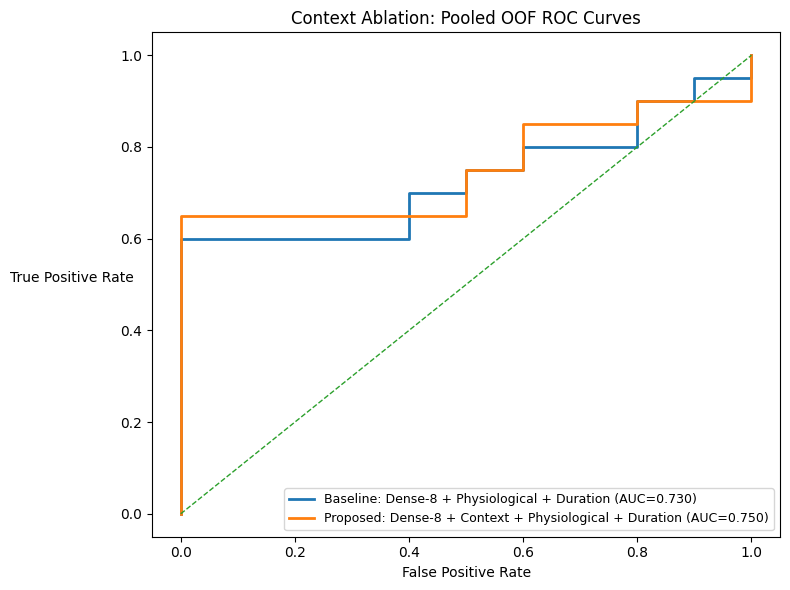

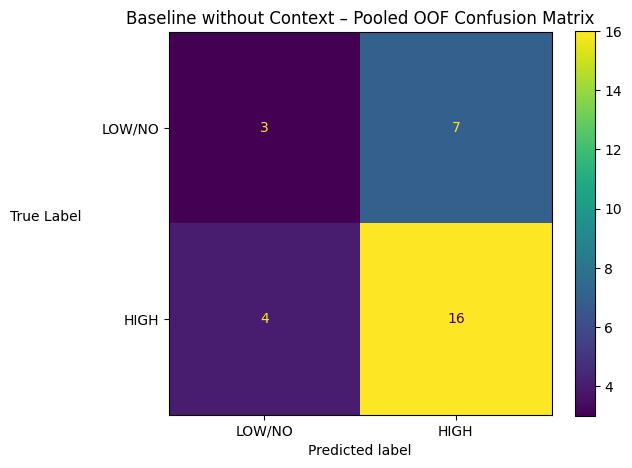

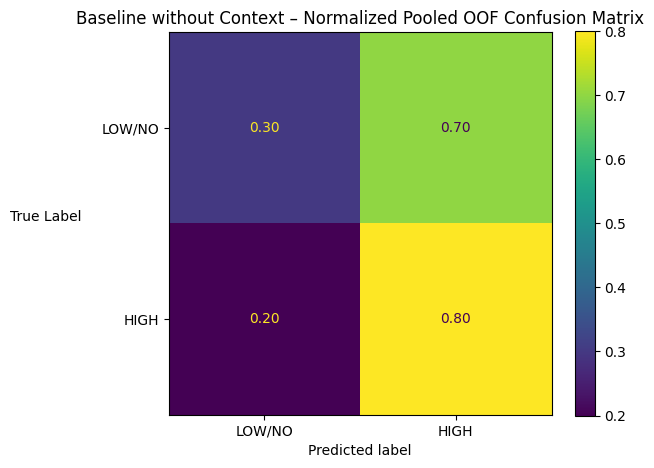

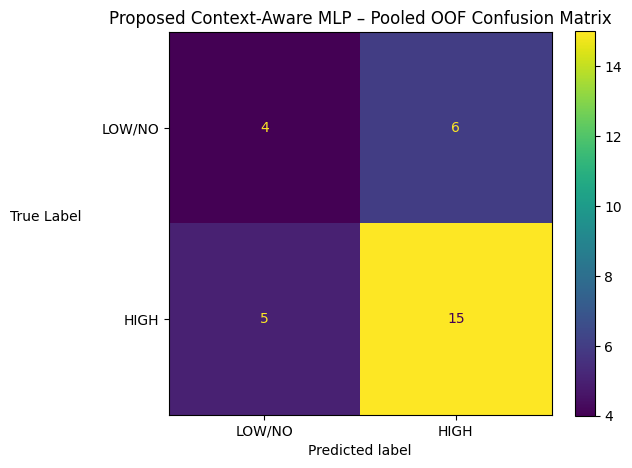

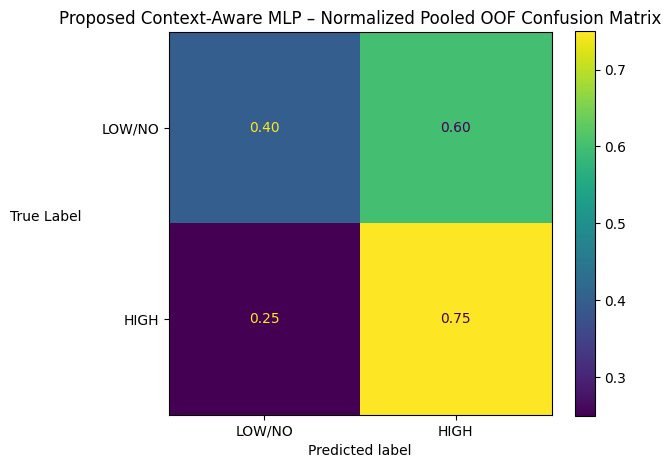

,model,projection_dim,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense32_Duration_Physiological,32,0.73,0.886865,0.633333,0.550,0.562112,0.550,0.548564,0.3,0.80,3,7,4,16
1,MLP_Dense32_Context_Duration_Physiological,32,0.75,0.898370,0.633333,0.575,0.579365,0.575,0.576380,0.4,0.75,4,6,5,15


In [ ]:
# ============================================================
# STEP 12: POOLED OOF EVALUATION, ROC CURVES, AND CONFUSION MATRICES
# ============================================================

pooled_prediction_rows = []
pooled_metric_rows = []

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    model_predictions = ablation_predictions_df[
        ablation_predictions_df["model"] == model_name
    ]

    pooled_df = (
        model_predictions
        .groupby(["subject", "true_label"], as_index=False)
        .agg(
            probability_high=("probability_high", "mean"),
            probability_std=("probability_high", "std"),
        )
        .set_index("subject")
        .loc[subjects]
        .reset_index()
    )

    pooled_probabilities = pooled_df[
        "probability_high"
    ].to_numpy(dtype=float)

    pooled_metrics = calculate_binary_metrics(
        y,
        pooled_probabilities,
    )

    pooled_metric_rows.append({
        "model": model_name,
        "projection_dim": SELECTED_PROJECTION_DIM,
        **pooled_metrics,
    })

    pooled_df["model"] = model_name
    pooled_df["predicted_label"] = (
        pooled_probabilities >= THRESHOLD
    ).astype(int)
    pooled_prediction_rows.append(pooled_df)

pooled_predictions_df = pd.concat(
    pooled_prediction_rows,
    ignore_index=True,
)
pooled_metrics_df = pd.DataFrame(
    pooled_metric_rows
)

pooled_predictions_df.to_csv(
    COMPARISON_TABLE_DIR / "Pooled_OOF_Predictions.csv",
    index=False,
)
pooled_metrics_df.to_csv(
    COMPARISON_TABLE_DIR / "Pooled_OOF_Performance.csv",
    index=False,
)

plt.figure(figsize=(8, 6))

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:
    model_pooled = (
        pooled_predictions_df[
            pooled_predictions_df["model"] == model_name
        ]
        .set_index("subject")
        .loc[subjects]
    )

    probabilities = model_pooled[
        "probability_high"
    ].to_numpy()

    fpr, tpr, _ = roc_curve(y, probabilities)
    auc_value = roc_auc_score(y, probabilities)

    display_name = (
        "Baseline: Dense-8 + Physiological + Duration"
        if model_name == BASELINE_MODEL_NAME
        else "Proposed: Dense-8 + Context + Physiological + Duration"
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{display_name} (AUC={auc_value:.3f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate", rotation=0, labelpad=35)
plt.title("Context Ablation: Pooled OOF ROC Curves")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(
    COMPARISON_FIGURE_DIR / "Context_Ablation_Pooled_OOF_ROC.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

for model_name, figure_dir in [
    (BASELINE_MODEL_NAME, BASELINE_FIGURE_DIR),
    (PROPOSED_MODEL_NAME, PROPOSED_FIGURE_DIR),
]:
    model_pooled = (
        pooled_predictions_df[
            pooled_predictions_df["model"] == model_name
        ]
        .set_index("subject")
        .loc[subjects]
    )

    probabilities = model_pooled[
        "probability_high"
    ].to_numpy()

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(y, predictions, labels=[0, 1])

    display_name = (
        "Baseline without Context"
        if model_name == BASELINE_MODEL_NAME
        else "Proposed Context-Aware MLP"
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    display_cm.plot(values_format="d")
    plt.ylabel("True Label", rotation=0, labelpad=40)
    plt.title(f"{display_name} – Pooled OOF Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        figure_dir / "Pooled_OOF_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    normalized_cm = confusion_matrix(
        y,
        predictions,
        labels=[0, 1],
        normalize="true"
    )

    normalized_display = ConfusionMatrixDisplay(
        confusion_matrix=normalized_cm,
        display_labels=["LOW/NO", "HIGH"],
    )
    normalized_display.plot(values_format=".2f")
    plt.ylabel("True Label", rotation=0, labelpad=40)
    plt.title(
        f"{display_name} – Normalized Pooled OOF Confusion Matrix"
    )
    plt.tight_layout()
    plt.savefig(
        figure_dir / "Normalized_Pooled_OOF_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

display(pooled_metrics_df)

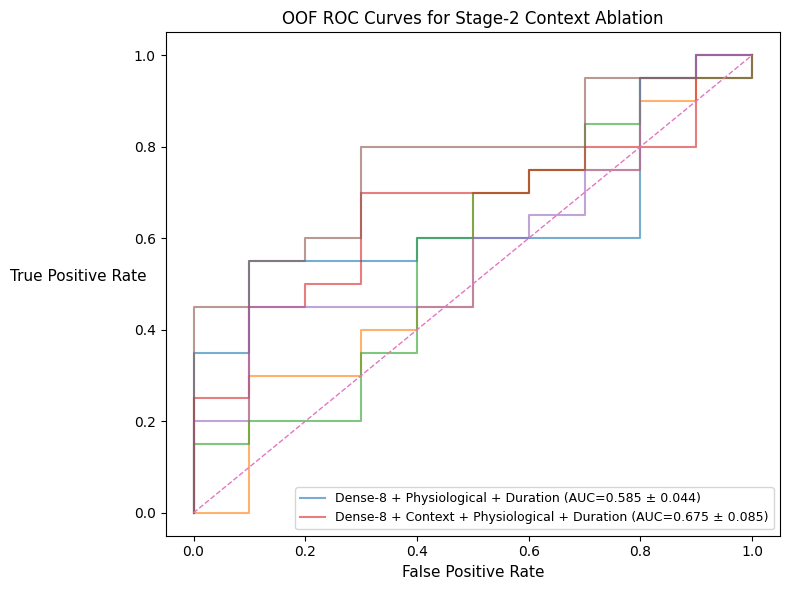

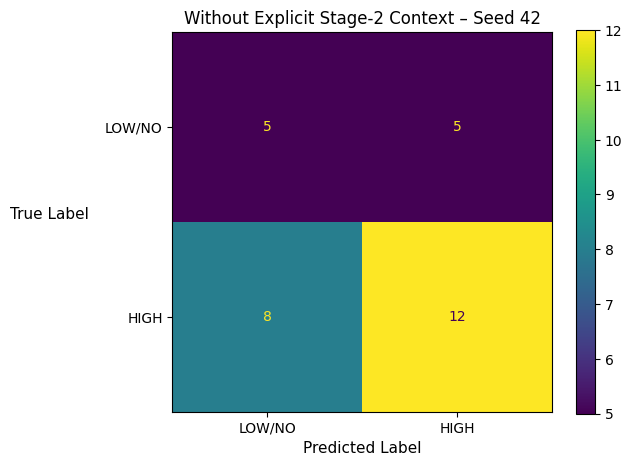

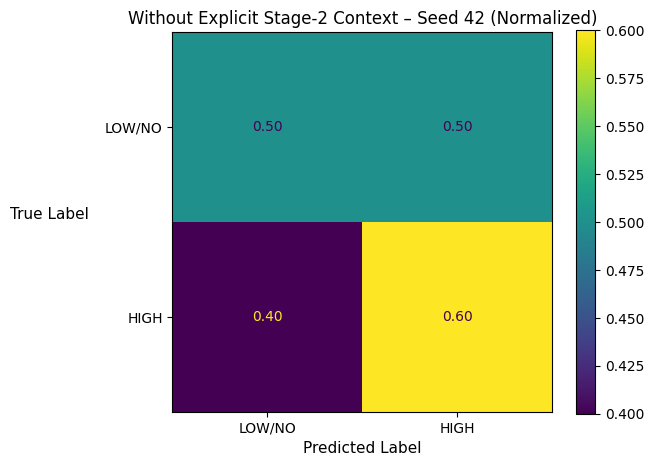

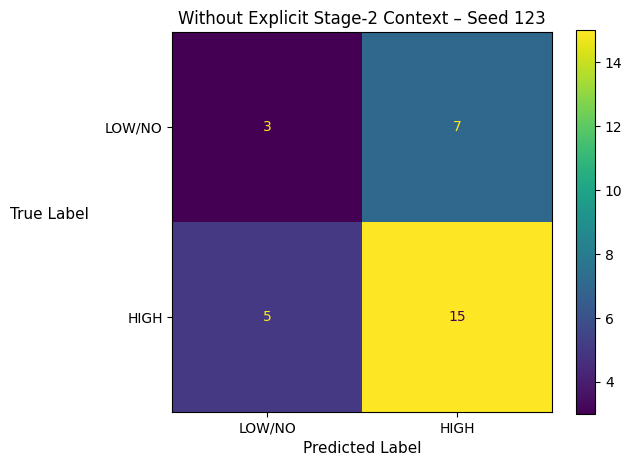

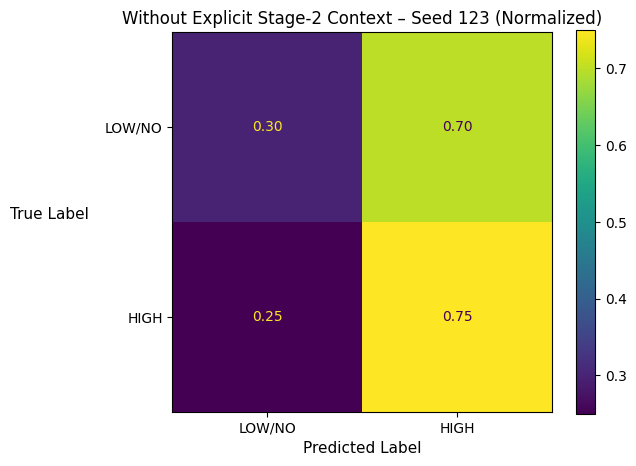

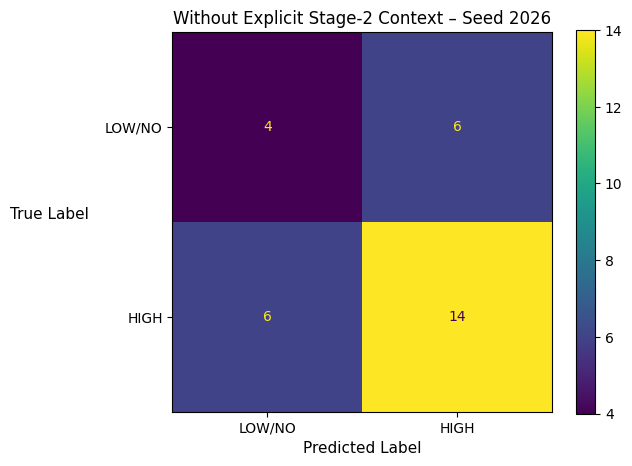

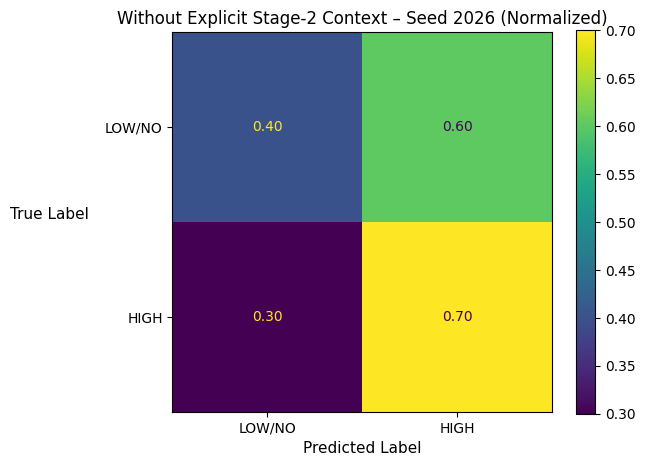

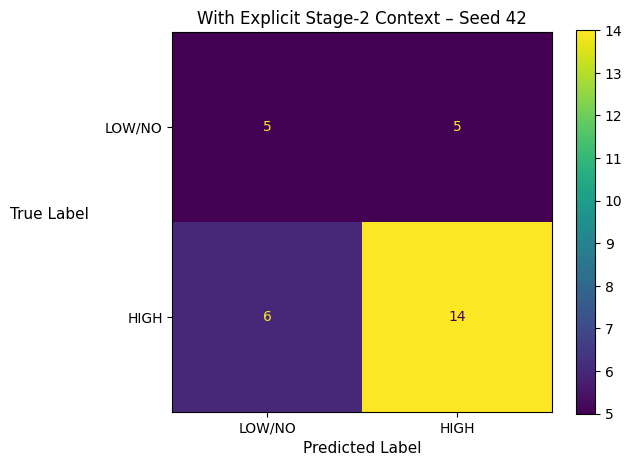

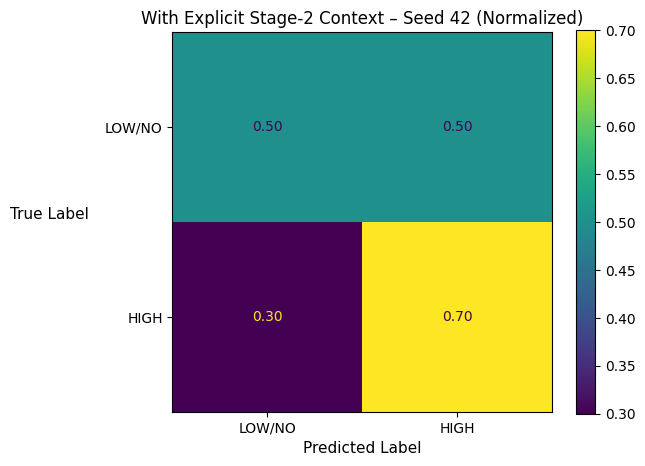

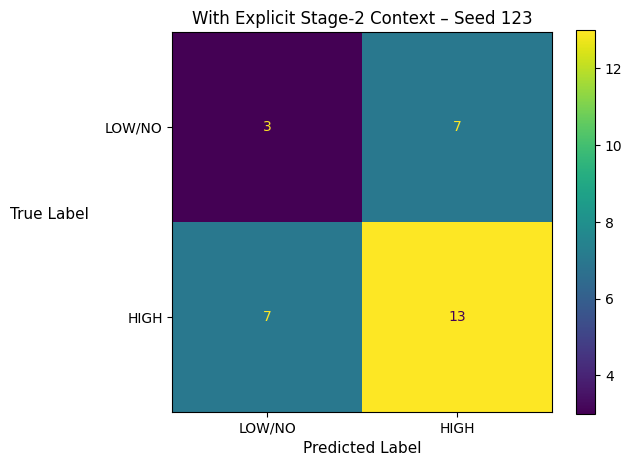

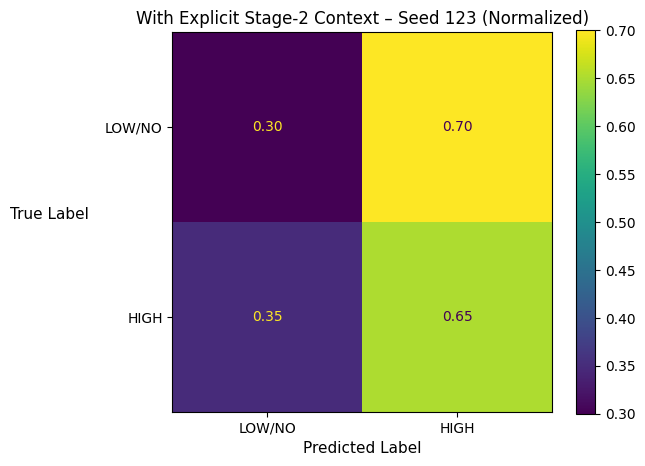

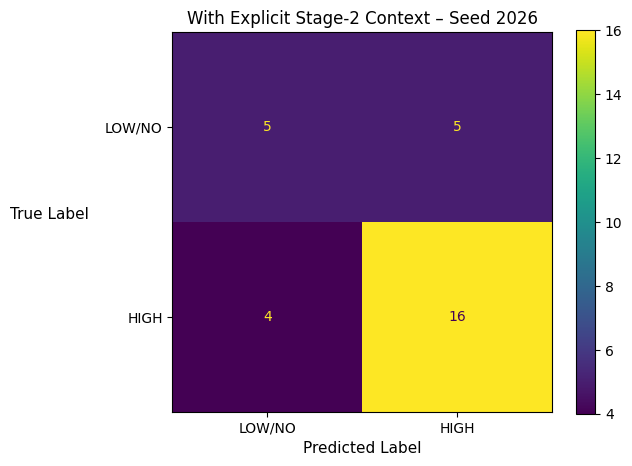

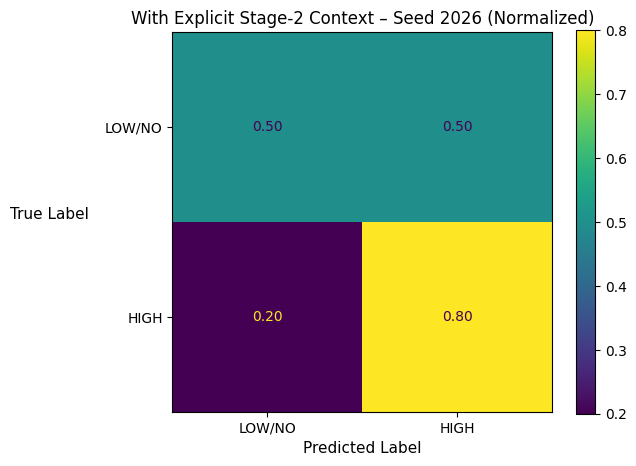


SEED-WISE STAGE-2 CONTEXT ABLATION PERFORMANCE


,model,include_context,projection_dim,seed,roc_auc,pr_auc,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,specificity_low_no,sensitivity_high,tn,fp,fn,tp
0,MLP_Dense32_Duration_Physiological,False,32,42,0.635,0.835228,0.566667,0.550,0.545249,0.550,0.541716,0.5,0.60,5,5,8,12
1,MLP_Dense32_Duration_Physiological,False,32,123,0.550,0.707217,0.600000,0.525,0.528409,0.525,0.523810,0.3,0.75,3,7,5,15
2,MLP_Dense32_Duration_Physiological,False,32,2026,0.570,0.749414,0.600000,0.550,0.550000,0.550,0.550000,0.4,0.70,4,6,6,14
3,MLP_Dense32_Context_Duration_Physiological,True,32,42,0.665,0.833739,0.633333,0.600,0.595694,0.600,0.597070,0.5,0.70,5,5,6,14
4,MLP_Dense32_Context_Duration_Physiological,True,32,123,0.595,0.793972,0.533333,0.475,0.475000,0.475,0.475000,0.3,0.65,3,7,7,13
5,MLP_Dense32_Context_Duration_Physiological,True,32,2026,0.765,0.891007,0.700000,0.650,0.658730,0.650,0.653402,0.5,0.80,5,5,4,16



MEAN ± SD ACROSS RANDOM SEEDS


roc_auc              pr_auc  \
                                              mean       std      mean   
model                                                                    
MLP_Dense32_Context_Duration_Physiological   0.675  0.085440  0.839573   
MLP_Dense32_Duration_Physiological           0.585  0.044441  0.763953   

                                                      accuracy            \
                                                 std      mean       std   
model                                                                      
MLP_Dense32_Context_Duration_Physiological  0.048780  0.622222  0.083887   
MLP_Dense32_Duration_Physiological          0.065232  0.588889  0.019245   

                                           balanced_accuracy            \
                                                        mean       std   
model                                                                    
MLP_Dense32_Context_Duration_Physiological          0.575000  0.090139   
MLP_Dense32_Duration_Physiological                  0.541667  0.014434   

                                           macro_precision            \
                                                      mean       std   
model                                                                  
MLP_Dense32_Context_Duration_Physiological        0.576475  0.093361   
MLP_Dense32_Duration_Physiological                0.541219  0.011345   

                                           macro_recall            macro_f1  \
                                                   mean       std      mean   
model                                                                         
MLP_Dense32_Context_Duration_Physiological     0.575000  0.090139  0.575157   
MLP_Dense32_Duration_Physiological             0.541667  0.014434  0.538508   

                                                     specificity_low_no  \
                                                 std               mean   
model                                                                     
MLP_Dense32_Context_Duration_Physiological  0.091197           0.433333   
MLP_Dense32_Duration_Physiological          0.013387           0.400000   

                                                    sensitivity_high            
                                                std             mean       std  
model                                                                           
MLP_Dense32_Context_Duration_Physiological  0.11547         0.716667  0.076376  
MLP_Dense32_Duration_Physiological          0.10000         0.683333  0.076376

In [ ]:
# ============================================================
# STEP 12B: SEED-WISE OOF EVALUATION
# ROC CURVES + CONFUSION MATRICES
#
# Comparison:
# 1. Without Explicit Stage-2 Context
#    Dense-8 + Physiological + Duration
#
# 2. With Explicit Stage-2 Context
#    Dense-8 + Context + Physiological + Duration
#
# Evaluation:
# - 30 LOSO OOF predictions are collected PER SEED.
# - ROC-AUC is calculated separately for each seed.
# - Legend reports Mean ROC-AUC ± SD across seeds.
# - Confusion matrices are generated separately per seed.
# ============================================================


# ============================================================
# 12B.1: SEED-WISE OOF ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for model_name in [
    BASELINE_MODEL_NAME,
    PROPOSED_MODEL_NAME,
]:

    # --------------------------------------------------------
    # GET METRICS ACROSS SEEDS
    # --------------------------------------------------------
    model_metrics = ablation_metrics_df[
        ablation_metrics_df["model"] == model_name
    ]

    mean_auc = model_metrics["roc_auc"].mean()
    std_auc = model_metrics["roc_auc"].std()

    # --------------------------------------------------------
    # DISPLAY NAME
    # --------------------------------------------------------
    if model_name == BASELINE_MODEL_NAME:

        display_name = (
            "Dense-8 + Physiological + Duration"
        )

    else:

        display_name = (
            "Dense-8 + Context + Physiological + Duration"
        )

    first_seed = True

    # --------------------------------------------------------
    # ROC FOR EACH RANDOM SEED
    # --------------------------------------------------------
    for seed in RANDOM_SEEDS:

        seed_df = (
            ablation_predictions_df[
                (
                    ablation_predictions_df["model"]
                    == model_name
                )
                &
                (
                    ablation_predictions_df["seed"]
                    == seed
                )
            ]
            .set_index("subject")
            .loc[subjects]
        )

        probabilities = seed_df[
            "probability_high"
        ].to_numpy()

        fpr, tpr, _ = roc_curve(
            y,
            probabilities,
        )

        # Only one legend entry for each model
        if first_seed:

            label = (
                f"{display_name} "
                f"(AUC={mean_auc:.3f} ± {std_auc:.3f})"
            )

            first_seed = False

        else:

            label = None

        plt.plot(
            fpr,
            tpr,
            linewidth=1.5,
            alpha=0.60,
            label=label,
        )


# ------------------------------------------------------------
# RANDOM CLASSIFIER REFERENCE
# ------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
)

plt.xlabel(
    "False Positive Rate",
    fontsize=11,
)

plt.ylabel(
    "True Positive Rate",
    rotation=0,
    labelpad=40,
    fontsize=11,
)

plt.title(
    "OOF ROC Curves for Stage-2 Context Ablation"
)

plt.legend(
    loc="lower right",
    fontsize=9,
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "Context_Ablation_OOF_ROC_SeedWise.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ============================================================
# 12B.2: SEED-WISE CONFUSION MATRICES
# ============================================================

for model_name, figure_dir in [

    (
        BASELINE_MODEL_NAME,
        BASELINE_FIGURE_DIR,
    ),

    (
        PROPOSED_MODEL_NAME,
        PROPOSED_FIGURE_DIR,
    ),

]:

    # --------------------------------------------------------
    # DISPLAY NAME
    # --------------------------------------------------------

    if model_name == BASELINE_MODEL_NAME:

        display_name = (
            "Without Explicit Stage-2 Context"
        )

    else:

        display_name = (
            "With Explicit Stage-2 Context"
        )


    # --------------------------------------------------------
    # CONFUSION MATRIX FOR EACH SEED
    # --------------------------------------------------------

    for seed in RANDOM_SEEDS:

        seed_df = (
            ablation_predictions_df[
                (
                    ablation_predictions_df["model"]
                    == model_name
                )
                &
                (
                    ablation_predictions_df["seed"]
                    == seed
                )
            ]
            .set_index("subject")
            .loc[subjects]
        )

        probabilities = seed_df[
            "probability_high"
        ].to_numpy()

        predictions = (
            probabilities >= THRESHOLD
        ).astype(int)


        # ====================================================
        # RAW CONFUSION MATRIX
        # ====================================================

        cm = confusion_matrix(
            y,
            predictions,
            labels=[0, 1],
        )

        display_cm = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "LOW/NO",
                "HIGH",
            ],
        )

        display_cm.plot(
            values_format="d"
        )

        plt.ylabel(
            "True Label",
            rotation=0,
            labelpad=40,
            fontsize=11,
        )

        plt.xlabel(
            "Predicted Label",
            fontsize=11,
        )

        plt.title(
            f"{display_name} – Seed {seed}"
        )

        plt.tight_layout()

        plt.savefig(
            figure_dir
            / (
                f"Confusion_Matrix_"
                f"Seed_{seed}_SeedWise.png"
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()


        # ====================================================
        # NORMALIZED CONFUSION MATRIX
        # ====================================================

        normalized_cm = confusion_matrix(
            y,
            predictions,
            labels=[0, 1],
            normalize="true",
        )

        normalized_display = ConfusionMatrixDisplay(
            confusion_matrix=normalized_cm,
            display_labels=[
                "LOW/NO",
                "HIGH",
            ],
        )

        normalized_display.plot(
            values_format=".2f"
        )

        plt.ylabel(
            "True Label",
            rotation=0,
            labelpad=40,
            fontsize=11,
        )

        plt.xlabel(
            "Predicted Label",
            fontsize=11,
        )

        plt.title(
            f"{display_name} – Seed {seed} (Normalized)"
        )

        plt.tight_layout()

        plt.savefig(
            figure_dir
            / (
                f"Normalized_Confusion_Matrix_"
                f"Seed_{seed}_SeedWise.png"
            ),
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()


# ============================================================
# 12B.3: DISPLAY SEED-WISE PERFORMANCE
# ============================================================

seedwise_context_performance = (
    ablation_metrics_df[
        ablation_metrics_df["model"].isin(
            [
                BASELINE_MODEL_NAME,
                PROPOSED_MODEL_NAME,
            ]
        )
    ]
    .copy()
)

print("\n" + "=" * 90)
print("SEED-WISE STAGE-2 CONTEXT ABLATION PERFORMANCE")
print("=" * 90)

display(
    seedwise_context_performance
)


# ============================================================
# 12B.4: SUMMARY MEAN ± SD ACROSS SEEDS
# ============================================================

metric_columns = [
    "roc_auc",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "specificity_low_no",
    "sensitivity_high",
]

available_metrics = [
    col
    for col in metric_columns
    if col in seedwise_context_performance.columns
]

context_seed_summary = (
    seedwise_context_performance
    .groupby("model")[
        available_metrics
    ]
    .agg(["mean", "std"])
)

print("\n" + "=" * 90)
print("MEAN ± SD ACROSS RANDOM SEEDS")
print("=" * 90)

display(
    context_seed_summary
)


MEAN NORMALIZED OOF CONFUSION MATRIX ACROSS 3 SEEDS

------------------------------------------------------------------------------------------
Without Explicit Stage-2 Context
------------------------------------------------------------------------------------------

Mean normalized confusion matrix:
[[0.4   0.6  ]
 [0.317 0.683]]

SD across seeds:
[[0.1   0.1  ]
 [0.076 0.076]]

Mean Specificity : 0.400
Mean Sensitivity : 0.683
Mean Balanced Accuracy : 0.542


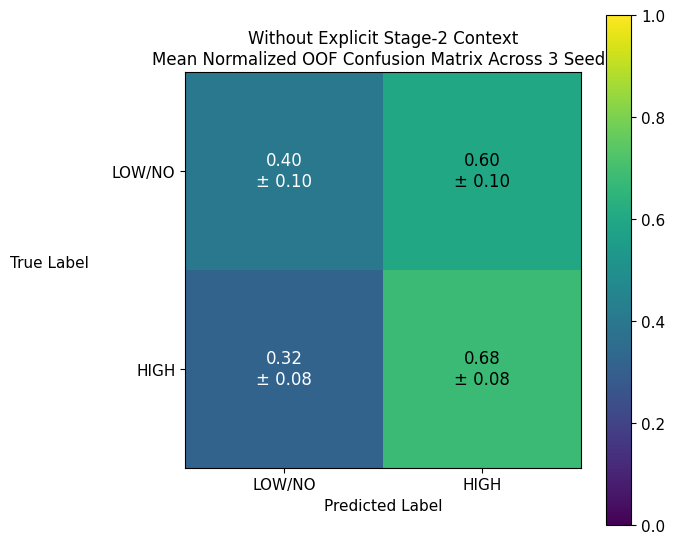


Saved to: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/02_Baseline_Without_Context/Figures/Mean_Normalized_OOF_Confusion_Matrix_Across_3_Seeds.png

------------------------------------------------------------------------------------------
With Explicit Stage-2 Context
------------------------------------------------------------------------------------------

Mean normalized confusion matrix:
[[0.433 0.567]
 [0.283 0.717]]

SD across seeds:
[[0.115 0.115]
 [0.076 0.076]]

Mean Specificity : 0.433
Mean Sensitivity : 0.717
Mean Balanced Accuracy : 0.575


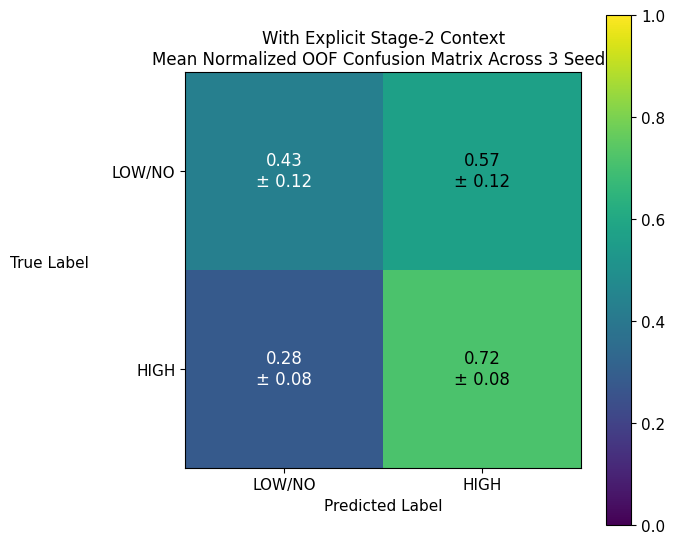


Saved to: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/03_Context_Aware_Model/Figures/Mean_Normalized_OOF_Confusion_Matrix_Across_3_Seeds.png

MEAN NORMALIZED CONFUSION MATRIX COMPLETED


In [ ]:
# ============================================================
# 12B.5: MEAN NORMALIZED OOF CONFUSION MATRIX ACROSS 3 SEEDS
# ============================================================
#
# IMPORTANT:
# 1. Confusion matrix is calculated separately for each seed.
# 2. Each confusion matrix is normalized by true class.
# 3. The three normalized confusion matrices are then averaged.
#
# This is DIFFERENT from:
# averaging probabilities across seeds first and then calculating
# one pooled confusion matrix.
# ============================================================

print("\n" + "=" * 90)
print("MEAN NORMALIZED OOF CONFUSION MATRIX ACROSS 3 SEEDS")
print("=" * 90)


for model_name, figure_dir in [

    (
        BASELINE_MODEL_NAME,
        BASELINE_FIGURE_DIR,
    ),

    (
        PROPOSED_MODEL_NAME,
        PROPOSED_FIGURE_DIR,
    ),

]:

    # --------------------------------------------------------
    # DISPLAY NAME
    # --------------------------------------------------------

    if model_name == BASELINE_MODEL_NAME:

        display_name = (
            "Without Explicit Stage-2 Context"
        )

    else:

        display_name = (
            "With Explicit Stage-2 Context"
        )


    # --------------------------------------------------------
    # COLLECT NORMALIZED CM FROM EACH SEED
    # --------------------------------------------------------

    normalized_cms = []

    for seed in RANDOM_SEEDS:

        seed_df = (
            ablation_predictions_df[
                (
                    ablation_predictions_df["model"]
                    == model_name
                )
                &
                (
                    ablation_predictions_df["seed"]
                    == seed
                )
            ]
            .set_index("subject")
            .loc[subjects]
        )

        probabilities = (
            seed_df["probability_high"]
            .to_numpy()
        )

        predictions = (
            probabilities >= THRESHOLD
        ).astype(int)

        # ----------------------------------------------------
        # NORMALIZED CONFUSION MATRIX FOR THIS SEED
        # ----------------------------------------------------

        cm_normalized = confusion_matrix(
            y,
            predictions,
            labels=[0, 1],
            normalize="true",
        )

        normalized_cms.append(
            cm_normalized
        )


    # --------------------------------------------------------
    # CONVERT TO ARRAY
    # Shape:
    # (number_of_seeds, 2, 2)
    # --------------------------------------------------------

    normalized_cms = np.array(
        normalized_cms
    )


    # --------------------------------------------------------
    # MEAN AND SD ACROSS SEEDS
    # --------------------------------------------------------

    mean_cm = np.mean(
        normalized_cms,
        axis=0,
    )

    std_cm = np.std(
        normalized_cms,
        axis=0,
        ddof=1,
    )


    # --------------------------------------------------------
    # PRINT NUMERICAL RESULTS
    # --------------------------------------------------------

    print("\n" + "-" * 90)
    print(display_name)
    print("-" * 90)

    print("\nMean normalized confusion matrix:")
    print(
        np.round(
            mean_cm,
            3,
        )
    )

    print("\nSD across seeds:")
    print(
        np.round(
            std_cm,
            3,
        )
    )


    # --------------------------------------------------------
    # CHECK BALANCED ACCURACY
    #
    # [0,0] = Specificity LOW/NO
    # [1,1] = Sensitivity HIGH
    # --------------------------------------------------------

    mean_specificity = mean_cm[0, 0]
    mean_sensitivity = mean_cm[1, 1]

    mean_balanced_accuracy = (
        mean_specificity
        +
        mean_sensitivity
    ) / 2


    print(
        f"\nMean Specificity : "
        f"{mean_specificity:.3f}"
    )

    print(
        f"Mean Sensitivity : "
        f"{mean_sensitivity:.3f}"
    )

    print(
        f"Mean Balanced Accuracy : "
        f"{mean_balanced_accuracy:.3f}"
    )


    # ========================================================
    # PLOT MEAN NORMALIZED CONFUSION MATRIX
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    im = ax.imshow(
        mean_cm,
        vmin=0,
        vmax=1,
    )


    # --------------------------------------------------------
    # COLORBAR
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
    )

    cbar.ax.tick_params(
        labelsize=11
    )


    # --------------------------------------------------------
    # AXES
    # --------------------------------------------------------

    ax.set_xticks(
        [0, 1]
    )

    ax.set_yticks(
        [0, 1]
    )

    ax.set_xticklabels(
        ["LOW/NO", "HIGH"],
        fontsize=11,
    )

    ax.set_yticklabels(
        ["LOW/NO", "HIGH"],
        fontsize=11,
    )

    ax.set_xlabel(
        "Predicted Label",
        fontsize=11,
    )

    ax.set_ylabel(
        "True Label",
        fontsize=11,
        rotation=0,
        labelpad=45,
    )


    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.set_title(
        f"{display_name}\n"
        f"Mean Normalized OOF Confusion Matrix Across 3 Seeds",
        fontsize=12,
    )


    # --------------------------------------------------------
    # CELL ANNOTATIONS: MEAN ± SD
    # --------------------------------------------------------

    for i in range(2):

        for j in range(2):

            value = mean_cm[i, j]
            sd_value = std_cm[i, j]

            # Choose readable text color
            text_color = (
                "black"
                if value >= 0.50
                else "white"
            )

            ax.text(
                j,
                i,
                f"{value:.2f}\n± {sd_value:.2f}",
                ha="center",
                va="center",
                fontsize=12,
                color=text_color,
            )


    plt.tight_layout()


    # --------------------------------------------------------
    # SAVE FIGURE
    # --------------------------------------------------------

    output_path = (
        figure_dir
        /
        "Mean_Normalized_OOF_Confusion_Matrix_"
        "Across_3_Seeds.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


    print(
        f"\nSaved to: {output_path}"
    )


print("\n" + "=" * 90)
print("MEAN NORMALIZED CONFUSION MATRIX COMPLETED")
print("=" * 90)

,test,seed,paired_quantity,statistic,p_value,significant_at_0.05,baseline_mean_error,context_aware_mean_error,context_minus_baseline_error,lower_error_model
0,Wilcoxon signed-rank test,42,Subject-level absolute probability error,188.0,0.3707,No,0.4427,0.4240,-0.0187,Context-Aware
1,Wilcoxon signed-rank test,123,Subject-level absolute probability error,209.0,0.6408,No,0.4265,0.4401,0.0136,Baseline
2,Wilcoxon signed-rank test,2026,Subject-level absolute probability error,165.0,0.1706,No,0.4589,0.4325,-0.0264,Context-Aware
3,McNemar exact test,Pooled,Subject-level prediction correctness,3.0,1.0000,No,NaN,NaN,NaN,Not applicable


MCNEMAR CONTINGENCY TABLE


,Context-Aware Incorrect,Context-Aware Correct
Baseline Incorrect,8,3
Baseline Correct,3,16


McNemar statistic: 3.0000
McNemar p-value  : 1.0000
Statistically significant: No


,seed,baseline_mean_error,baseline_std_error,context_aware_mean_error,context_aware_std_error,context_minus_baseline_error
0,42,0.4427,0.2096,0.4240,0.1866,-0.0187
1,123,0.4265,0.2532,0.4401,0.2331,0.0136
2,2026,0.4589,0.1839,0.4325,0.1616,-0.0264


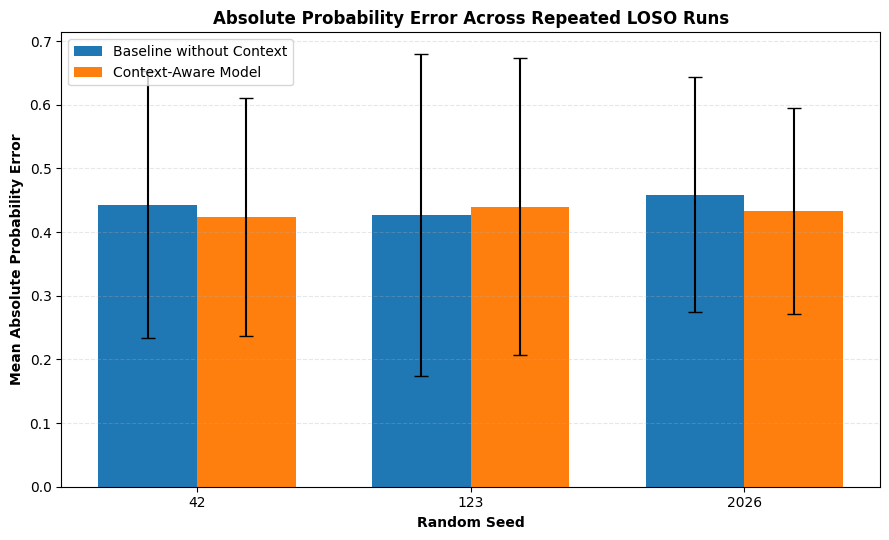

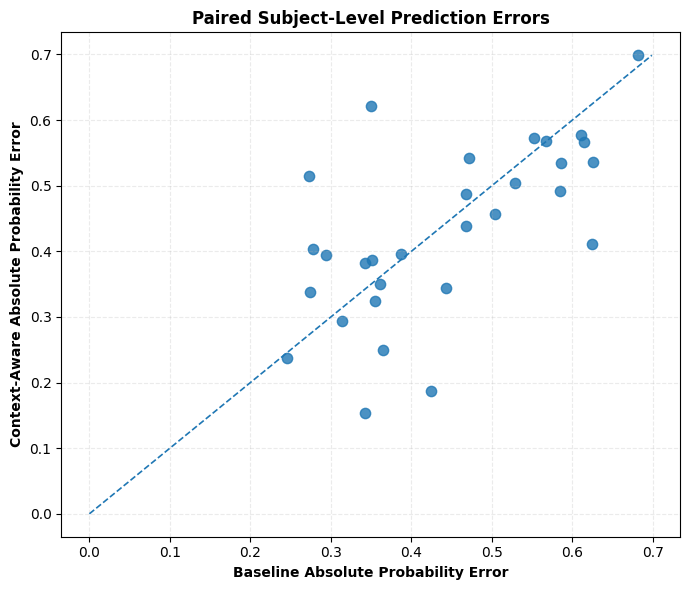

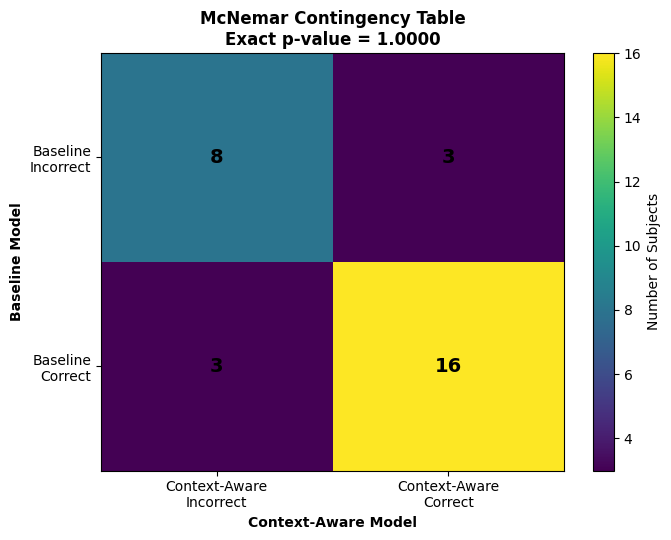

PAIRED STATISTICAL ANALYSIS COMPLETED
Statistical table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/04_Context_Ablation_Comparison/Tables/Context_Ablation_Paired_Statistical_Tests.csv
Error summary table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/04_Context_Ablation_Comparison/Tables/Mean_Absolute_Probability_Error_By_Seed.csv
McNemar table: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/04_Context_Ablation_Comparison/Tables/McNemar_Contingency_Table.csv
Figures directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/04_Context_Ablation_Comparison/Figures


In [ ]:
# ============================================================
# STEP 13: PAIRED STATISTICAL TESTS AND VISUALIZATION
#
# Statistical analyses:
# 1. Wilcoxon signed-rank test on paired subject-level
#    absolute probability errors for each random seed.
# 2. McNemar exact test on pooled subject-level correctness.
#
# Outputs:
# 1. Statistical-test summary table
# 2. McNemar contingency table
# 3. Mean absolute probability error comparison figure
# 4. McNemar contingency heatmap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SIGNIFICANCE_LEVEL = 0.05

BASELINE_DISPLAY_NAME = (
    "Dense-8 + Physiological + Phase Duration"
)

PROPOSED_DISPLAY_NAME = (
    "Dense-8 + Context + Physiological + Phase Duration"
)


# ------------------------------------------------------------
# 2. WILCOXON SIGNED-RANK TEST
# ------------------------------------------------------------

paired_rows = []
error_comparison_rows = []

for seed in RANDOM_SEEDS:

    baseline_seed = (
        baseline_predictions_df[
            baseline_predictions_df["seed"] == seed
        ]
        .set_index("subject")
        .loc[subjects]
    )

    proposed_seed = (
        proposed_predictions_df[
            proposed_predictions_df["seed"] == seed
        ]
        .set_index("subject")
        .loc[subjects]
    )

    baseline_probability = (
        baseline_seed[
            "probability_high"
        ].to_numpy(dtype=float)
    )

    proposed_probability = (
        proposed_seed[
            "probability_high"
        ].to_numpy(dtype=float)
    )

    baseline_error = np.abs(
        y - baseline_probability
    )

    proposed_error = np.abs(
        y - proposed_probability
    )

    error_difference = (
        baseline_error
        - proposed_error
    )

    if np.allclose(
        error_difference,
        0,
    ):
        statistic = 0.0
        p_value = 1.0

    else:
        statistic, p_value = wilcoxon(
            baseline_error,
            proposed_error,
            alternative="two-sided",
            zero_method="wilcox",
        )

    baseline_mean_error = float(
        baseline_error.mean()
    )

    proposed_mean_error = float(
        proposed_error.mean()
    )

    mean_error_difference = float(
        proposed_mean_error
        - baseline_mean_error
    )

    better_model = (
        "Baseline"
        if baseline_mean_error < proposed_mean_error
        else "Context-Aware"
        if proposed_mean_error < baseline_mean_error
        else "Equal"
    )

    paired_rows.append({
        "test": "Wilcoxon signed-rank test",
        "seed": seed,
        "paired_quantity": (
            "Subject-level absolute probability error"
        ),
        "statistic": float(statistic),
        "p_value": float(p_value),
        "significant_at_0.05": (
            "Yes"
            if p_value < SIGNIFICANCE_LEVEL
            else "No"
        ),
        "baseline_mean_error": (
            baseline_mean_error
        ),
        "context_aware_mean_error": (
            proposed_mean_error
        ),
        "context_minus_baseline_error": (
            mean_error_difference
        ),
        "lower_error_model": better_model,
    })

    for subject_index, subject in enumerate(
        subjects
    ):
        error_comparison_rows.append({
            "seed": seed,
            "subject": subject,
            "true_label": int(
                y[subject_index]
            ),
            "baseline_error": float(
                baseline_error[
                    subject_index
                ]
            ),
            "context_aware_error": float(
                proposed_error[
                    subject_index
                ]
            ),
            "error_difference": float(
                proposed_error[
                    subject_index
                ]
                - baseline_error[
                    subject_index
                ]
            ),
        })


# ------------------------------------------------------------
# 3. MCNEMAR EXACT TEST
# ------------------------------------------------------------

baseline_pooled = (
    pooled_predictions_df[
        pooled_predictions_df["model"]
        == BASELINE_MODEL_NAME
    ]
    .set_index("subject")
    .loc[subjects]
)

proposed_pooled = (
    pooled_predictions_df[
        pooled_predictions_df["model"]
        == PROPOSED_MODEL_NAME
    ]
    .set_index("subject")
    .loc[subjects]
)

baseline_correct = (
    baseline_pooled[
        "predicted_label"
    ].to_numpy(dtype=int)
    == y
)

proposed_correct = (
    proposed_pooled[
        "predicted_label"
    ].to_numpy(dtype=int)
    == y
)

contingency_table = np.array([
    [
        np.sum(
            ~baseline_correct
            & ~proposed_correct
        ),
        np.sum(
            ~baseline_correct
            & proposed_correct
        ),
    ],
    [
        np.sum(
            baseline_correct
            & ~proposed_correct
        ),
        np.sum(
            baseline_correct
            & proposed_correct
        ),
    ],
])

mcnemar_result = mcnemar(
    contingency_table,
    exact=True,
)

paired_rows.append({
    "test": "McNemar exact test",
    "seed": "Pooled",
    "paired_quantity": (
        "Subject-level prediction correctness"
    ),
    "statistic": float(
        mcnemar_result.statistic
    ),
    "p_value": float(
        mcnemar_result.pvalue
    ),
    "significant_at_0.05": (
        "Yes"
        if mcnemar_result.pvalue
        < SIGNIFICANCE_LEVEL
        else "No"
    ),
    "baseline_mean_error": np.nan,
    "context_aware_mean_error": np.nan,
    "context_minus_baseline_error": np.nan,
    "lower_error_model": "Not applicable",
})


# ------------------------------------------------------------
# 4. CREATE STATISTICAL-SUMMARY TABLE
# ------------------------------------------------------------

statistical_comparison_df = pd.DataFrame(
    paired_rows
)

statistical_comparison_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Context_Ablation_Paired_Statistical_Tests.csv",
    index=False,
)

error_comparison_df = pd.DataFrame(
    error_comparison_rows
)

error_comparison_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Subject_Level_Absolute_Probability_Errors.csv",
    index=False,
)

display(
    statistical_comparison_df.round(4)
)


# ------------------------------------------------------------
# 5. CREATE AND SAVE MCNEMAR CONTINGENCY TABLE
# ------------------------------------------------------------

mcnemar_contingency_df = pd.DataFrame(
    contingency_table,
    index=[
        "Baseline Incorrect",
        "Baseline Correct",
    ],
    columns=[
        "Context-Aware Incorrect",
        "Context-Aware Correct",
    ],
)

mcnemar_contingency_df.to_csv(
    COMPARISON_TABLE_DIR
    / "McNemar_Contingency_Table.csv"
)

print("=" * 72)
print("MCNEMAR CONTINGENCY TABLE")
print("=" * 72)

display(
    mcnemar_contingency_df
)

print(
    "McNemar statistic:",
    f"{float(mcnemar_result.statistic):.4f}",
)

print(
    "McNemar p-value  :",
    f"{float(mcnemar_result.pvalue):.4f}",
)

print(
    "Statistically significant:",
    (
        "Yes"
        if mcnemar_result.pvalue
        < SIGNIFICANCE_LEVEL
        else "No"
    ),
)


# ------------------------------------------------------------
# 6. MEAN ABSOLUTE PROBABILITY ERROR TABLE
# ------------------------------------------------------------

error_summary_df = (
    error_comparison_df
    .groupby(
        "seed",
        as_index=False,
    )
    .agg(
        baseline_mean_error=(
            "baseline_error",
            "mean",
        ),
        baseline_std_error=(
            "baseline_error",
            "std",
        ),
        context_aware_mean_error=(
            "context_aware_error",
            "mean",
        ),
        context_aware_std_error=(
            "context_aware_error",
            "std",
        ),
    )
)

error_summary_df[
    "context_minus_baseline_error"
] = (
    error_summary_df[
        "context_aware_mean_error"
    ]
    - error_summary_df[
        "baseline_mean_error"
    ]
)

error_summary_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.csv",
    index=False,
)

display(
    error_summary_df.round(4)
)


# ------------------------------------------------------------
# 7. FIGURE 1:
# MEAN ABSOLUTE PROBABILITY ERROR BY RANDOM SEED
# ------------------------------------------------------------

x_positions = np.arange(
    len(error_summary_df)
)

bar_width = 0.36

plt.figure(
    figsize=(9, 5.5)
)

plt.bar(
    x_positions - bar_width / 2,
    error_summary_df[
        "baseline_mean_error"
    ],
    width=bar_width,
    yerr=error_summary_df[
        "baseline_std_error"
    ],
    capsize=5,
    label="Baseline without Context",
)

plt.bar(
    x_positions + bar_width / 2,
    error_summary_df[
        "context_aware_mean_error"
    ],
    width=bar_width,
    yerr=error_summary_df[
        "context_aware_std_error"
    ],
    capsize=5,
    label="Context-Aware Model",
)

plt.xticks(
    x_positions,
    error_summary_df[
        "seed"
    ].astype(str),
)

plt.xlabel(
    "Random Seed",
    fontweight="bold",
)

plt.ylabel(
    "Mean Absolute Probability Error",
    fontweight="bold",
)

plt.title(
    "Absolute Probability Error Across Repeated LOSO Runs",
    fontweight="bold",
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.30,
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 8. FIGURE 2:
# SUBJECT-LEVEL PAIRED ERROR COMPARISON
# ------------------------------------------------------------

mean_subject_errors = (
    error_comparison_df
    .groupby(
        "subject",
        as_index=False,
    )
    .agg(
        baseline_error=(
            "baseline_error",
            "mean",
        ),
        context_aware_error=(
            "context_aware_error",
            "mean",
        ),
    )
)

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    mean_subject_errors[
        "baseline_error"
    ],
    mean_subject_errors[
        "context_aware_error"
    ],
    s=55,
    alpha=0.80,
)

maximum_error = max(
    mean_subject_errors[
        "baseline_error"
    ].max(),
    mean_subject_errors[
        "context_aware_error"
    ].max(),
)

plt.plot(
    [0, maximum_error],
    [0, maximum_error],
    linestyle="--",
    linewidth=1.2,
)

plt.xlabel(
    "Baseline Absolute Probability Error",
    fontweight="bold",
)

plt.ylabel(
    "Context-Aware Absolute Probability Error",
    fontweight="bold",
)

plt.title(
    "Paired Subject-Level Prediction Errors",
    fontweight="bold",
)

plt.grid(
    linestyle="--",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "Paired_Subject_Level_Probability_Errors.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 9. FIGURE 3:
# MCNEMAR CONTINGENCY HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

image = ax.imshow(
    contingency_table,
    aspect="auto",
)

ax.set_xticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Context-Aware\nIncorrect",
        "Context-Aware\nCorrect",
    ]
)

ax.set_yticks(
    [0, 1]
)

ax.set_yticklabels(
    [
        "Baseline\nIncorrect",
        "Baseline\nCorrect",
    ]
)

for row_index in range(
    contingency_table.shape[0]
):
    for column_index in range(
        contingency_table.shape[1]
    ):
        ax.text(
            column_index,
            row_index,
            str(
                contingency_table[
                    row_index,
                    column_index,
                ]
            ),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
        )

ax.set_xlabel(
    "Context-Aware Model",
    fontweight="bold",
)

ax.set_ylabel(
    "Baseline Model",
    fontweight="bold",
)

ax.set_title(
    (
        "McNemar Contingency Table\n"
        f"Exact p-value = "
        f"{mcnemar_result.pvalue:.4f}"
    ),
    fontweight="bold",
)

fig.colorbar(
    image,
    ax=ax,
    label="Number of Subjects",
)

plt.tight_layout()

plt.savefig(
    COMPARISON_FIGURE_DIR
    / "McNemar_Contingency_Heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 10. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("=" * 72)
print("PAIRED STATISTICAL ANALYSIS COMPLETED")
print("=" * 72)

print(
    "Statistical table:",
    COMPARISON_TABLE_DIR
    / "Context_Ablation_Paired_Statistical_Tests.csv",
)

print(
    "Error summary table:",
    COMPARISON_TABLE_DIR
    / "Mean_Absolute_Probability_Error_By_Seed.csv",
)

print(
    "McNemar table:",
    COMPARISON_TABLE_DIR
    / "McNemar_Contingency_Table.csv",
)

print(
    "Figures directory:",
    COMPARISON_FIGURE_DIR,
)

print("=" * 72)

In [ ]:
# ============================================================
# STEP 14: SELECT THE BEST FINAL MODEL CONFIGURATION
#
# Selection priority:
# 1. Mean ROC-AUC across repeated LOSO runs
# 2. Mean Macro F1
# 3. Mean Balanced Accuracy
#
# The selected model and its fold artifacts are passed
# automatically to the subsequent OOF SHAP analysis.
# ============================================================

baseline_fusion_dimension = (
    SELECTED_PROJECTION_DIM
    + len(PHYSIO_COLS)
    + len(DURATION_COLS)
)

proposed_fusion_dimension = (
    SELECTED_PROJECTION_DIM
    + len(CONTEXT_COLS)
    + len(PHYSIO_COLS)
    + len(DURATION_COLS)
)

model_ranking_df = (
    ablation_metrics_df
    .groupby(
        [
            "model",
            "include_context",
            "projection_dim",
        ],
        as_index=False,
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean",
        ),
        macro_precision_mean=(
            "macro_precision",
            "mean",
        ),
        macro_recall_mean=(
            "macro_recall",
            "mean",
        ),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        specificity_mean=(
            "specificity_low_no",
            "mean",
        ),
        sensitivity_mean=(
            "sensitivity_high",
            "mean",
        ),
    )
    .sort_values(
        by=[
            "roc_auc_mean",
            "macro_f1_mean",
            "balanced_accuracy_mean",
        ],
        ascending=[False, False, False],
    )
    .reset_index(drop=True)
)

model_ranking_df.insert(
    0,
    "rank",
    np.arange(1, len(model_ranking_df) + 1),
)

best_row = model_ranking_df.iloc[0]

BEST_MODEL_NAME = str(best_row["model"])
BEST_INCLUDE_CONTEXT = bool(best_row["include_context"])
BEST_PROJECTION_DIM = int(best_row["projection_dim"])

if BEST_INCLUDE_CONTEXT:
    BEST_CONFIGURATION_NAME = (
        "Dense-8 + Context + Physiological + Phase Duration"
    )
    BEST_FUSION_DIMENSION = proposed_fusion_dimension
    BEST_ARTIFACTS_DF = proposed_artifacts_df.copy()
    BEST_PREDICTIONS_DF = proposed_predictions_df.copy()
    BEST_TABLE_DIR = PROPOSED_TABLE_DIR
    BEST_FIGURE_DIR = PROPOSED_FIGURE_DIR
else:
    BEST_CONFIGURATION_NAME = (
        "Dense-8 + Physiological + Phase Duration"
    )
    BEST_FUSION_DIMENSION = baseline_fusion_dimension
    BEST_ARTIFACTS_DF = baseline_artifacts_df.copy()
    BEST_PREDICTIONS_DF = baseline_predictions_df.copy()
    BEST_TABLE_DIR = BASELINE_TABLE_DIR
    BEST_FIGURE_DIR = BASELINE_FIGURE_DIR

if len(BEST_ARTIFACTS_DF) != len(subjects):
    raise RuntimeError(
        "The selected model's primary-seed fold artifacts "
        "are incomplete."
    )

configuration_df = pd.DataFrame([
    {
        "configuration": (
            "Dense-8 + Physiological + Phase Duration"
        ),
        "model": BASELINE_MODEL_NAME,
        "include_context": False,
        "skeleton_projection": SELECTED_PROJECTION_DIM,
        "context_features": 0,
        "physiological_features": len(PHYSIO_COLS),
        "phase_duration_features": len(DURATION_COLS),
        "fusion_dimension": baseline_fusion_dimension,
    },
    {
        "configuration": (
            "Dense-8 + Context + Physiological "
            "+ Phase Duration"
        ),
        "model": PROPOSED_MODEL_NAME,
        "include_context": True,
        "skeleton_projection": SELECTED_PROJECTION_DIM,
        "context_features": len(CONTEXT_COLS),
        "physiological_features": len(PHYSIO_COLS),
        "phase_duration_features": len(DURATION_COLS),
        "fusion_dimension": proposed_fusion_dimension,
    },
])

configuration_df["selected_as_best_model"] = (
    configuration_df["model"] == BEST_MODEL_NAME
)

configuration_df = configuration_df.merge(
    model_ranking_df[
        [
            "rank",
            "model",
            "roc_auc_mean",
            "roc_auc_std",
            "pr_auc_mean",
            "accuracy_mean",
            "balanced_accuracy_mean",
            "macro_f1_mean",
            "macro_f1_std",
            "specificity_mean",
            "sensitivity_mean",
        ]
    ],
    on="model",
    how="left",
).sort_values("rank").reset_index(drop=True)

configuration_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Final_Experiment_Configurations.csv",
    index=False,
)

model_ranking_df.to_csv(
    COMPARISON_TABLE_DIR
    / "Final_Model_Ranking.csv",
    index=False,
)

selected_model_summary = {
    "selected_model": BEST_MODEL_NAME,
    "selected_configuration": BEST_CONFIGURATION_NAME,
    "include_context": BEST_INCLUDE_CONTEXT,
    "selected_projection_dimension": BEST_PROJECTION_DIM,
    "fusion_dimension": BEST_FUSION_DIMENSION,
    "selection_priority": [
        "Mean ROC-AUC",
        "Mean Macro F1",
        "Mean Balanced Accuracy",
    ],
    "mean_roc_auc": float(best_row["roc_auc_mean"]),
    "mean_macro_f1": float(best_row["macro_f1_mean"]),
    "mean_balanced_accuracy": float(
        best_row["balanced_accuracy_mean"]
    ),
    "validation": "Repeated LOSO",
    "random_seeds": RANDOM_SEEDS,
    "oof_shap_target_model": BEST_MODEL_NAME,
}

with open(
    COMPARISON_DIR / "Selected_Best_Model.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        selected_model_summary,
        file,
        indent=2,
    )

print("=" * 78)
print("FINAL MODEL SELECTION")
print("=" * 78)
print("Selected model             :", BEST_MODEL_NAME)
print("Selected configuration     :", BEST_CONFIGURATION_NAME)
print("Include context            :", BEST_INCLUDE_CONTEXT)
print("Selected projection        :", BEST_PROJECTION_DIM)
print("Fusion dimension           :", BEST_FUSION_DIMENSION)
print(
    "Mean ROC-AUC               :",
    f"{float(best_row['roc_auc_mean']):.4f}",
)
print(
    "Mean Macro F1              :",
    f"{float(best_row['macro_f1_mean']):.4f}",
)
print(
    "Mean Balanced Accuracy     :",
    f"{float(best_row['balanced_accuracy_mean']):.4f}",
)
print("OOF SHAP target model      :", BEST_MODEL_NAME)
print("=" * 78)

display(configuration_df)
display(model_ranking_df)


FINAL MODEL SELECTION
Selected model             : MLP_Dense32_Context_Duration_Physiological
Selected configuration     : Dense-8 + Context + Physiological + Phase Duration
Include context            : True
Selected projection        : 32
Fusion dimension           : 46
Mean ROC-AUC               : 0.6750
Mean Macro F1              : 0.5752
Mean Balanced Accuracy     : 0.5750
OOF SHAP target model      : MLP_Dense32_Context_Duration_Physiological


,configuration,model,include_context,skeleton_projection,context_features,physiological_features,phase_duration_features,fusion_dimension,selected_as_best_model,rank,roc_auc_mean,roc_auc_std,pr_auc_mean,accuracy_mean,balanced_accuracy_mean,macro_f1_mean,macro_f1_std,specificity_mean,sensitivity_mean
0,Dense-8 + Context + Physiological + Phase Dura...,MLP_Dense32_Context_Duration_Physiological,True,32,4,5,5,46,True,1,0.675,0.085440,0.839573,0.622222,0.575000,0.575157,0.091197,0.433333,0.716667
1,Dense-8 + Physiological + Phase Duration,MLP_Dense32_Duration_Physiological,False,32,0,5,5,42,False,2,0.585,0.044441,0.763953,0.588889,0.541667,0.538508,0.013387,0.400000,0.683333


,rank,model,include_context,projection_dim,roc_auc_mean,roc_auc_std,pr_auc_mean,accuracy_mean,balanced_accuracy_mean,macro_precision_mean,macro_recall_mean,macro_f1_mean,macro_f1_std,specificity_mean,sensitivity_mean
0,1,MLP_Dense32_Context_Duration_Physiological,True,32,0.675,0.085440,0.839573,0.622222,0.575000,0.576475,0.575000,0.575157,0.091197,0.433333,0.716667
1,2,MLP_Dense32_Duration_Physiological,False,32,0.585,0.044441,0.763953,0.588889,0.541667,0.541219,0.541667,0.538508,0.013387,0.400000,0.683333


# Cross-Validated OOF SHAP for the Automatically Selected Best Model

The following analysis explains the model selected in **STEP 14**.  
Each subject is explained using the primary-seed LOSO fold model that did not use that subject during training. Context features are included only when the selected configuration uses context.

In [ ]:
# ============================================================
# STEP 15: INSTALL SHAP AND PREPARE THE BEST FOLD ARTIFACTS
# ============================================================

!pip -q install shap

import shap

selected_artifacts_df = (
    BEST_ARTIFACTS_DF
    .sort_values("fold")
    .reset_index(drop=True)
)

if len(selected_artifacts_df) != len(subjects):
    raise RuntimeError(
        "The selected model's primary-seed fold artifacts "
        "are incomplete."
    )

PROJECTED_SKELETON_FEATURES = [
    f"projected_skeleton_{index + 1}"
    for index in range(BEST_PROJECTION_DIM)
]

if BEST_INCLUDE_CONTEXT:
    INTERNAL_FEATURE_NAMES = (
        PROJECTED_SKELETON_FEATURES
        + CONTEXT_COLS
        + PHYSIO_COLS
        + DURATION_COLS
    )
else:
    INTERNAL_FEATURE_NAMES = (
        PROJECTED_SKELETON_FEATURES
        + PHYSIO_COLS
        + DURATION_COLS
    )

INTERNAL_FEATURE_COUNT = len(
    INTERNAL_FEATURE_NAMES
)

feature_cursor = 0

FEATURE_GROUPS = {}

FEATURE_GROUPS["Projected Skeleton"] = (
    feature_cursor,
    feature_cursor + BEST_PROJECTION_DIM,
)
feature_cursor += BEST_PROJECTION_DIM

if BEST_INCLUDE_CONTEXT:
    FEATURE_GROUPS["Context"] = (
        feature_cursor,
        feature_cursor + len(CONTEXT_COLS),
    )
    feature_cursor += len(CONTEXT_COLS)

FEATURE_GROUPS["Physiological"] = (
    feature_cursor,
    feature_cursor + len(PHYSIO_COLS),
)
feature_cursor += len(PHYSIO_COLS)

FEATURE_GROUPS["Phase Duration"] = (
    feature_cursor,
    feature_cursor + len(DURATION_COLS),
)
feature_cursor += len(DURATION_COLS)

assert feature_cursor == INTERNAL_FEATURE_COUNT
assert len(INTERNAL_FEATURE_NAMES) == INTERNAL_FEATURE_COUNT

print("=" * 72)
print("OOF SHAP CONFIGURATION")
print("=" * 72)
print("SHAP target model        :", BEST_MODEL_NAME)
print("Selected configuration  :", BEST_CONFIGURATION_NAME)
print("Selected projection     :", BEST_PROJECTION_DIM)
print("Context included        :", BEST_INCLUDE_CONTEXT)
print("Internal SHAP features  :", INTERNAL_FEATURE_COUNT)
print("Feature groups          :", list(FEATURE_GROUPS.keys()))
print("=" * 72)


OOF SHAP CONFIGURATION
SHAP target model        : MLP_Dense32_Context_Duration_Physiological
Selected configuration  : Dense-8 + Context + Physiological + Phase Duration
Selected projection     : 32
Context included        : True
Internal SHAP features  : 46
Feature groups          : ['Projected Skeleton', 'Context', 'Physiological', 'Phase Duration']


In [ ]:
# ============================================================
# STEP 16: DYNAMIC OOF SHAP HELPER FUNCTIONS
# ============================================================

def restore_scaler(mean_values, scale_values):
    scaler = StandardScaler()

    scaler.mean_ = np.asarray(
        mean_values,
        dtype=np.float64,
    )
    scaler.scale_ = np.asarray(
        scale_values,
        dtype=np.float64,
    )
    scaler.var_ = scaler.scale_ ** 2
    scaler.n_features_in_ = len(scaler.mean_)
    scaler.n_samples_seen_ = 1

    return scaler


def create_projection_extractor(
    trained_model,
    projection_dim,
):
    return tf.keras.Model(
        inputs=trained_model.inputs,
        outputs=trained_model.get_layer(
            f"skeleton_projection_bn_{projection_dim}"
        ).output,
        name=f"projection_extractor_{projection_dim}",
    )


def create_internal_fusion_head(
    trained_model,
    internal_feature_count,
):
    internal_input = tf.keras.layers.Input(
        shape=(internal_feature_count,),
        name="selected_internal_input",
    )

    x = trained_model.get_layer(
        "mlp_dense_64"
    )(internal_input)
    x = trained_model.get_layer(
        "mlp_batch_normalization_64"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_64"
    )(x, training=False)

    x = trained_model.get_layer(
        "mlp_dense_32"
    )(x)
    x = trained_model.get_layer(
        "mlp_batch_normalization_32"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_32"
    )(x, training=False)

    x = trained_model.get_layer(
        "mlp_dense_16"
    )(x)
    x = trained_model.get_layer(
        "mlp_dropout_16"
    )(x, training=False)

    output = trained_model.get_layer(
        "fall_risk_probability"
    )(x)

    return tf.keras.Model(
        inputs=internal_input,
        outputs=output,
        name="selected_internal_fusion_head",
    )


def build_internal_representation(
    projection_extractor,
    skeleton_scaled,
    physio_scaled,
    duration_scaled,
    context_scaled=None,
):
    model_inputs = pack_model_inputs(
        skeleton_scaled,
        context_scaled,
        physio_scaled,
        duration_scaled,
        include_context=BEST_INCLUDE_CONTEXT,
    )

    projected = projection_extractor.predict(
        model_inputs,
        verbose=0,
    ).astype(np.float32)

    internal_parts = [projected]

    if BEST_INCLUDE_CONTEXT:
        if context_scaled is None:
            raise ValueError(
                "Context input is required for the selected model."
            )
        internal_parts.append(context_scaled)

    internal_parts.extend([
        physio_scaled,
        duration_scaled,
    ])

    internal = np.concatenate(
        internal_parts,
        axis=1,
    ).astype(np.float32)

    if internal.shape[1] != INTERNAL_FEATURE_COUNT:
        raise ValueError(
            "Unexpected internal feature count: "
            f"{internal.shape[1]}; "
            f"expected {INTERNAL_FEATURE_COUNT}."
        )

    return internal


In [ ]:
# ============================================================
# STEP 17: COMPUTE CROSS-VALIDATED OOF SHAP
#
# Every subject is explained using the selected fold model
# that did not train on that subject.
# ============================================================

oof_internal_shap_values = np.zeros(
    (len(subjects), INTERNAL_FEATURE_COUNT),
    dtype=np.float32,
)
oof_internal_inputs = np.zeros(
    (len(subjects), INTERNAL_FEATURE_COUNT),
    dtype=np.float32,
)
oof_internal_base_values = np.zeros(
    len(subjects),
    dtype=np.float32,
)
oof_internal_probabilities = np.zeros(
    len(subjects),
    dtype=np.float32,
)

for artifact in selected_artifacts_df.itertuples(index=False):
    fold = int(artifact.fold)

    outer_train_idx = np.asarray(
        artifact.outer_train_idx,
        dtype=int,
    )
    test_idx = np.asarray(
        artifact.test_idx,
        dtype=int,
    )

    skeleton_scaler = restore_scaler(
        artifact.skeleton_mean,
        artifact.skeleton_scale,
    )
    physio_scaler = restore_scaler(
        artifact.physio_mean,
        artifact.physio_scale,
    )
    duration_scaler = restore_scaler(
        artifact.duration_mean,
        artifact.duration_scale,
    )

    if BEST_INCLUDE_CONTEXT:
        context_scaler = restore_scaler(
            artifact.context_mean,
            artifact.context_scale,
        )
    else:
        context_scaler = None

    model = build_multimodal_mlp_model(
        projection_dim=BEST_PROJECTION_DIM,
        include_context=BEST_INCLUDE_CONTEXT,
    )
    model.load_weights(artifact.weight_path)

    Xs_background = skeleton_scaler.transform(
        X_skeleton[outer_train_idx]
    ).astype(np.float32)
    Xp_background = physio_scaler.transform(
        X_physio[outer_train_idx]
    ).astype(np.float32)
    Xd_background = duration_scaler.transform(
        X_duration[outer_train_idx]
    ).astype(np.float32)

    Xs_test = skeleton_scaler.transform(
        X_skeleton[test_idx]
    ).astype(np.float32)
    Xp_test = physio_scaler.transform(
        X_physio[test_idx]
    ).astype(np.float32)
    Xd_test = duration_scaler.transform(
        X_duration[test_idx]
    ).astype(np.float32)

    if BEST_INCLUDE_CONTEXT:
        Xc_background = context_scaler.transform(
            X_context[outer_train_idx]
        ).astype(np.float32)
        Xc_test = context_scaler.transform(
            X_context[test_idx]
        ).astype(np.float32)
    else:
        Xc_background = None
        Xc_test = None

    projection_extractor = create_projection_extractor(
        model,
        BEST_PROJECTION_DIM,
    )
    internal_head = create_internal_fusion_head(
        model,
        INTERNAL_FEATURE_COUNT,
    )

    X_internal_background = build_internal_representation(
        projection_extractor=projection_extractor,
        skeleton_scaled=Xs_background,
        context_scaled=Xc_background,
        physio_scaled=Xp_background,
        duration_scaled=Xd_background,
    )
    X_internal_test = build_internal_representation(
        projection_extractor=projection_extractor,
        skeleton_scaled=Xs_test,
        context_scaled=Xc_test,
        physio_scaled=Xp_test,
        duration_scaled=Xd_test,
    )

    if len(X_internal_background) > SHAP_BACKGROUND_SIZE:
        background_rng = np.random.default_rng(
            PRIMARY_SEED + fold
        )
        selected_background_idx = background_rng.choice(
            len(X_internal_background),
            size=SHAP_BACKGROUND_SIZE,
            replace=False,
        )
        X_internal_background = X_internal_background[
            selected_background_idx
        ]

    def predict_internal(values):
        values = np.asarray(
            values,
            dtype=np.float32,
        )
        return internal_head.predict(
            values,
            verbose=0,
        ).ravel()

    explainer = shap.KernelExplainer(
        predict_internal,
        X_internal_background,
    )

    fold_shap_values = explainer.shap_values(
        X_internal_test,
        nsamples=SHAP_NSAMPLES,
        silent=True,
    )

    if isinstance(fold_shap_values, list):
        fold_shap_values = fold_shap_values[-1]

    fold_shap_values = np.asarray(
        fold_shap_values,
        dtype=np.float32,
    ).reshape(
        1,
        INTERNAL_FEATURE_COUNT,
    )

    test_position = int(test_idx[0])

    oof_internal_shap_values[
        test_position
    ] = fold_shap_values[0]
    oof_internal_inputs[
        test_position
    ] = X_internal_test[0]
    oof_internal_base_values[
        test_position
    ] = float(
        np.asarray(
            explainer.expected_value
        ).reshape(-1)[-1]
    )
    oof_internal_probabilities[
        test_position
    ] = float(
        predict_internal(X_internal_test)[0]
    )

    print(
        f"SHAP fold {fold:02d}/{len(subjects)} completed "
        f"| {subjects[test_position]}"
    )

    del model
    del projection_extractor
    del internal_head
    del explainer

    tf.keras.backend.clear_session()
    gc.collect()

if np.isnan(oof_internal_shap_values).any():
    raise RuntimeError(
        "OOF SHAP values contain missing values."
    )

selected_primary_probabilities = (
    BEST_PREDICTIONS_DF[
        BEST_PREDICTIONS_DF["seed"] == PRIMARY_SEED
    ]
    .set_index("subject")
    .loc[subjects]["probability_high"]
    .to_numpy(dtype=np.float32)
)

max_probability_difference = float(
    np.max(
        np.abs(
            oof_internal_probabilities
            - selected_primary_probabilities
        )
    )
)

print("=" * 72)
print("CROSS-VALIDATED OOF SHAP COMPLETED")
print("=" * 72)
print("Selected model             :", BEST_MODEL_NAME)
print("Context included           :", BEST_INCLUDE_CONTEXT)
print("SHAP matrix shape          :", oof_internal_shap_values.shape)
print(
    "Max restored probability difference:",
    max_probability_difference,
)
print("=" * 72)


SHAP fold 01/30 completed | subject01
SHAP fold 02/30 completed | subject02
SHAP fold 03/30 completed | subject03
SHAP fold 04/30 completed | subject04
SHAP fold 05/30 completed | subject05
SHAP fold 06/30 completed | subject06
SHAP fold 07/30 completed | subject07
SHAP fold 08/30 completed | subject08
SHAP fold 09/30 completed | subject09
SHAP fold 10/30 completed | subject10
SHAP fold 11/30 completed | subject11
SHAP fold 12/30 completed | subject12
SHAP fold 13/30 completed | subject13
SHAP fold 14/30 completed | subject14
SHAP fold 15/30 completed | subject15
SHAP fold 16/30 completed | subject16
SHAP fold 17/30 completed | subject17
SHAP fold 18/30 completed | subject18
SHAP fold 19/30 completed | subject19
SHAP fold 20/30 completed | subject20
SHAP fold 21/30 completed | subject21
SHAP fold 22/30 completed | subject22
SHAP fold 23/30 completed | subject23
SHAP fold 24/30 completed | subject24
SHAP fold 25/30 completed | subject25
SHAP fold 26/30 completed | subject26
SHAP fold 27

STEP 17.B — FOLD-WISE SHAP STABILITY


,global_rank,feature,feature_group,mean_abs_shap,mean_rank,rank_sd,top5_frequency_percent
0,1,duration_STTS,Phase Duration,0.02644,17.88,12.48,33.3
1,2,duration_WO,Phase Duration,0.01651,22.03,11.01,16.7
2,3,duration_WI,Phase Duration,0.01230,20.67,11.42,20.0
3,4,projected_skeleton_1,Projected Skeleton,0.01186,22.40,10.42,13.3
4,5,projected_skeleton_6,Projected Skeleton,0.01124,25.92,7.92,6.7
5,6,projected_skeleton_5,Projected Skeleton,0.01004,22.23,10.71,13.3
6,7,projected_skeleton_25,Projected Skeleton,0.00944,20.77,11.19,16.7
7,8,duration_TR,Phase Duration,0.00931,23.22,9.79,13.3
8,9,projected_skeleton_2,Projected Skeleton,0.00928,22.92,10.36,16.7
9,10,humidity,Context,0.00816,20.67,11.42,13.3


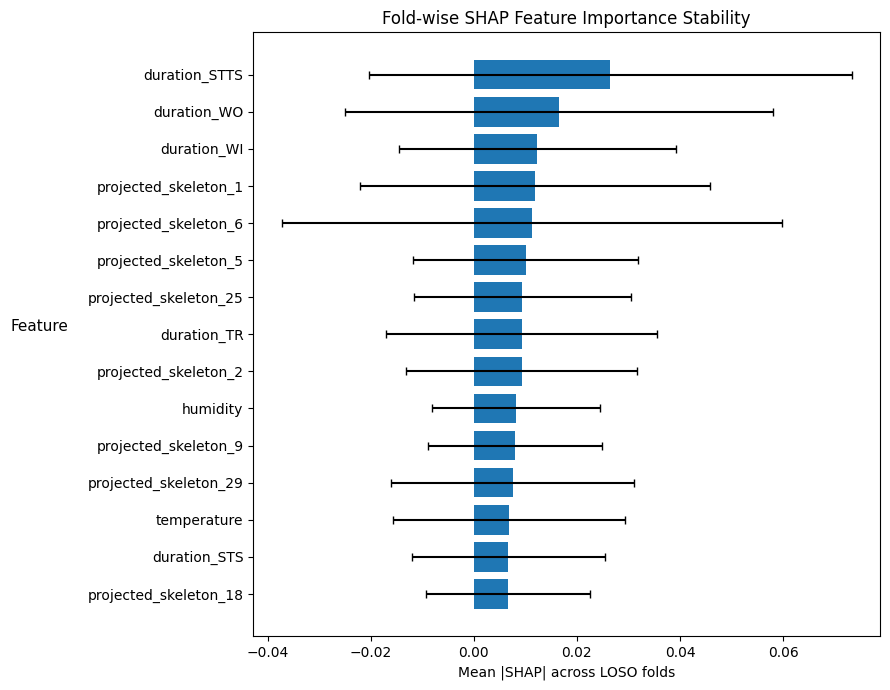

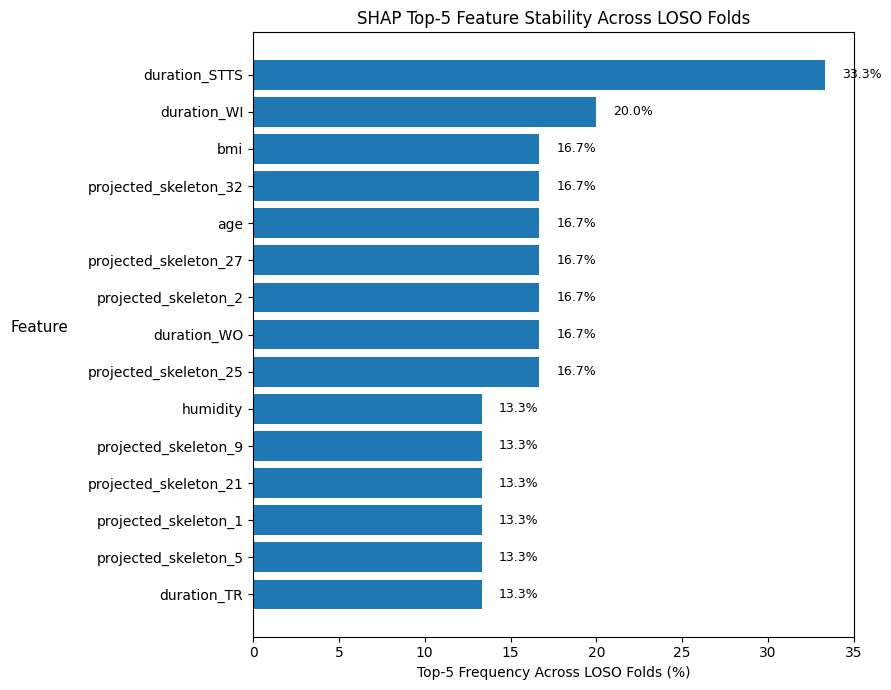

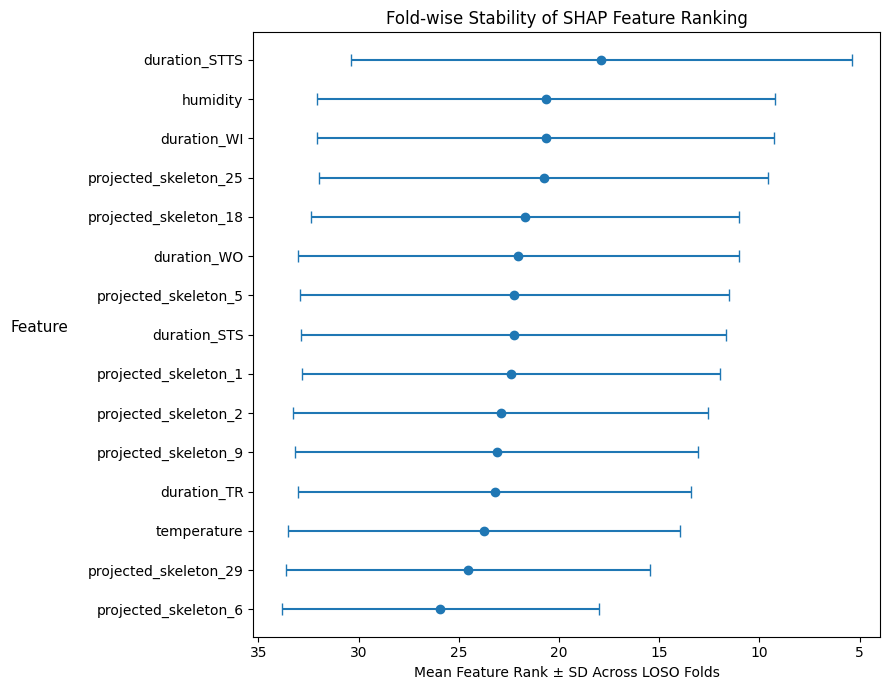


TOP FEATURES BY MEAN |SHAP|
----------------------------------------------------------------------------------------------------
01. duration_STTS                | Mean |SHAP| = 0.02644 | Mean Rank = 17.88 | Rank SD = 12.48 | Top-5 = 33.3%
02. duration_WO                  | Mean |SHAP| = 0.01651 | Mean Rank = 22.03 | Rank SD = 11.01 | Top-5 = 16.7%
03. duration_WI                  | Mean |SHAP| = 0.01230 | Mean Rank = 20.67 | Rank SD = 11.42 | Top-5 = 20.0%
04. projected_skeleton_1         | Mean |SHAP| = 0.01186 | Mean Rank = 22.40 | Rank SD = 10.42 | Top-5 = 13.3%
05. projected_skeleton_6         | Mean |SHAP| = 0.01124 | Mean Rank = 25.92 | Rank SD = 7.92 | Top-5 = 6.7%
06. projected_skeleton_5         | Mean |SHAP| = 0.01004 | Mean Rank = 22.23 | Rank SD = 10.71 | Top-5 = 13.3%
07. projected_skeleton_25        | Mean |SHAP| = 0.00944 | Mean Rank = 20.77 | Rank SD = 11.19 | Top-5 = 16.7%
08. duration_TR                  | Mean |SHAP| = 0.00931 | Mean Rank = 23.22 | Rank SD = 9.79 |

In [ ]:
# ============================================================
# STEP 17.B: FOLD-WISE SHAP FEATURE-IMPORTANCE STABILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
TOP_K = 5
TOP_N_DISPLAY = 15
FIGURE_DPI = 600

# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------
required_vars = [
    "oof_internal_shap_values",
    "INTERNAL_FEATURE_NAMES",
    "subjects",
    "SHAP_DIR"
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise NameError(
        "Variabel berikut belum tersedia:\n- "
        + "\n- ".join(missing)
        + "\n\nJalankan STEP 17 terlebih dahulu."
    )

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
SHAP_DIR = Path(SHAP_DIR)
STABILITY_DIR = SHAP_DIR / "Fold_Wise_Stability"
STABILITY_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------
shap_matrix = np.asarray(oof_internal_shap_values, dtype=float)
feature_names = list(INTERNAL_FEATURE_NAMES)
subjects_array = np.asarray(subjects).astype(str)

# Handle possible shape: (n_subject, n_feature, 1)
if shap_matrix.ndim == 3:
    if shap_matrix.shape[-1] == 1:
        shap_matrix = shap_matrix[:, :, 0]
    else:
        raise ValueError(
            f"SHAP shape tidak dikenali: {shap_matrix.shape}"
        )

if shap_matrix.ndim != 2:
    raise ValueError(
        f"SHAP matrix harus 2D. Shape saat ini: {shap_matrix.shape}"
    )

if shap_matrix.shape[0] != len(subjects_array):
    raise ValueError(
        f"Jumlah row SHAP ({shap_matrix.shape[0]}) "
        f"tidak sama dengan jumlah subject ({len(subjects_array)})."
    )

if shap_matrix.shape[1] != len(feature_names):
    raise ValueError(
        f"Jumlah kolom SHAP ({shap_matrix.shape[1]}) "
        f"tidak sama dengan jumlah feature ({len(feature_names)})."
    )

# ------------------------------------------------------------
# ABSOLUTE SHAP
# ------------------------------------------------------------
abs_shap_matrix = np.abs(shap_matrix)

abs_shap_df = pd.DataFrame(
    abs_shap_matrix,
    index=subjects_array,
    columns=feature_names
)

abs_shap_df.index.name = "subject"

# ------------------------------------------------------------
# RANK PER LOSO FOLD
# Rank 1 = feature dengan |SHAP| terbesar
# ------------------------------------------------------------
rank_df = abs_shap_df.rank(
    axis=1,
    ascending=False,
    method="average"
)

# ------------------------------------------------------------
# TOP-K MEMBERSHIP
# ------------------------------------------------------------
topk_df = (rank_df <= TOP_K).astype(int)

# ------------------------------------------------------------
# STABILITY METRICS
# ------------------------------------------------------------
mean_abs_shap = abs_shap_df.mean(axis=0)
sd_abs_shap = abs_shap_df.std(axis=0, ddof=1)

mean_rank = rank_df.mean(axis=0)
median_rank = rank_df.median(axis=0)
rank_sd = rank_df.std(axis=0, ddof=1)

topk_count = topk_df.sum(axis=0)
topk_frequency = topk_count / len(subjects_array) * 100

# ------------------------------------------------------------
# SUMMARY TABLE
# ------------------------------------------------------------
stability_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": [
        mean_abs_shap[f] for f in feature_names
    ],
    "sd_abs_shap": [
        sd_abs_shap[f] for f in feature_names
    ],
    "mean_rank": [
        mean_rank[f] for f in feature_names
    ],
    "median_rank": [
        median_rank[f] for f in feature_names
    ],
    "rank_sd": [
        rank_sd[f] for f in feature_names
    ],
    "top5_count": [
        topk_count[f] for f in feature_names
    ],
    "top5_frequency_percent": [
        topk_frequency[f] for f in feature_names
    ]
})

# ------------------------------------------------------------
# ADD FEATURE GROUP IF AVAILABLE
# ------------------------------------------------------------
if "FEATURE_GROUPS" in globals():

    def get_feature_group(feature_index):
        for group_name, bounds in FEATURE_GROUPS.items():
            start_idx, end_idx = bounds
            if start_idx <= feature_index < end_idx:
                return group_name
        return "Unknown"

    stability_df["feature_group"] = [
        get_feature_group(i)
        for i in range(len(feature_names))
    ]

# ------------------------------------------------------------
# SORT BY MEAN |SHAP|
# ------------------------------------------------------------
stability_df = (
    stability_df
    .sort_values(
        ["mean_abs_shap", "top5_frequency_percent"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

stability_df.insert(
    0,
    "global_rank",
    np.arange(1, len(stability_df) + 1)
)

# ------------------------------------------------------------
# LONG FORMAT PER FOLD
# ------------------------------------------------------------
fold_rows = []

for fold_idx, subject in enumerate(subjects_array):

    for feat_idx, feature in enumerate(feature_names):

        fold_rows.append({
            "fold": fold_idx + 1,
            "subject": subject,
            "feature": feature,
            "abs_shap": float(
                abs_shap_matrix[fold_idx, feat_idx]
            ),
            "rank": float(
                rank_df.loc[subject, feature]
            ),
            "top5": int(
                topk_df.loc[subject, feature]
            )
        })

foldwise_shap_stability_df = pd.DataFrame(fold_rows)

# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------
stability_df.to_csv(
    STABILITY_DIR / "Fold_Wise_SHAP_Stability_Summary.csv",
    index=False
)

rank_df.to_csv(
    STABILITY_DIR / "Fold_Wise_SHAP_Rank_Matrix.csv"
)

abs_shap_df.to_csv(
    STABILITY_DIR / "Fold_Wise_Absolute_SHAP_Matrix.csv"
)

foldwise_shap_stability_df.to_csv(
    STABILITY_DIR / "Fold_Wise_SHAP_Long_Format.csv",
    index=False
)

# ------------------------------------------------------------
# DISPLAY TABLE
# ------------------------------------------------------------
display_cols = [
    "global_rank",
    "feature"
]

if "feature_group" in stability_df.columns:
    display_cols.append("feature_group")

display_cols += [
    "mean_abs_shap",
    "mean_rank",
    "rank_sd",
    "top5_frequency_percent"
]

print("=" * 100)
print("STEP 17.B — FOLD-WISE SHAP STABILITY")
print("=" * 100)

display(
    stability_df[display_cols].round({
        "mean_abs_shap": 5,
        "mean_rank": 2,
        "rank_sd": 2,
        "top5_frequency_percent": 1
    })
)

# ------------------------------------------------------------
# FIGURE 1 — MEAN |SHAP| ± SD
# ------------------------------------------------------------
plot_df = (
    stability_df
    .head(TOP_N_DISPLAY)
    .sort_values("mean_abs_shap")
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"],
    xerr=plot_df["sd_abs_shap"],
    capsize=3
)

plt.xlabel("Mean |SHAP| across LOSO folds")
#plt.ylabel("Feature")
plt.ylabel(
    "Feature",
    rotation=0,
    fontsize=11,
    labelpad=35
)
plt.title("Fold-wise SHAP Feature Importance Stability")

plt.tight_layout()

plt.savefig(
    STABILITY_DIR / "Fold_Wise_SHAP_Mean_Importance.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# FIGURE 2 — TOP-5 FREQUENCY
# ------------------------------------------------------------
freq_df = (
    stability_df
    .sort_values(
        "top5_frequency_percent",
        ascending=False
    )
    .head(TOP_N_DISPLAY)
    .sort_values("top5_frequency_percent")
)

plt.figure(figsize=(9, 7))

bars = plt.barh(
    freq_df["feature"],
    freq_df["top5_frequency_percent"]
)

plt.xlabel("Top-5 Frequency Across LOSO Folds (%)")
#plt.ylabel("Feature")
plt.ylabel(
    "Feature",
    rotation=0,
    fontsize=11,
    labelpad=35
)
plt.title("SHAP Top-5 Feature Stability Across LOSO Folds")

for bar, value in zip(
    bars,
    freq_df["top5_frequency_percent"]
):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    STABILITY_DIR / "Fold_Wise_SHAP_Top5_Frequency.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# FIGURE 3 — MEAN RANK ± RANK SD
# ------------------------------------------------------------
rank_plot_df = (
    stability_df
    .head(TOP_N_DISPLAY)
    .sort_values("mean_rank", ascending=False)
)

plt.figure(figsize=(9, 7))

plt.errorbar(
    rank_plot_df["mean_rank"],
    rank_plot_df["feature"],
    xerr=rank_plot_df["rank_sd"],
    fmt="o",
    capsize=4
)

plt.xlabel("Mean Feature Rank ± SD Across LOSO Folds")
#plt.ylabel("Feature")
plt.ylabel(
    "Feature",
    rotation=0,
    fontsize=11,
    labelpad=35
)
plt.title("Fold-wise Stability of SHAP Feature Ranking")

plt.gca().invert_xaxis()

plt.tight_layout()

plt.savefig(
    STABILITY_DIR / "Fold_Wise_SHAP_Rank_Stability.png",
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# PRINT TOP FEATURES
# ------------------------------------------------------------
print("\nTOP FEATURES BY MEAN |SHAP|")
print("-" * 100)

for _, row in stability_df.head(10).iterrows():

    print(
        f"{int(row['global_rank']):02d}. "
        f"{row['feature']:<28} | "
        f"Mean |SHAP| = {row['mean_abs_shap']:.5f} | "
        f"Mean Rank = {row['mean_rank']:.2f} | "
        f"Rank SD = {row['rank_sd']:.2f} | "
        f"Top-{TOP_K} = {row['top5_frequency_percent']:.1f}%"
    )

print("\n" + "=" * 100)
print("STEP 17.B COMPLETED")
print("=" * 100)

print("Number of LOSO folds :", len(subjects_array))
print("Number of features   :", len(feature_names))
print("Results saved to     :", STABILITY_DIR)

In [ ]:
# ============================================================
# STEP 18: GLOBAL AND FEATURE-GROUP SHAP ANALYSIS
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        oof_internal_shap_values
    ),
    axis=0,
)

global_shap_df = pd.DataFrame({
    "feature": INTERNAL_FEATURE_NAMES,
    "mean_abs_shap": mean_abs_shap,
})

def feature_group_name(
    feature_index,
):
    for group_name, (
        start,
        end,
    ) in FEATURE_GROUPS.items():
        if (
            start
            <= feature_index
            < end
        ):
            return group_name

    raise ValueError(
        feature_index
    )

global_shap_df[
    "feature_group"
] = [
    feature_group_name(index)
    for index in range(
        INTERNAL_FEATURE_COUNT
    )
]

global_shap_df = (
    global_shap_df
    .sort_values(
        "mean_abs_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

global_shap_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(global_shap_df) + 1,
    ),
)

global_shap_df.to_csv(
    SHAP_DIR
    / "Global_OOF_SHAP_Importance.csv",
    index=False,
)

group_rows = []

total_abs_shap = np.abs(
    oof_internal_shap_values
).sum()

for group_name, (
    start,
    end,
) in FEATURE_GROUPS.items():
    group_values = np.abs(
        oof_internal_shap_values[
            :,
            start:end,
        ]
    )

    group_rows.append({
        "feature_group": group_name,
        "feature_count": end - start,
        "total_abs_shap": float(
            group_values.sum()
        ),
        "mean_abs_shap_per_feature": float(
            group_values.mean()
        ),
        "contribution_percent": float(
            group_values.sum()
            / total_abs_shap
            * 100
        ),
    })

group_shap_df = (
    pd.DataFrame(group_rows)
    .sort_values(
        "contribution_percent",
        ascending=False,
    )
    .reset_index(drop=True)
)

group_shap_df.to_csv(
    SHAP_DIR
    / "OOF_SHAP_Feature_Group_Contribution.csv",
    index=False,
)

display(global_shap_df)
display(group_shap_df)

,rank,feature,mean_abs_shap,feature_group
0,1,duration_STTS,0.026443,Phase Duration
1,2,duration_WO,0.016505,Phase Duration
2,3,duration_WI,0.012303,Phase Duration
3,4,projected_skeleton_1,0.011861,Projected Skeleton
4,5,projected_skeleton_6,0.011235,Projected Skeleton
5,6,projected_skeleton_5,0.010043,Projected Skeleton
6,7,projected_skeleton_25,0.009439,Projected Skeleton
7,8,duration_TR,0.009309,Phase Duration
8,9,projected_skeleton_2,0.009276,Projected Skeleton
9,10,humidity,0.008165,Context


,feature_group,feature_count,total_abs_shap,mean_abs_shap_per_feature,contribution_percent
0,Projected Skeleton,32,4.753478,0.004952,57.344975
1,Phase Duration,5,2.137351,0.014249,25.784557
2,Physiological,5,0.772659,0.005151,9.321201
3,Context,4,0.625779,0.005215,7.549273


OOF SHAP DATA
Number of subjects : 30
Number of features : 46
Output directory   : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global


,rank,feature,mean_absolute_shap
0,1,duration_STTS,0.026443
1,2,duration_WO,0.016505
2,3,duration_WI,0.012303
3,4,projected_skeleton_1,0.011861
4,5,projected_skeleton_6,0.011235
5,6,projected_skeleton_5,0.010043
6,7,projected_skeleton_25,0.009439
7,8,duration_TR,0.009309
8,9,projected_skeleton_2,0.009276
9,10,humidity,0.008165


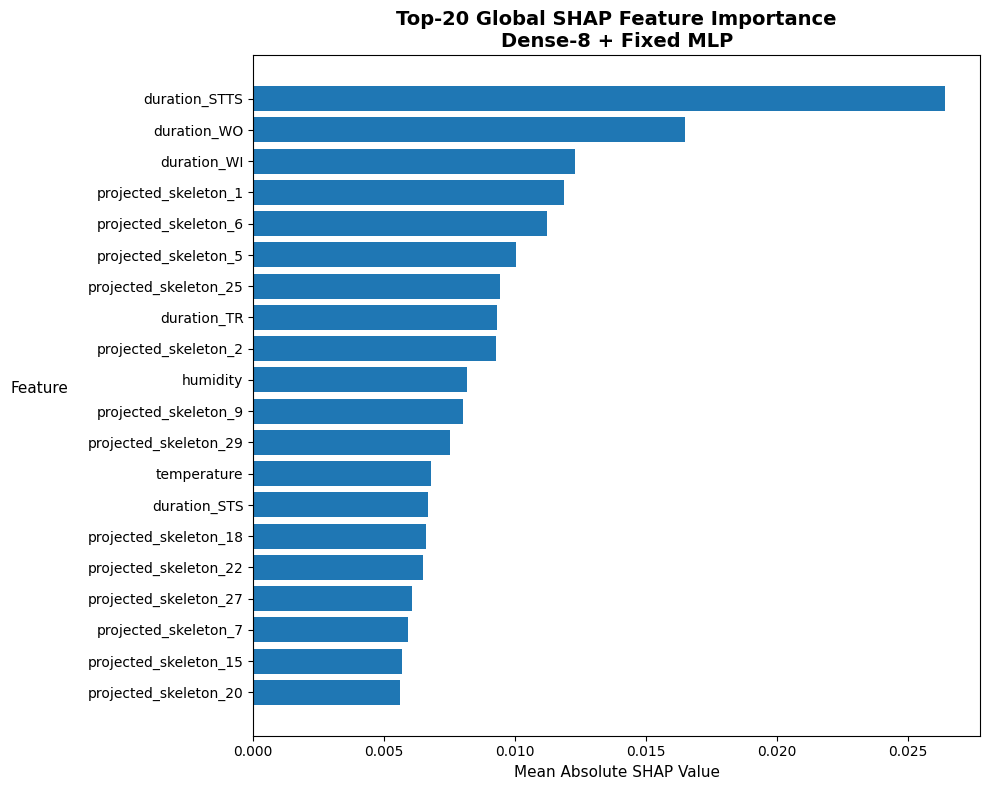

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Top_20_Global_SHAP_Feature_Importance.png


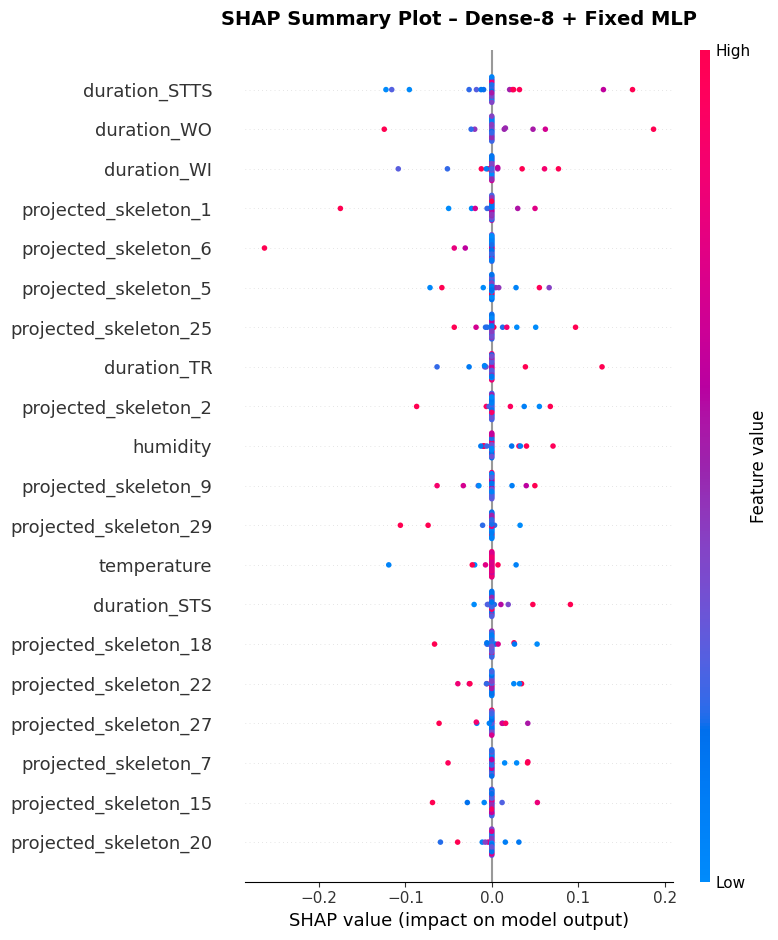

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/SHAP_Summary_Beeswarm_Dense_8.png


,feature_group,number_of_features,total_absolute_shap,mean_absolute_shap_per_feature,contribution_percent
0,Skeleton Embedding,32,0.158449,0.004952,57.344968
1,Phase Duration,5,0.071245,0.014249,25.784558
2,Context,4,0.020859,0.005215,7.549273
3,Physiological,5,0.025755,0.005151,9.321201


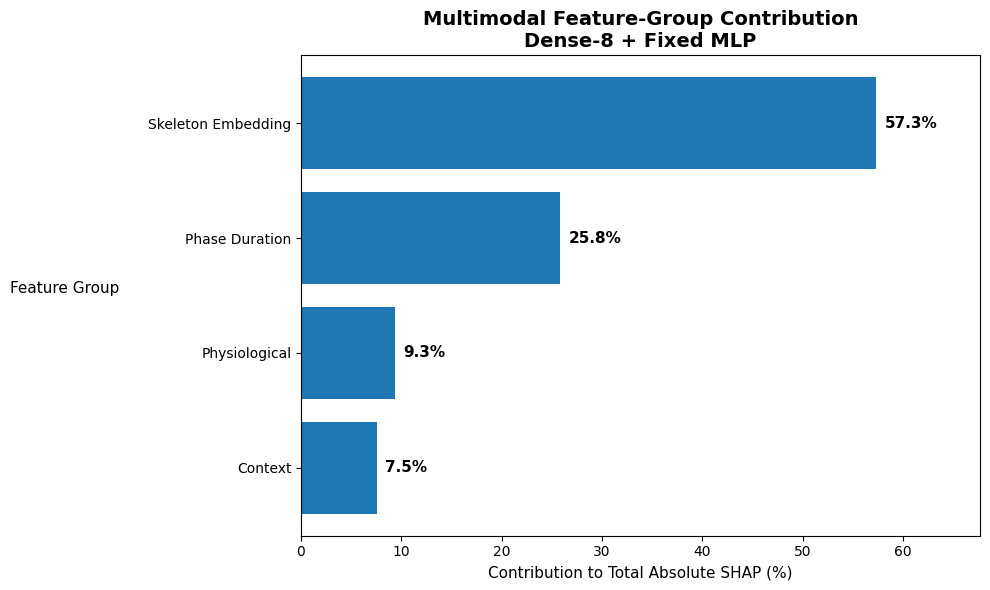

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Multimodal_Feature_Group_Contribution.png


<Figure size 700x500 with 0 Axes>

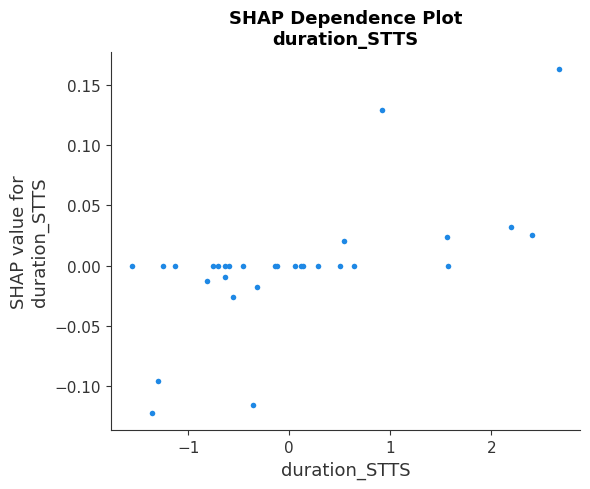

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_STTS_Dependence.png


<Figure size 700x500 with 0 Axes>

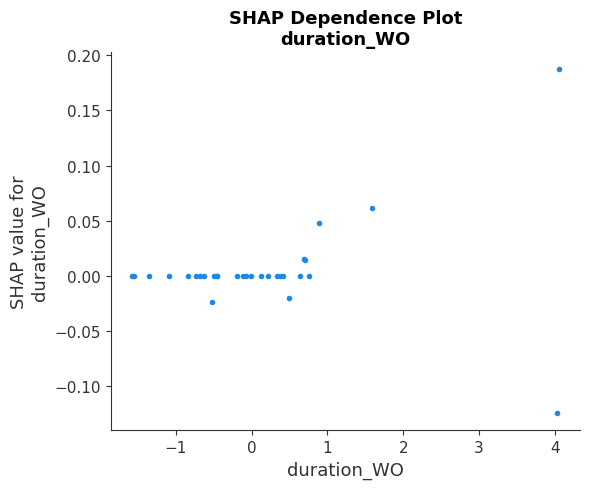

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_WO_Dependence.png


<Figure size 700x500 with 0 Axes>

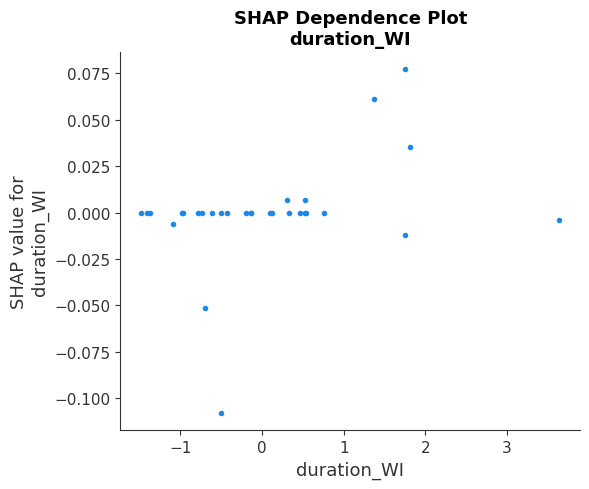

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/duration_WI_Dependence.png


<Figure size 700x500 with 0 Axes>

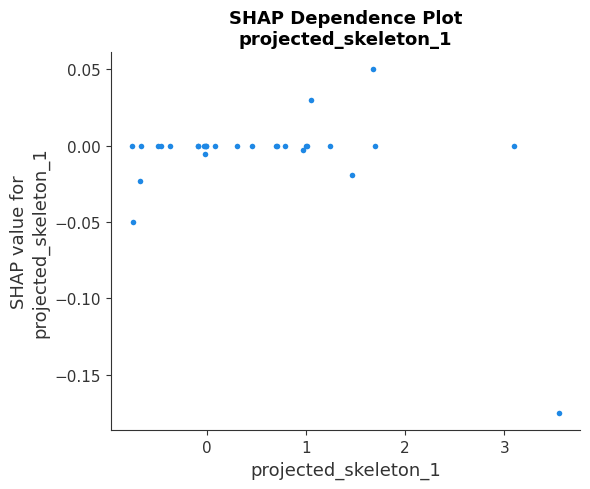

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/projected_skeleton_1_Dependence.png


<Figure size 700x500 with 0 Axes>

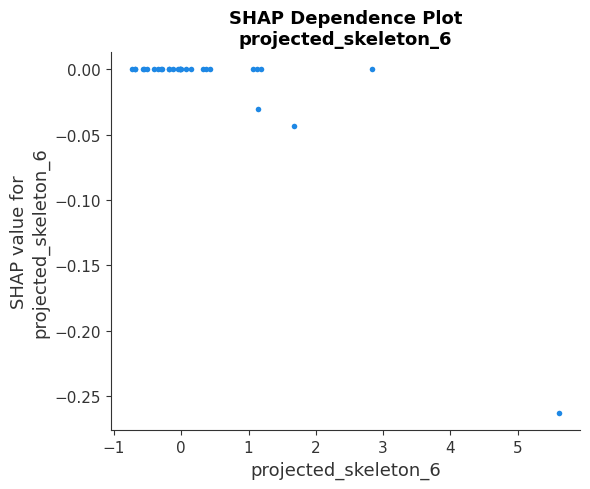

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Dependence/projected_skeleton_6_Dependence.png
STEP 20 COMPLETED
Global feature importance: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Top_20_Global_SHAP_Feature_Importance.png
SHAP summary / beeswarm  : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/SHAP_Summary_Beeswarm_Dense_8.png
Feature-group contribution: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Global/Multimodal_Feature_Group_Contribution.png
Dependence plot directory : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_

In [ ]:
# ============================================================
# STEP 19: GLOBAL SHAP ANALYSIS
#
# Outputs:
# 1. Top-20 Global SHAP Feature Importance
# 2. SHAP Summary / Beeswarm Plot
# 3. Multimodal Feature-Group Contribution
# 4. Feature-Group Contribution Table
# 5. SHAP Dependence Plots for Top Features
#
# Source:
# Out-of-Fold (OOF) SHAP values from LOSO evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from pathlib import Path


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TOP_N_FEATURES = 20
TOP_N_DEPENDENCE = 5
FIGURE_DPI = 300


# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "SHAP_DIR",
    "oof_internal_shap_values",
    "oof_internal_inputs",
    "INTERNAL_FEATURE_NAMES",
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "Variabel berikut belum tersedia:\n- "
        + "\n- ".join(missing_variables)
        + "\n\nJalankan cell perhitungan OOF SHAP terlebih dahulu."
    )


# ------------------------------------------------------------
# 3. OUTPUT DIRECTORIES
# ------------------------------------------------------------

SHAP_DIR = Path(SHAP_DIR)

GLOBAL_SHAP_DIR = (
    SHAP_DIR
    / "Global"
)

DEPENDENCE_DIR = (
    SHAP_DIR
    / "Dependence"
)

GLOBAL_SHAP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DEPENDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 4. PREPARE SHAP ARRAYS
# ------------------------------------------------------------

shap_values = np.asarray(
    oof_internal_shap_values,
    dtype=float,
)

shap_inputs = np.asarray(
    oof_internal_inputs,
    dtype=float,
)

feature_names = list(
    INTERNAL_FEATURE_NAMES
)


# Handle SHAP output shape:
# (samples, features, 1) → (samples, features)
if shap_values.ndim == 3:

    if shap_values.shape[-1] == 1:
        shap_values = shap_values[:, :, 0]

    elif shap_values.shape[0] == 1:
        shap_values = shap_values[0]

    else:
        raise ValueError(
            "Format SHAP values tidak dikenali: "
            f"{shap_values.shape}"
        )


# ------------------------------------------------------------
# 5. VALIDATE DIMENSIONS
# ------------------------------------------------------------

if shap_values.ndim != 2:
    raise ValueError(
        "SHAP values harus berbentuk dua dimensi.\n"
        f"Current shape: {shap_values.shape}"
    )

if shap_inputs.ndim != 2:
    raise ValueError(
        "OOF internal inputs harus berbentuk dua dimensi.\n"
        f"Current shape: {shap_inputs.shape}"
    )

if shap_values.shape != shap_inputs.shape:
    raise ValueError(
        "Dimensi SHAP values dan input tidak sama.\n"
        f"SHAP values : {shap_values.shape}\n"
        f"Input       : {shap_inputs.shape}"
    )

if shap_values.shape[1] != len(feature_names):
    raise ValueError(
        "Jumlah nama fitur tidak sama dengan jumlah fitur SHAP.\n"
        f"Feature names : {len(feature_names)}\n"
        f"SHAP features : {shap_values.shape[1]}"
    )

print("=" * 72)
print("OOF SHAP DATA")
print("=" * 72)
print("Number of subjects :", shap_values.shape[0])
print("Number of features :", shap_values.shape[1])
print("Output directory   :", GLOBAL_SHAP_DIR)
print("=" * 72)


# ------------------------------------------------------------
# 6. GLOBAL FEATURE IMPORTANCE
#
# Mean absolute SHAP for each feature
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0,
)

global_shap_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": mean_abs_shap,
})

global_shap_df = (
    global_shap_df
    .sort_values(
        "mean_absolute_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

global_shap_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(global_shap_df) + 1,
    ),
)

global_shap_df.to_csv(
    GLOBAL_SHAP_DIR
    / "Global_SHAP_Feature_Importance.csv",
    index=False,
)

display(
    global_shap_df.head(
        TOP_N_FEATURES
    )
)


# ------------------------------------------------------------
# 7. TOP-20 GLOBAL FEATURE IMPORTANCE PLOT
# ------------------------------------------------------------

top_global_df = (
    global_shap_df
    .head(TOP_N_FEATURES)
    .sort_values(
        "mean_absolute_shap",
        ascending=True,
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_global_df["feature"],
    top_global_df["mean_absolute_shap"],
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=11,
)

plt.ylabel(
    "Feature",
    fontsize=11,
    rotation=0,
    labelpad=35
)

plt.title(
    f"Top-{TOP_N_FEATURES} Global SHAP Feature Importance\n"
    "Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

global_importance_path = (
    GLOBAL_SHAP_DIR
    / "Top_20_Global_SHAP_Feature_Importance.png"
)

plt.savefig(
    global_importance_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    global_importance_path,
)


# ------------------------------------------------------------
# 8. SHAP SUMMARY / BEESWARM PLOT
# ------------------------------------------------------------

plt.figure()

shap.summary_plot(
    shap_values,
    shap_inputs,
    feature_names=feature_names,
    max_display=TOP_N_FEATURES,
    plot_type="dot",
    show=False,
)

plt.title(
    "SHAP Summary Plot – Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
    pad=18,
)

plt.tight_layout()

summary_plot_path = (
    GLOBAL_SHAP_DIR
    / "SHAP_Summary_Beeswarm_Dense_8.png"
)

plt.savefig(
    summary_plot_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    summary_plot_path,
)


# ------------------------------------------------------------
# 9. DEFINE FEATURE GROUPS
#
# Supported feature-name patterns:
# - Skeleton projection/internal features
# - Context
# - Physiological
# - Phase duration
# ------------------------------------------------------------

CONTEXT_FEATURES = {
    "temperature",
    "humidity",
    "light_intensity",
    "pressure",
}

PHYSIOLOGICAL_FEATURES = {
    "age",
    "bmi",
    "body_temperature",
    "mean_heart_rate",
    "heart_rate",
    "mean_spo2",
    "spo2",
}

DURATION_FEATURES = {
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS",
}


def classify_feature_group(
    feature_name,
):
    """
    Assign each feature to one multimodal feature group.
    """

    feature_name = str(
        feature_name
    )

    feature_lower = (
        feature_name.lower()
    )

    # Skeleton features may use names such as:
    # skel_emb_035
    # skeleton_projection_0
    # projected_skeleton_0
    # skeleton_0
    if (
        feature_lower.startswith("skel_")
        or feature_lower.startswith("skeleton_")
        or feature_lower.startswith("projected_")
        or "skeleton" in feature_lower
    ):
        return "Skeleton Embedding"

    if feature_name in CONTEXT_FEATURES:
        return "Context"

    if feature_name in PHYSIOLOGICAL_FEATURES:
        return "Physiological"

    if feature_name in DURATION_FEATURES:
        return "Phase Duration"

    # Additional robust matching
    if feature_lower.startswith("duration_"):
        return "Phase Duration"

    if feature_lower in {
        name.lower()
        for name in CONTEXT_FEATURES
    }:
        return "Context"

    if feature_lower in {
        name.lower()
        for name in PHYSIOLOGICAL_FEATURES
    }:
        return "Physiological"

    return "Unclassified"


feature_group_labels = [
    classify_feature_group(
        feature_name
    )
    for feature_name in feature_names
]


# ------------------------------------------------------------
# 10. CHECK UNCLASSIFIED FEATURES
# ------------------------------------------------------------

unclassified_features = [
    feature_name
    for feature_name, group_name
    in zip(
        feature_names,
        feature_group_labels,
    )
    if group_name == "Unclassified"
]

if unclassified_features:
    print(
        "WARNING: Fitur berikut belum dapat "
        "dikelompokkan secara otomatis:"
    )

    for feature_name in unclassified_features:
        print(
            "-",
            feature_name,
        )


# ------------------------------------------------------------
# 11. FEATURE-GROUP CONTRIBUTION
#
# Total group contribution:
# Sum of mean absolute SHAP values within each group
#
# Percentage:
# Group total / total absolute SHAP × 100
# ------------------------------------------------------------

feature_group_df = pd.DataFrame({
    "feature": feature_names,
    "feature_group": feature_group_labels,
    "mean_absolute_shap": mean_abs_shap,
})

group_contribution_df = (
    feature_group_df
    .groupby(
        "feature_group",
        as_index=False,
    )
    .agg(
        number_of_features=(
            "feature",
            "count",
        ),
        total_absolute_shap=(
            "mean_absolute_shap",
            "sum",
        ),
        mean_absolute_shap_per_feature=(
            "mean_absolute_shap",
            "mean",
        ),
    )
)

total_group_shap = (
    group_contribution_df[
        "total_absolute_shap"
    ].sum()
)

if total_group_shap <= 0:
    raise ValueError(
        "Total absolute SHAP bernilai nol. "
        "Kontribusi kelompok tidak dapat dihitung."
    )

group_contribution_df[
    "contribution_percent"
] = (
    group_contribution_df[
        "total_absolute_shap"
    ]
    / total_group_shap
    * 100
)

group_order = [
    "Skeleton Embedding",
    "Phase Duration",
    "Context",
    "Physiological",
    "Unclassified",
]

group_contribution_df[
    "group_order"
] = (
    group_contribution_df[
        "feature_group"
    ]
    .map({
        group_name: order
        for order, group_name
        in enumerate(group_order)
    })
    .fillna(len(group_order))
)

group_contribution_df = (
    group_contribution_df
    .sort_values(
        [
            "group_order",
            "contribution_percent",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .drop(
        columns="group_order"
    )
    .reset_index(drop=True)
)

group_contribution_df.to_csv(
    GLOBAL_SHAP_DIR
    / "Multimodal_Feature_Group_Contribution.csv",
    index=False,
)

display(
    group_contribution_df
)


# ------------------------------------------------------------
# 12. GROUP-CONTRIBUTION BAR CHART
# ------------------------------------------------------------

plot_group_df = (
    group_contribution_df[
        group_contribution_df[
            "feature_group"
        ] != "Unclassified"
    ]
    .copy()
)

plot_group_df = (
    plot_group_df
    .sort_values(
        "contribution_percent",
        ascending=True,
    )
)

plt.figure(
    figsize=(10, 6)
)

bars = plt.barh(
    plot_group_df[
        "feature_group"
    ],
    plot_group_df[
        "contribution_percent"
    ],
)

plt.xlabel(
    "Contribution to Total Absolute SHAP (%)",
    fontsize=11,
)

plt.ylabel(
    "Feature Group",
    fontsize=11,
    rotation=0,
    labelpad=60
)

plt.title(
    "Multimodal Feature-Group Contribution\n"
    "Dense-8 + Fixed MLP",
    fontsize=14,
    fontweight="bold",
)

maximum_contribution = (
    plot_group_df[
        "contribution_percent"
    ].max()
)

plt.xlim(
    0,
    maximum_contribution * 1.18,
)

for bar, percentage in zip(
    bars,
    plot_group_df[
        "contribution_percent"
    ],
):
    plt.text(
        bar.get_width()
        + maximum_contribution * 0.015,
        bar.get_y()
        + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

plt.tight_layout()

group_plot_path = (
    GLOBAL_SHAP_DIR
    / "Multimodal_Feature_Group_Contribution.png"
)

plt.savefig(
    group_plot_path,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved:",
    group_plot_path,
)


# ------------------------------------------------------------
# 13. SAVE FEATURE-LEVEL GROUP ASSIGNMENT
# ------------------------------------------------------------

feature_group_df = (
    feature_group_df
    .sort_values(
        [
            "feature_group",
            "mean_absolute_shap",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

feature_group_df.to_csv(
    GLOBAL_SHAP_DIR
    / "SHAP_Feature_Group_Assignment.csv",
    index=False,
)


# ------------------------------------------------------------
# 14. DEPENDENCE PLOTS FOR TOP FEATURES
# ------------------------------------------------------------

top_dependence_features = (
    global_shap_df
    .head(TOP_N_DEPENDENCE)[
        "feature"
    ]
    .tolist()
)

for feature_name in (
    top_dependence_features
):

    plt.figure(
        figsize=(7, 5)
    )

    shap.dependence_plot(
        feature_name,
        shap_values,
        shap_inputs,
        feature_names=feature_names,
        interaction_index=None,
        show=False,
    )

    plt.title(
        (
            "SHAP Dependence Plot\n"
            f"{feature_name}"
        ),
        fontsize=13,
        fontweight="bold",
    )

    plt.tight_layout()

    safe_feature_name = (
        feature_name
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )

    dependence_path = (
        DEPENDENCE_DIR
        / (
            f"{safe_feature_name}_"
            "Dependence.png"
        )
    )

    plt.savefig(
        dependence_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    print(
        "Saved:",
        dependence_path,
    )


# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("=" * 72)
print("STEP 20 COMPLETED")
print("=" * 72)
print(
    "Global feature importance:",
    global_importance_path,
)
print(
    "SHAP summary / beeswarm  :",
    summary_plot_path,
)
print(
    "Feature-group contribution:",
    group_plot_path,
)
print(
    "Dependence plot directory :",
    DEPENDENCE_DIR,
)
print("=" * 72)

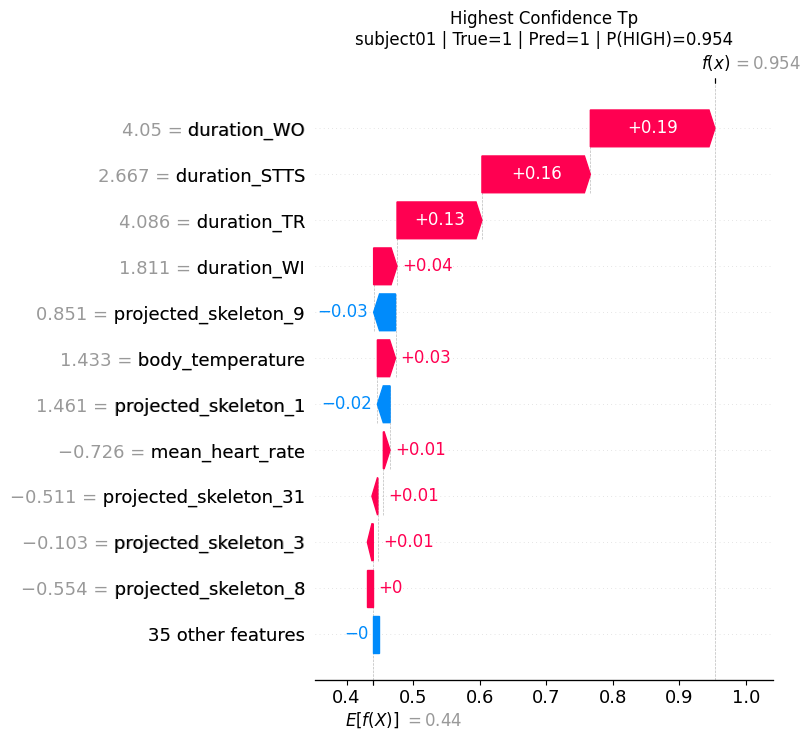

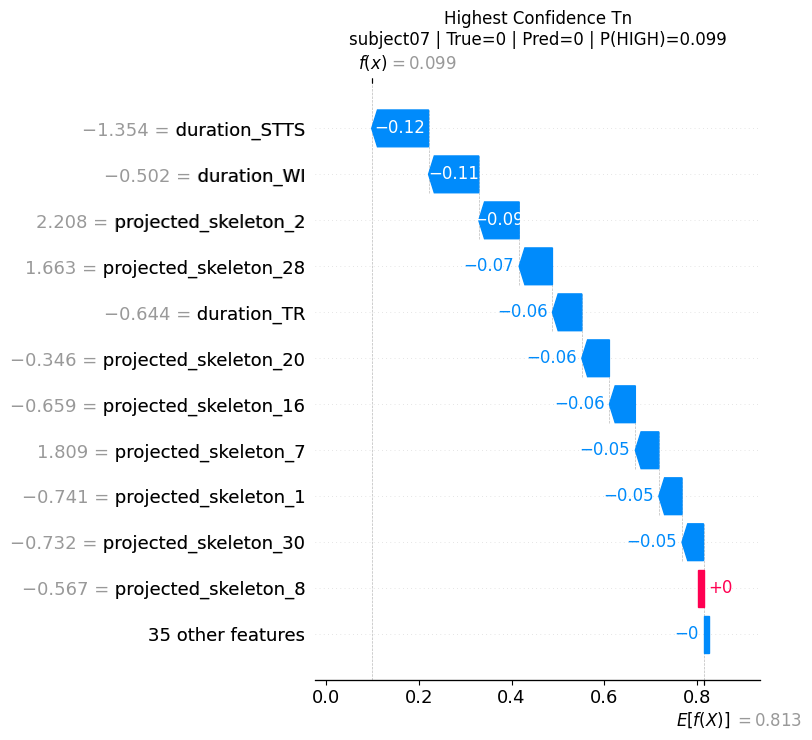

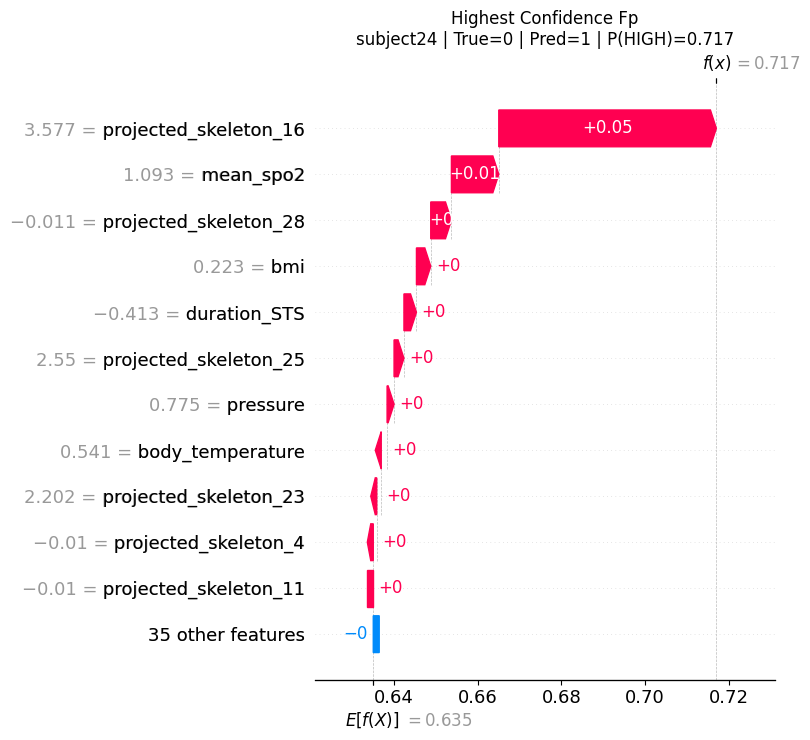

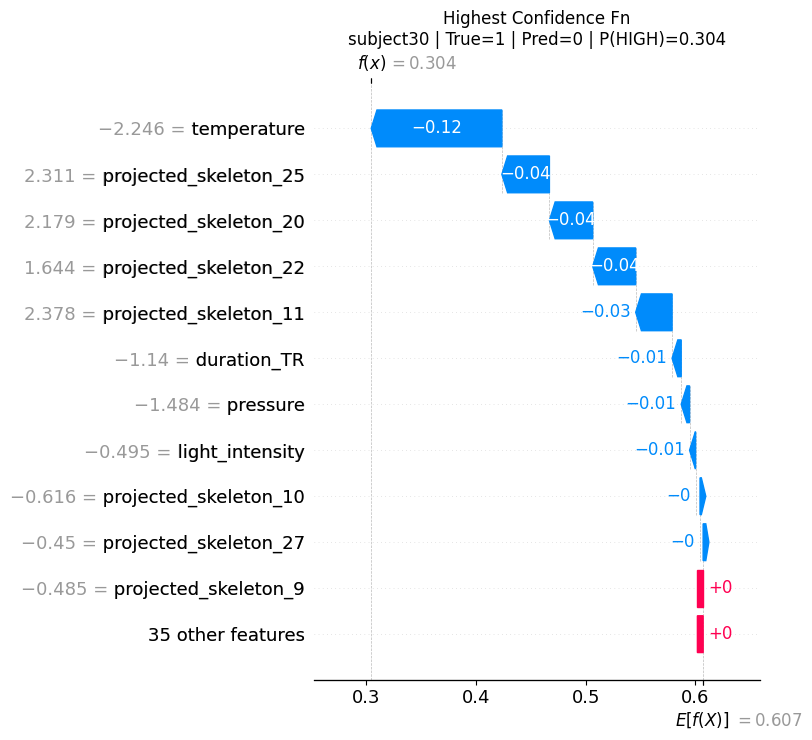

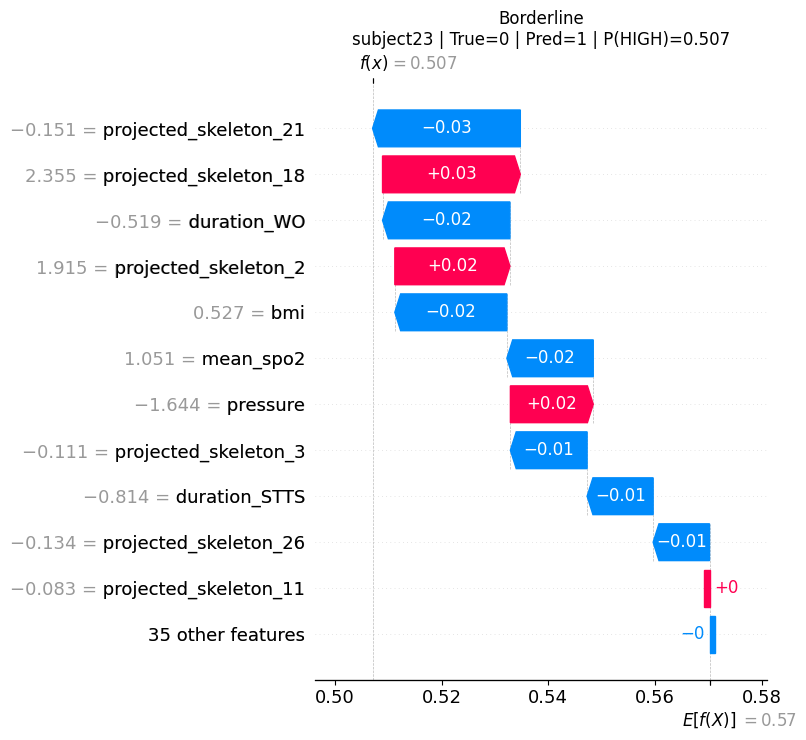

,case,subject,true_label,predicted_label,status,probability_high,top_positive_feature_1,top_positive_shap_1,top_positive_feature_2,top_positive_shap_2,top_negative_feature_1,top_negative_shap_1,top_negative_feature_2,top_negative_shap_2
0,highest_confidence_TP,subject01,1,1,TP,0.953613,duration_WO,0.187225,duration_STTS,0.162894,projected_skeleton_9,-0.032917,projected_skeleton_1,-0.019112
1,highest_confidence_TN,subject07,0,0,TN,0.098771,duration_STS,0.000000,duration_WO,0.000000,duration_STTS,-0.122419,duration_WI,-0.108162
2,highest_confidence_FP,subject24,0,1,FP,0.717061,projected_skeleton_16,0.052028,mean_spo2,0.011327,projected_skeleton_1,0.000000,projected_skeleton_2,0.000000
3,highest_confidence_FN,subject30,1,0,FN,0.304334,duration_STTS,0.000000,duration_WI,0.000000,temperature,-0.119191,projected_skeleton_25,-0.043399
4,borderline,subject23,0,1,FP,0.507085,projected_skeleton_18,0.025801,projected_skeleton_2,0.021554,projected_skeleton_21,-0.027663,duration_WO,-0.023856


In [ ]:
# ============================================================
# STEP 20: INDIVIDUAL PREDICTION EXPLANATION
#
# Selected automatically:
# - highest-confidence TP,
# - highest-confidence TN,
# - highest-confidence FP, when available,
# - highest-confidence FN, when available,
# - prediction closest to threshold.
# ============================================================

individual_dir = (
    SHAP_DIR
    / "Individual"
)

individual_dir.mkdir(
    parents=True,
    exist_ok=True,
)

individual_df = pd.DataFrame({
    "subject": subjects,
    "true_label": y,
    "probability_high": (
        oof_internal_probabilities
    ),
})

individual_df[
    "predicted_label"
] = (
    individual_df[
        "probability_high"
    ] >= THRESHOLD
).astype(int)

individual_df[
    "status"
] = np.select(
    [
        (
            individual_df[
                "true_label"
            ] == 1
        )
        & (
            individual_df[
                "predicted_label"
            ] == 1
        ),
        (
            individual_df[
                "true_label"
            ] == 0
        )
        & (
            individual_df[
                "predicted_label"
            ] == 0
        ),
        (
            individual_df[
                "true_label"
            ] == 0
        )
        & (
            individual_df[
                "predicted_label"
            ] == 1
        ),
        (
            individual_df[
                "true_label"
            ] == 1
        )
        & (
            individual_df[
                "predicted_label"
            ] == 0
        ),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown",
)

selected_cases = {}

tp_rows = individual_df[
    individual_df["status"] == "TP"
]

if not tp_rows.empty:
    selected_cases[
        "highest_confidence_TP"
    ] = int(
        tp_rows[
            "probability_high"
        ].idxmax()
    )

tn_rows = individual_df[
    individual_df["status"] == "TN"
]

if not tn_rows.empty:
    selected_cases[
        "highest_confidence_TN"
    ] = int(
        tn_rows[
            "probability_high"
        ].idxmin()
    )

fp_rows = individual_df[
    individual_df["status"] == "FP"
]

if not fp_rows.empty:
    selected_cases[
        "highest_confidence_FP"
    ] = int(
        fp_rows[
            "probability_high"
        ].idxmax()
    )

fn_rows = individual_df[
    individual_df["status"] == "FN"
]

if not fn_rows.empty:
    selected_cases[
        "highest_confidence_FN"
    ] = int(
        fn_rows[
            "probability_high"
        ].idxmin()
    )

selected_cases[
    "borderline"
] = int(
    (
        individual_df[
            "probability_high"
        ] - THRESHOLD
    )
    .abs()
    .idxmin()
)

individual_summary_rows = []

for case_name, subject_index in (
    selected_cases.items()
):
    explanation = shap.Explanation(
        values=(
            oof_internal_shap_values[
                subject_index
            ]
        ),
        base_values=(
            oof_internal_base_values[
                subject_index
            ]
        ),
        data=(
            oof_internal_inputs[
                subject_index
            ]
        ),
        feature_names=(
            INTERNAL_FEATURE_NAMES
        ),
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=False,
    )

    plt.title(
        f"{case_name.replace('_', ' ').title()}\n"
        f"{subjects[subject_index]} | "
        f"True={y[subject_index]} | "
        f"Pred="
        f"{individual_df.loc[subject_index, 'predicted_label']} | "
        f"P(HIGH)="
        f"{oof_internal_probabilities[subject_index]:.3f}"
    )

    plt.tight_layout()

    plt.savefig(
        individual_dir
        / (
            f"{case_name}_"
            f"{subjects[subject_index]}_"
            "Waterfall.png"
        ),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    shap_row = (
        oof_internal_shap_values[
            subject_index
        ]
    )

    positive_order = np.argsort(
        shap_row
    )[::-1]

    negative_order = np.argsort(
        shap_row
    )

    individual_summary_rows.append({
        "case": case_name,
        "subject": subjects[
            subject_index
        ],
        "true_label": int(
            y[subject_index]
        ),
        "predicted_label": int(
            individual_df.loc[
                subject_index,
                "predicted_label",
            ]
        ),
        "status": individual_df.loc[
            subject_index,
            "status",
        ],
        "probability_high": float(
            oof_internal_probabilities[
                subject_index
            ]
        ),
        "top_positive_feature_1": (
            INTERNAL_FEATURE_NAMES[
                positive_order[0]
            ]
        ),
        "top_positive_shap_1": float(
            shap_row[
                positive_order[0]
            ]
        ),
        "top_positive_feature_2": (
            INTERNAL_FEATURE_NAMES[
                positive_order[1]
            ]
        ),
        "top_positive_shap_2": float(
            shap_row[
                positive_order[1]
            ]
        ),
        "top_negative_feature_1": (
            INTERNAL_FEATURE_NAMES[
                negative_order[0]
            ]
        ),
        "top_negative_shap_1": float(
            shap_row[
                negative_order[0]
            ]
        ),
        "top_negative_feature_2": (
            INTERNAL_FEATURE_NAMES[
                negative_order[1]
            ]
        ),
        "top_negative_shap_2": float(
            shap_row[
                negative_order[1]
            ]
        ),
    })

individual_explanation_summary_df = (
    pd.DataFrame(
        individual_summary_rows
    )
)

individual_explanation_summary_df.to_csv(
    individual_dir
    / "Individual_OOF_Explanation_Summary.csv",
    index=False,
)

display(
    individual_explanation_summary_df
)

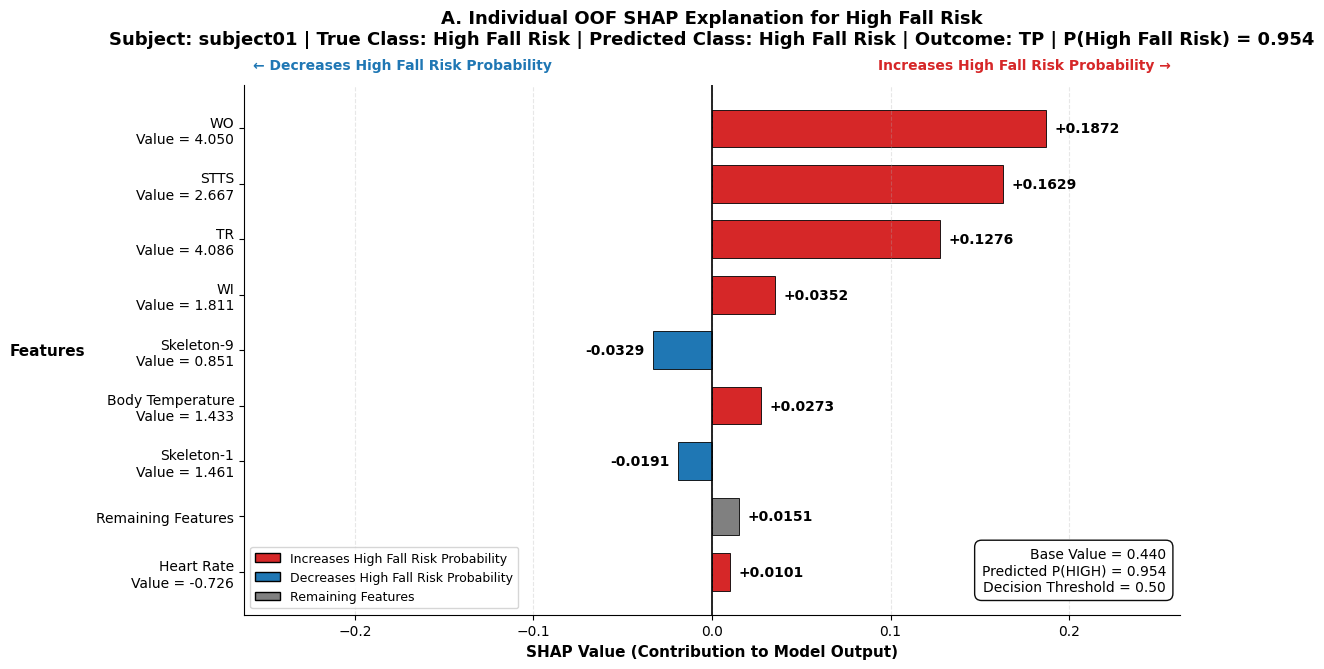

Saved figure: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation/A_Custom_Individual_OOF_SHAP_High_Fall_Risk.png


,subject,panel,true_label,predicted_label,probability_high,feature,feature_value,shap_value,is_other,absolute_shap
0,subject01,A,1,1,0.953613,Heart Rate,-0.725582,0.010139,False,0.010139
1,subject01,A,1,1,0.953613,Remaining Features,NaN,0.015126,True,0.015126
2,subject01,A,1,1,0.953613,Skeleton-1,1.460650,-0.019112,False,0.019112
3,subject01,A,1,1,0.953613,Body Temperature,1.432863,0.027303,False,0.027303
4,subject01,A,1,1,0.953613,Skeleton-9,0.850801,-0.032917,False,0.032917
5,subject01,A,1,1,0.953613,WI,1.810893,0.035151,False,0.035151
6,subject01,A,1,1,0.953613,TR,4.085606,0.127611,False,0.127611
7,subject01,A,1,1,0.953613,STTS,2.666582,0.162894,False,0.162894
8,subject01,A,1,1,0.953613,WO,4.050059,0.187225,False,0.187225


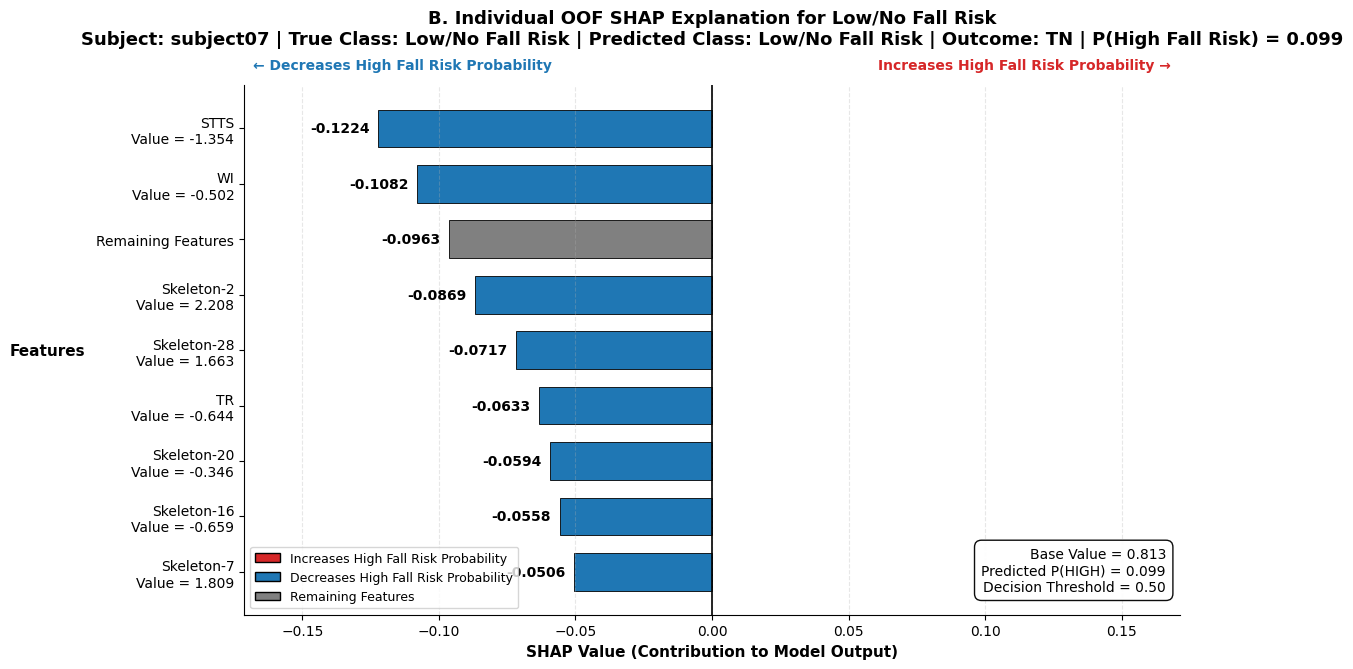

Saved figure: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation/B_Custom_Individual_OOF_SHAP_Low_No_Fall_Risk.png


,subject,panel,true_label,predicted_label,probability_high,feature,feature_value,shap_value,is_other,absolute_shap
0,subject07,B,0,0,0.098771,Skeleton-7,1.809491,-0.050589,False,0.050589
1,subject07,B,0,0,0.098771,Skeleton-16,-0.658692,-0.055846,False,0.055846
2,subject07,B,0,0,0.098771,Skeleton-20,-0.346086,-0.059394,False,0.059394
3,subject07,B,0,0,0.098771,TR,-0.644386,-0.063321,False,0.063321
4,subject07,B,0,0,0.098771,Skeleton-28,1.663480,-0.071676,False,0.071676
5,subject07,B,0,0,0.098771,Skeleton-2,2.207806,-0.086931,False,0.086931
6,subject07,B,0,0,0.098771,Remaining Features,NaN,-0.096270,True,0.096270
7,subject07,B,0,0,0.098771,WI,-0.501905,-0.108162,False,0.108162
8,subject07,B,0,0,0.098771,STTS,-1.354338,-0.122419,False,0.122419


CUSTOM INDIVIDUAL OOF SHAP EXPLANATION COMPLETED
Output directory: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/05_OOF_SHAP_Best_Model/Individual/Custom_Explanation


,panel,subject,true_label,predicted_label,probability_high,status
0,A,subject01,1,1,0.953613,TP
6,B,subject07,0,0,0.098771,TN


In [ ]:
# ============================================================
# STEP 21: CUSTOM INDIVIDUAL OOF SHAP EXPLANATION
#
# Panel A:
# Highest-confidence correctly predicted High Fall Risk subject
#
# Panel B:
# Highest-confidence correctly predicted Low/No Fall Risk subject
#
# This custom visualization replaces shap.force_plot()
# to improve readability for journal publication.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TOP_N_FEATURES = 8
FIGURE_DPI = 400

HIGH_LABEL = "High Fall Risk"
LOW_LABEL = "Low/No Fall Risk"

HIGH_COLOR = "#D62728"
LOW_COLOR = "#1F77B4"
OTHER_COLOR = "#808080"


# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "subjects",
    "y",
    "THRESHOLD",
    "SHAP_DIR",
    "oof_internal_probabilities",
    "oof_internal_shap_values",
    "oof_internal_base_values",
    "oof_internal_inputs",
    "INTERNAL_FEATURE_NAMES",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are unavailable:\n- "
        + "\n- ".join(missing_variables)
        + "\n\nRun all preceding OOF SHAP cells before STEP 21."
    )


# ------------------------------------------------------------
# 3. PREPARE DATA
# ------------------------------------------------------------

subjects_array = np.asarray(
    subjects
).astype(str)

y_array = np.asarray(
    y
).astype(int).reshape(-1)

oof_probabilities = np.asarray(
    oof_internal_probabilities,
    dtype=float,
).reshape(-1)

oof_predictions = (
    oof_probabilities >= THRESHOLD
).astype(int)

oof_shap_values = np.asarray(
    oof_internal_shap_values,
    dtype=float,
)

oof_base_values = np.asarray(
    oof_internal_base_values,
    dtype=float,
).reshape(-1)

oof_inputs = np.asarray(
    oof_internal_inputs,
    dtype=float,
)

feature_names = list(
    INTERNAL_FEATURE_NAMES
)


# ------------------------------------------------------------
# 4. NORMALIZE SHAP ARRAY FORMAT
# ------------------------------------------------------------

if oof_shap_values.ndim == 3:

    if oof_shap_values.shape[-1] == 1:
        oof_shap_values = (
            oof_shap_values[:, :, 0]
        )

    elif oof_shap_values.shape[0] == 1:
        oof_shap_values = (
            oof_shap_values[0]
        )

    else:
        raise ValueError(
            "Unrecognized SHAP value format: "
            f"{oof_shap_values.shape}"
        )


# ------------------------------------------------------------
# 5. VALIDATE DIMENSIONS
# ------------------------------------------------------------

if oof_shap_values.shape != oof_inputs.shape:
    raise ValueError(
        "The SHAP value dimensions do not match "
        "the OOF input dimensions.\n"
        f"SHAP values : {oof_shap_values.shape}\n"
        f"OOF inputs  : {oof_inputs.shape}"
    )

if oof_inputs.shape[1] != len(feature_names):
    raise ValueError(
        "The number of feature names does not match "
        "the number of input columns.\n"
        f"Feature names : {len(feature_names)}\n"
        f"Input columns : {oof_inputs.shape[1]}"
    )

if len(oof_base_values) != len(y_array):
    raise ValueError(
        "The number of OOF base values does not match "
        "the number of subjects."
    )


# ------------------------------------------------------------
# 6. CREATE PREDICTION TABLE
# ------------------------------------------------------------

individual_df = pd.DataFrame({
    "subject": subjects_array,
    "true_label": y_array,
    "predicted_label": oof_predictions,
    "probability_high": oof_probabilities,
})

individual_df["status"] = np.select(
    [
        (
            individual_df["true_label"] == 1
        )
        & (
            individual_df["predicted_label"] == 1
        ),
        (
            individual_df["true_label"] == 0
        )
        & (
            individual_df["predicted_label"] == 0
        ),
        (
            individual_df["true_label"] == 0
        )
        & (
            individual_df["predicted_label"] == 1
        ),
        (
            individual_df["true_label"] == 1
        )
        & (
            individual_df["predicted_label"] == 0
        ),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN",
    ],
    default="Unknown",
)


# ------------------------------------------------------------
# 7. SELECT REPRESENTATIVE SUBJECTS
# ------------------------------------------------------------

tp_indices = np.where(
    (
        y_array == 1
    )
    & (
        oof_predictions == 1
    )
)[0]

tn_indices = np.where(
    (
        y_array == 0
    )
    & (
        oof_predictions == 0
    )
)[0]

if len(tp_indices) == 0:
    raise ValueError(
        "No True Positive case was found for Panel A."
    )

if len(tn_indices) == 0:
    raise ValueError(
        "No True Negative case was found for Panel B."
    )

high_index = int(
    tp_indices[
        np.argmax(
            oof_probabilities[
                tp_indices
            ]
        )
    ]
)

low_index = int(
    tn_indices[
        np.argmin(
            oof_probabilities[
                tn_indices
            ]
        )
    ]
)


# ------------------------------------------------------------
# 8. OUTPUT DIRECTORY
# ------------------------------------------------------------

custom_explanation_dir = (
    Path(SHAP_DIR)
    / "Individual"
    / "Custom_Explanation"
)

custom_explanation_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 9. SHORTEN FEATURE NAMES
# ------------------------------------------------------------

def shorten_feature_name(
    feature_name,
):
    """
    Convert internal feature names into concise,
    publication-friendly labels.
    """

    name = str(feature_name)

    replacements = {
        "duration_": "",
        "projected_skeleton_": "Skeleton-",
        "skeleton_projection_": "Skeleton-",
        "skel_emb_": "Skeleton-",
        "light_intensity": "Light Intensity",
        "body_temperature": "Body Temperature",
        "mean_heart_rate": "Heart Rate",
        "mean_spo2": "SpO₂",
        "bmi": "BMI",
        "temperature": "Temperature",
        "humidity": "Humidity",
        "pressure": "Pressure",
        "age": "Age",
    }

    for old_text, new_text in replacements.items():
        name = name.replace(
            old_text,
            new_text,
        )

    name = name.replace(
        "_",
        " ",
    )

    return name.strip()


# ------------------------------------------------------------
# 10. PREPARE TOP FEATURE CONTRIBUTIONS
# ------------------------------------------------------------

def prepare_contribution_data(
    subject_index,
    top_n=8,
):
    """
    Select the strongest SHAP contributions and aggregate
    all remaining contributions into 'Remaining Features'.
    """

    shap_row = np.asarray(
        oof_shap_values[
            subject_index
        ],
        dtype=float,
    )

    feature_row = np.asarray(
        oof_inputs[
            subject_index
        ],
        dtype=float,
    )

    ranked_indices = np.argsort(
        np.abs(shap_row)
    )[::-1]

    top_indices = ranked_indices[
        :top_n
    ]

    other_indices = ranked_indices[
        top_n:
    ]

    rows = []

    for feature_index in top_indices:

        rows.append({
            "feature": shorten_feature_name(
                feature_names[
                    feature_index
                ]
            ),
            "feature_value": float(
                feature_row[
                    feature_index
                ]
            ),
            "shap_value": float(
                shap_row[
                    feature_index
                ]
            ),
            "is_other": False,
        })

    if len(other_indices) > 0:

        remaining_shap = float(
            np.sum(
                shap_row[
                    other_indices
                ]
            )
        )

        rows.append({
            "feature": "Remaining Features",
            "feature_value": np.nan,
            "shap_value": remaining_shap,
            "is_other": True,
        })

    contribution_df = pd.DataFrame(
        rows
    )

    contribution_df["absolute_shap"] = (
        contribution_df[
            "shap_value"
        ].abs()
    )

    # Sort from smallest to largest so that the strongest
    # contribution appears at the top of the horizontal chart.
    contribution_df = (
        contribution_df
        .sort_values(
            "absolute_shap",
            ascending=True,
        )
        .reset_index(
            drop=True
        )
    )

    return contribution_df


# ------------------------------------------------------------
# 11. CREATE CUSTOM INDIVIDUAL EXPLANATION
# ------------------------------------------------------------

def save_custom_individual_explanation(
    subject_index,
    panel_label,
    class_title,
    file_name,
    top_n=8,
):
    """
    Create a publication-ready horizontal SHAP contribution
    plot for one out-of-fold prediction.
    """

    contribution_df = (
        prepare_contribution_data(
            subject_index=subject_index,
            top_n=top_n,
        )
    )

    base_value = float(
        oof_base_values[
            subject_index
        ]
    )

    probability = float(
        oof_probabilities[
            subject_index
        ]
    )

    prediction = int(
        oof_predictions[
            subject_index
        ]
    )

    true_label = int(
        y_array[
            subject_index
        ]
    )

    status = str(
        individual_df.loc[
            subject_index,
            "status",
        ]
    )

    predicted_class_name = (
        HIGH_LABEL
        if prediction == 1
        else LOW_LABEL
    )

    true_class_name = (
        HIGH_LABEL
        if true_label == 1
        else LOW_LABEL
    )

    # Colors indicate contribution direction.
    bar_colors = []

    for _, row in contribution_df.iterrows():

        if row["is_other"]:
            bar_colors.append(
                OTHER_COLOR
            )

        elif row["shap_value"] >= 0:
            bar_colors.append(
                HIGH_COLOR
            )

        else:
            bar_colors.append(
                LOW_COLOR
            )

    y_positions = np.arange(
        len(
            contribution_df
        )
    )

    fig, ax = plt.subplots(
        figsize=(12, 6.8)
    )

    bars = ax.barh(
        y_positions,
        contribution_df[
            "shap_value"
        ],
        color=bar_colors,
        edgecolor="black",
        linewidth=0.6,
        height=0.68,
    )

    # Zero-reference line.
    ax.axvline(
        x=0,
        linewidth=1.2,
        color="black",
    )

    # Prediction-direction annotations.
    ax.text(
        0.01,
        1.025,
        "← Decreases High Fall Risk Probability",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=LOW_COLOR,
    )

    ax.text(
        0.99,
        1.025,
        "Increases High Fall Risk Probability →",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=HIGH_COLOR,
    )

    # Feature labels.
    y_labels = []

    for _, row in contribution_df.iterrows():

        if row["is_other"]:
            label = row["feature"]

        else:
            label = (
                f"{row['feature']}\n"
                f"Value = {row['feature_value']:.3f}"
            )

        y_labels.append(
            label
        )

    ax.set_yticks(
        y_positions
    )

    ax.set_yticklabels(
        y_labels,
        fontsize=10,
    )

    # SHAP-value annotations.
    max_abs_shap = max(
        contribution_df[
            "absolute_shap"
        ].max(),
        1e-6,
    )

    label_offset = (
        max_abs_shap * 0.025
    )

    for bar, shap_value in zip(
        bars,
        contribution_df[
            "shap_value"
        ],
    ):

        if shap_value >= 0:

            x_position = (
                shap_value
                + label_offset
            )

            horizontal_alignment = (
                "left"
            )

        else:

            x_position = (
                shap_value
                - label_offset
            )

            horizontal_alignment = (
                "right"
            )

        ax.text(
            x_position,
            bar.get_y()
            + bar.get_height() / 2,
            f"{shap_value:+.4f}",
            va="center",
            ha=horizontal_alignment,
            fontsize=10,
            fontweight="bold",
        )

    # Provide sufficient horizontal margin.
    x_limit = (
        max_abs_shap * 1.40
    )

    ax.set_xlim(
        -x_limit,
        x_limit,
    )

    ax.set_xlabel(
        "SHAP Value (Contribution to Model Output)",
        fontsize=11,
        fontweight="bold",
    )

    #ax.set_ylabel(
    #   "Features",
    #   fontsize=11,
    #   fontweight="bold",
    #)

    ax.set_ylabel(
    "Features",
    fontsize=11,
    fontweight="bold",
    rotation=0,
    labelpad=35,
    va="center",
    )

    ax.set_title(
        (
            f"{panel_label}. Individual OOF SHAP Explanation "
            f"for {class_title}\n"
            f"Subject: {subjects_array[subject_index]} | "
            f"True Class: {true_class_name} | "
            f"Predicted Class: {predicted_class_name} | "
            f"Outcome: {status} | "
            f"P(High Fall Risk) = {probability:.3f}"
        ),
        fontsize=13,
        fontweight="bold",
        pad=30,
    )

    # Prediction-summary box.
    summary_text = (
        f"Base Value = {base_value:.3f}\n"
        f"Predicted P(HIGH) = {probability:.3f}\n"
        f"Decision Threshold = {THRESHOLD:.2f}"
    )

    ax.text(
        0.985,
        0.04,
        summary_text,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.5",
            "facecolor": "white",
            "edgecolor": "black",
            "alpha": 0.95,
        },
    )

    legend_handles = [
        Patch(
            facecolor=HIGH_COLOR,
            edgecolor="black",
            label=(
                "Increases High Fall Risk Probability"
            ),
        ),
        Patch(
            facecolor=LOW_COLOR,
            edgecolor="black",
            label=(
                "Decreases High Fall Risk Probability"
            ),
        ),
        Patch(
            facecolor=OTHER_COLOR,
            edgecolor="black",
            label="Remaining Features",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        fontsize=9,
        frameon=True,
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.30,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    plt.tight_layout()

    output_path = (
        custom_explanation_dir
        / file_name
    )

    plt.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        pad_inches=0.25,
        facecolor="white",
    )

    plt.show()
    plt.close()

    # Save the numerical contribution table.
    contribution_output = (
        contribution_df.copy()
    )

    contribution_output.insert(
        0,
        "subject",
        subjects_array[
            subject_index
        ],
    )

    contribution_output.insert(
        1,
        "panel",
        panel_label,
    )

    contribution_output.insert(
        2,
        "true_label",
        true_label,
    )

    contribution_output.insert(
        3,
        "predicted_label",
        prediction,
    )

    contribution_output.insert(
        4,
        "probability_high",
        probability,
    )

    contribution_output.to_csv(
        custom_explanation_dir
        / file_name.replace(
            ".png",
            "_Contributions.csv",
        ),
        index=False,
    )

    print(
        "Saved figure:",
        output_path,
    )

    display(
        contribution_output
    )


# ------------------------------------------------------------
# 12. PANEL A: HIGH FALL RISK
# ------------------------------------------------------------

save_custom_individual_explanation(
    subject_index=high_index,
    panel_label="A",
    class_title=HIGH_LABEL,
    file_name=(
        "A_Custom_Individual_OOF_SHAP_"
        "High_Fall_Risk.png"
    ),
    top_n=TOP_N_FEATURES,
)


# ------------------------------------------------------------
# 13. PANEL B: LOW/NO FALL RISK
# ------------------------------------------------------------

save_custom_individual_explanation(
    subject_index=low_index,
    panel_label="B",
    class_title=LOW_LABEL,
    file_name=(
        "B_Custom_Individual_OOF_SHAP_"
        "Low_No_Fall_Risk.png"
    ),
    top_n=TOP_N_FEATURES,
)


# ------------------------------------------------------------
# 14. SAVE SELECTED SUBJECTS
# ------------------------------------------------------------

selected_cases_df = (
    individual_df.iloc[
        [
            high_index,
            low_index,
        ]
    ]
    .copy()
)

selected_cases_df.insert(
    0,
    "panel",
    [
        "A",
        "B",
    ],
)

selected_cases_df.to_csv(
    custom_explanation_dir
    / "Selected_Custom_Individual_OOF_SHAP_Cases.csv",
    index=False,
)

print("=" * 72)
print("CUSTOM INDIVIDUAL OOF SHAP EXPLANATION COMPLETED")
print("=" * 72)
print("Output directory:", custom_explanation_dir)

display(
    selected_cases_df
)

In [ ]:
# ============================================================
# STEP 22: SAVE COMPLETE OOF SHAP MATRICES AND FINAL SUMMARY
# ============================================================

shap_values_df = pd.DataFrame(
    oof_internal_shap_values,
    columns=INTERNAL_FEATURE_NAMES,
)
shap_values_df.insert(0, "subject", subjects)
shap_values_df.insert(1, "true_label", y)
shap_values_df.insert(
    2,
    "probability_high",
    oof_internal_probabilities,
)

shap_inputs_df = pd.DataFrame(
    oof_internal_inputs,
    columns=INTERNAL_FEATURE_NAMES,
)
shap_inputs_df.insert(0, "subject", subjects)

selected_prefix = (
    "Context_Aware"
    if BEST_INCLUDE_CONTEXT
    else "Baseline_Without_Context"
)

shap_values_df.to_csv(
    SHAP_TABLE_DIR
    / f"{selected_prefix}_OOF_SHAP_Values.csv",
    index=False,
)
shap_inputs_df.to_csv(
    SHAP_TABLE_DIR
    / f"{selected_prefix}_OOF_SHAP_Internal_Inputs.csv",
    index=False,
)

baseline_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == BASELINE_MODEL_NAME
].iloc[0]

proposed_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == PROPOSED_MODEL_NAME
].iloc[0]

selected_pooled_row = pooled_metrics_df[
    pooled_metrics_df["model"] == BEST_MODEL_NAME
].iloc[0]

experiment_summary = {
    "n_subjects": int(len(subjects)),
    "n_low_no": int((y == 0).sum()),
    "n_high": int((y == 1).sum()),
    "projection_sizes_tested": PROJECTION_SIZES,
    "selected_projection_dim": int(
        BEST_PROJECTION_DIM
    ),
    "validation": "Repeated LOSO",
    "random_seeds": RANDOM_SEEDS,
    "primary_seed_for_oof_shap": PRIMARY_SEED,
    "threshold": THRESHOLD,
    "selected_best_model": BEST_MODEL_NAME,
    "selected_configuration": BEST_CONFIGURATION_NAME,
    "selected_model_includes_context": BEST_INCLUDE_CONTEXT,
    "selected_fusion_dimension": BEST_FUSION_DIMENSION,
    "selected_pooled_roc_auc": float(
        selected_pooled_row["roc_auc"]
    ),
    "selected_pooled_macro_f1": float(
        selected_pooled_row["macro_f1"]
    ),
    "selected_pooled_balanced_accuracy": float(
        selected_pooled_row["balanced_accuracy"]
    ),
    "baseline_pooled_roc_auc": float(
        baseline_pooled_row["roc_auc"]
    ),
    "context_aware_pooled_roc_auc": float(
        proposed_pooled_row["roc_auc"]
    ),
    "top_global_shap_feature": str(
        global_shap_df.iloc[0]["feature"]
    ),
    "top_shap_feature_group": str(
        group_shap_df.iloc[0]["feature_group"]
    ),
    "internal_shap_feature_count": int(
        INTERNAL_FEATURE_COUNT
    ),
    "shap_feature_groups": list(
        FEATURE_GROUPS.keys()
    ),
    "result_directories": {
        "projection": str(PROJECTION_DIR),
        "baseline_without_context": str(BASELINE_DIR),
        "context_aware": str(PROPOSED_DIR),
        "comparison": str(COMPARISON_DIR),
        "oof_shap": str(SHAP_DIR),
    },
}

with open(
    OUTPUT_DIR / "Experiment_Summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        experiment_summary,
        file,
        indent=2,
    )

print("=" * 72)
print("EXPERIMENT COMPLETED")
print("=" * 72)
print(json.dumps(experiment_summary, indent=2))
print("=" * 72)
print("Results saved to:")
print(OUTPUT_DIR)


EXPERIMENT COMPLETED
{
  "n_subjects": 30,
  "n_low_no": 10,
  "n_high": 20,
  "projection_sizes_tested": [
    64,
    32,
    16,
    8
  ],
  "selected_projection_dim": 32,
  "validation": "Repeated LOSO",
  "random_seeds": [
    42,
    123,
    2026
  ],
  "primary_seed_for_oof_shap": 42,
  "threshold": 0.5,
  "selected_best_model": "MLP_Dense32_Context_Duration_Physiological",
  "selected_configuration": "Dense-8 + Context + Physiological + Phase Duration",
  "selected_model_includes_context": true,
  "selected_fusion_dimension": 46,
  "selected_pooled_roc_auc": 0.75,
  "selected_pooled_macro_f1": 0.576379974326059,
  "selected_pooled_balanced_accuracy": 0.575,
  "baseline_pooled_roc_auc": 0.73,
  "context_aware_pooled_roc_auc": 0.75,
  "top_global_shap_feature": "duration_STTS",
  "top_shap_feature_group": "Projected Skeleton",
  "internal_shap_feature_count": 46,
  "shap_feature_groups": [
    "Projected Skeleton",
    "Context",
    "Physiological",
    "Phase Duration"
  ],
 

In [ ]:
from pathlib import Path
import pandas as pd

# ============================================================
# PATH
# ============================================================

TABLE_DIR = Path(
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/"
    "GENERATE_Multimodal_Fall_Risk_11-10-2026/"
    "Tables"
)

FIGURE_DIR = Path(
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/"
    "GENERATE_Multimodal_Fall_Risk_11-10-2026/"
    "Projection_Size_Experiment/Figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# FILES
# ============================================================

prediction_file = (
    TABLE_DIR
    / "Projection_Size_OOF_Predictions.csv"
)

metric_file = (
    TABLE_DIR
    / "Projection_Size_Performance_By_Seed.csv"
)

summary_file = (
    TABLE_DIR
    / "Projection_Size_Summary.csv"
)


# ============================================================
# CHECK FILES
# ============================================================

print("TABLE DIRECTORY:")
print(TABLE_DIR)

print("\nFILE CHECK:")

print(
    "OOF Predictions :",
    prediction_file.exists(),
    prediction_file
)

print(
    "Performance     :",
    metric_file.exists(),
    metric_file
)

print(
    "Summary         :",
    summary_file.exists(),
    summary_file
)


# ============================================================
# LOAD
# ============================================================

projection_predictions_df = pd.read_csv(
    prediction_file
)

projection_metrics_df = pd.read_csv(
    metric_file
)

projection_summary_df = pd.read_csv(
    summary_file
)


print("\nFILES LOADED SUCCESSFULLY")

print(
    "OOF Predictions:",
    projection_predictions_df.shape
)

print(
    "Performance By Seed:",
    projection_metrics_df.shape
)

print(
    "Summary:",
    projection_summary_df.shape
)

display(
    projection_predictions_df.head()
)

display(
    projection_metrics_df
)

display(
    projection_summary_df
)

TABLE DIRECTORY:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Tables

FILE CHECK:
OOF Predictions : False /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Tables/Projection_Size_OOF_Predictions.csv
Performance     : False /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Tables/Projection_Size_Performance_By_Seed.csv
Summary         : False /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Tables/Projection_Size_Summary.csv


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Tables/Projection_Size_OOF_Predictions.csv'

Projection dimensions: [np.int64(64), np.int64(32), np.int64(16), np.int64(8)]
Random seeds: [np.int64(42), np.int64(123), np.int64(2026)]


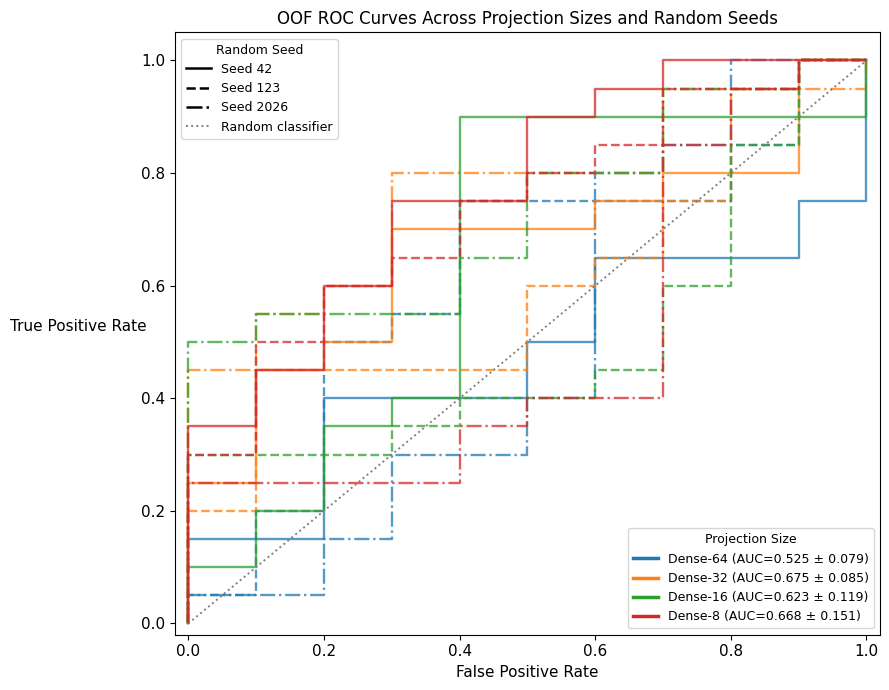


AUC FOR ALL 12 OOF ROC CURVES


,projection_dim,seed,roc_auc
0,64,42,0.470
1,64,123,0.615
2,64,2026,0.490
3,32,42,0.665
4,32,123,0.595
5,32,2026,0.765
6,16,42,0.645
7,16,123,0.495
8,16,2026,0.730
9,8,42,0.775



Figure saved to:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk_11-10-2026/Projection_Size_Experiment/Figures/Projection_Size_12_OOF_ROC_Curves_SeedWise.png


In [ ]:
# ============================================================
# 12 SEED-WISE OOF ROC CURVES
# 4 PROJECTION SIZES × 3 RANDOM SEEDS
# NO RETRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.lines import Line2D


# ============================================================
# 1. GET PROJECTION SIZES AND SEEDS FROM SAVED CSV
# ============================================================

PROJECTION_DIMS = sorted(
    projection_predictions_df[
        "projection_dim"
    ]
    .unique()
    .astype(int),
    reverse=True
)

RANDOM_SEEDS = sorted(
    projection_predictions_df[
        "seed"
    ]
    .unique()
    .astype(int)
)

print("Projection dimensions:", PROJECTION_DIMS)
print("Random seeds:", RANDOM_SEEDS)


# ============================================================
# 2. VISUAL MAPPING
#
# COLOR     = PROJECTION SIZE
# LINESTYLE = RANDOM SEED
# ============================================================

PROJECTION_COLORS = {
    64: "tab:blue",
    32: "tab:orange",
    16: "tab:green",
    8: "tab:red",
}


SEED_LINESTYLES = {
    42: "-",
    123: "--",
    2025: "-.",
}


# Fallback if seed values are different
default_linestyles = [
    "-",
    "--",
    "-.",
    ":",
]

for i, seed in enumerate(RANDOM_SEEDS):

    if seed not in SEED_LINESTYLES:

        SEED_LINESTYLES[seed] = (
            default_linestyles[
                i % len(default_linestyles)
            ]
        )


# ============================================================
# 3. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)


# ============================================================
# 4. DRAW ALL 12 ROC CURVES
# ============================================================

roc_results = []


for projection_dim in PROJECTION_DIMS:

    for seed in RANDOM_SEEDS:

        # ----------------------------------------------------
        # GET COMPLETE OOF VECTOR FOR ONE PROJECTION + ONE SEED
        # ----------------------------------------------------

        seed_df = (
            projection_predictions_df[
                (
                    projection_predictions_df[
                        "projection_dim"
                    ]
                    == projection_dim
                )
                &
                (
                    projection_predictions_df[
                        "seed"
                    ]
                    == seed
                )
            ]
            .sort_values(
                "subject"
            )
        )


        if len(seed_df) == 0:

            print(
                f"WARNING: no data for "
                f"Dense-{projection_dim}, Seed {seed}"
            )

            continue


        y_true = (
            seed_df[
                "true_label"
            ]
            .to_numpy()
        )

        y_prob = (
            seed_df[
                "probability_high"
            ]
            .to_numpy()
        )


        # ----------------------------------------------------
        # ROC
        # ----------------------------------------------------

        fpr, tpr, _ = roc_curve(
            y_true,
            y_prob
        )

        auc_value = roc_auc_score(
            y_true,
            y_prob
        )


        # ----------------------------------------------------
        # STORE RESULT
        # ----------------------------------------------------

        roc_results.append(
            {
                "projection_dim": projection_dim,
                "seed": seed,
                "roc_auc": auc_value,
            }
        )


        # ----------------------------------------------------
        # PLOT ONE CURVE
        # ----------------------------------------------------

        ax.plot(
            fpr,
            tpr,
            color=PROJECTION_COLORS.get(
                projection_dim,
                "black"
            ),
            linestyle=SEED_LINESTYLES[
                seed
            ],
            linewidth=1.7,
            alpha=0.75,
        )


# ============================================================
# 5. RANDOM CLASSIFIER
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    color="gray",
    linewidth=1.4,
)


# ============================================================
# 6. CALCULATE MEAN ± SD FOR PROJECTION-SIZE LEGEND
# ============================================================

roc_results_df = pd.DataFrame(
    roc_results
)

auc_summary = (
    roc_results_df
    .groupby(
        "projection_dim"
    )["roc_auc"]
    .agg(
        ["mean", "std"]
    )
)


# ============================================================
# 7. CREATE TWO-PART LEGEND
#
# LEGEND 1 = PROJECTION SIZE / COLOR
# LEGEND 2 = RANDOM SEED / LINE STYLE
# ============================================================

projection_handles = []

for projection_dim in PROJECTION_DIMS:

    mean_auc = (
        auc_summary.loc[
            projection_dim,
            "mean"
        ]
    )

    std_auc = (
        auc_summary.loc[
            projection_dim,
            "std"
        ]
    )

    projection_handles.append(

        Line2D(
            [0],
            [0],
            color=PROJECTION_COLORS.get(
                projection_dim,
                "black"
            ),
            linewidth=2.5,
            linestyle="-",
            label=(
                f"Dense-{projection_dim} "
                f"(AUC={mean_auc:.3f} ± {std_auc:.3f})"
            ),
        )

    )


projection_legend = ax.legend(
    handles=projection_handles,
    title="Projection Size",
    loc="lower right",
    fontsize=9,
    title_fontsize=9,
)

ax.add_artist(
    projection_legend
)


# ------------------------------------------------------------
# SEED LEGEND
# ------------------------------------------------------------

seed_handles = []

for seed in RANDOM_SEEDS:

    seed_handles.append(

        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.8,
            linestyle=SEED_LINESTYLES[
                seed
            ],
            label=f"Seed {seed}",
        )

    )


seed_handles.append(

    Line2D(
        [0],
        [0],
        color="gray",
        linewidth=1.4,
        linestyle=":",
        label="Random classifier",
    )

)


ax.legend(
    handles=seed_handles,
    title="Random Seed",
    loc="upper left",
    fontsize=9,
    title_fontsize=9,
)


# ============================================================
# 8. FORMATTING
# ============================================================

ax.set_xlabel(
    "False Positive Rate",
    fontsize=11
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=11,
    rotation=0,
    labelpad=45
)

ax.set_title(
    "OOF ROC Curves Across Projection Sizes and Random Seeds",
    fontsize=12
)

ax.tick_params(
    axis="both",
    labelsize=11
)

ax.set_xlim(
    -0.02,
    1.02
)

ax.set_ylim(
    -0.02,
    1.05
)

plt.tight_layout()


# ============================================================
# 9. SAVE
# ============================================================

output_path = (
    FIGURE_DIR
    / "Projection_Size_12_OOF_ROC_Curves_SeedWise.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. DISPLAY EXACT AUC FOR ALL 12 CURVES
# ============================================================

roc_results_df = (
    roc_results_df
    .sort_values(
        [
            "projection_dim",
            "seed",
        ],
        ascending=[
            False,
            True,
        ]
    )
    .reset_index(
        drop=True
    )
)

print("\n" + "=" * 80)
print("AUC FOR ALL 12 OOF ROC CURVES")
print("=" * 80)

display(
    roc_results_df
)


print("\nFigure saved to:")
print(output_path)

FILE CHECK
Baseline OOF predictions       : FOUND
   /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/02_Baseline_Without_Context/Tables/Baseline_OOF_Predictions.csv
Baseline performance           : FOUND
   /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/02_Baseline_Without_Context/Tables/Baseline_Performance_By_Seed.csv
Context OOF predictions        : FOUND
   /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/03_Context_Aware_Model/Tables/Proposed_OOF_Predictions.csv
Context performance            : FOUND
   /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/03_Context_Aware_Model/Tables/Proposed_Performance_By_Seed.csv

DATA LOADED
Baseline OOF predictions : (90, 9)
Baseline performance     : (3, 17)
Context OOF predictions  : (90, 9)
Context performance      : (3, 17)

Baseline prediction columns:
['model', 'include_context', 'projection_dim', 'seed', 'subj

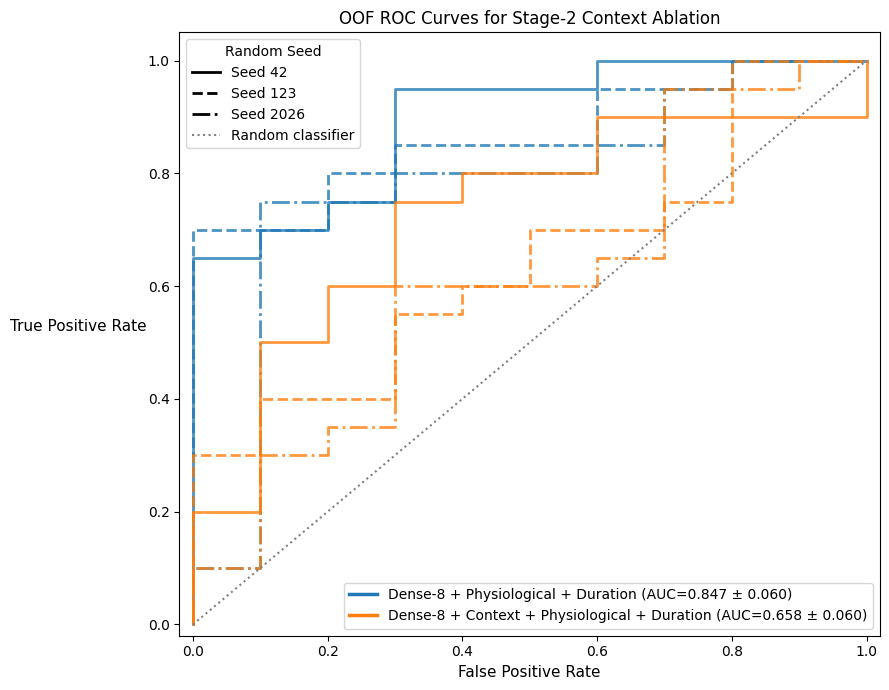


BASELINE AUC VALUES — FROM CSV
 seed  roc_auc
   42    0.895
  123    0.865
 2026    0.780

Mean ± SD: 0.847 ± 0.060

CONTEXT-AWARE AUC VALUES — FROM CSV
 seed  roc_auc
   42    0.725
  123    0.640
 2026    0.610

Mean ± SD: 0.658 ± 0.060

FIGURE SAVED
PNG: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/04_Context_Ablation_Comparison/Figures/Context_Ablation_OOF_ROC_SeedWise.png
PDF: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/GENERATE_Multimodal_Fall_Risk/04_Context_Ablation_Comparison/Figures/Context_Ablation_OOF_ROC_SeedWise.pdf


In [ ]:
# ============================================================
# FINAL FIGURE
# STAGE-2 CONTEXT ABLATION — 6 OOF ROC CURVES
#
# Baseline : 02_Baseline_Without_Context
# Context  : 03_Context_Aware_Model
#
# NO MODEL TRAINING
# AUC VALUES ARE READ FROM SAVED CSV
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve
from matplotlib.lines import Line2D


# ============================================================
# 1. ROOT DIRECTORY
# ============================================================

ROOT_DIR = Path(
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/"
    "GENERATE_Multimodal_Fall_Risk"
)


# ============================================================
# 2. EXACT TABLE DIRECTORIES
# ============================================================

BASELINE_TABLE_DIR = (
    ROOT_DIR
    / "02_Baseline_Without_Context"
    / "Tables"
)

CONTEXT_TABLE_DIR = (
    ROOT_DIR
    / "03_Context_Aware_Model"
    / "Tables"
)


# ============================================================
# 3. EXACT CSV FILES
# ============================================================

baseline_prediction_file = (
    BASELINE_TABLE_DIR
    / "Baseline_OOF_Predictions.csv"
)

baseline_performance_file = (
    BASELINE_TABLE_DIR
    / "Baseline_Performance_By_Seed.csv"
)


context_prediction_file = (
    CONTEXT_TABLE_DIR
    / "Proposed_OOF_Predictions.csv"
)

context_performance_file = (
    CONTEXT_TABLE_DIR
    / "Proposed_Performance_By_Seed.csv"
)


# ============================================================
# 4. VERIFY FILES
# ============================================================

files_to_check = {
    "Baseline OOF predictions":
        baseline_prediction_file,

    "Baseline performance":
        baseline_performance_file,

    "Context OOF predictions":
        context_prediction_file,

    "Context performance":
        context_performance_file,
}


print("=" * 80)
print("FILE CHECK")
print("=" * 80)

for name, path in files_to_check.items():

    print(
        f"{name:<30} : "
        f"{'FOUND' if path.exists() else 'NOT FOUND'}"
    )

    print(f"   {path}")


missing_files = [
    path
    for path in files_to_check.values()
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "\nOne or more CSV files were not found. "
        "Check ROOT_DIR."
    )


# ============================================================
# 5. READ CSV
# ============================================================

baseline_pred_df = pd.read_csv(
    baseline_prediction_file
)

baseline_perf_df = pd.read_csv(
    baseline_performance_file
)

context_pred_df = pd.read_csv(
    context_prediction_file
)

context_perf_df = pd.read_csv(
    context_performance_file
)


print("\n" + "=" * 80)
print("DATA LOADED")
print("=" * 80)

print(
    "Baseline OOF predictions :",
    baseline_pred_df.shape
)

print(
    "Baseline performance     :",
    baseline_perf_df.shape
)

print(
    "Context OOF predictions  :",
    context_pred_df.shape
)

print(
    "Context performance      :",
    context_perf_df.shape
)


# ============================================================
# 6. SHOW COLUMNS
# ============================================================

print("\nBaseline prediction columns:")
print(baseline_pred_df.columns.tolist())

print("\nContext prediction columns:")
print(context_pred_df.columns.tolist())

print("\nBaseline performance columns:")
print(baseline_perf_df.columns.tolist())

print("\nContext performance columns:")
print(context_perf_df.columns.tolist())


# ============================================================
# 7. VALIDATE REQUIRED COLUMNS
# ============================================================

prediction_required = [
    "seed",
    "true_label",
    "probability_high"
]

performance_required = [
    "seed",
    "roc_auc"
]


for name, df in [
    ("Baseline predictions", baseline_pred_df),
    ("Context predictions", context_pred_df)
]:

    missing = [
        c for c in prediction_required
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{name} missing columns: {missing}"
        )


for name, df in [
    ("Baseline performance", baseline_perf_df),
    ("Context performance", context_perf_df)
]:

    missing = [
        c for c in performance_required
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{name} missing columns: {missing}"
        )


# ============================================================
# 8. DETECT RANDOM SEEDS FROM CSV
# ============================================================

baseline_seeds = sorted(
    baseline_pred_df["seed"]
    .astype(int)
    .unique()
)

context_seeds = sorted(
    context_pred_df["seed"]
    .astype(int)
    .unique()
)


RANDOM_SEEDS = sorted(
    set(baseline_seeds)
    .intersection(context_seeds)
)


print("\n" + "=" * 80)
print("RANDOM SEEDS")
print("=" * 80)

print("Baseline :", baseline_seeds)
print("Context  :", context_seeds)
print("Used     :", RANDOM_SEEDS)


# ============================================================
# 9. FONT SETTINGS
# ALL FIGURE TEXT >= 10 pt
# ============================================================

plt.rcParams.update({

    "font.size": 10,

    "axes.titlesize": 12,

    "axes.labelsize": 11,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "legend.title_fontsize": 10,
})


# ============================================================
# 10. VISUAL MAPPING
#
# COLOR     = CONFIGURATION
# LINESTYLE = RANDOM SEED
# ============================================================

BASELINE_COLOR = "tab:blue"

CONTEXT_COLOR = "tab:orange"


LINESTYLES = [
    "-",
    "--",
    "-."
]


SEED_LINESTYLES = {

    seed: LINESTYLES[i]

    for i, seed in enumerate(
        RANDOM_SEEDS
    )
}


# ============================================================
# 11. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)


# ============================================================
# 12. BASELINE — 3 ROC CURVES
# ============================================================

for seed in RANDOM_SEEDS:

    seed_df = baseline_pred_df[
        baseline_pred_df["seed"].astype(int)
        == seed
    ].copy()


    if "subject" in seed_df.columns:

        seed_df = seed_df.sort_values(
            "subject"
        )


    y_true = (
        seed_df["true_label"]
        .to_numpy()
    )

    y_prob = (
        seed_df["probability_high"]
        .to_numpy()
    )


    # Only converts saved OOF probabilities
    # into ROC coordinates.
    # AUC is NOT recomputed.

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )


    ax.plot(
        fpr,
        tpr,

        color=BASELINE_COLOR,

        linestyle=SEED_LINESTYLES[
            seed
        ],

        linewidth=2.0,

        alpha=0.80
    )


# ============================================================
# 13. CONTEXT-AWARE — 3 ROC CURVES
# ============================================================

for seed in RANDOM_SEEDS:

    seed_df = context_pred_df[
        context_pred_df["seed"].astype(int)
        == seed
    ].copy()


    if "subject" in seed_df.columns:

        seed_df = seed_df.sort_values(
            "subject"
        )


    y_true = (
        seed_df["true_label"]
        .to_numpy()
    )

    y_prob = (
        seed_df["probability_high"]
        .to_numpy()
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )


    ax.plot(
        fpr,
        tpr,

        color=CONTEXT_COLOR,

        linestyle=SEED_LINESTYLES[
            seed
        ],

        linewidth=2.0,

        alpha=0.80
    )


# ============================================================
# 14. RANDOM CLASSIFIER
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],

    color="gray",

    linestyle=":",

    linewidth=1.5
)


# ============================================================
# 15. READ AUC VALUES FROM PERFORMANCE CSV
#
# NOTE:
# Individual AUC values are NOT recalculated.
# ============================================================

baseline_auc_values = (
    baseline_perf_df[
        baseline_perf_df["seed"]
        .astype(int)
        .isin(RANDOM_SEEDS)
    ]
    .sort_values("seed")
)


context_auc_values = (
    context_perf_df[
        context_perf_df["seed"]
        .astype(int)
        .isin(RANDOM_SEEDS)
    ]
    .sort_values("seed")
)


# ============================================================
# 16. SUMMARY FOR LEGEND
#
# This only summarizes the AUC values already stored in CSV.
# It does NOT calculate AUC from predictions.
# ============================================================

baseline_auc_mean = (
    baseline_auc_values[
        "roc_auc"
    ].mean()
)

baseline_auc_std = (
    baseline_auc_values[
        "roc_auc"
    ].std(ddof=1)
)


context_auc_mean = (
    context_auc_values[
        "roc_auc"
    ].mean()
)

context_auc_std = (
    context_auc_values[
        "roc_auc"
    ].std(ddof=1)
)


# ============================================================
# 17. LEGEND 1 — CONFIGURATION
# ============================================================

configuration_handles = [

    Line2D(
        [0],
        [0],

        color=BASELINE_COLOR,

        linewidth=2.5,

        linestyle="-",

        label=(
            "Dense-8 + Physiological + Duration "
            f"(AUC={baseline_auc_mean:.3f} "
            f"± {baseline_auc_std:.3f})"
        )
    ),


    Line2D(
        [0],
        [0],

        color=CONTEXT_COLOR,

        linewidth=2.5,

        linestyle="-",

        label=(
            "Dense-8 + Context + Physiological + Duration "
            f"(AUC={context_auc_mean:.3f} "
            f"± {context_auc_std:.3f})"
        )
    )
]


configuration_legend = ax.legend(

    handles=configuration_handles,

    #title="Stage-2 Configuration",

    loc="lower right",

    fontsize=10,

    title_fontsize=10,

    frameon=True
)


ax.add_artist(
    configuration_legend
)


# ============================================================
# 18. LEGEND 2 — RANDOM SEED
# ============================================================

seed_handles = []


for seed in RANDOM_SEEDS:

    seed_handles.append(

        Line2D(
            [0],
            [0],

            color="black",

            linewidth=2.0,

            linestyle=SEED_LINESTYLES[
                seed
            ],

            label=f"Seed {seed}"
        )
    )


seed_handles.append(

    Line2D(
        [0],
        [0],

        color="gray",

        linewidth=1.5,

        linestyle=":",

        label="Random classifier"
    )
)


ax.legend(

    handles=seed_handles,

    title="Random Seed",

    loc="upper left",

    fontsize=10,

    title_fontsize=10,

    frameon=True
)


# ============================================================
# 19. AXES
# ============================================================

ax.set_xlabel(
    "False Positive Rate",
    fontsize=11
)


ax.set_ylabel(
    "True Positive Rate",
    fontsize=11,
    rotation=0,
    labelpad=50
)


ax.set_title(
    "OOF ROC Curves for Stage-2 Context Ablation",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


ax.set_xlim(
    -0.02,
    1.02
)


ax.set_ylim(
    -0.02,
    1.05
)


plt.tight_layout()


# ============================================================
# 20. OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = (
    ROOT_DIR
    / "04_Context_Ablation_Comparison"
    / "Figures"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 21. SAVE PNG + PDF
# ============================================================

PNG_FILE = (
    OUTPUT_DIR
    / "Context_Ablation_OOF_ROC_SeedWise.png"
)


PDF_FILE = (
    OUTPUT_DIR
    / "Context_Ablation_OOF_ROC_SeedWise.pdf"
)


plt.savefig(
    PNG_FILE,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    PDF_FILE,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 22. PRINT VALUES USED
# ============================================================

print("\n" + "=" * 80)
print("BASELINE AUC VALUES — FROM CSV")
print("=" * 80)

print(
    baseline_auc_values[
        ["seed", "roc_auc"]
    ].to_string(
        index=False
    )
)


print(
    f"\nMean ± SD: "
    f"{baseline_auc_mean:.3f} "
    f"± {baseline_auc_std:.3f}"
)


print("\n" + "=" * 80)
print("CONTEXT-AWARE AUC VALUES — FROM CSV")
print("=" * 80)

print(
    context_auc_values[
        ["seed", "roc_auc"]
    ].to_string(
        index=False
    )
)


print(
    f"\nMean ± SD: "
    f"{context_auc_mean:.3f} "
    f"± {context_auc_std:.3f}"
)


print("\n" + "=" * 80)
print("FIGURE SAVED")
print("=" * 80)

print("PNG:", PNG_FILE)
print("PDF:", PDF_FILE)

In [ ]:
# ============================================================
# FORMAT PROJECTION-SIZE SUMMARY TABLE
# Mean ± Standard Deviation
# ============================================================
drive.mount("/content/drive")

import os
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 1. INPUT FILE
# ------------------------------------------------------------

INPUT_PATH = (
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/01_Projection_Size_Experiment/Tables/Projection_Size_Summary.csv"
)

# Sesuaikan jika file berada di folder lain.


# ------------------------------------------------------------
# 2. OUTPUT FILES
# ------------------------------------------------------------

OUTPUT_DIR = os.path.dirname(
    INPUT_PATH
)

OUTPUT_CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "Projection_Size_Publication_Table.csv"
)

OUTPUT_EXCEL_PATH = os.path.join(
    OUTPUT_DIR,
    "Projection_Size_Publication_Table.xlsx"
)


# ------------------------------------------------------------
# 3. LOAD DATA
# ------------------------------------------------------------

projection_summary_df = pd.read_csv(
    INPUT_PATH
)

print("Original table:")
display(
    projection_summary_df
)


# ------------------------------------------------------------
# 4. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "projection_dim",
    "fusion_dimension",
    "roc_auc_mean",
    "roc_auc_std",
    "pr_auc_mean",
    "pr_auc_std",
    "balanced_accuracy_mean",
    "balanced_accuracy_std",
    "macro_f1_mean",
    "macro_f1_std"
]

missing_columns = [
    column
    for column in required_columns
    if column not in projection_summary_df.columns
]

if missing_columns:
    raise ValueError(
        "Kolom berikut tidak ditemukan:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# 5. FUNCTION TO FORMAT MEAN ± SD
# ------------------------------------------------------------

def format_mean_sd(
    mean_value,
    standard_deviation,
    decimal_places=3
):
    """
    Convert mean and standard deviation into:
    mean ± standard deviation
    """

    if pd.isna(mean_value) or pd.isna(standard_deviation):
        return ""

    return (
        f"{mean_value:.{decimal_places}f} "
        f"± "
        f"{standard_deviation:.{decimal_places}f}"
    )


# ------------------------------------------------------------
# 6. CREATE PUBLICATION-READY TABLE
# ------------------------------------------------------------

publication_table_df = pd.DataFrame(
    {
        "Projection Size": (
            projection_summary_df[
                "projection_dim"
            ]
            .astype(int)
            .map(
                lambda value: f"Dense-{value}"
            )
        ),

        "Fusion Dimension": (
            projection_summary_df[
                "fusion_dimension"
            ]
            .astype(int)
        ),

        "ROC-AUC": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "roc_auc_mean"
                ],
                projection_summary_df[
                    "roc_auc_std"
                ]
            )
        ],

        "PR-AUC": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "pr_auc_mean"
                ],
                projection_summary_df[
                    "pr_auc_std"
                ]
            )
        ],

        "Balanced Accuracy": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "balanced_accuracy_mean"
                ],
                projection_summary_df[
                    "balanced_accuracy_std"
                ]
            )
        ],

        "Macro F1": [
            format_mean_sd(
                mean_value,
                standard_deviation
            )
            for mean_value, standard_deviation
            in zip(
                projection_summary_df[
                    "macro_f1_mean"
                ],
                projection_summary_df[
                    "macro_f1_std"
                ]
            )
        ]
    }
)


# ------------------------------------------------------------
# 7. SORT FROM DENSE-64 TO DENSE-8
# ------------------------------------------------------------

publication_table_df[
    "_projection_numeric"
] = (
    publication_table_df[
        "Projection Size"
    ]
    .str.replace(
        "Dense-",
        "",
        regex=False
    )
    .astype(int)
)

publication_table_df = (
    publication_table_df
    .sort_values(
        by="_projection_numeric",
        ascending=False
    )
    .drop(
        columns="_projection_numeric"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. DISPLAY FINAL TABLE
# ------------------------------------------------------------

print("=" * 90)
print("PUBLICATION-READY PROJECTION-SIZE TABLE")
print("=" * 90)

display(
    publication_table_df
)


# ------------------------------------------------------------
# 9. SAVE TO CSV
# ------------------------------------------------------------

publication_table_df.to_csv(
    OUTPUT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 10. SAVE TO EXCEL
# ------------------------------------------------------------

publication_table_df.to_excel(
    OUTPUT_EXCEL_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("Table saved successfully.")
print()
print("CSV:")
print(OUTPUT_CSV_PATH)
print()
print("Excel:")
print(OUTPUT_EXCEL_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original table:


,projection_dim,fusion_dimension,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,specificity_low_no_mean,specificity_low_no_std,sensitivity_high_mean,sensitivity_high_std
0,32,46,0.675000,0.085440,0.839573,0.048780,0.622222,0.083887,0.575000,0.090139,0.576475,0.093361,0.575000,0.090139,0.575157,0.091197,0.433333,0.115470,0.716667,0.076376
1,8,22,0.668333,0.151438,0.827394,0.078968,0.566667,0.145297,0.566667,0.170171,0.560029,0.152201,0.566667,0.170171,0.549285,0.152864,0.566667,0.251661,0.566667,0.104083
2,16,30,0.623333,0.118989,0.801773,0.065451,0.566667,0.133333,0.550000,0.114564,0.552910,0.113326,0.550000,0.114564,0.541610,0.118638,0.500000,0.100000,0.600000,0.180278
3,64,78,0.525000,0.078581,0.716067,0.045757,0.588889,0.076980,0.533333,0.052042,0.539617,0.054589,0.533333,0.052042,0.532051,0.054495,0.366667,0.057735,0.700000,0.132288


PUBLICATION-READY PROJECTION-SIZE TABLE


,Projection Size,Fusion Dimension,ROC-AUC,PR-AUC,Balanced Accuracy,Macro F1
0,Dense-64,78,0.525 ± 0.079,0.716 ± 0.046,0.533 ± 0.052,0.532 ± 0.054
1,Dense-32,46,0.675 ± 0.085,0.840 ± 0.049,0.575 ± 0.090,0.575 ± 0.091
2,Dense-16,30,0.623 ± 0.119,0.802 ± 0.065,0.550 ± 0.115,0.542 ± 0.119
3,Dense-8,22,0.668 ± 0.151,0.827 ± 0.079,0.567 ± 0.170,0.549 ± 0.153


Table saved successfully.

CSV:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/01_Projection_Size_Experiment/Tables/Projection_Size_Publication_Table.csv

Excel:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP/01_Projection_Size_Experiment/Tables/Projection_Size_Publication_Table.xlsx


# STEP 23 — Head-to-Head Baseline Benchmark (Reviewer 2)

Jalankan **STEP 1–5** notebook terlebih dahulu, lalu STEP 23–26 ini. Perbandingan memakai 30 subjek yang sama, label yang sama, dan outer LOSO yang sama untuk LR, SVM, RF, Gradient Boosting, serta **proposed multimodal Keras MLP**. Dua set fitur: **Full** dan **Without Duration**. Setelan hiperparameter ditetapkan sebelum evaluasi (tidak dioptimalkan menggunakan test fold); semua preprocessing dipelajari hanya dari outer training fold. MLP memakai validation internal untuk early stopping. Semua prediksi OOF dan tabel metrik disimpan terpisah.

**Keterbatasan:** dataset embedding Stage 1 yang sudah dibuat di luar outer LOSO Stage 2 belum otomatis bebas kebocoran end-to-end; klaim bebas leakage memerlukan pelatihan encoder bersarang di dalam outer fold Stage 2. Label berdasarkan durasi TUG bukan insiden jatuh independen.

In [ ]:

# ============================================================
# STEP 23. CONFIGURE HEAD-TO-HEAD BASELINES
#          ORIGINAL MULTIMODAL DATASET
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 23.1 DATASET PATH
# ============================================================

BENCHMARK_DATASET_SOURCE = "original"

DATASET_PATH = Path(
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk_11-10-2026/Tables/skeleton_only_full_multimodal_83cols.csv"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH)
df.columns = df.columns.astype(str).str.strip()

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)
print("Source :", BENCHMARK_DATASET_SOURCE)
print("Path   :", DATASET_PATH)
print("Shape  :", df.shape)

# ============================================================
# 23.2 OUTPUT DIRECTORY
# ============================================================

HEAD_TO_HEAD_DIR = (
    Path(OUTPUT_DIR)
    / "06_Head_to_Head_Baselines"
    / "original_multimodal"
)

HEAD_TO_HEAD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BENCHMARK_SEED = 42
BENCHMARK_EPOCHS = 200
BENCHMARK_PATIENCE = 20

# ============================================================
# 23.3 IDENTIFY SUBJECT COLUMN
# ============================================================

SUBJECT_CANDIDATES = [
    "subject",
    "subject_id",
    "Subject",
    "Subject_ID",
    "participant_id",
    "Participant_ID",
]

if (
    "SUBJECT_COL" in globals()
    and SUBJECT_COL in df.columns
):
    detected_subject_col = SUBJECT_COL
else:
    detected_subject_col = next(
        (
            col for col in SUBJECT_CANDIDATES
            if col in df.columns
        ),
        None
    )

if detected_subject_col is None:
    raise KeyError(
        "Subject column not found in dataset.\n"
        f"Available columns: {df.columns.tolist()}"
    )

SUBJECT_COL = detected_subject_col
BENCHMARK_SUBJECT_COL = SUBJECT_COL

assert df[SUBJECT_COL].notna().all(), (
    "Missing subject IDs detected."
)

assert df[SUBJECT_COL].is_unique, (
    "Dataset must have one row per subject."
)

# ============================================================
# 23.4 VALIDATE LABEL ALIGNMENT
# ============================================================

LABEL_CANDIDATES = [
    "fall_risk",
    "fall_risk_label",
    "risk_label",
    "risk_class",
    "label",
    "target",
    "y",
]

label_lookup = {
    col.lower(): col
    for col in df.columns
}

detected_label_col = next(
    (
        label_lookup[name.lower()]
        for name in LABEL_CANDIDATES
        if name.lower() in label_lookup
    ),
    None
)

if detected_label_col is not None:

    labels = (
        df[detected_label_col]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[\s_\-/]+", " ", regex=True)
        .str.strip()
    )

    label_map = {
        "high": 1,
        "high risk": 1,
        "high fall risk": 1,
        "1": 1,
        "low": 0,
        "no": 0,
        "low no": 0,
        "low risk": 0,
        "no risk": 0,
        "low fall risk": 0,
        "no fall risk": 0,
        "low no risk": 0,
        "low no fall risk": 0,
        "0": 0,
    }

    encoded = labels.map(label_map)

    if encoded.isna().any():
        raise ValueError(
            "Unrecognized labels: "
            f"{labels[encoded.isna()].unique().tolist()}"
        )

    y = encoded.astype(int).to_numpy()

    print("Label source:", detected_label_col)

else:

    if "y" not in globals():
        raise RuntimeError(
            "No label column found in CSV and "
            "variable y is not available."
        )

    # Do not trust an old y array unless its subject
    # order can be verified.
    if "subjects" not in globals():
        raise RuntimeError(
            "No label column found. Existing subjects "
            "are required to verify y alignment."
        )

    old_y = np.asarray(y).astype(int).ravel()
    old_subjects = np.asarray(subjects).astype(str)

    current_subjects = (
        df[SUBJECT_COL].astype(str).to_numpy()
    )

    if not (
        len(old_y) == len(df)
        and np.array_equal(old_subjects, current_subjects)
    ):
        raise ValueError(
            "Existing y cannot be safely aligned "
            "with the original multimodal dataset."
        )

    y = old_y
    print("Label source: existing subject-aligned y")

assert len(y) == len(df), (
    "Mismatch between dataset rows and labels."
)

assert set(y.tolist()) == {0, 1}, (
    "Both LOW/NO (0) and HIGH (1) classes are required."
)

subjects = df[SUBJECT_COL].astype(str).to_numpy()

# ============================================================
# 23.5 FEATURE GROUPS
# ============================================================

# Uses feature definitions from the original pipeline.
# These must already be defined in the notebook.

REQUIRED_FEATURE_VARIABLES = [
    "SKELETON_COLS",
    "CONTEXT_COLS",
    "PHYSIO_COLS",
    "DURATION_COLS",
]

missing_variables = [
    name
    for name in REQUIRED_FEATURE_VARIABLES
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Feature definitions are missing: "
        f"{missing_variables}. "
        "Run the feature preparation step first."
    )

BENCHMARK_FEATURE_GROUPS = {
    "skeleton": list(SKELETON_COLS),
    "context": list(CONTEXT_COLS),
    "physiological": list(PHYSIO_COLS),
    "duration": list(DURATION_COLS),
}

for group_name, columns in BENCHMARK_FEATURE_GROUPS.items():

    missing_columns = [
        col for col in columns
        if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing features in group '{group_name}': "
            f"{missing_columns}"
        )

# ============================================================
# 23.6 BENCHMARK FEATURE SETS
# ============================================================

BENCHMARK_SETS = {
    "Full_Multimodal": [
        "skeleton",
        "context",
        "physiological",
        "duration",
    ],
    "Without_Duration": [
        "skeleton",
        "context",
        "physiological",
    ],
}

# ============================================================
# 23.7 BENCHMARK MODELS
# ============================================================

BENCHMARK_MODELS = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting",
    "MLP",
]

# ============================================================
# 23.8 SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 23. HEAD-TO-HEAD BASELINE CONFIGURATION")
print("=" * 70)

print("Dataset source :", BENCHMARK_DATASET_SOURCE)
print("Subjects       :", len(df))
print("Subject column :", SUBJECT_COL)
print("Positive HIGH :", int(y.sum()))
print("Negative LOW  :", int(len(y) - y.sum()))
print("Benchmark seed:", BENCHMARK_SEED)
print("Output dir    :", HEAD_TO_HEAD_DIR)

print("\nFeature groups:")

for group_name, columns in BENCHMARK_FEATURE_GROUPS.items():
    print(f"  {group_name:15s}: {len(columns)} features")

print("\nBenchmark configurations:")

for name, groups_ in BENCHMARK_SETS.items():

    cols = sum(
        [BENCHMARK_FEATURE_GROUPS[g] for g in groups_],
        []
    )

    print(f"  {name}: {len(cols)} features")

print("\nModels:", BENCHMARK_MODELS)

print(
    "Total combinations:",
    len(BENCHMARK_SETS) * len(BENCHMARK_MODELS)
)

print("=" * 70)


DATASET INFORMATION
Source : original
Path   : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk_11-10-2026/Tables/skeleton_only_full_multimodal_83cols.csv
Shape  : (30, 83)
Label source: fall_risk

STEP 23. HEAD-TO-HEAD BASELINE CONFIGURATION
Dataset source : original
Subjects       : 30
Subject column : subject
Positive HIGH : 20
Negative LOW  : 10
Benchmark seed: 42
Output dir    : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal

Feature groups:
  skeleton       : 64 features
  context        : 4 features
  physiological  : 5 features
  duration       : 5 features

Benchmark configurations:
  Full_Multimodal: 78 features
  Without_Duration: 73 features

Models: ['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'Gradient Boosting', 'MLP']
Total combinations: 10


In [ ]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv(
    "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk_11-10-2026/Tables/skeleton_only_full_multimodal_83cols.csv"
)

# Subject IDs and binary labels
subjects = df["subject"].to_numpy()
y = df["fall_risk"].map({
    "LOW/NO": 0,
    "HIGH": 1
}).to_numpy(dtype=int)

# Feature groups
BENCHMARK_FEATURE_GROUPS = {
    "skeleton": [
        f"skel_emb_{i:03d}" for i in range(64)
    ],
    "context": [
        "temperature",
        "humidity",
        "light_intensity",
        "pressure"
    ],
    "physiological": [
        "age",
        "height_cm",
        "weight_kg",
        "bmi",
        "body_temperature",
        "mean_spo2",
        "mean_heart_rate"
    ]
}

# Four ablation configurations
BENCHMARK_SETS = {
    "Skeleton": ["skeleton"],
    "Skeleton + Context": [
        "skeleton", "context"
    ],
    "Skeleton + Physiological": [
        "skeleton", "physiological"
    ],
    "All Features": [
        "skeleton", "context", "physiological"
    ]
}

BENCHMARK_MODELS = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting",
    "MLP"
]

# Verify dataset structure
assert len(df) == 30
assert df["subject"].is_unique
assert not pd.isna(y).any()

for group, columns in BENCHMARK_FEATURE_GROUPS.items():
    assert set(columns).issubset(df.columns)

print("Dataset ready:", df.shape)
print("Subjects:", len(np.unique(subjects)))
print("Class distribution:", np.bincount(y))

for name, groups in BENCHMARK_SETS.items():
    n_features = sum(
        len(BENCHMARK_FEATURE_GROUPS[g])
        for g in groups
    )
    print(f"{name}: {n_features} features")


Dataset ready: (30, 83)
Subjects: 30
Class distribution: [10 20]
Skeleton: 64 features
Skeleton + Context: 68 features
Skeleton + Physiological: 71 features
All Features: 75 features


In [ ]:
# ============================================================
# DEFINE SUBJECT GROUPS
# 1 ROW = 1 SUBJECT
# ============================================================

subjects = df["subject"].to_numpy()
subject_groups = subjects.copy()

y = df["fall_risk"].map({
    "LOW/NO": 0,
    "HIGH": 1
}).to_numpy(dtype=int)

# Validation
assert len(df) == len(subject_groups)
assert len(np.unique(subject_groups)) == len(df)

print("Total subjects:", len(subject_groups))
print("Unique subjects:", len(np.unique(subject_groups)))
print("Label distribution:", np.bincount(y))

Total subjects: 30
Unique subjects: 30
Label distribution: [10 20]


In [ ]:

# ============================================================
# STEP 25. HEAD-TO-HEAD LOSO BENCHMARK
# 4 FEATURE ABLATIONS x 5 CLASSIFIERS
# 1 ROW = 1 SUBJECT
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import LeaveOneOut

# ============================================================
# 25.1 CONFIGURATION
# ============================================================

HEAD_TO_HEAD_DIR = Path(HEAD_TO_HEAD_DIR)
HEAD_TO_HEAD_DIR.mkdir(parents=True, exist_ok=True)

BENCHMARK_SEED = globals().get("BENCHMARK_SEED", 42)

BENCHMARK_FEATURE_GROUPS = {
    "skeleton": [
        f"skel_emb_{i:03d}" for i in range(64)
    ],
    "context": [
        "temperature",
        "humidity",
        "light_intensity",
        "pressure"
    ],
    "physiological": [
        "age",
        "height_cm",
        "weight_kg",
        "bmi",
        "body_temperature",
        "mean_spo2",
        "mean_heart_rate"
    ]
}

BENCHMARK_SETS = {
    "Skeleton": ["skeleton"],
    "Skeleton + Context": [
        "skeleton", "context"
    ],
    "Skeleton + Physiological": [
        "skeleton", "physiological"
    ],
    "All Features": [
        "skeleton", "context", "physiological"
    ]
}

BENCHMARK_MODELS = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting",
    "MLP"
]

# ============================================================
# 25.2 VALIDATE DATA
# ============================================================

# df must already contain the uploaded CSV.
# If not loaded, uncomment and update the path:
#
# df = pd.read_csv(
#     "/content/drive/MyDrive/YOUR_FOLDER/"
#     "skeleton_only_full_multimodal_83cols.csv"
# )

df = df.reset_index(drop=True).copy()

subjects = df["subject"].to_numpy()

label_map = {
    "LOW/NO": 0,
    "HIGH": 1
}

y = df["fall_risk"].map(label_map)

if y.isna().any():
    raise ValueError(
        "Unexpected values in fall_risk column."
    )

y = y.to_numpy(dtype=int)

n_subjects = len(df)

if not df["subject"].is_unique:
    raise ValueError(
        "Each subject must have exactly one row."
    )

if len(df) != len(y):
    raise ValueError("Length mismatch between df and y.")

if set(np.unique(y)) != {0, 1}:
    raise ValueError("Both target classes are required.")

# Verify all predictor columns exist
for group, cols in BENCHMARK_FEATURE_GROUPS.items():
    missing = [c for c in cols if c not in df.columns]

    if missing:
        raise ValueError(
            f"Missing columns in {group}: {missing}"
        )

# Check duration/target exclusion
all_predictors = [
    c
    for cols in BENCHMARK_FEATURE_GROUPS.values()
    for c in cols
]

excluded_columns = {
    "subject",
    "fall_risk",
    "total_tug_time",
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS"
}

if set(all_predictors) & excluded_columns:
    raise ValueError(
        "Target or duration column detected in predictors."
    )

if len(all_predictors) != len(set(all_predictors)):
    raise ValueError("Duplicate predictor columns.")

# Ensure numeric predictor data
df[all_predictors] = df[all_predictors].apply(
    pd.to_numeric,
    errors="raise"
)

if np.isinf(df[all_predictors].to_numpy()).any():
    raise ValueError("Infinite predictor values detected.")

# Verify available MLP implementation
for function_name in [
    "make_classical_estimator",
    "run_proposed_mlp_fold",
    "summarize_oof"
]:
    if not callable(globals().get(function_name)):
        raise RuntimeError(
            f"{function_name} is missing. "
            "Run the updated STEP 24 first."
        )

print("=" * 70)
print("STEP 25 — SUBJECT-WISE LOSO BENCHMARK")
print("=" * 70)
print("Subjects:", n_subjects)
print("LOW/NO :", int((y == 0).sum()))
print("HIGH   :", int((y == 1).sum()))

for name, groups in BENCHMARK_SETS.items():
    n_features = sum(
        len(BENCHMARK_FEATURE_GROUPS[g])
        for g in groups
    )
    print(f"{name}: {n_features} predictors")

# ============================================================
# 25.3 INITIALIZE LOSO
# ============================================================

loo = LeaveOneOut()
all_indices = np.arange(n_subjects)
folds = list(loo.split(all_indices))

assert len(folds) == n_subjects

for train_idx, test_idx in folds:
    assert len(test_idx) == 1
    assert len(train_idx) == n_subjects - 1

    test_subject = subjects[test_idx[0]]

    assert test_subject not in subjects[train_idx]

print("\nLOSO subject separation: PASSED")
print("Number of folds:", len(folds))

# ============================================================
# 25.4 RUN FOUR ABLATIONS
# ============================================================

records = []
summary_rows = []

for set_number, (set_name, group_names) in enumerate(
    BENCHMARK_SETS.items(),
    start=1
):

    columns = [
        col
        for group in group_names
        for col in BENCHMARK_FEATURE_GROUPS[group]
    ]

    X_benchmark = df[columns].to_numpy(
        dtype=np.float32
    )

    print("\n" + "=" * 70)
    print(
        f"ABLATION {set_number}/"
        f"{len(BENCHMARK_SETS)}: {set_name}"
    )
    print("Number of predictors:", len(columns))
    print("=" * 70, flush=True)

    # --------------------------------------------------------
    # Run five classifiers
    # --------------------------------------------------------

    for model_number, model_name in enumerate(
        BENCHMARK_MODELS,
        start=1
    ):

        print(
            f"\nMODEL {model_number}/"
            f"{len(BENCHMARK_MODELS)}: {model_name}",
            flush=True
        )

        probs = np.full(
            n_subjects,
            np.nan,
            dtype=float
        )

        # ----------------------------------------------------
        # OUTER LOSO
        # ----------------------------------------------------

        for fold, (train_idx, test_idx) in enumerate(
            folds,
            start=1
        ):

            test_row = int(test_idx[0])
            test_subject = subjects[test_row]

            assert test_subject not in subjects[train_idx]

            if len(np.unique(y[train_idx])) != 2:
                raise ValueError(
                    f"Fold {fold} has only one training class."
                )

            # ------------------------------------------------
            # MLP
            # ------------------------------------------------

            if model_name == "MLP":

                fold_result = run_proposed_mlp_fold(
                    train_idx=train_idx,
                    test_idx=test_idx,
                    groups=group_names,
                    seed=BENCHMARK_SEED + fold
                )

                prob = float(
                    np.asarray(fold_result).reshape(-1)[0]
                )

            # ------------------------------------------------
            # CLASSICAL MACHINE LEARNING
            # ------------------------------------------------

            else:

                estimator = make_classical_estimator(
                    name=model_name,
                    seed=BENCHMARK_SEED + fold
                )

                estimator.fit(
                    X_benchmark[train_idx],
                    y[train_idx]
                )

                # Locate the HIGH class explicitly
                class_index = np.where(
                    estimator.classes_ == 1
                )[0][0]

                prob = float(
                    estimator.predict_proba(
                        X_benchmark[test_idx]
                    )[0, class_index]
                )

            # ------------------------------------------------
            # CHECK PREDICTION
            # ------------------------------------------------

            if not np.isfinite(prob):
                raise ValueError(
                    f"Non-finite probability at fold {fold}"
                )

            if not 0 <= prob <= 1:
                raise ValueError(
                    f"Invalid probability: {prob}"
                )

            probs[test_row] = prob

            records.append({
                "feature_set": set_name,
                "model": model_name,
                "fold": fold,
                "subject": str(test_subject),
                "row_index": test_row,
                "y_true": int(y[test_row]),
                "y_prob_high": prob,
                "y_pred": int(prob >= 0.5)
            })

            if fold % 5 == 0 or fold == n_subjects:
                print(
                    f"  Fold {fold}/{n_subjects} completed",
                    flush=True
                )

        # ----------------------------------------------------
        # COMPUTE OUT-OF-FOLD METRICS
        # ----------------------------------------------------

        if not np.isfinite(probs).all():
            raise ValueError(
                f"Incomplete OOF predictions: "
                f"{set_name} / {model_name}"
            )

        metrics = summarize_oof(y, probs)

        summary_row = {
            "feature_set": set_name,
            "model": model_name,
            "n_subjects": n_subjects,
            "n_features": len(columns),
            **metrics
        }

        summary_rows.append(summary_row)

        print(
            f"\n{model_name}"
            f" | Macro-F1: {metrics['macro_f1']:.4f}"
            f" | ROC-AUC: {metrics['roc_auc']:.4f}"
            f" | Balanced Accuracy: "
            f"{metrics['balanced_accuracy']:.4f}",
            flush=True
        )

        # ----------------------------------------------------
        # SAVE INTERMEDIATE RESULTS
        # ----------------------------------------------------

        pd.DataFrame(records).to_csv(
            HEAD_TO_HEAD_DIR /
            "baseline_oof_predictions.csv",
            index=False
        )

        pd.DataFrame(summary_rows).to_csv(
            HEAD_TO_HEAD_DIR /
            "baseline_loso_summary.csv",
            index=False
        )

# ============================================================
# 25.5 CREATE FINAL DATAFRAMES
# ============================================================

baseline_oof_df = pd.DataFrame(records)
baseline_summary_df = pd.DataFrame(summary_rows)

# ============================================================
# 25.6 VALIDATE COMPLETENESS
# ============================================================

expected_comparisons = (
    len(BENCHMARK_SETS) * len(BENCHMARK_MODELS)
)

expected_predictions = (
    expected_comparisons * n_subjects
)

assert len(baseline_summary_df) == expected_comparisons
assert len(baseline_oof_df) == expected_predictions

for (set_name, model_name), subset in (
    baseline_oof_df.groupby(["feature_set", "model"])
):
    assert len(subset) == n_subjects
    assert subset["subject"].nunique() == n_subjects
    assert subset["row_index"].nunique() == n_subjects

print("\nBenchmark completeness: PASSED")

# ============================================================
# 25.7 SORT AND SAVE
# ============================================================

set_order = list(BENCHMARK_SETS.keys())
model_order = list(BENCHMARK_MODELS)

baseline_summary_df["feature_set"] = pd.Categorical(
    baseline_summary_df["feature_set"],
    categories=set_order,
    ordered=True
)

baseline_summary_df["model"] = pd.Categorical(
    baseline_summary_df["model"],
    categories=model_order,
    ordered=True
)

baseline_summary_df = (
    baseline_summary_df
    .sort_values(["feature_set", "model"])
    .reset_index(drop=True)
)

baseline_oof_df.to_csv(
    HEAD_TO_HEAD_DIR / "baseline_oof_predictions.csv",
    index=False
)

baseline_summary_df.to_csv(
    HEAD_TO_HEAD_DIR / "baseline_loso_summary.csv",
    index=False
)

# ============================================================
# 25.8 DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 25 COMPLETED")
print("=" * 70)

print("Subjects       :", n_subjects)
print("LOSO folds     :", len(folds))
print("Feature sets   :", len(BENCHMARK_SETS))
print("Classifiers    :", len(BENCHMARK_MODELS))
print("Model fits     :", expected_predictions)
print("OOF predictions:", len(baseline_oof_df))
print("Saved to       :", HEAD_TO_HEAD_DIR)

display(
    baseline_summary_df[
        [
            "feature_set",
            "model",
            "n_subjects",
            "n_features",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "roc_auc",
            "precision_high",
            "recall_high",
            "f1_high",
            "tn",
            "fp",
            "fn",
            "tp"
        ]
    ]
)


STEP 25 — SUBJECT-WISE LOSO BENCHMARK
Subjects: 30
LOW/NO : 10
HIGH   : 20
Skeleton: 64 predictors
Skeleton + Context: 68 predictors
Skeleton + Physiological: 71 predictors
All Features: 75 predictors

LOSO subject separation: PASSED
Number of folds: 30

ABLATION 1/4: Skeleton
Number of predictors: 64

MODEL 1/5: Logistic Regression
  Fold 5/30 completed
  Fold 10/30 completed
  Fold 15/30 completed
  Fold 20/30 completed
  Fold 25/30 completed
  Fold 30/30 completed

Logistic Regression | Macro-F1: 0.4994 | ROC-AUC: 0.5350 | Balanced Accuracy: 0.5000

MODEL 2/5: SVM (RBF)
  Fold 5/30 completed
  Fold 10/30 completed
  Fold 15/30 completed
  Fold 20/30 completed
  Fold 25/30 completed
  Fold 30/30 completed

SVM (RBF) | Macro-F1: 0.4599 | ROC-AUC: 0.5750 | Balanced Accuracy: 0.5000

MODEL 3/5: Random Forest
  Fold 5/30 completed
  Fold 10/30 completed
  Fold 15/30 completed
  Fold 20/30 completed
  Fold 25/30 completed
  Fold 30/30 completed

Random Forest | Macro-F1: 0.3878 | ROC-AUC:

,feature_set,model,n_subjects,n_features,accuracy,balanced_accuracy,macro_f1,roc_auc,precision_high,recall_high,f1_high,tn,fp,fn,tp
0,Skeleton,Logistic Regression,30,64,0.566667,0.500,0.499358,0.535,0.666667,0.70,0.682927,3,7,6,14
1,Skeleton,SVM (RBF),30,64,0.633333,0.500,0.459902,0.575,0.666667,0.90,0.765957,1,9,2,18
2,Skeleton,Random Forest,30,64,0.633333,0.475,0.387755,0.225,0.655172,0.95,0.775510,0,10,1,19
3,Skeleton,Gradient Boosting,30,64,0.566667,0.500,0.499358,0.485,0.666667,0.70,0.682927,3,7,6,14
4,Skeleton,MLP,30,64,0.300000,0.250,0.259694,0.110,0.470588,0.40,0.432432,1,9,12,8
5,Skeleton + Context,Logistic Regression,30,68,0.600000,0.550,0.550000,0.550,0.700000,0.70,0.700000,4,6,6,14
6,Skeleton + Context,SVM (RBF),30,68,0.633333,0.500,0.459902,0.580,0.666667,0.90,0.765957,1,9,2,18
7,Skeleton + Context,Random Forest,30,68,0.600000,0.450,0.375000,0.205,0.642857,0.90,0.750000,0,10,2,18
8,Skeleton + Context,Gradient Boosting,30,68,0.533333,0.450,0.444444,0.450,0.636364,0.70,0.666667,2,8,6,14
9,Skeleton + Context,MLP,30,68,0.266667,0.225,0.236111,0.135,0.437500,0.35,0.388889,1,9,13,7


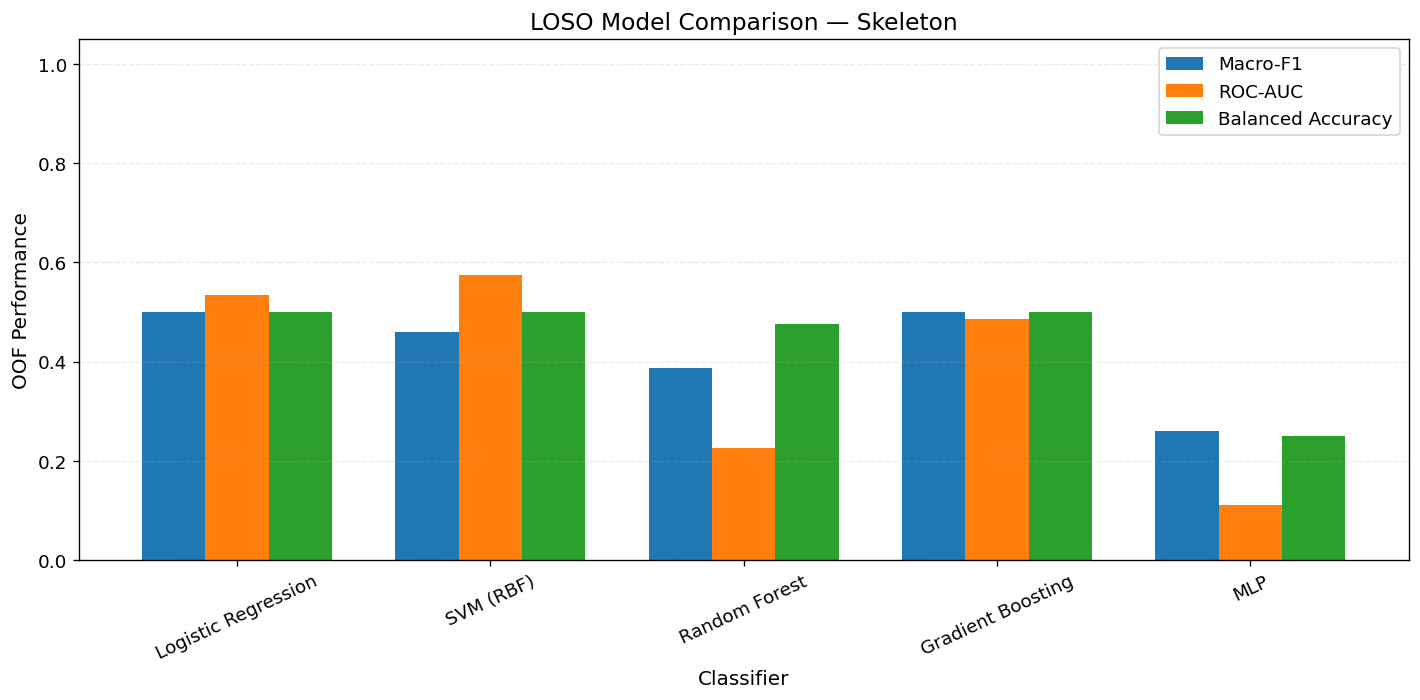

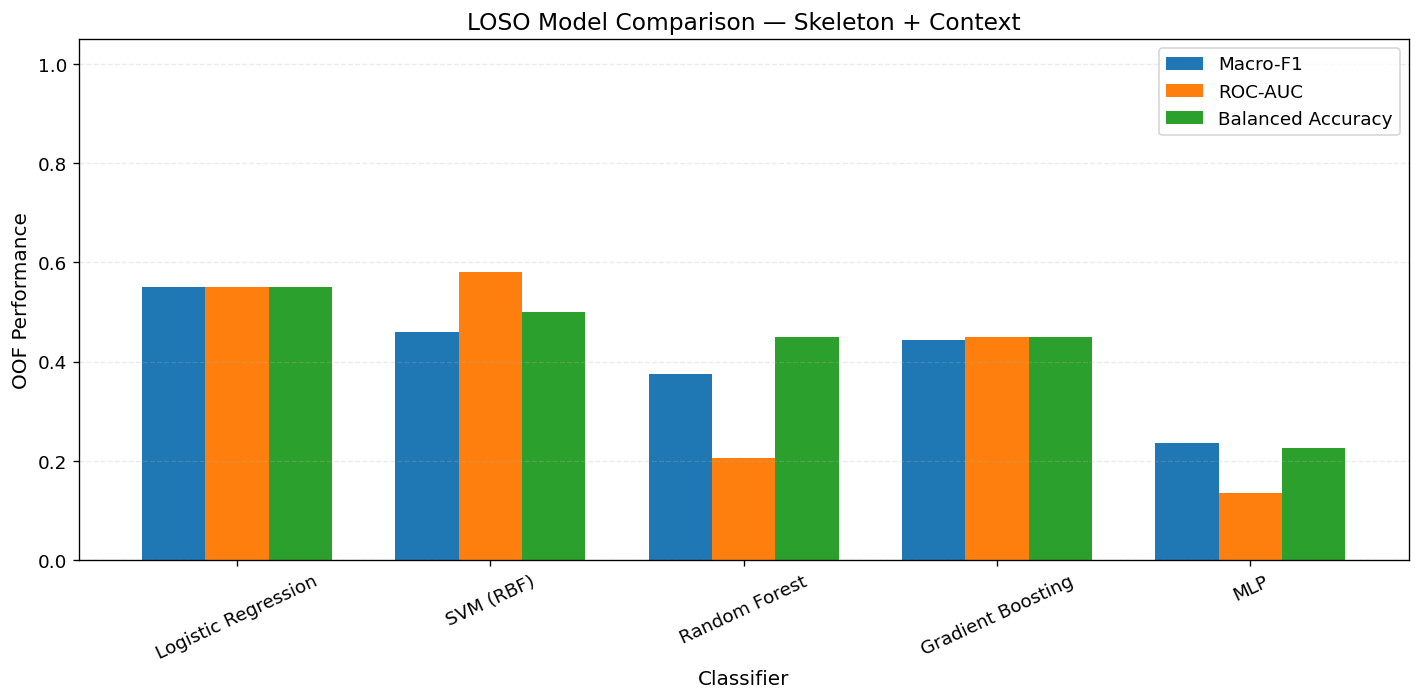

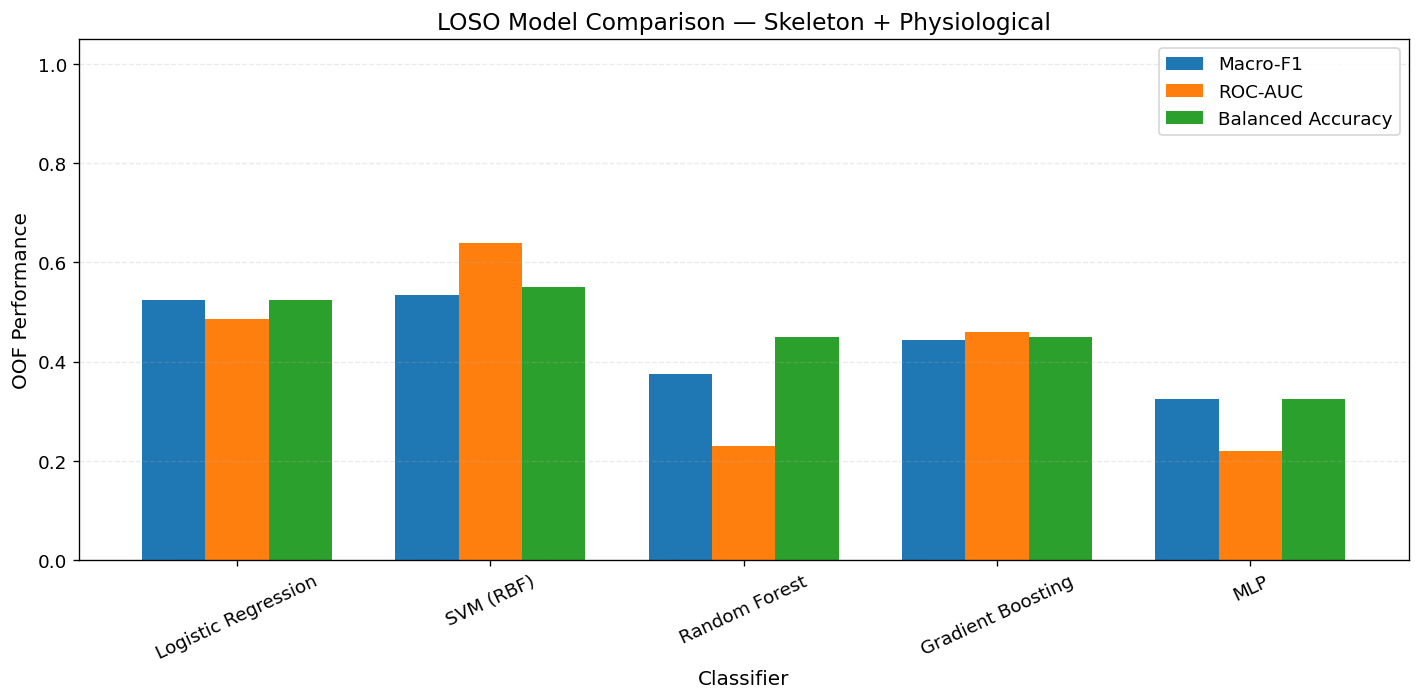

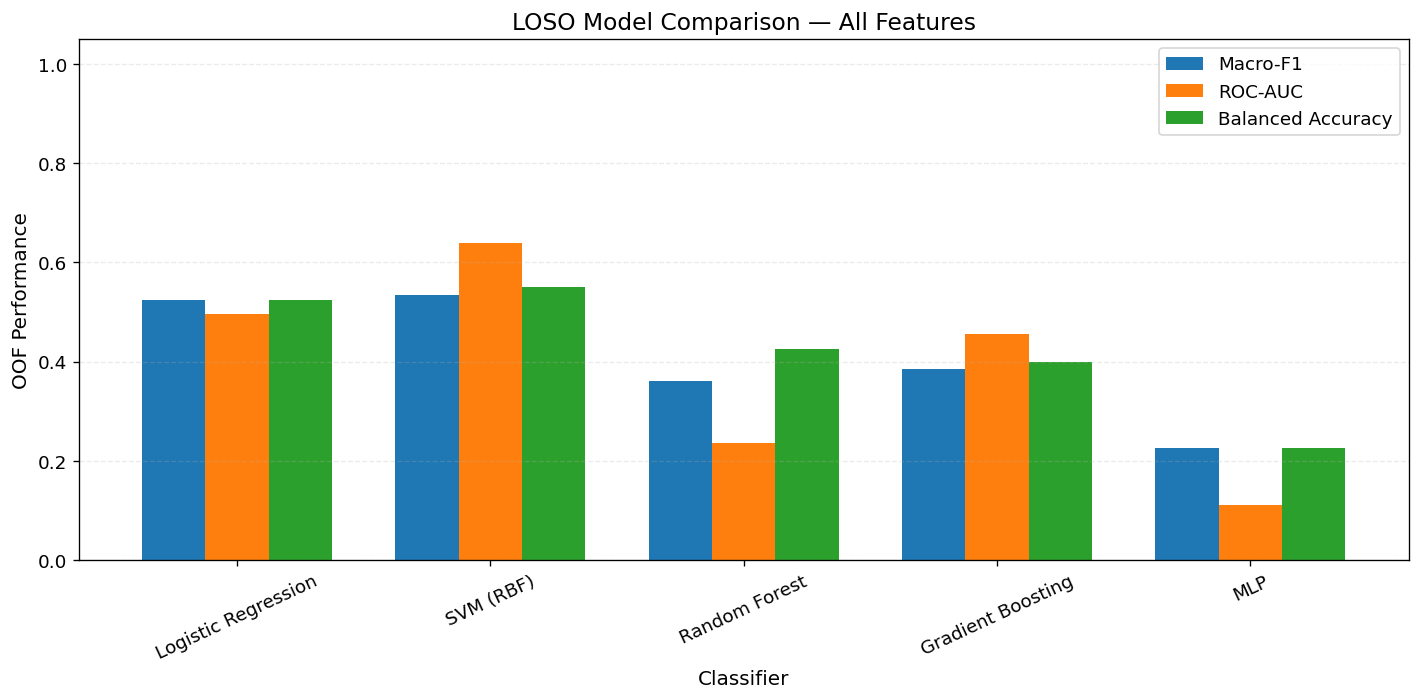

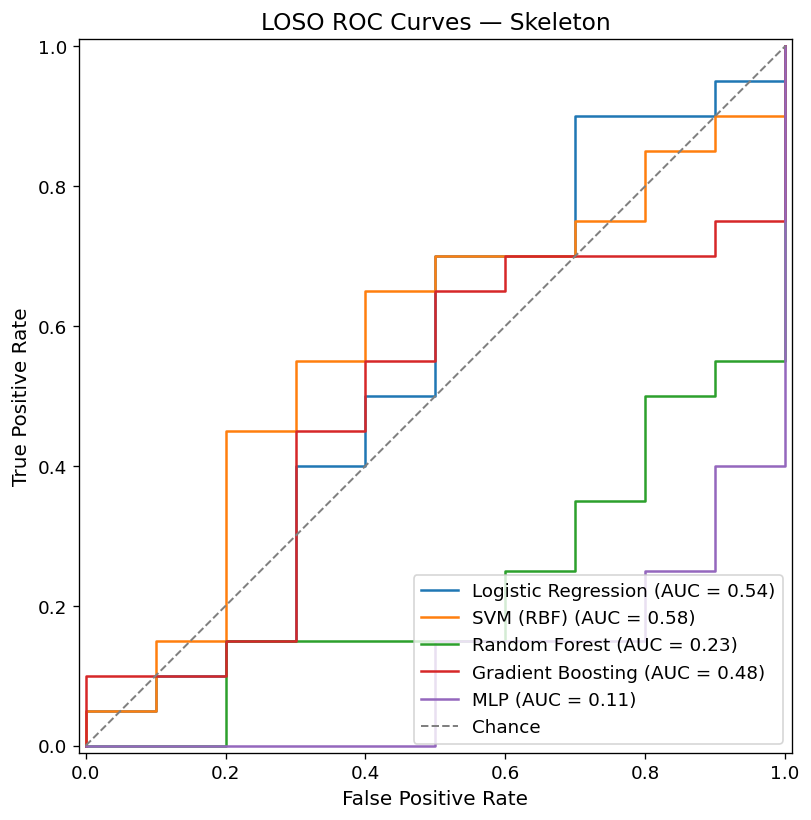

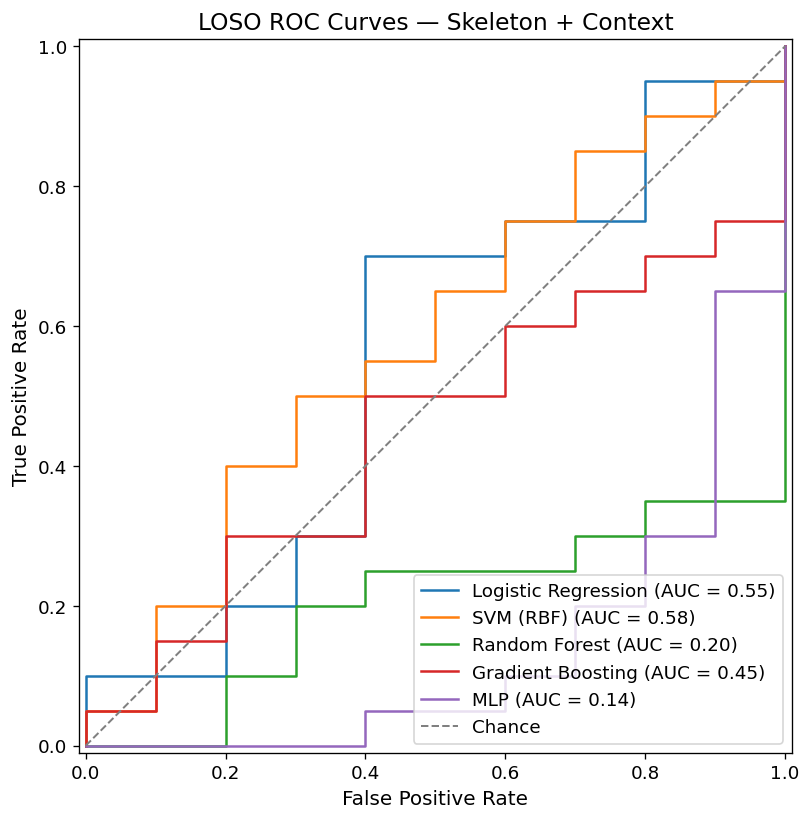

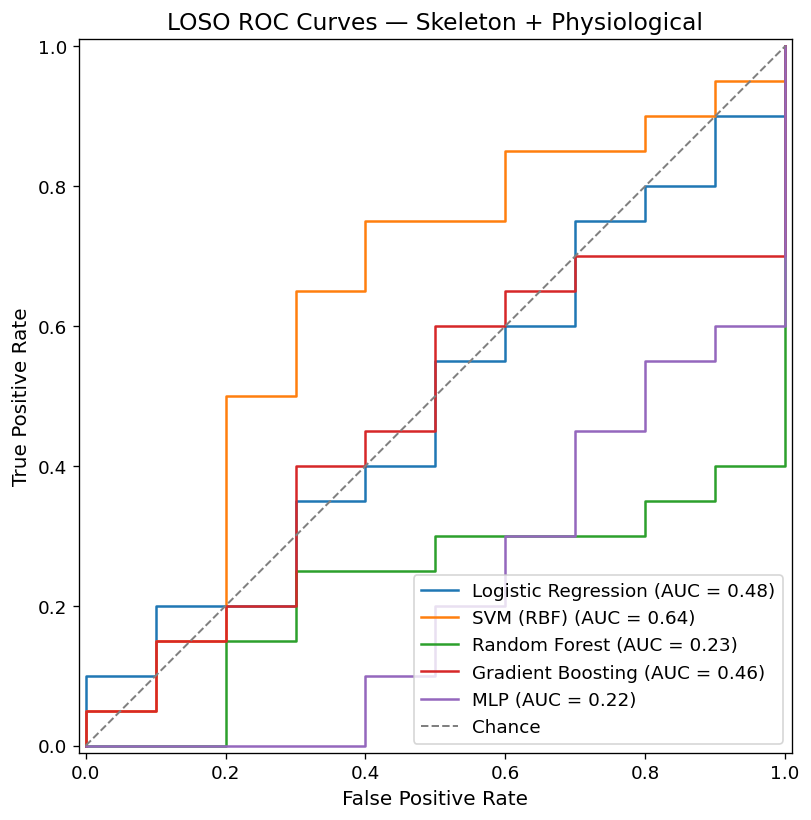

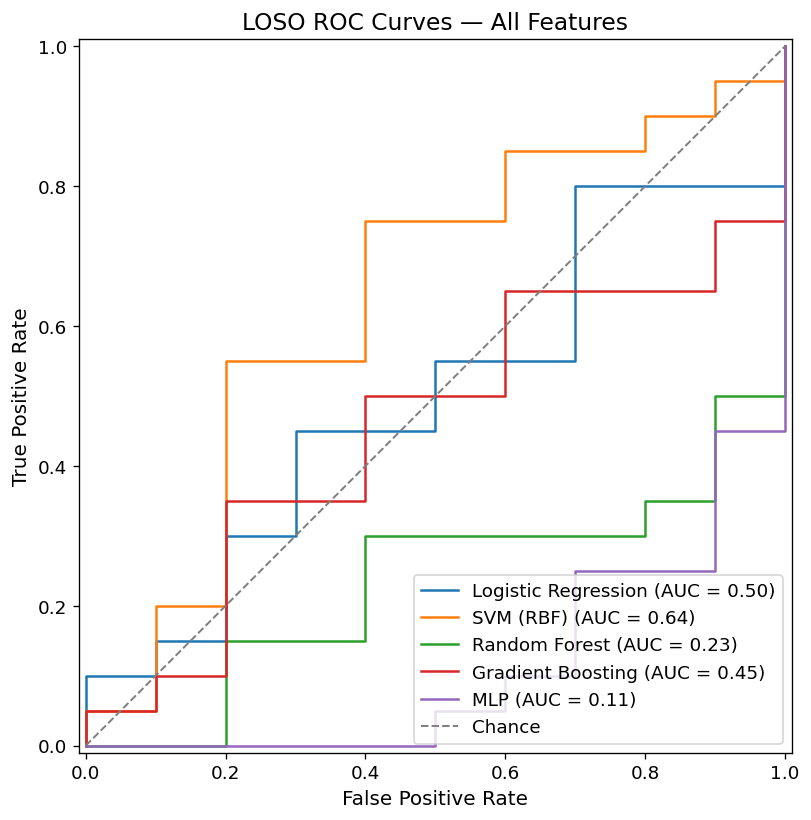

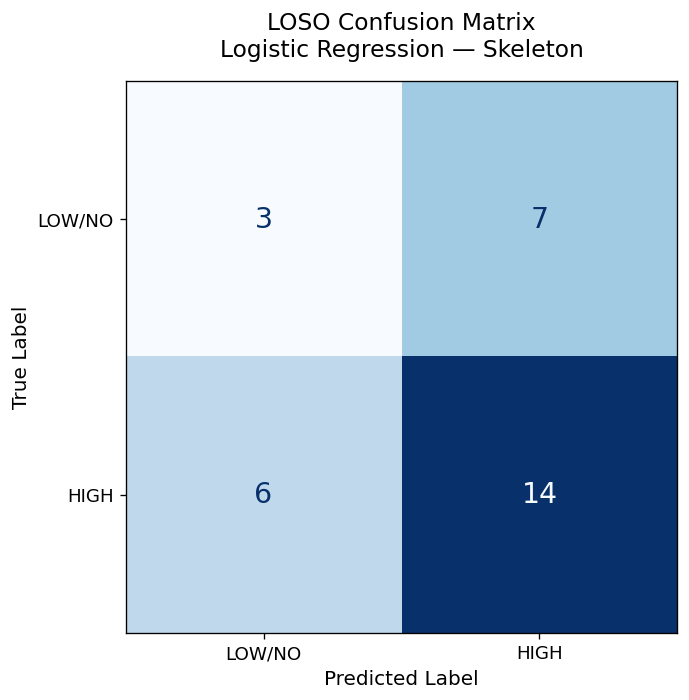

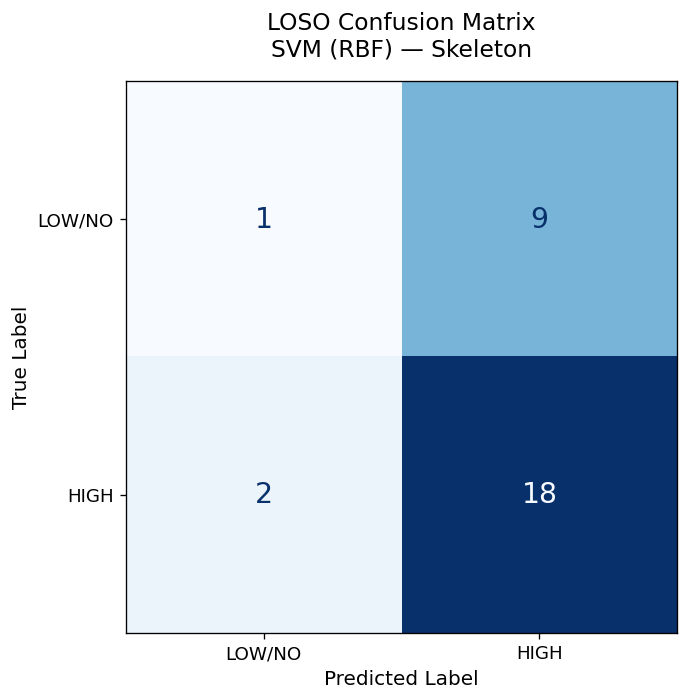

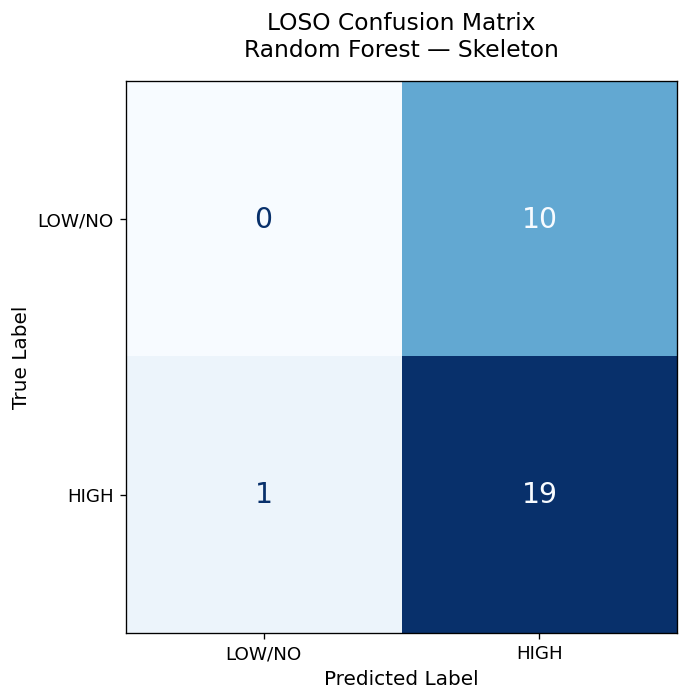

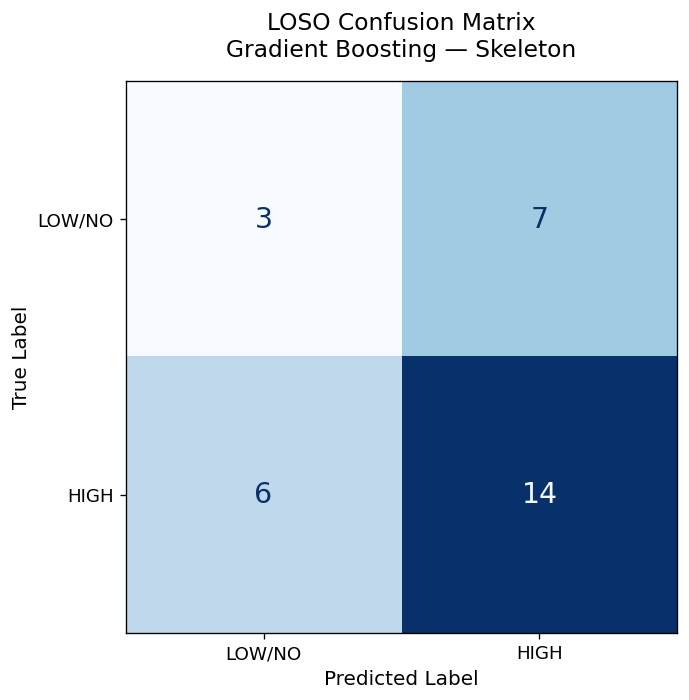

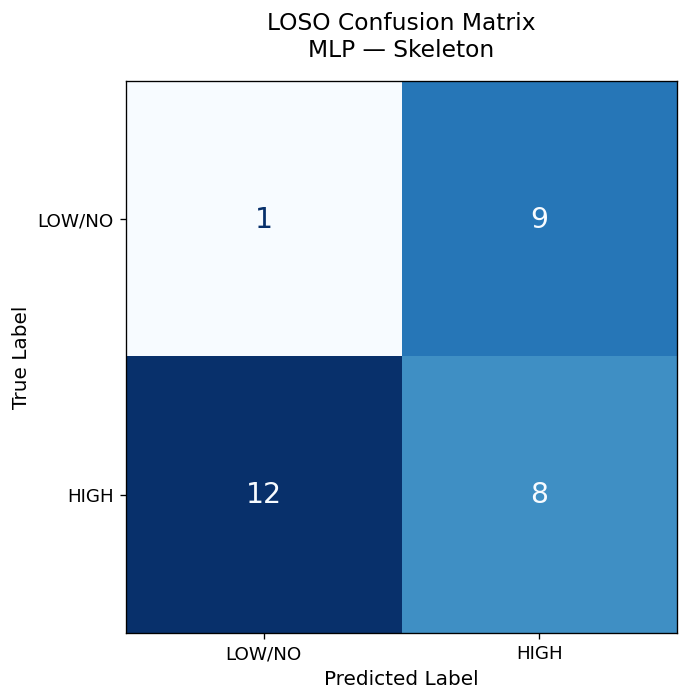

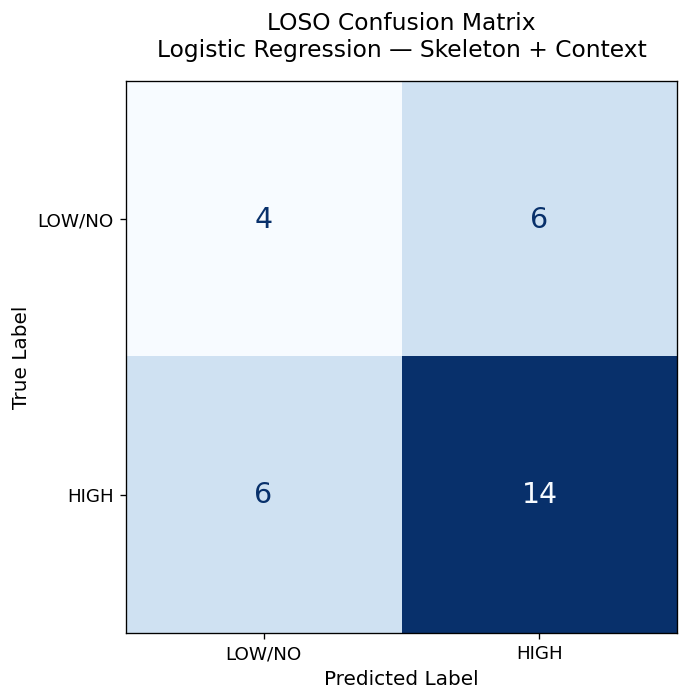

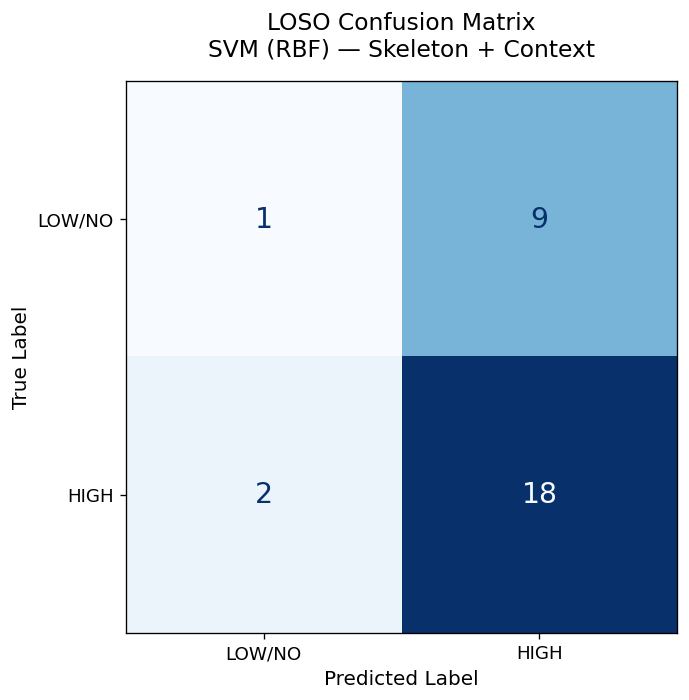

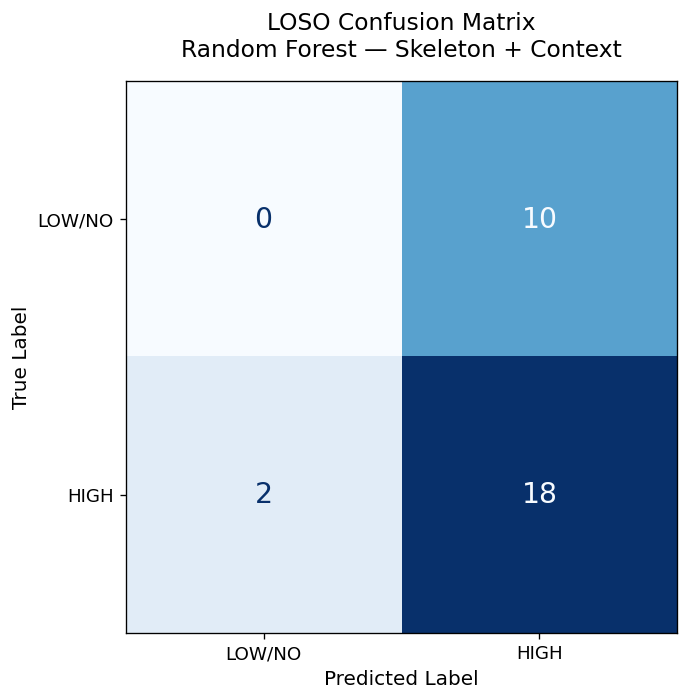

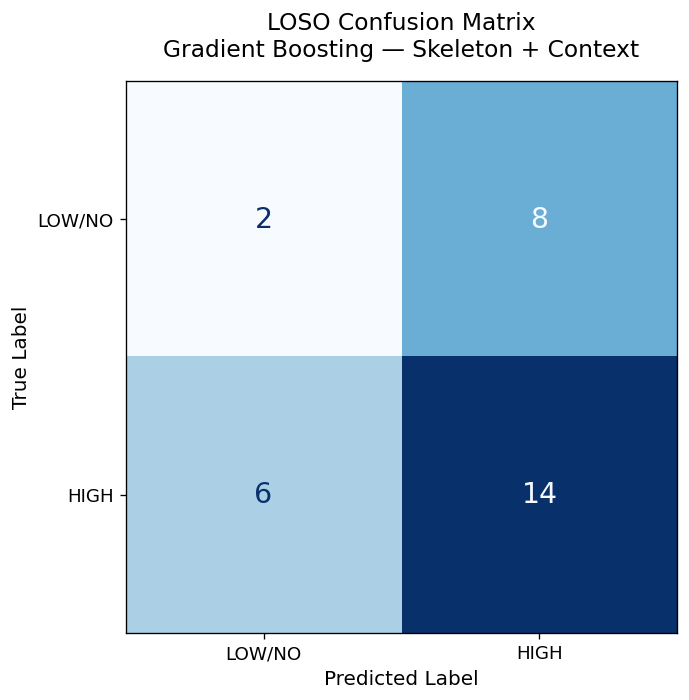

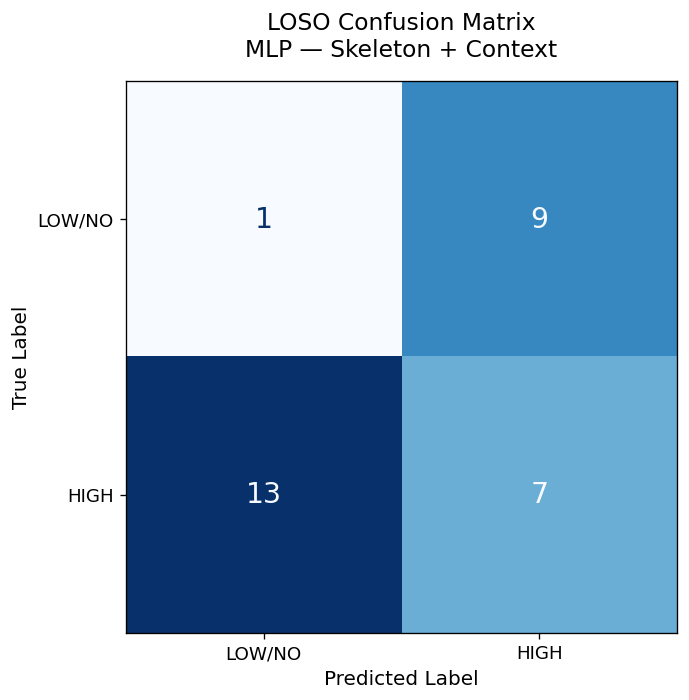

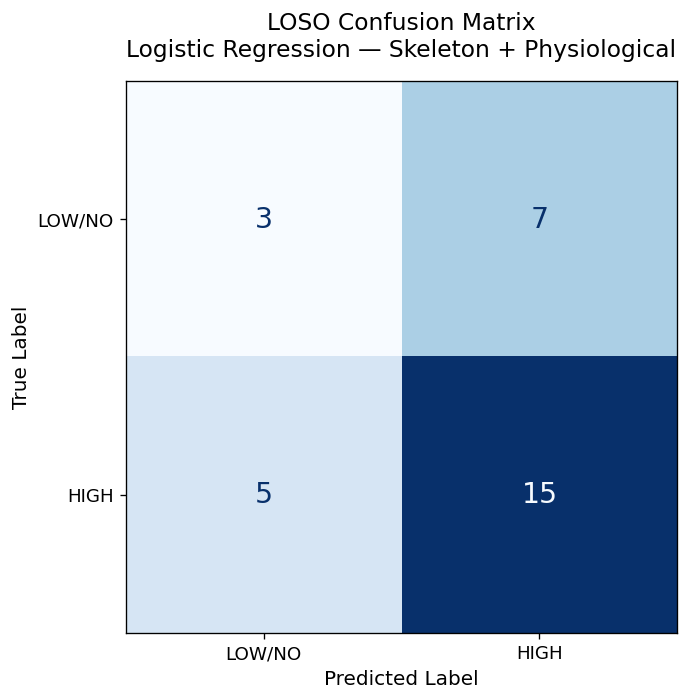

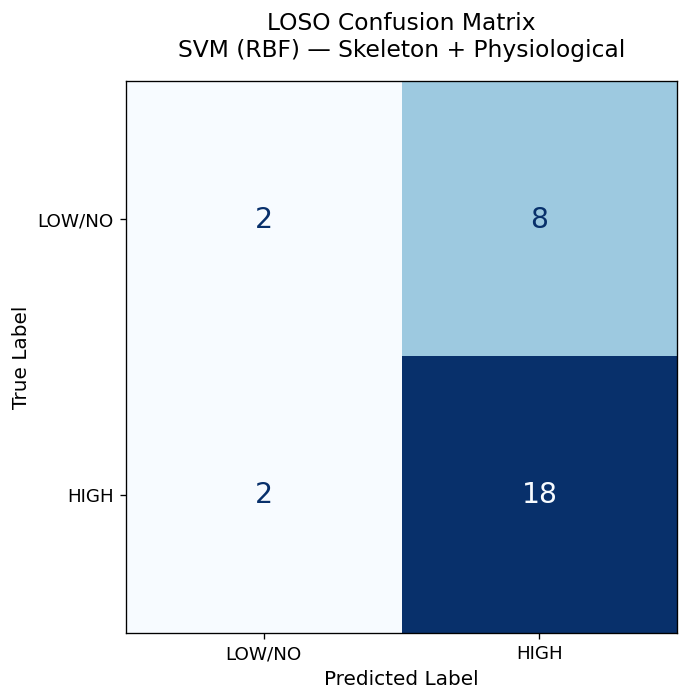

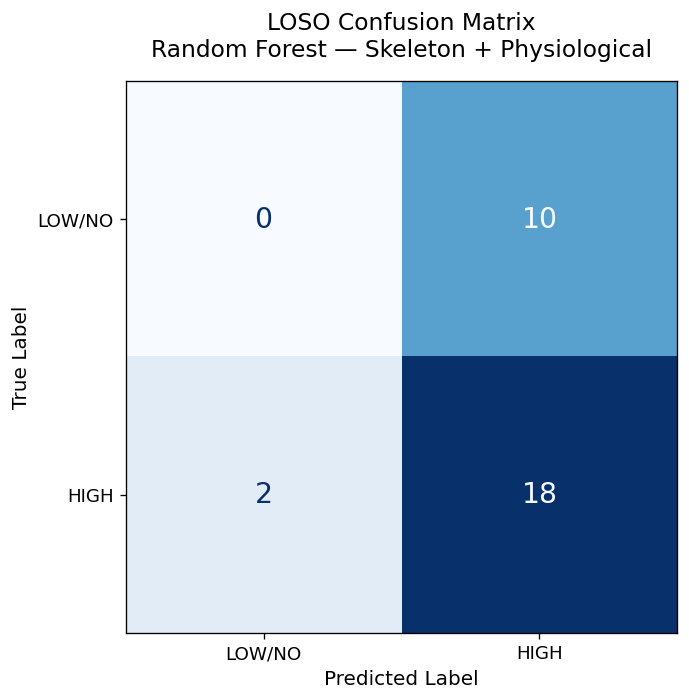

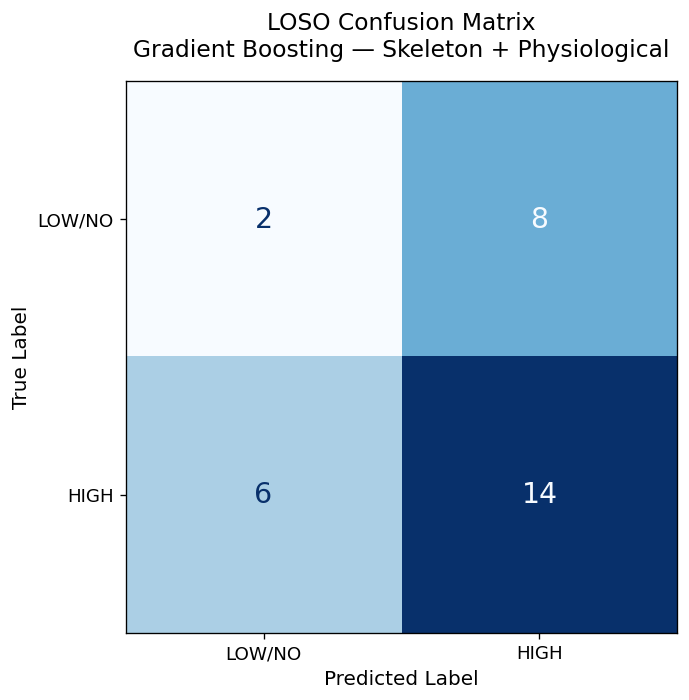

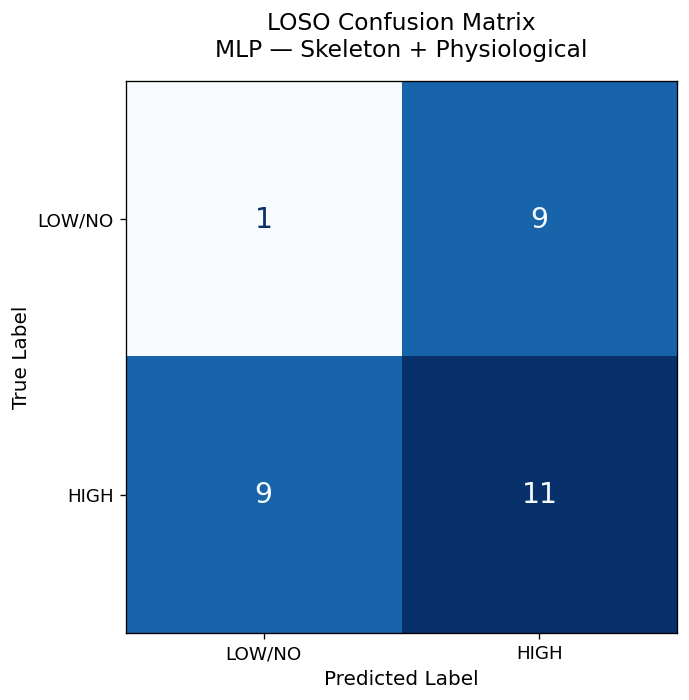

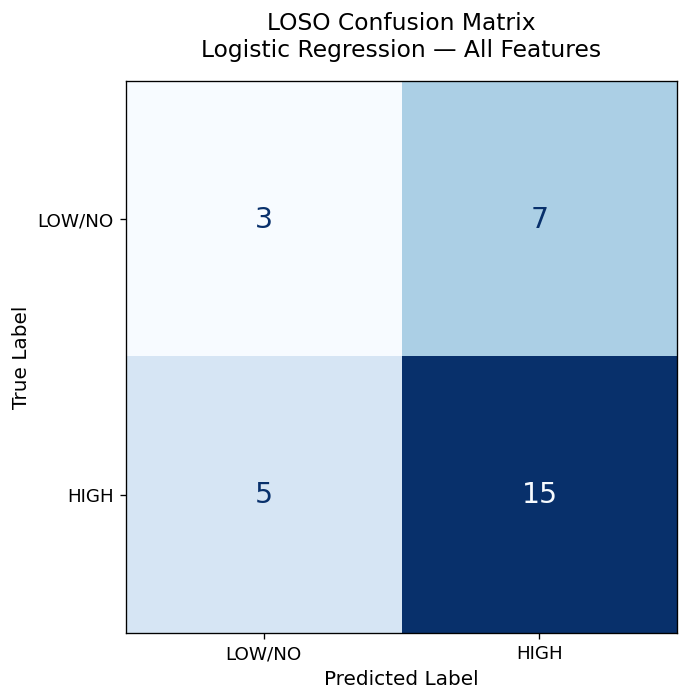

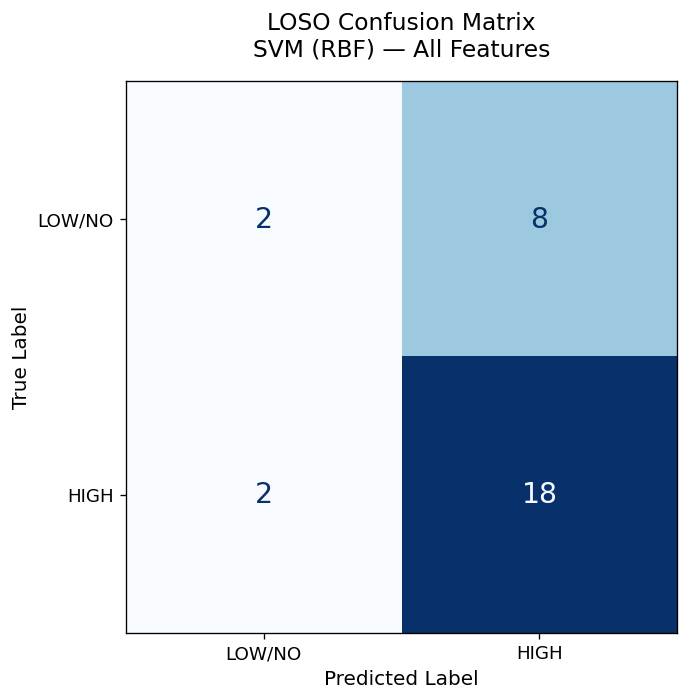

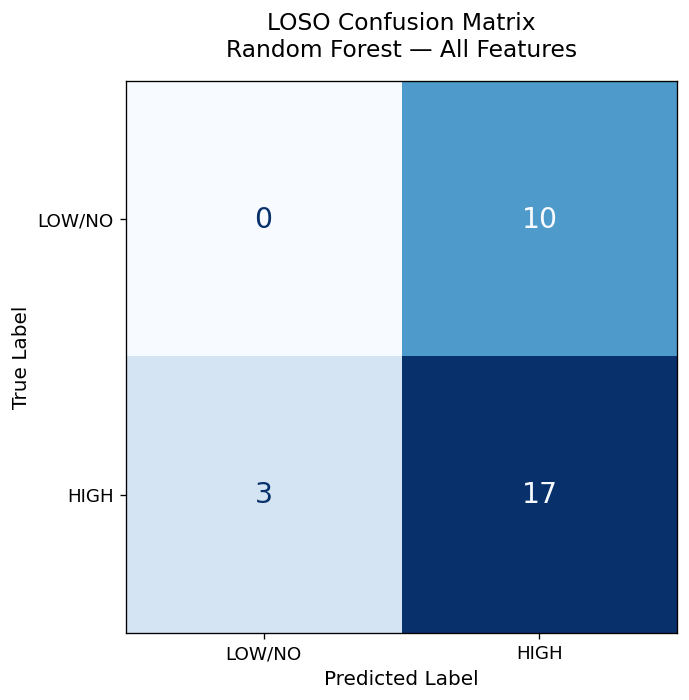

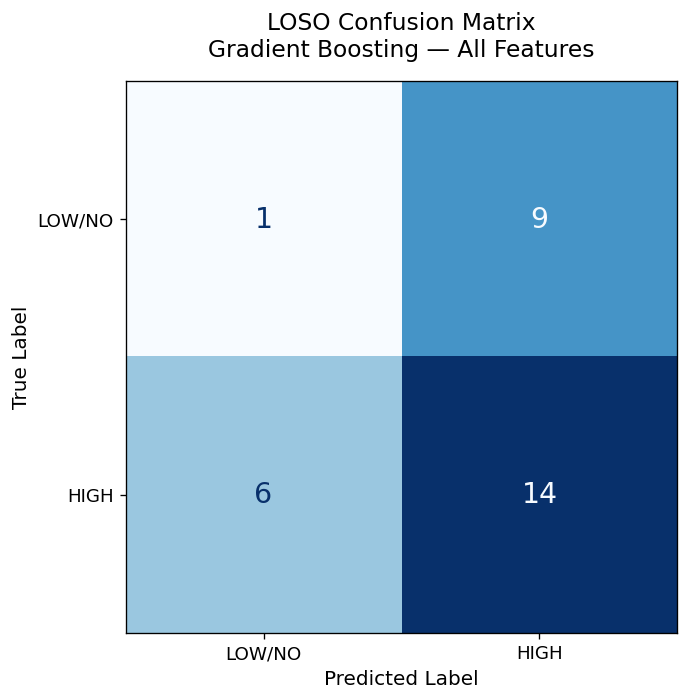

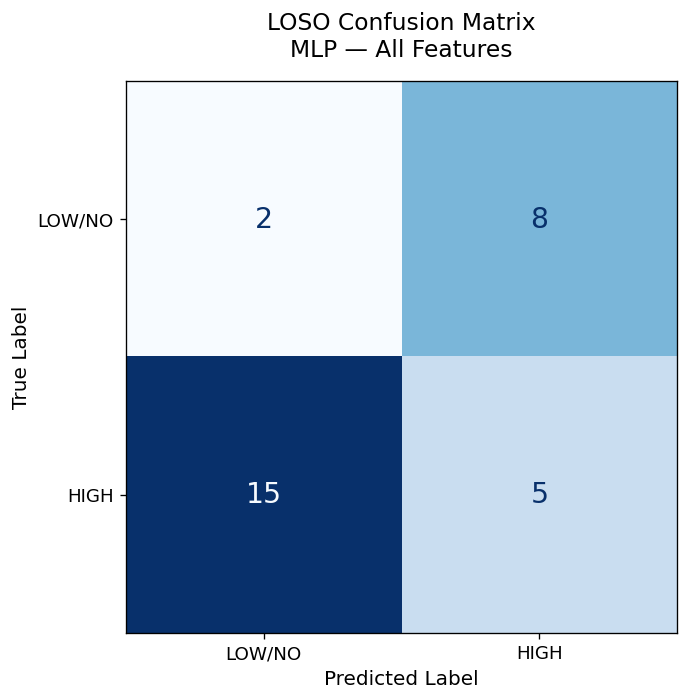

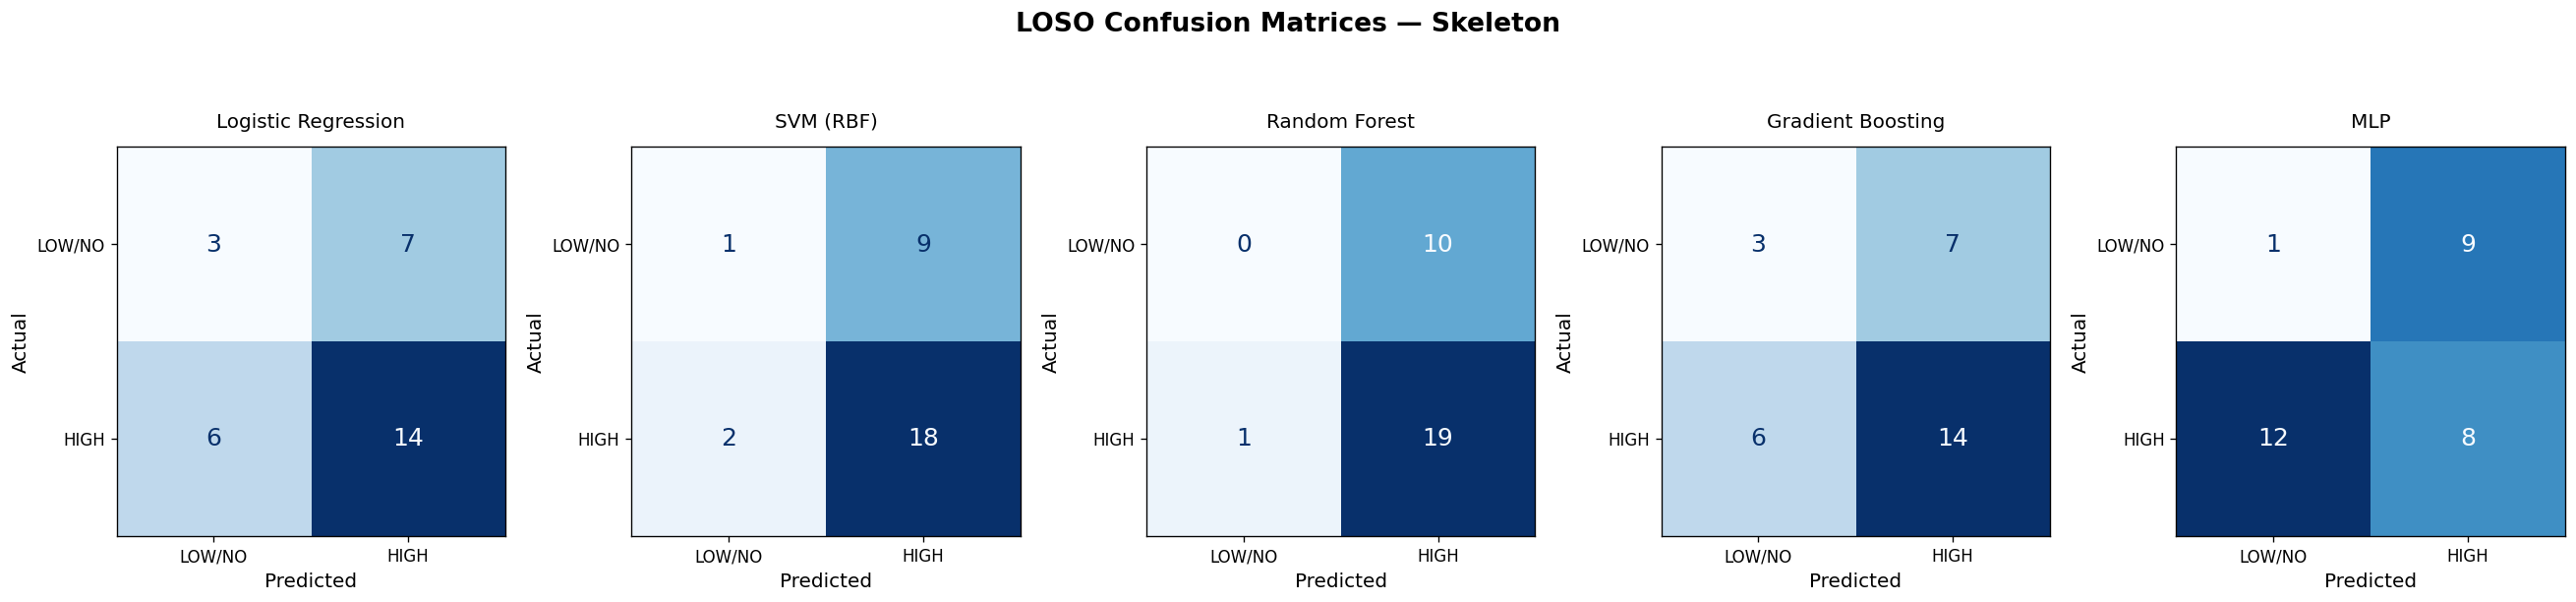

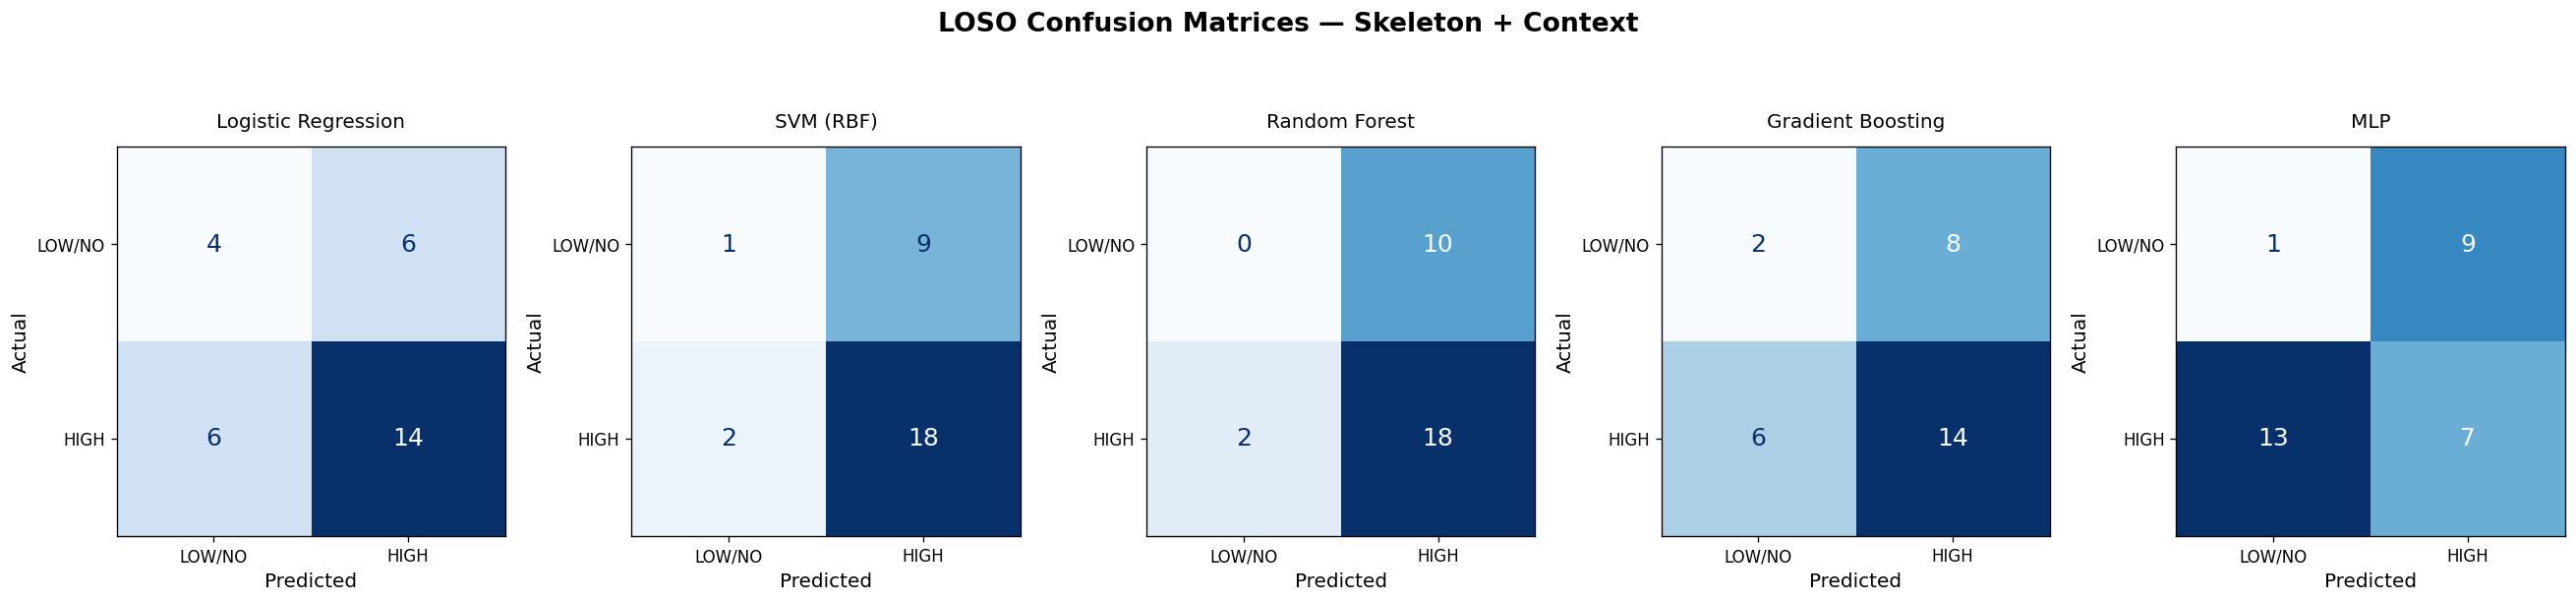

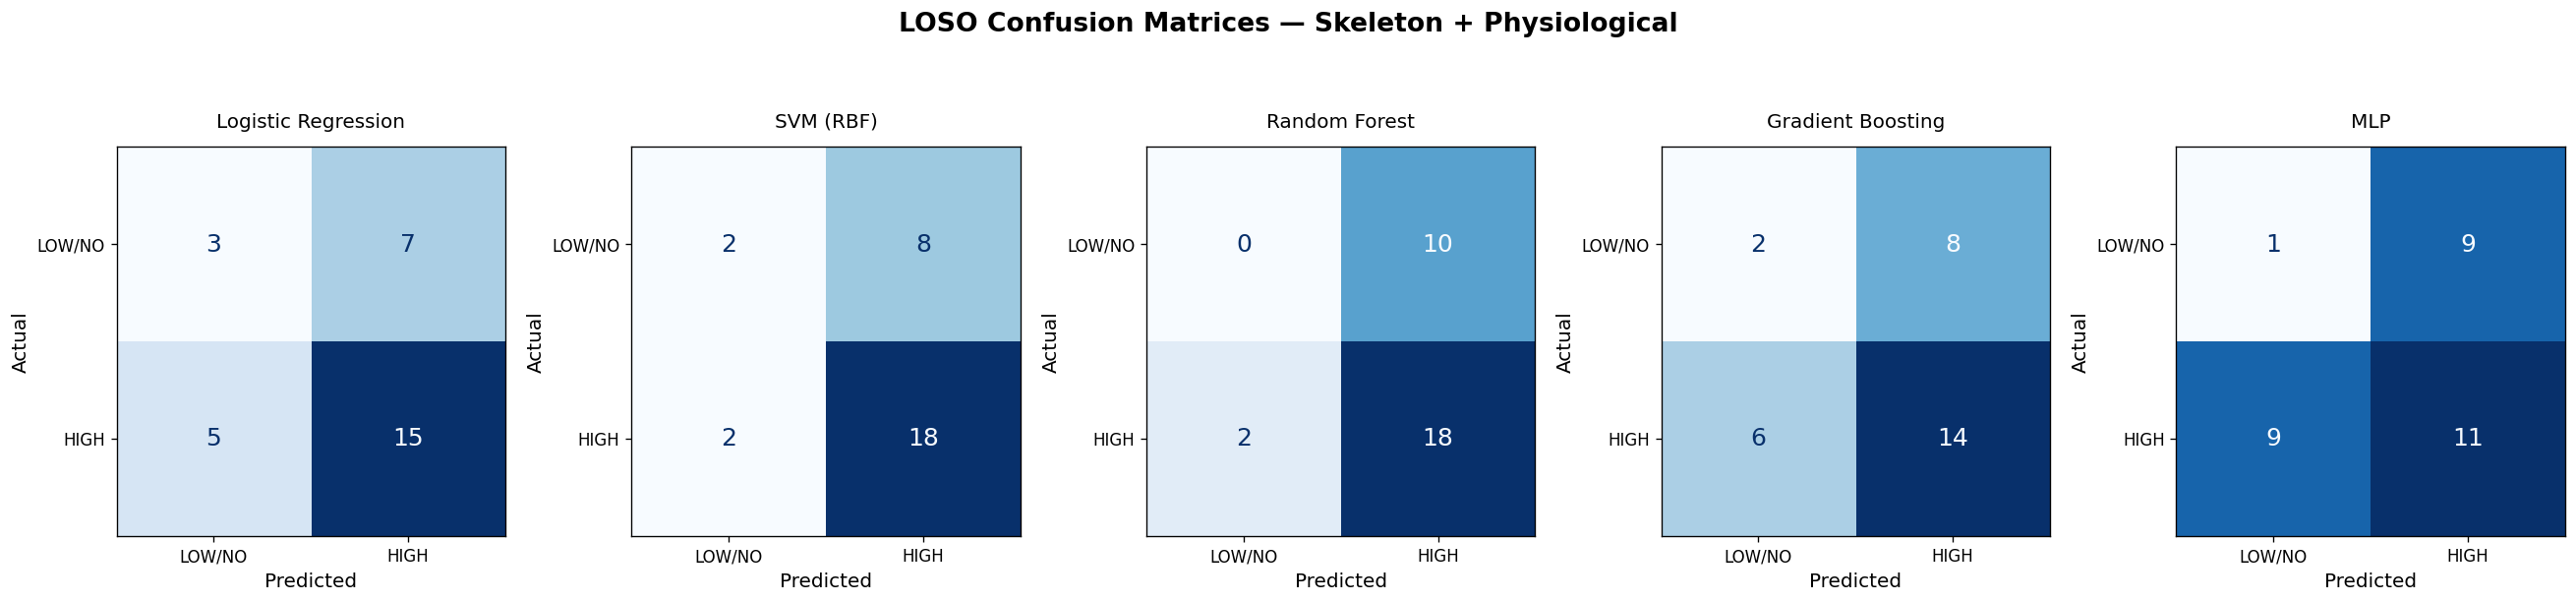

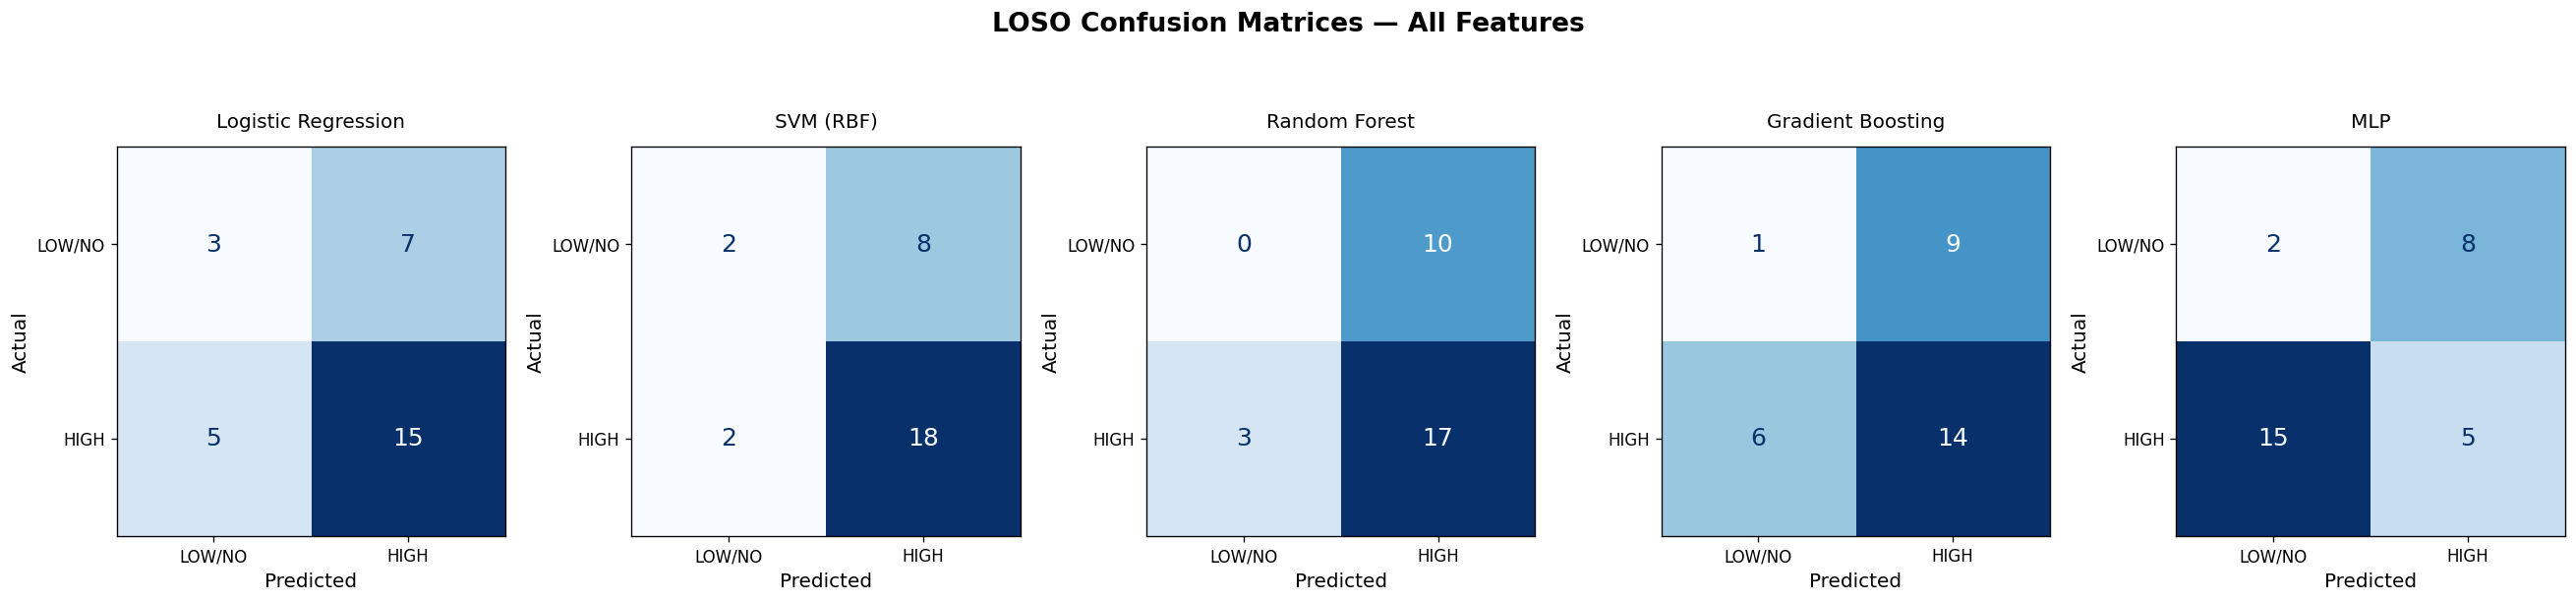


STEP 26 COMPLETED
Model comparison plots: 4
ROC plots: 4
Individual confusion matrices: 20
Combined confusion matrices: 4

Output directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal


,feature_set,model,tn,fp,fn,tp
0,Skeleton,Logistic Regression,3,7,6,14
1,Skeleton,SVM (RBF),1,9,2,18
2,Skeleton,Random Forest,0,10,1,19
3,Skeleton,Gradient Boosting,3,7,6,14
4,Skeleton,MLP,1,9,12,8
5,Skeleton + Context,Logistic Regression,4,6,6,14
6,Skeleton + Context,SVM (RBF),1,9,2,18
7,Skeleton + Context,Random Forest,0,10,2,18
8,Skeleton + Context,Gradient Boosting,2,8,6,14
9,Skeleton + Context,MLP,1,9,13,7


In [ ]:

# ============================================================
# STEP 26. LOSO PERFORMANCE VISUALIZATION
# 4 FEATURE ABLATIONS x 5 CLASSIFIERS
#
# Outputs:
# 1. Baseline comparison plots
# 2. ROC curves
# 3. Individual confusion matrices
# 4. Combined confusion matrices (5 models per feature set)
# 5. Confusion matrix CSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from pathlib import Path
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    confusion_matrix
)

# ============================================================
# 26.1 OUTPUT DIRECTORIES
# ============================================================

HEAD_TO_HEAD_DIR = Path(HEAD_TO_HEAD_DIR)

COMPARISON_DIR = HEAD_TO_HEAD_DIR / "Model_Comparison"
ROC_DIR = HEAD_TO_HEAD_DIR / "ROC_Curves"
CM_DIR = HEAD_TO_HEAD_DIR / "Confusion_Matrices"
CM_COMBINED_DIR = HEAD_TO_HEAD_DIR / "Combined_Confusion_Matrices"

for directory in [
    COMPARISON_DIR,
    ROC_DIR,
    CM_DIR,
    CM_COMBINED_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ============================================================
# 26.2 PUBLICATION-QUALITY FIGURE SETTINGS
# ============================================================

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.titlesize": 15,
    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})

def safe_filename(name):
    return (
        str(name)
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("/", "_")
    )

def save_plot(fig, filepath):
    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

# ============================================================
# 26.3 VALIDATE INPUT DATA
# ============================================================

required_summary = {
    "feature_set",
    "model",
    "macro_f1",
    "roc_auc",
    "balanced_accuracy",
    "tn", "fp", "fn", "tp"
}

required_oof = {
    "feature_set",
    "model",
    "y_true",
    "y_prob_high",
    "y_pred"
}

assert required_summary.issubset(
    baseline_summary_df.columns
), "Missing columns in baseline_summary_df"

assert required_oof.issubset(
    baseline_oof_df.columns
), "Missing columns in baseline_oof_df"

# ============================================================
# 26.4 MODEL COMPARISON
# ============================================================

for set_name in BENCHMARK_SETS:

    sub = baseline_summary_df[
        baseline_summary_df["feature_set"] == set_name
    ].copy()

    if sub.empty:
        print(f"Skipping {set_name}: no summary data")
        continue

    fig, ax = plt.subplots(figsize=(12, 6))

    sub.plot(
        kind="bar",
        x="model",
        y=[
            "macro_f1",
            "roc_auc",
            "balanced_accuracy"
        ],
        ax=ax,
        rot=25,
        width=0.75
    )

    ax.set_title(
        f"LOSO Model Comparison — {set_name}"
    )

    ax.set_xlabel("Classifier")
    ax.set_ylabel("OOF Performance")
    ax.set_ylim(0, 1.05)

    ax.legend([
        "Macro-F1",
        "ROC-AUC",
        "Balanced Accuracy"
    ])

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    fig.tight_layout()

    filename = (
        f"comparison_{safe_filename(set_name)}.png"
    )

    save_plot(
        fig,
        COMPARISON_DIR / filename
    )

    plt.show()
    plt.close(fig)

# ============================================================
# 26.5 ROC CURVES
# ============================================================

for set_name in BENCHMARK_SETS:

    fig, ax = plt.subplots(figsize=(8, 7))

    plotted = 0

    for model_name in BENCHMARK_MODELS:

        rows = baseline_oof_df[
            (baseline_oof_df["feature_set"] == set_name) &
            (baseline_oof_df["model"] == model_name)
        ].copy()

        if rows.empty:
            continue

        if rows["y_true"].nunique() < 2:
            print(
                f"ROC unavailable: {set_name} / {model_name}"
            )
            continue

        RocCurveDisplay.from_predictions(
            rows["y_true"].astype(int),
            rows["y_prob_high"].astype(float),
            name=model_name,
            ax=ax
        )

        plotted += 1

    if plotted > 0:

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="gray",
            linewidth=1.2,
            label="Chance"
        )

        ax.set_title(
            f"LOSO ROC Curves — {set_name}"
        )

        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")

        ax.legend(loc="lower right")

        fig.tight_layout()

        save_plot(
            fig,
            ROC_DIR /
            f"roc_{safe_filename(set_name)}.png"
        )

        plt.show()

    plt.close(fig)

# ============================================================
# 26.6 INDIVIDUAL CONFUSION MATRICES
# ============================================================

cm_records = []

for set_name in BENCHMARK_SETS:

    for model_name in BENCHMARK_MODELS:

        rows = baseline_oof_df[
            (baseline_oof_df["feature_set"] == set_name) &
            (baseline_oof_df["model"] == model_name)
        ].copy()

        if rows.empty:
            continue

        y_true = rows["y_true"].astype(int).to_numpy()
        y_pred = rows["y_pred"].astype(int).to_numpy()

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        cm_records.append({
            "feature_set": set_name,
            "model": model_name,
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp)
        })

        fig, ax = plt.subplots(figsize=(7, 6))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["LOW/NO", "HIGH"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            f"LOSO Confusion Matrix\n"
            f"{model_name} — {set_name}",
            pad=15
        )

        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("True Label")

        for txt in disp.text_.ravel():
            txt.set_fontsize(17)

        fig.tight_layout()

        filename = (
            f"CM_{safe_filename(set_name)}_"
            f"{safe_filename(model_name)}.png"
        )

        save_plot(
            fig,
            CM_DIR / filename
        )

        plt.show()
        plt.close(fig)

# ============================================================
# 26.7 COMBINED CONFUSION MATRICES
# FIVE CLASSIFIERS PER FEATURE SET
# ============================================================

for set_name in BENCHMARK_SETS:

    fig, axes = plt.subplots(
        1,
        len(BENCHMARK_MODELS),
        figsize=(22, 4.8)
    )

    fig.suptitle(
        f"LOSO Confusion Matrices — {set_name}",
        fontsize=16,
        fontweight="bold",
        y=1.05
    )

    for ax, model_name in zip(
        axes,
        BENCHMARK_MODELS
    ):

        rows = baseline_oof_df[
            (baseline_oof_df["feature_set"] == set_name) &
            (baseline_oof_df["model"] == model_name)
        ]

        if rows.empty:
            ax.axis("off")
            continue

        cm = confusion_matrix(
            rows["y_true"].astype(int),
            rows["y_pred"].astype(int),
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["LOW/NO", "HIGH"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            model_name,
            fontsize=12,
            pad=12
        )

        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        ax.tick_params(
            axis="both",
            labelsize=10
        )

        for txt in disp.text_.ravel():
            txt.set_fontsize(15)

    fig.tight_layout()

    filename = (
        f"combined_CM_{safe_filename(set_name)}.png"
    )

    save_plot(
        fig,
        CM_COMBINED_DIR / filename
    )

    plt.show()
    plt.close(fig)

# ============================================================
# 26.8 EXPORT CONFUSION MATRIX TABLE
# ============================================================

confusion_df = pd.DataFrame(cm_records)

confusion_df.to_csv(
    HEAD_TO_HEAD_DIR /
    "baseline_confusion_matrices.csv",
    index=False
)

# ============================================================
# 26.9 VERIFY OUTPUTS
# ============================================================

expected_cm = (
    len(BENCHMARK_SETS) *
    len(BENCHMARK_MODELS)
)

assert len(confusion_df) == expected_cm, (
    "Some confusion matrices are missing."
)

print("\n" + "=" * 70)
print("STEP 26 COMPLETED")
print("=" * 70)

print("Model comparison plots:", len(BENCHMARK_SETS))
print("ROC plots:", len(BENCHMARK_SETS))
print("Individual confusion matrices:", len(confusion_df))
print("Combined confusion matrices:", len(BENCHMARK_SETS))

print("\nOutput directory:")
print(HEAD_TO_HEAD_DIR)

display(confusion_df)


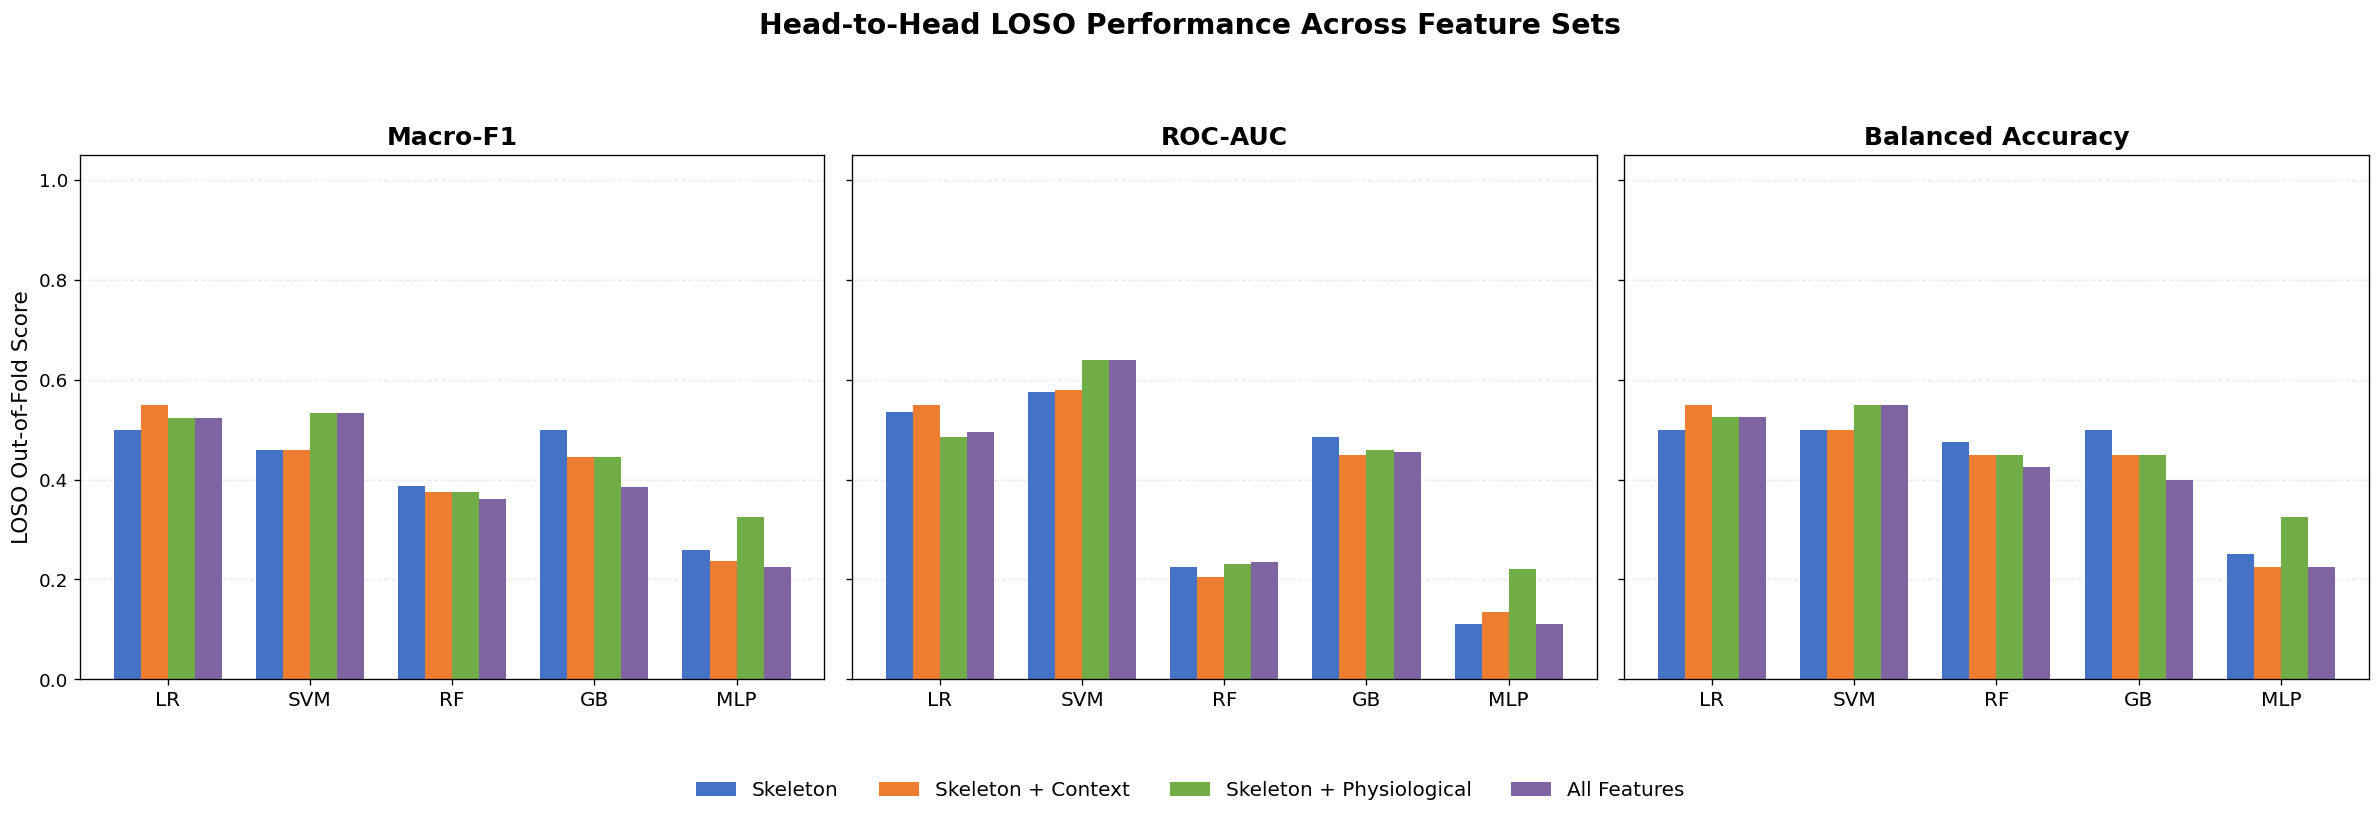

Saved: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal/Combined_LOSO_All_Ablations.png


In [ ]:

# ============================================================
# STEP 26.4 — COMBINED ABLATION COMPARISON
# ONE FIGURE: 3 METRICS x 4 FEATURE SETS x 5 MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

HEAD_TO_HEAD_DIR = Path(HEAD_TO_HEAD_DIR)
HEAD_TO_HEAD_DIR.mkdir(parents=True, exist_ok=True)

feature_order = [
    "Skeleton",
    "Skeleton + Context",
    "Skeleton + Physiological",
    "All Features"
]

model_order = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting",
    "MLP"
]

metrics = [
    ("macro_f1", "Macro-F1"),
    ("roc_auc", "ROC-AUC"),
    ("balanced_accuracy", "Balanced Accuracy")
]

colors = [
    "#4472C4",
    "#ED7D31",
    "#70AD47",
    "#8064A2"
]

# ============================================================
# DATA VALIDATION
# ============================================================

expected_pairs = pd.MultiIndex.from_product(
    [feature_order, model_order],
    names=["feature_set", "model"]
)

plot_df = baseline_summary_df.copy()
plot_df["feature_set"] = plot_df["feature_set"].astype(str)
plot_df["model"] = plot_df["model"].astype(str)

if plot_df.duplicated(["feature_set", "model"]).any():
    raise ValueError(
        "Duplicate feature_set/model combinations."
    )

actual_pairs = pd.MultiIndex.from_frame(
    plot_df[["feature_set", "model"]]
)

missing = expected_pairs.difference(actual_pairs)

if len(missing):
    raise ValueError(
        f"Missing benchmark results: {missing.tolist()}"
    )

# ============================================================
# CREATE COMBINED FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6),
    sharey=True
)

x = np.arange(len(model_order))
width = 0.19

for ax, (metric_col, metric_title) in zip(
    axes, metrics
):

    pivot = plot_df.pivot(
        index="model",
        columns="feature_set",
        values=metric_col
    ).reindex(
        index=model_order,
        columns=feature_order
    )

    for j, feature_set in enumerate(feature_order):

        offset = (
            j - (len(feature_order) - 1) / 2
        ) * width

        ax.bar(
            x + offset,
            pivot[feature_set].to_numpy(),
            width=width,
            label=feature_set,
            color=colors[j]
        )

    ax.set_title(
        metric_title,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            "LR",
            "SVM",
            "RF",
            "GB",
            "MLP"
        ],
        fontsize=12
    )

    ax.set_ylim(0, 1.05)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

axes[0].set_ylabel(
    "LOSO Out-of-Fold Score",
    fontsize=13
)

fig.suptitle(
    "Head-to-Head LOSO Performance Across Feature Sets",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=4,
    frameon=False,
    fontsize=12
)

fig.tight_layout(
    rect=[0, 0.04, 1, 0.98]
)

output_path = (
    HEAD_TO_HEAD_DIR /
    "Combined_LOSO_All_Ablations.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Saved:", output_path)


Data validation: PASSED


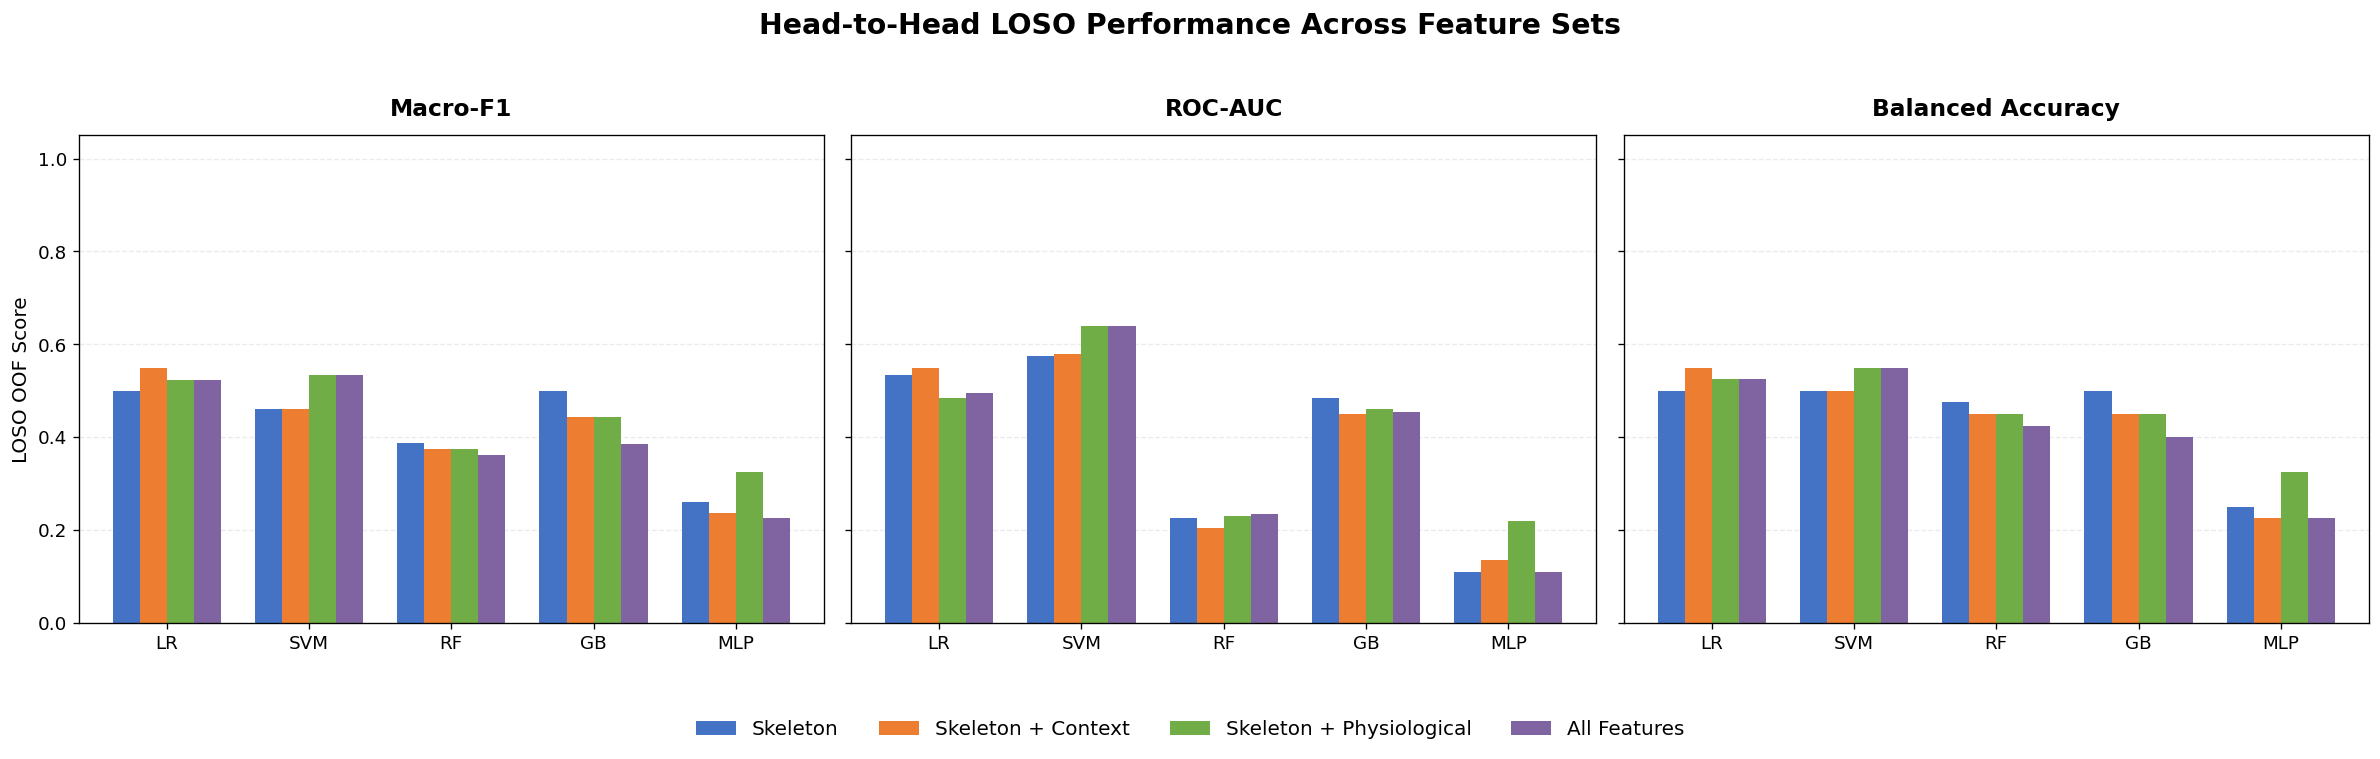

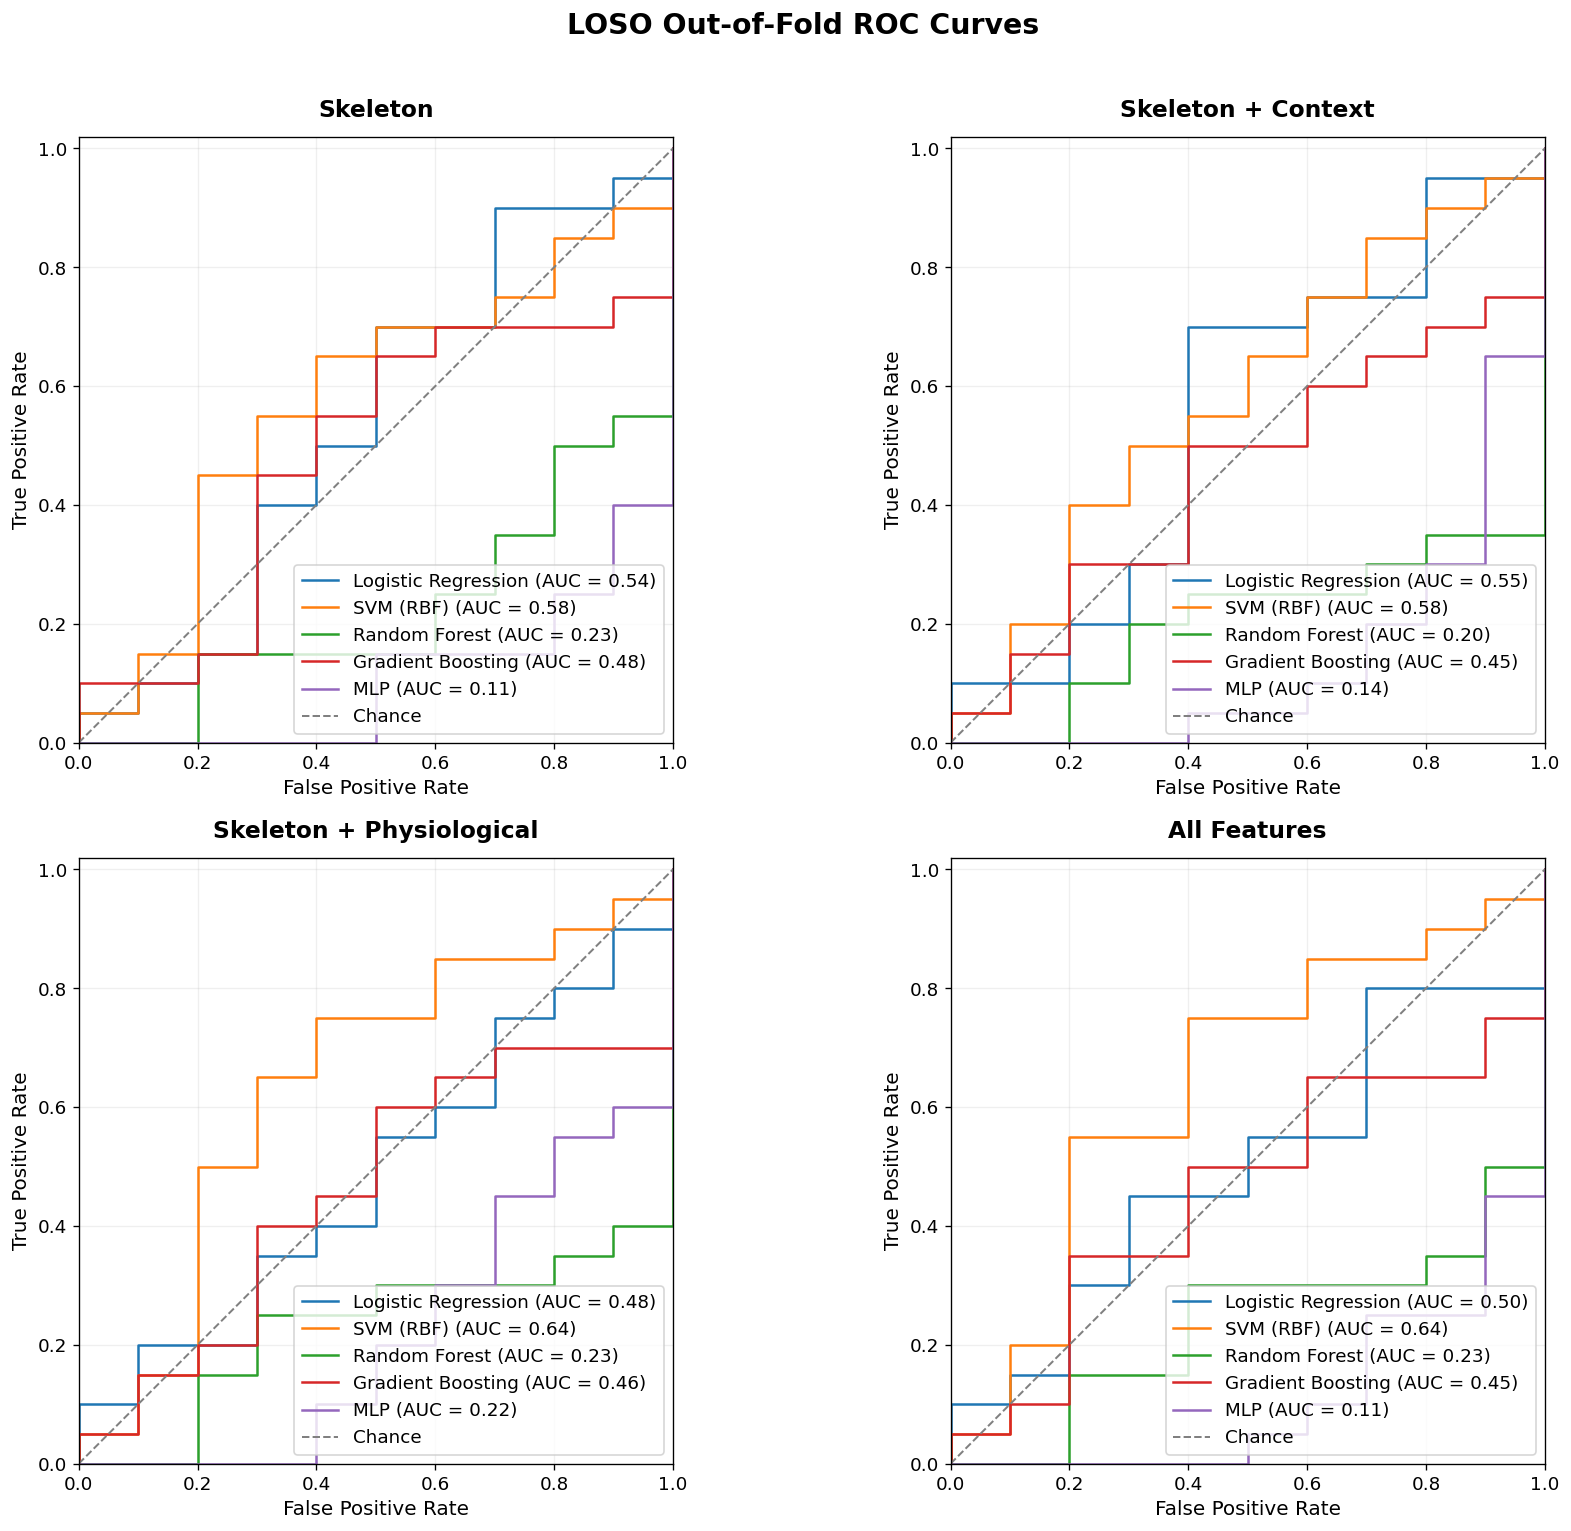

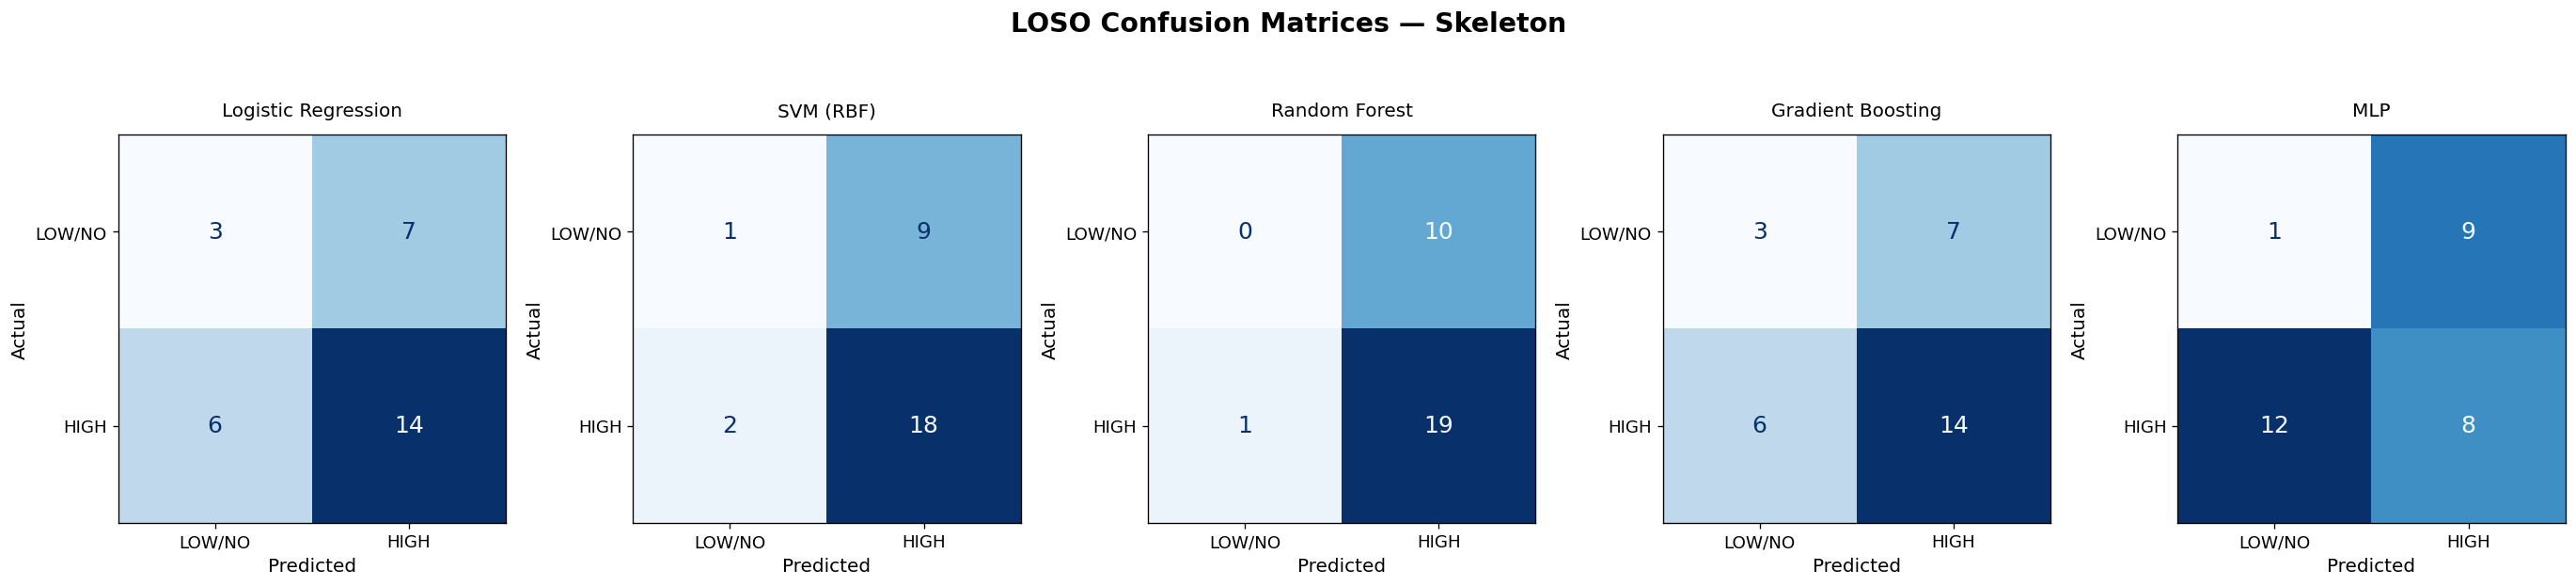

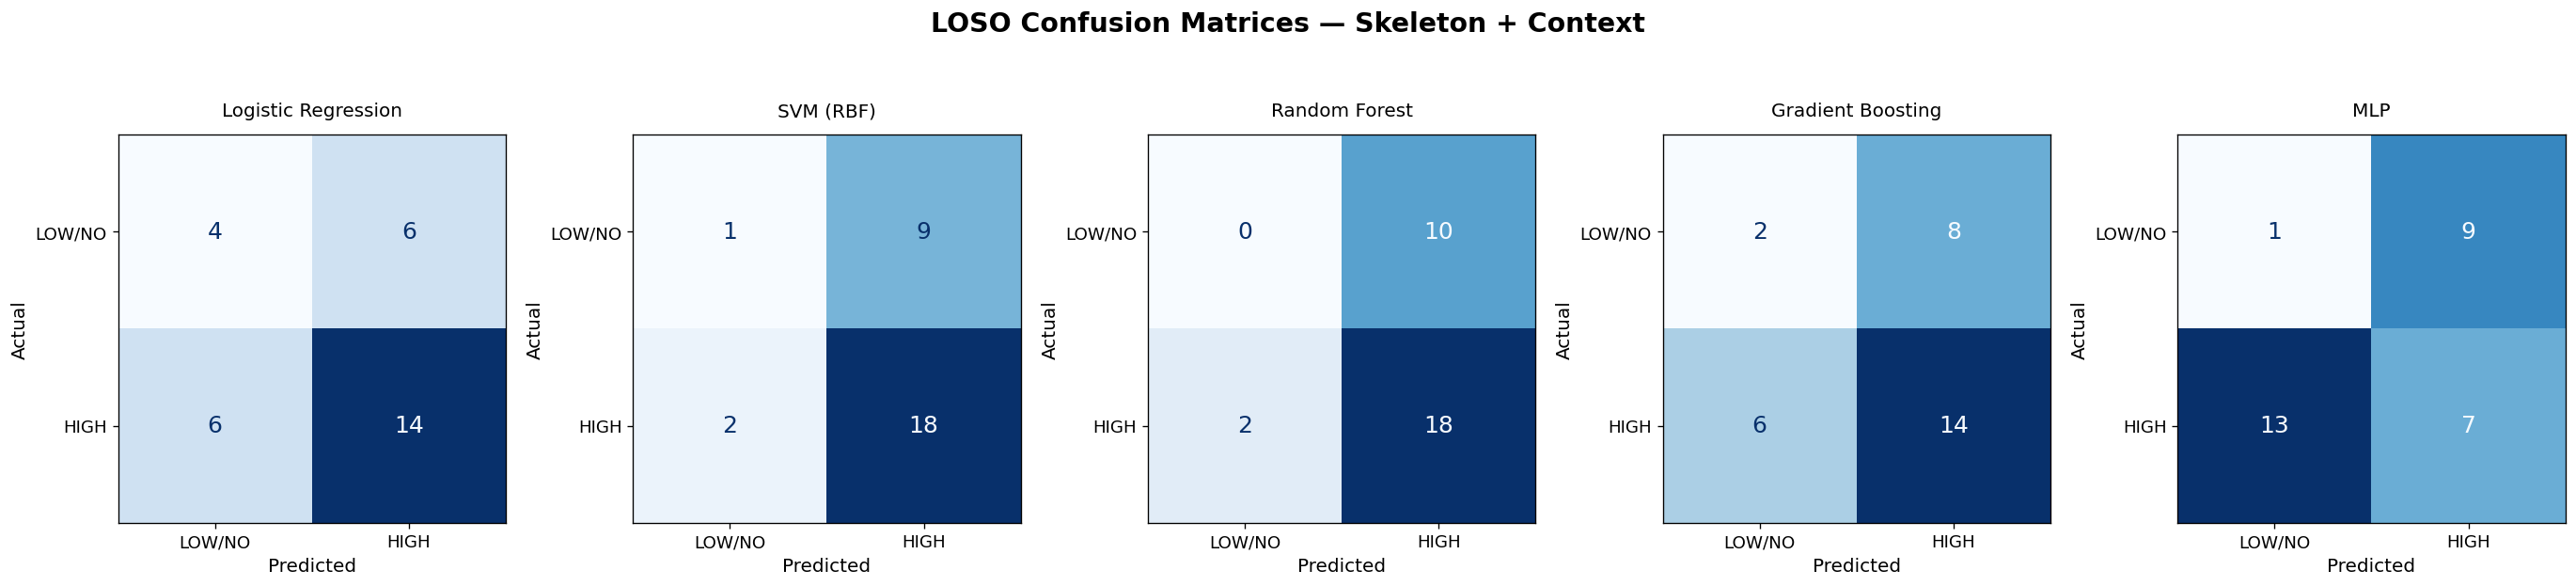

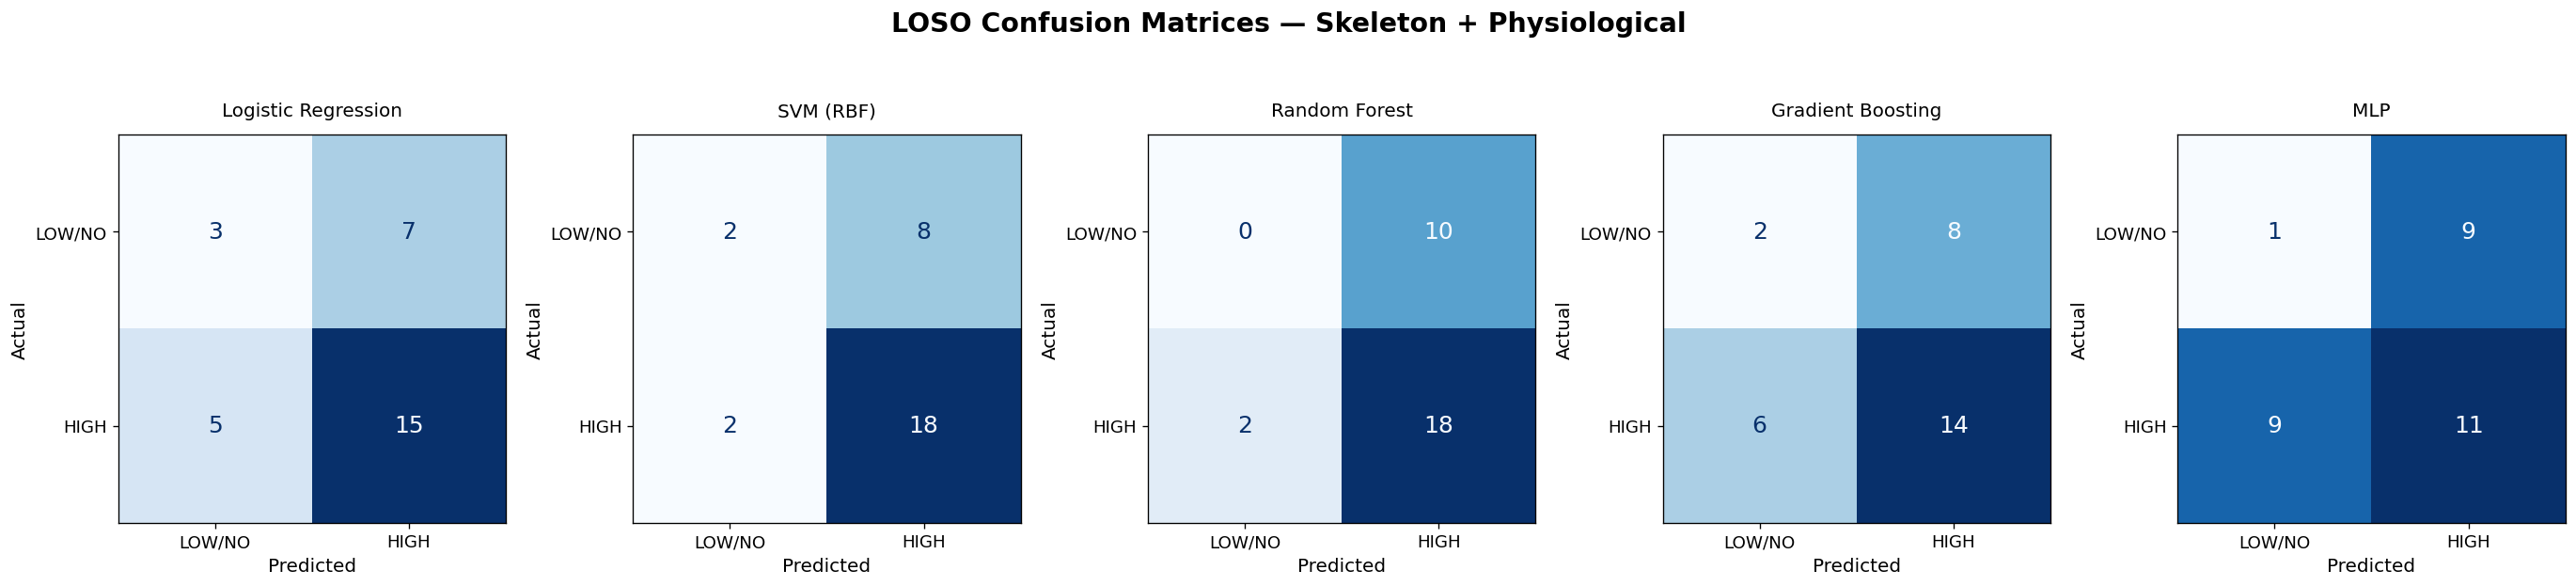

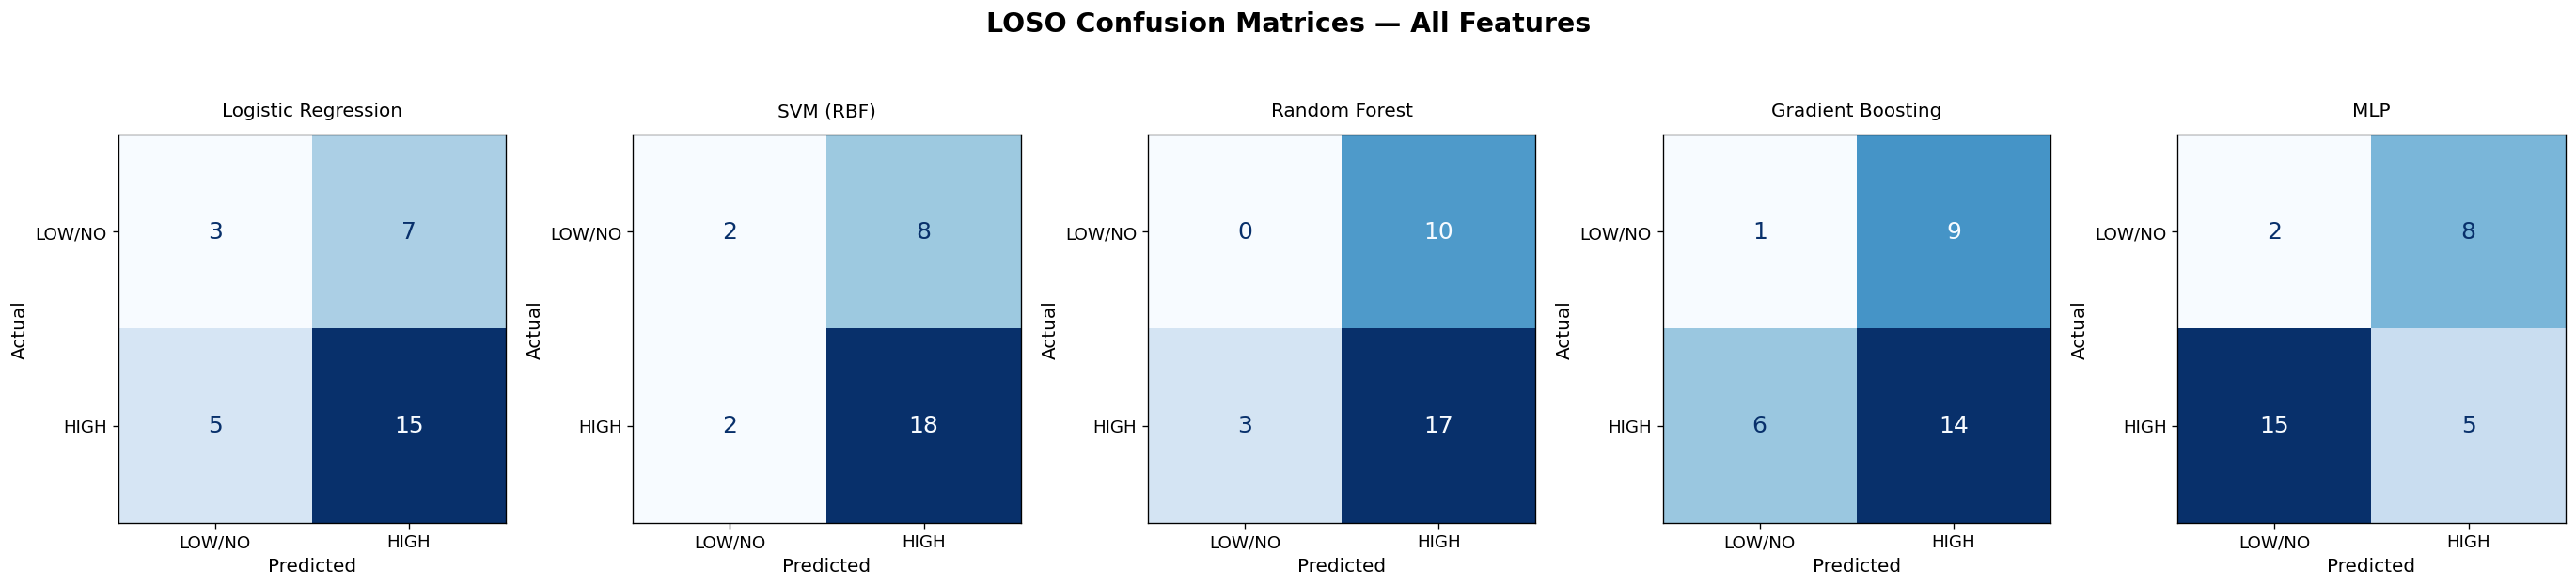


STEP 26 COMPLETED
Combined performance figure : 1
Combined ROC figure         : 1
Individual confusion matrices: 20
Combined confusion matrices : 4
Confusion matrix CSV        : 1

Output directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal


,feature_set,model,tn,fp,fn,tp,total
0,Skeleton,Logistic Regression,3,7,6,14,30
1,Skeleton,SVM (RBF),1,9,2,18,30
2,Skeleton,Random Forest,0,10,1,19,30
3,Skeleton,Gradient Boosting,3,7,6,14,30
4,Skeleton,MLP,1,9,12,8,30
5,Skeleton + Context,Logistic Regression,4,6,6,14,30
6,Skeleton + Context,SVM (RBF),1,9,2,18,30
7,Skeleton + Context,Random Forest,0,10,2,18,30
8,Skeleton + Context,Gradient Boosting,2,8,6,14,30
9,Skeleton + Context,MLP,1,9,13,7,30


In [ ]:

# ============================================================
# STEP 26. COMBINED LOSO BENCHMARK VISUALIZATION
# Reviewer 2: Head-to-head LOSO comparison
# Reviewer 6: Font >= 11 pt, 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# ============================================================
# 26.1 OUTPUT DIRECTORIES
# ============================================================

HEAD_TO_HEAD_DIR = Path(HEAD_TO_HEAD_DIR)
HEAD_TO_HEAD_DIR.mkdir(parents=True, exist_ok=True)

CM_DIR = HEAD_TO_HEAD_DIR / "Confusion_Matrices"
CM_COMBINED_DIR = HEAD_TO_HEAD_DIR / "Combined_Confusion_Matrices"

CM_DIR.mkdir(parents=True, exist_ok=True)
CM_COMBINED_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 26.2 GLOBAL STYLE
# ============================================================

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})

FEATURE_ORDER = [
    "Skeleton",
    "Skeleton + Context",
    "Skeleton + Physiological",
    "All Features"
]

MODEL_ORDER = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting",
    "MLP"
]

MODEL_SHORT = [
    "LR", "SVM", "RF", "GB", "MLP"
]

METRICS = [
    ("macro_f1", "Macro-F1"),
    ("roc_auc", "ROC-AUC"),
    ("balanced_accuracy", "Balanced Accuracy")
]

FEATURE_COLORS = [
    "#4472C4",
    "#ED7D31",
    "#70AD47",
    "#8064A2"
]

def safe_filename(text):
    return (
        str(text)
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("/", "_")
        .replace("(", "")
        .replace(")", "")
    )

def save_figure(fig, path):
    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

# ============================================================
# 26.3 DATA VALIDATION
# ============================================================

required_summary = {
    "feature_set", "model",
    "macro_f1", "roc_auc", "balanced_accuracy",
    "tn", "fp", "fn", "tp"
}

required_oof = {
    "feature_set", "model",
    "subject", "y_true", "y_prob_high", "y_pred"
}

if not required_summary.issubset(baseline_summary_df.columns):
    raise ValueError(
        "Missing required columns in baseline_summary_df"
    )

if not required_oof.issubset(baseline_oof_df.columns):
    raise ValueError(
        "Missing required columns in baseline_oof_df"
    )

summary_plot = baseline_summary_df.copy()
summary_plot["feature_set"] = (
    summary_plot["feature_set"].astype(str)
)
summary_plot["model"] = (
    summary_plot["model"].astype(str)
)

oof_plot = baseline_oof_df.copy()
oof_plot["feature_set"] = (
    oof_plot["feature_set"].astype(str)
)
oof_plot["model"] = (
    oof_plot["model"].astype(str)
)

for set_name in FEATURE_ORDER:
    for model_name in MODEL_ORDER:

        sub = summary_plot[
            (summary_plot["feature_set"] == set_name) &
            (summary_plot["model"] == model_name)
        ]

        rows = oof_plot[
            (oof_plot["feature_set"] == set_name) &
            (oof_plot["model"] == model_name)
        ]

        if len(sub) != 1:
            raise ValueError(
                f"Expected one summary row: "
                f"{set_name} / {model_name}"
            )

        if len(rows) != 30:
            raise ValueError(
                f"Expected 30 OOF predictions: "
                f"{set_name} / {model_name}"
            )

        if rows["subject"].nunique() != 30:
            raise ValueError(
                f"Duplicate or missing subjects: "
                f"{set_name} / {model_name}"
            )

print("Data validation: PASSED")

# ============================================================
# 26.4 ONE COMBINED PERFORMANCE FIGURE
# 3 METRICS x 4 FEATURE SETS x 5 MODELS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6),
    sharey=True
)

x = np.arange(len(MODEL_ORDER))
bar_width = 0.19

for ax, (metric, metric_title) in zip(
    axes, METRICS
):

    pivot = summary_plot.pivot(
        index="model",
        columns="feature_set",
        values=metric
    ).reindex(
        index=MODEL_ORDER,
        columns=FEATURE_ORDER
    )

    for j, feature_set in enumerate(FEATURE_ORDER):

        offset = (
            j - (len(FEATURE_ORDER) - 1) / 2
        ) * bar_width

        ax.bar(
            x + offset,
            pivot[feature_set].to_numpy(),
            width=bar_width,
            label=feature_set,
            color=FEATURE_COLORS[j]
        )

    ax.set_title(
        metric_title,
        fontweight="bold",
        pad=12
    )

    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_SHORT)

    ax.set_ylim(0, 1.05)
    ax.set_yticks(np.arange(0, 1.01, 0.2))

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

axes[0].set_ylabel("LOSO OOF Score")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.055),
    ncol=4,
    frameon=False,
    fontsize=12
)

fig.suptitle(
    "Head-to-Head LOSO Performance Across Feature Sets",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0.06, 1, 0.96])

save_figure(
    fig,
    HEAD_TO_HEAD_DIR /
    "Combined_LOSO_Model_Comparison.png"
)

plt.show()
plt.close(fig)

# ============================================================
# 26.5 ONE COMBINED ROC FIGURE
# FOUR PANELS: ONE PER FEATURE SET
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 13)
)

axes = axes.ravel()

for ax, set_name in zip(axes, FEATURE_ORDER):

    for model_name in MODEL_ORDER:

        rows = oof_plot[
            (oof_plot["feature_set"] == set_name) &
            (oof_plot["model"] == model_name)
        ]

        RocCurveDisplay.from_predictions(
            rows["y_true"].astype(int),
            rows["y_prob_high"].astype(float),
            name=model_name,
            ax=ax
        )

    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1.2,
        label="Chance"
    )

    ax.set_title(
        set_name,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.grid(alpha=0.2)
    ax.legend(loc="lower right", fontsize=11)

fig.suptitle(
    "LOSO Out-of-Fold ROC Curves",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

save_figure(
    fig,
    HEAD_TO_HEAD_DIR /
    "Combined_LOSO_ROC_Curves.png"
)

plt.show()
plt.close(fig)

# ============================================================
# 26.6 INDIVIDUAL CONFUSION MATRICES
# ============================================================

cm_records = []

for set_name in FEATURE_ORDER:

    for model_name in MODEL_ORDER:

        rows = oof_plot[
            (oof_plot["feature_set"] == set_name) &
            (oof_plot["model"] == model_name)
        ]

        cm = confusion_matrix(
            rows["y_true"].astype(int),
            rows["y_pred"].astype(int),
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        summary_row = summary_plot[
            (summary_plot["feature_set"] == set_name) &
            (summary_plot["model"] == model_name)
        ].iloc[0]

        summary_cm = np.array([
            [
                int(summary_row["tn"]),
                int(summary_row["fp"])
            ],
            [
                int(summary_row["fn"]),
                int(summary_row["tp"])
            ]
        ])

        if not np.array_equal(cm, summary_cm):
            raise ValueError(
                f"Confusion matrix mismatch: "
                f"{set_name} / {model_name}"
            )

        cm_records.append({
            "feature_set": set_name,
            "model": model_name,
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
            "total": int(cm.sum())
        })

        fig, ax = plt.subplots(figsize=(7, 6))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["LOW/NO", "HIGH"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            f"{model_name} — {set_name}",
            fontsize=14,
            pad=14
        )

        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("True Label")

        for text_obj in disp.text_.ravel():
            text_obj.set_fontsize(16)

        fig.tight_layout()

        save_figure(
            fig,
            CM_DIR /
            (
                f"CM_{safe_filename(set_name)}_"
                f"{safe_filename(model_name)}.png"
            )
        )

        plt.close(fig)

# ============================================================
# 26.7 COMBINED CONFUSION MATRICES
# 4 FIGURES x 5 MODELS
# ============================================================

for set_name in FEATURE_ORDER:

    fig, axes = plt.subplots(
        1, 5,
        figsize=(23, 4.8)
    )

    for ax, model_name in zip(
        axes, MODEL_ORDER
    ):

        rows = oof_plot[
            (oof_plot["feature_set"] == set_name) &
            (oof_plot["model"] == model_name)
        ]

        cm = confusion_matrix(
            rows["y_true"].astype(int),
            rows["y_pred"].astype(int),
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["LOW/NO", "HIGH"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            model_name,
            fontsize=12,
            pad=12
        )

        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        ax.tick_params(
            axis="both",
            labelsize=11
        )

        for text_obj in disp.text_.ravel():
            text_obj.set_fontsize(15)

    fig.suptitle(
        f"LOSO Confusion Matrices — {set_name}",
        fontsize=17,
        fontweight="bold",
        y=1.06
    )

    fig.tight_layout()

    save_figure(
        fig,
        CM_COMBINED_DIR /
        f"Combined_CM_{safe_filename(set_name)}.png"
    )

    plt.show()
    plt.close(fig)

# ============================================================
# 26.8 SAVE CONFUSION MATRIX CSV
# ============================================================

confusion_df = pd.DataFrame(cm_records)

confusion_df.to_csv(
    HEAD_TO_HEAD_DIR /
    "baseline_confusion_matrices.csv",
    index=False
)

# ============================================================
# 26.9 FINAL SUMMARY
# ============================================================

assert len(confusion_df) == 20

print("\n" + "=" * 70)
print("STEP 26 COMPLETED")
print("=" * 70)

print("Combined performance figure : 1")
print("Combined ROC figure         : 1")
print("Individual confusion matrices:", 20)
print("Combined confusion matrices :", 4)
print("Confusion matrix CSV        : 1")

print("\nOutput directory:")
print(HEAD_TO_HEAD_DIR)

display(confusion_df)


In [ ]:

# ============================================================
# STEP 27.2 SELECT MODEL AND FEATURE SET FOR SHAP
# Compatible with STEP 25 and STEP 26
# ============================================================

import ipywidgets as widgets
import pandas as pd

from IPython.display import display, clear_output
from pathlib import Path

# ============================================================
# 27.2.1 AVAILABLE RESULTS
# ============================================================

available_results = baseline_summary_df[
    [
        "model",
        "feature_set",
        "macro_f1",
        "roc_auc",
        "balanced_accuracy"
    ]
].copy()

available_results["model"] = (
    available_results["model"].astype(str)
)

available_results["feature_set"] = (
    available_results["feature_set"].astype(str)
)

available_results = available_results.drop_duplicates(
    subset=["model", "feature_set"]
)

MODEL_OPTIONS = [
    model
    for model in BENCHMARK_MODELS
    if model in available_results["model"].values
]

FEATURE_SET_OPTIONS = [
    feature_set
    for feature_set in BENCHMARK_SETS.keys()
    if feature_set in available_results["feature_set"].values
]

if not MODEL_OPTIONS or not FEATURE_SET_OPTIONS:
    raise ValueError(
        "No valid benchmark combinations available."
    )

# ============================================================
# 27.2.2 DEFAULT: BEST MACRO-F1
# ============================================================

ranked_results = available_results.sort_values(
    by=[
        "macro_f1",
        "balanced_accuracy",
        "roc_auc"
    ],
    ascending=False
)

top_result = ranked_results.iloc[0]

DEFAULT_MODEL = str(top_result["model"])
DEFAULT_FEATURE_SET = str(top_result["feature_set"])

print("Recommended selection based on LOSO Macro-F1:")
print("Model      :", DEFAULT_MODEL)
print("Feature Set:", DEFAULT_FEATURE_SET)
print("Macro-F1   :", round(top_result["macro_f1"], 4))

# ============================================================
# 27.2.3 DROPDOWN WIDGETS
# ============================================================

model_dropdown = widgets.Dropdown(
    options=MODEL_OPTIONS,
    value=DEFAULT_MODEL,
    description="Model:",
    style={"description_width": "140px"},
    layout=widgets.Layout(width="500px")
)

feature_dropdown = widgets.Dropdown(
    options=FEATURE_SET_OPTIONS,
    value=DEFAULT_FEATURE_SET,
    description="Feature Set:",
    style={"description_width": "140px"},
    layout=widgets.Layout(width="500px")
)

select_button = widgets.Button(
    description="Apply Selection",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="200px")
)

selection_output = widgets.Output()

# ============================================================
# 27.2.4 APPLY SELECTION
# ============================================================

def apply_selection(button):

    global BEST_MODEL_NAME
    global BEST_FEATURE_SET
    global BEST_FEATURE_GROUPS
    global BEST_FEATURE_COLUMNS
    global best_row
    global SHAP_DIR

    chosen_model = model_dropdown.value
    chosen_set = feature_dropdown.value

    result = available_results[
        (available_results["model"] == chosen_model) &
        (available_results["feature_set"] == chosen_set)
    ]

    with selection_output:

        clear_output(wait=True)

        if len(result) != 1:
            print(
                "Selected combination has no unique "
                "benchmark result."
            )
            return

        BEST_MODEL_NAME = chosen_model
        BEST_FEATURE_SET = chosen_set

        best_row = result.iloc[0]

        # Feature groups corresponding to selected ablation
        BEST_FEATURE_GROUPS = BENCHMARK_SETS[
            BEST_FEATURE_SET
        ]

        # Actual input columns
        BEST_FEATURE_COLUMNS = [
            col
            for group in BEST_FEATURE_GROUPS
            for col in BENCHMARK_FEATURE_GROUPS[group]
        ]

        # Safe output folder names
        safe_model = (
            BEST_MODEL_NAME
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
            .replace("/", "_")
        )

        safe_set = (
            BEST_FEATURE_SET
            .replace(" ", "_")
            .replace("+", "plus")
            .replace("/", "_")
        )

        SHAP_DIR = (
            Path(HEAD_TO_HEAD_DIR)
            / "SHAP_Analysis"
            / safe_model
            / safe_set
        )

        SHAP_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        print("=" * 65)
        print("SHAP CONFIGURATION")
        print("=" * 65)

        print("Selected Model    :", BEST_MODEL_NAME)
        print("Selected Feature Set:", BEST_FEATURE_SET)
        print("Number of Features :", len(BEST_FEATURE_COLUMNS))
        print("ROC-AUC            :", round(best_row["roc_auc"], 4))
        print("Macro-F1           :", round(best_row["macro_f1"], 4))
        print(
            "Balanced Accuracy  :",
            round(best_row["balanced_accuracy"], 4)
        )

        print("\nFeature Groups:")
        for group in BEST_FEATURE_GROUPS:
            print(
                f"  {group}: "
                f"{len(BENCHMARK_FEATURE_GROUPS[group])} features"
            )

        print("\nOutput Folder:", SHAP_DIR)
        print("\nModel selection applied.")

# ============================================================
# 27.2.5 DISPLAY WIDGET
# ============================================================

select_button.on_click(apply_selection)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>STEP 27 — SHAP Model Configuration</h3>"
        ),
        widgets.HTML(
            "<p>Select the classifier and feature set "
            "to explain using SHAP.</p>"
        ),
        model_dropdown,
        feature_dropdown,
        select_button,
        selection_output
    ])
)


Recommended selection based on LOSO Macro-F1:
Model      : Logistic Regression
Feature Set: Skeleton + Context
Macro-F1   : 0.55


STEP 27 — LOSO SHAP
Model      : SVM (RBF)
Feature set: All Features
Groups     : ['skeleton', 'context', 'physiological']
Subjects   : 30
Features   : 75
Class count: [10 20]

STEP 25 OOF agreement
Maximum error: 4.509452766998656e-05
Mean error   : 6.627846379207251e-06
Status       : REFIT_NOT_IDENTICAL
SHAP completed: 5/30
SHAP completed: 10/30
SHAP completed: 15/30
SHAP completed: 20/30
SHAP completed: 25/30
SHAP completed: 30/30

SHAP additivity
Maximum error: 0.0
SHAP additivity: PASSED


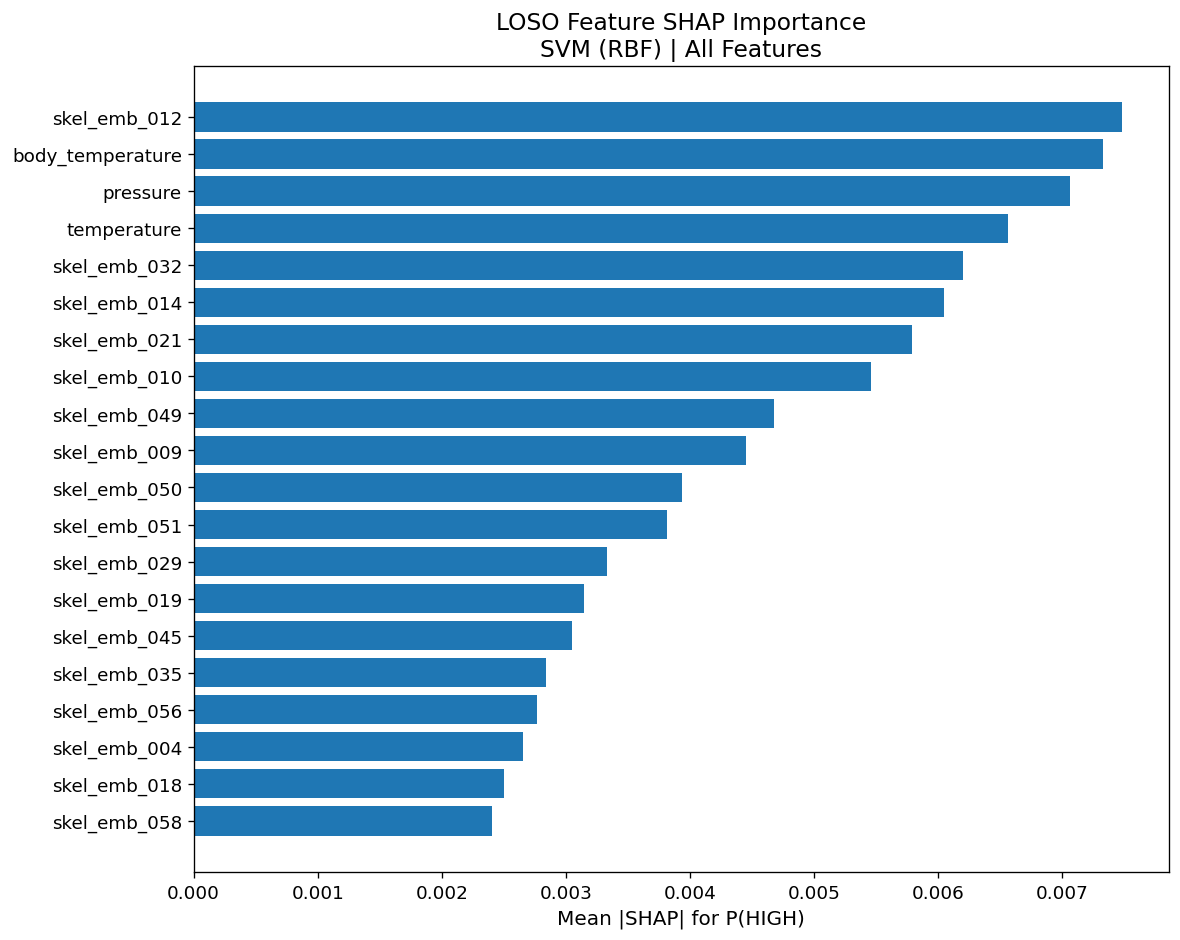

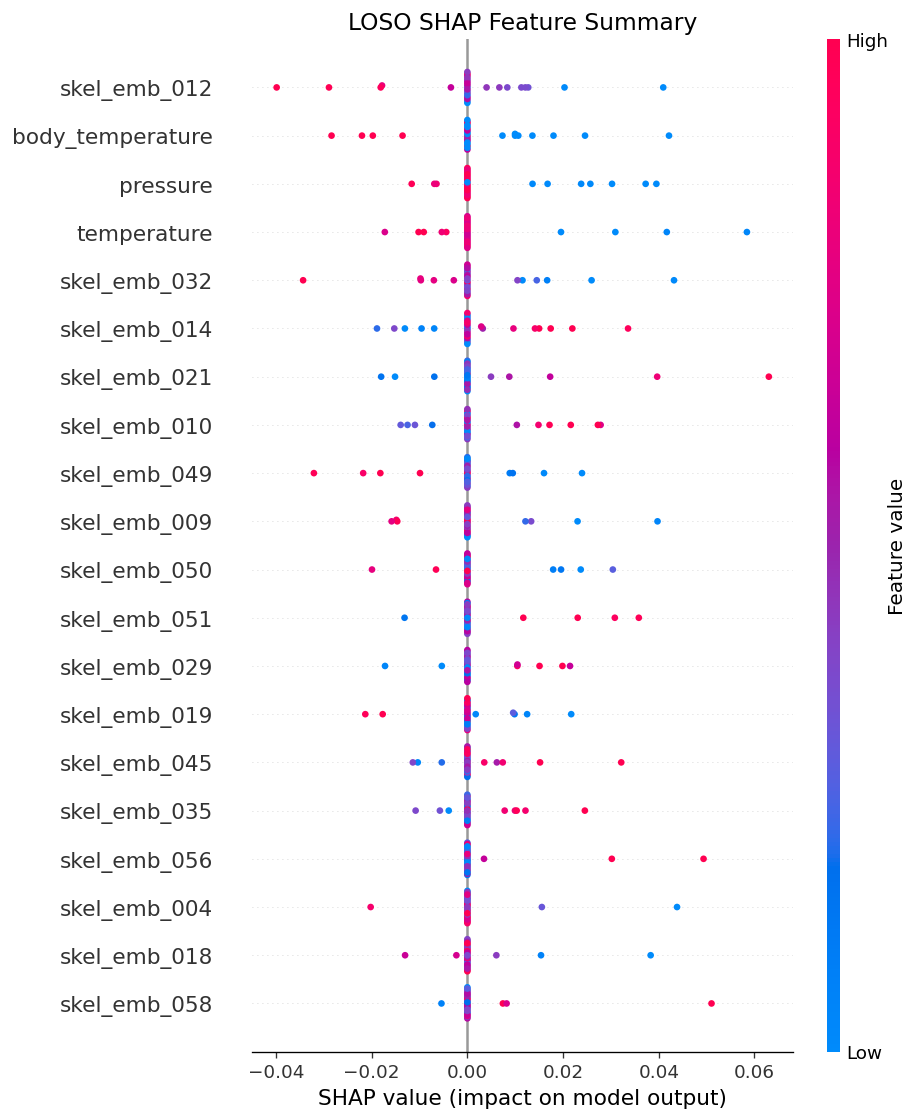

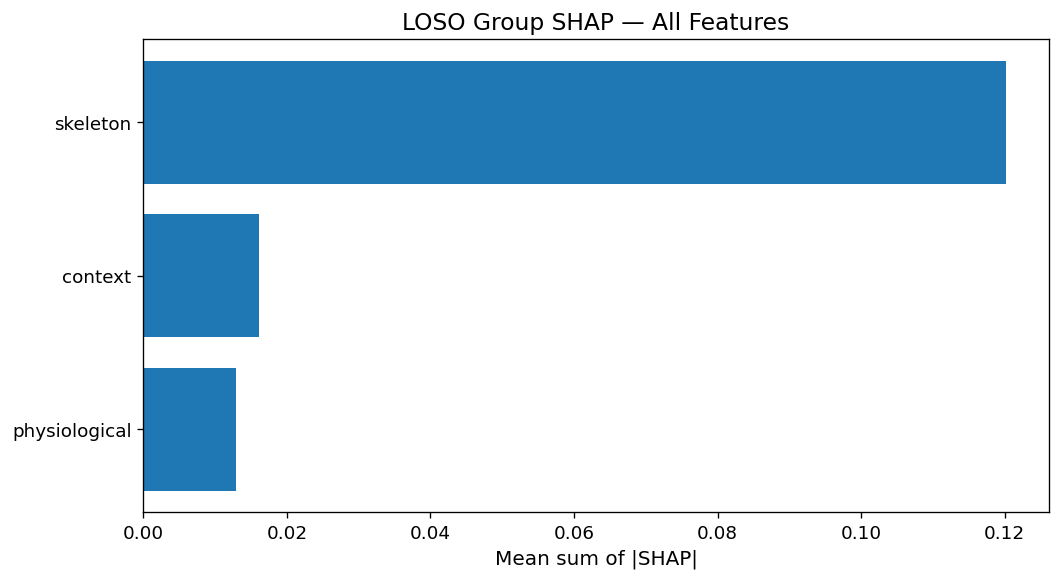

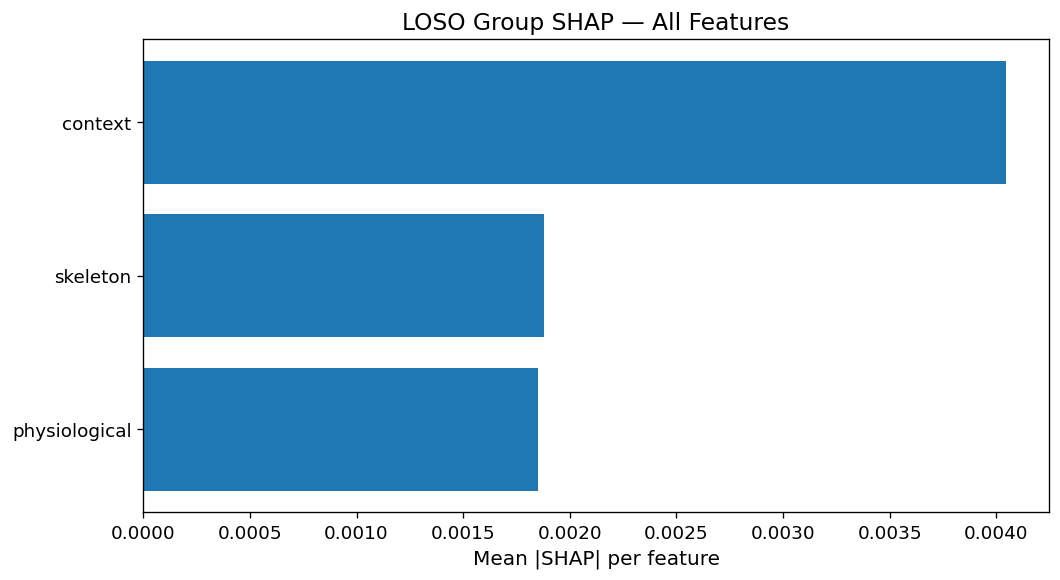

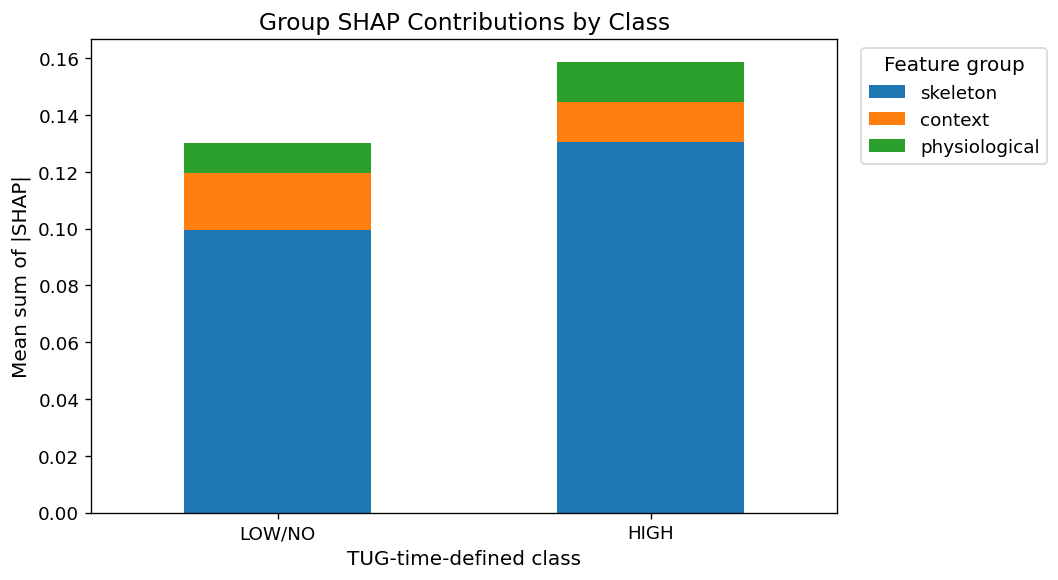

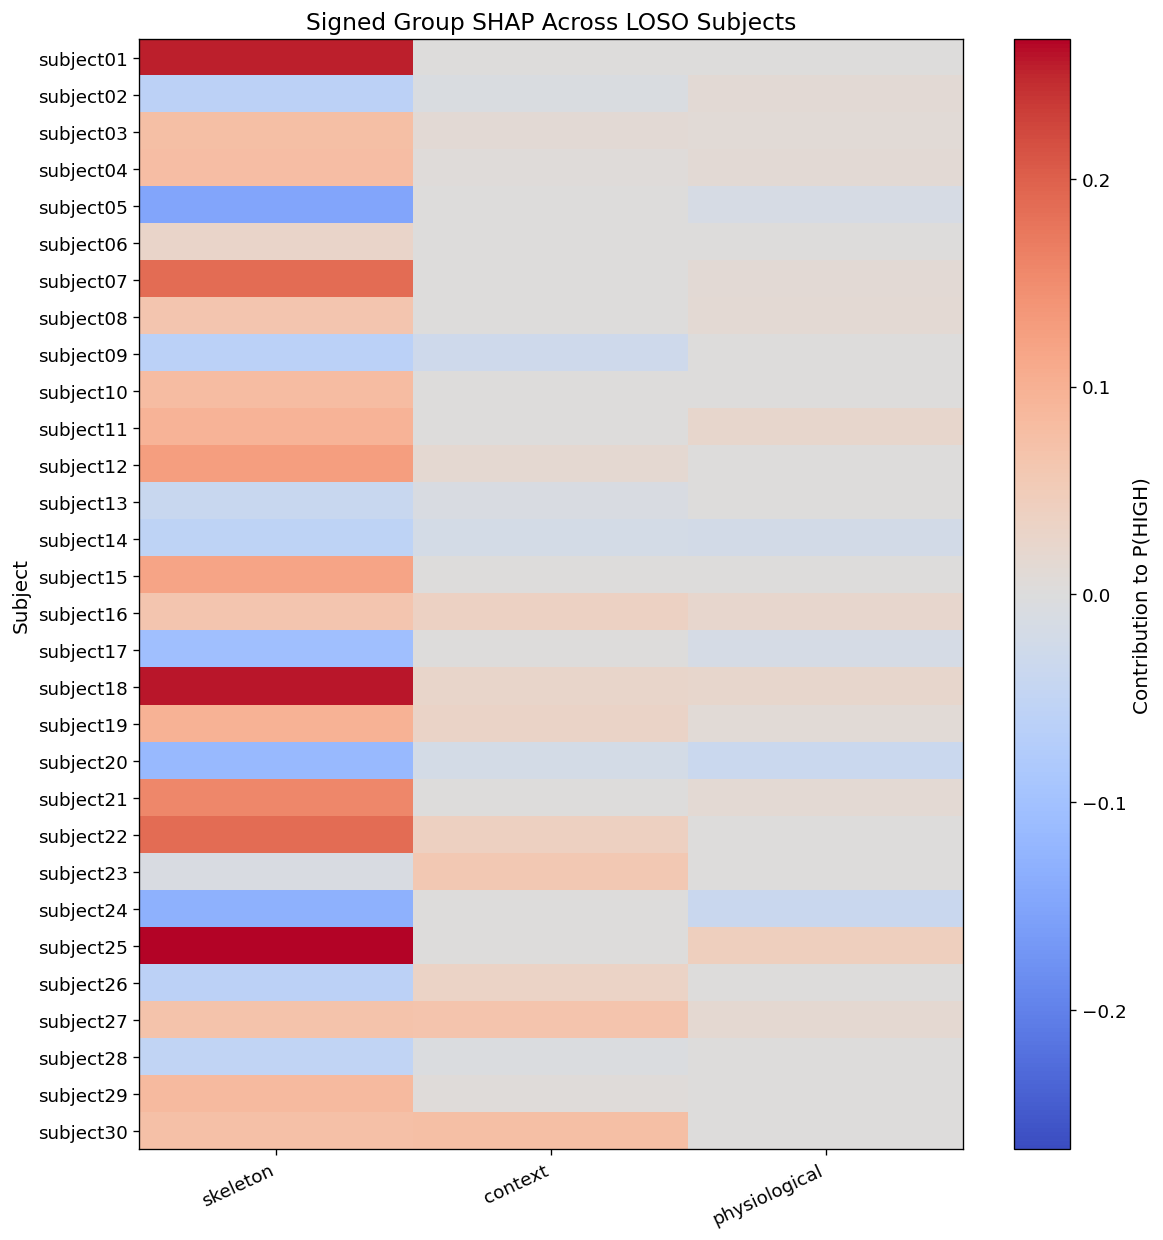


STEP 27 FINISHED
Model          : SVM (RBF)
Feature set    : All Features
Analysis status: REFIT_NOT_IDENTICAL
OOF max error  : 4.509452766998656e-05
SHAP max error : 0.0

Top 10 features:


,feature,mean_abs_shap,mean_signed_shap
0,skel_emb_012,0.007486,0.000275
1,body_temperature,0.007332,0.001751
2,pressure,0.007063,0.005396
3,temperature,0.006564,0.003476
4,skel_emb_032,0.006200,0.001955
5,skel_emb_014,0.006052,0.001803
6,skel_emb_021,0.005791,0.003121
7,skel_emb_010,0.005462,0.002479
8,skel_emb_049,0.004675,-0.000787
9,skel_emb_009,0.004452,0.001431



Group importance:


,group,n_features,mean_sum_abs_shap,mean_abs_per_feature,mean_signed_group_shap,mean_abs_signed_group_shap,relative_importance_pct
0,skeleton,64,0.120137,0.001877,0.050726,0.106600,80.488827
1,context,4,0.016175,0.004044,0.010552,0.016175,10.837149
2,physiological,7,0.012947,0.001850,0.002992,0.011054,8.674024



Group SHAP by class:


,risk_class,n_subjects,skeleton,context,physiological
0,LOW/NO,10,0.099631,0.020081,0.010519
1,HIGH,20,0.130389,0.014223,0.014161



Saved files:
 - Feature_SHAP/LOSO_SHAP_Per_Subject.csv
 - Feature_SHAP/SHAP_Feature_Bar.png
 - Feature_SHAP/SHAP_Feature_Beeswarm.png
 - Feature_SHAP/SHAP_Feature_Importance.csv
 - Group_SHAP/Group_SHAP_Absolute_Per_Subject.csv
 - Group_SHAP/Group_SHAP_Bar.png
 - Group_SHAP/Group_SHAP_By_Class.csv
 - Group_SHAP/Group_SHAP_By_Class.png
 - Group_SHAP/Group_SHAP_Global_Importance.csv
 - Group_SHAP/Group_SHAP_Heatmap.png
 - Group_SHAP/Group_SHAP_Normalized.png
 - Group_SHAP/Group_SHAP_Signed_Per_Subject.csv
 - SHAP_Metadata.json
 - STEP25_Refit_Agreement.csv

Output directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal/SHAP_Analysis/SVM__RBF_/All_Features


In [ ]:

# ================================================================
# STEP 27. LOSO SHAP + GROUP SHAP ANALYSIS
# UPDATED FOR LATEST BENCHMARK FEATURE SETS
#
# Reviewer 2: Head-to-head LOSO consistency
# Reviewer 6: Figures >= 11 pt, 300 DPI
#
# Feature sets:
#   Skeleton
#   Skeleton + Context
#   Skeleton + Physiological
#   All Features
#
# Target: LOW/NO = 0, HIGH = 1
# Duration variables are excluded.
# ================================================================

# Install SHAP if needed:
# %pip install -q shap

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import shap

from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

# ================================================================
# 27.1 CONFIGURATION
# ================================================================

SHAP_SEED = int(globals().get("BENCHMARK_SEED", 42))

SHAP_BACKGROUND_SIZE = 20
SHAP_NSAMPLES = 300
SHAP_MAX_DISPLAY = 20
SHAP_DPI = 300

OOF_TOLERANCE = 1e-6
ADDITIVITY_TOLERANCE = 1e-3

# If False, stop when refitted predictions differ from STEP 25.
# If True, continue, but label the output as REFIT_NOT_IDENTICAL.
ALLOW_NONIDENTICAL_REFIT = True

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": SHAP_DPI
})

# ================================================================
# 27.2 CHECK REQUIRED OBJECTS
# ================================================================

required = [
    "df",
    "baseline_oof_df",
    "baseline_summary_df",
    "BENCHMARK_SETS",
    "BENCHMARK_FEATURE_GROUPS",
    "HEAD_TO_HEAD_DIR",
    "make_classical_estimator"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing objects from STEP 24/25: "
        + ", ".join(missing)
    )

# Default model selection if STEP 27.2 was not executed.
BEST_MODEL_NAME = globals().get(
    "BEST_MODEL_NAME",
    "SVM (RBF)"
)

BEST_FEATURE_SET = globals().get(
    "BEST_FEATURE_SET",
    "All Features"
)

legacy_mapping = {
    "Without_Duration": "All Features",
    "Full_Multimodal": "All Features",
    "Skeleton_Only": "Skeleton",
    "Skeleton_Context": "Skeleton + Context",
    "Skeleton_Physiological": "Skeleton + Physiological"
}

BEST_FEATURE_SET = legacy_mapping.get(
    BEST_FEATURE_SET,
    BEST_FEATURE_SET
)

supported_models = [
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "Gradient Boosting"
]

if BEST_MODEL_NAME not in supported_models:
    raise ValueError(
        f"Unsupported SHAP model: {BEST_MODEL_NAME}. "
        "Keras MLP requires separate fold-specific SHAP."
    )

if BEST_FEATURE_SET not in BENCHMARK_SETS:
    raise ValueError(
        f"Unknown feature set: {BEST_FEATURE_SET}"
    )

selected_groups = BENCHMARK_SETS[BEST_FEATURE_SET]

selected_columns = [
    feature
    for group in selected_groups
    for feature in BENCHMARK_FEATURE_GROUPS[group]
]

if len(selected_columns) != len(set(selected_columns)):
    raise ValueError("Duplicate selected features.")

for feature in selected_columns:
    if feature not in df.columns:
        raise KeyError(f"Missing feature: {feature}")

    forbidden = [
        "duration",
        "total_tug_time",
        "fall_risk",
        "tug_time"
    ]

    if any(
        word in feature.lower()
        for word in forbidden
    ):
        raise ValueError(
            f"Potential target leakage: {feature}"
        )

# ================================================================
# 27.3 DATA AND TARGET
# ================================================================

data = df.reset_index(drop=True).copy()

if "subject" not in data.columns:
    raise KeyError("Missing subject column.")

subject_ids = (
    data["subject"].astype(str).to_numpy()
)

if len(np.unique(subject_ids)) != len(subject_ids):
    raise ValueError(
        "Expected exactly one row per subject."
    )

X = data[selected_columns].apply(
    pd.to_numeric,
    errors="raise"
)

if X.isna().all(axis=0).any():
    raise ValueError(
        "At least one selected feature is entirely missing."
    )

if np.isinf(X.to_numpy(dtype=float)).any():
    raise ValueError("Infinite feature values detected.")

if "fall_risk" not in data.columns:
    raise KeyError("Missing fall_risk column.")

target = (
    data["fall_risk"]
    .astype(str)
    .str.strip()
    .str.upper()
)

label_map = {
    "LOW/NO": 0,
    "HIGH": 1
}

if not target.isin(label_map).all():
    raise ValueError(
        f"Unexpected labels: {target.unique().tolist()}"
    )

y_shap = target.map(label_map).to_numpy(dtype=int)

n_subjects = len(X)
n_features = X.shape[1]

print("=" * 70)
print("STEP 27 — LOSO SHAP")
print("=" * 70)
print("Model      :", BEST_MODEL_NAME)
print("Feature set:", BEST_FEATURE_SET)
print("Groups     :", selected_groups)
print("Subjects   :", n_subjects)
print("Features   :", n_features)
print("Class count:", np.bincount(y_shap))

# ================================================================
# 27.4 ALIGN STEP 25 OOF PREDICTIONS
# ================================================================

reference = baseline_oof_df.copy()

for col in ["feature_set", "model", "subject"]:
    reference[col] = reference[col].astype(str)

reference = reference.loc[
    (reference["feature_set"] == BEST_FEATURE_SET)
    & (reference["model"] == BEST_MODEL_NAME)
].copy()

if len(reference) != n_subjects:
    raise ValueError(
        "Incomplete STEP 25 OOF predictions."
    )

if reference["subject"].duplicated().any():
    raise ValueError(
        "Duplicate subjects in STEP 25 OOF predictions."
    )

reference = (
    reference
    .set_index("subject")
    .reindex(subject_ids)
)

if reference[["y_true", "y_prob_high"]].isna().any().any():
    raise ValueError(
        "STEP 25 OOF subject alignment failed."
    )

reference_y = reference["y_true"].to_numpy(dtype=int)

if not np.array_equal(reference_y, y_shap):
    raise ValueError(
        "STEP 25 labels differ from current dataset."
    )

reference_prob = (
    reference["y_prob_high"].to_numpy(dtype=float)
)

# ================================================================
# 27.5 OUTPUT DIRECTORY
# ================================================================

def safe_name(value):
    return "".join(
        ch if ch.isalnum() or ch in "-_"
        else "_"
        for ch in str(value)
    )

SHAP_DIR = (
    Path(HEAD_TO_HEAD_DIR)
    / "SHAP_Analysis"
    / safe_name(BEST_MODEL_NAME)
    / safe_name(BEST_FEATURE_SET)
)

FEATURE_DIR = SHAP_DIR / "Feature_SHAP"
GROUP_DIR = SHAP_DIR / "Group_SHAP"

for directory in [
    SHAP_DIR,
    FEATURE_DIR,
    GROUP_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ================================================================
# 27.6 LOSO REFIT
# ================================================================

loo = LeaveOneOut()

oof_refit_prob = np.full(
    n_subjects,
    np.nan,
    dtype=float
)

fold_models = []

for fold, (train_idx, test_idx) in enumerate(
    loo.split(X),
    start=1
):

    estimator = make_classical_estimator(
        name=BEST_MODEL_NAME,
        seed=SHAP_SEED + fold
    )

    estimator.fit(
        X.iloc[train_idx],
        y_shap[train_idx]
    )

    positive_index = int(
        np.where(
            estimator.classes_ == 1
        )[0][0]
    )

    prob = float(
        estimator.predict_proba(
            X.iloc[test_idx]
        )[0, positive_index]
    )

    oof_refit_prob[test_idx[0]] = prob

    fold_models.append({
        "fold": fold,
        "train_idx": train_idx,
        "test_idx": test_idx,
        "estimator": estimator,
        "positive_index": positive_index
    })

# ================================================================
# 27.7 CHECK STEP 25 AGREEMENT
# ================================================================

oof_errors = np.abs(
    oof_refit_prob - reference_prob
)

max_oof_error = float(
    np.max(oof_errors)
)

mean_oof_error = float(
    np.mean(oof_errors)
)

exact_agreement = (
    max_oof_error <= OOF_TOLERANCE
)

analysis_status = (
    "MATCHED_STEP25"
    if exact_agreement
    else "REFIT_NOT_IDENTICAL"
)

print("\nSTEP 25 OOF agreement")
print("Maximum error:", max_oof_error)
print("Mean error   :", mean_oof_error)
print("Status       :", analysis_status)

agreement_df = pd.DataFrame({
    "subject": subject_ids,
    "y_true": y_shap,
    "step25_probability": reference_prob,
    "refit_probability": oof_refit_prob,
    "absolute_difference": oof_errors
})

agreement_df.to_csv(
    SHAP_DIR / "STEP25_Refit_Agreement.csv",
    index=False
)

if not exact_agreement:

    message = (
        "STEP 27 refit is not numerically identical "
        "to STEP 25. SHAP will explain the refitted "
        "LOSO models, not necessarily the exact "
        "models used for STEP 25."
    )

    if not ALLOW_NONIDENTICAL_REFIT:
        raise RuntimeError(message)

    warnings.warn(message)

# ================================================================
# 27.8 LOSO KERNEL SHAP
# ================================================================

shap_values_all = np.full(
    (n_subjects, n_features),
    np.nan,
    dtype=float
)

expected_values = np.full(
    n_subjects,
    np.nan,
    dtype=float
)

# Store exactly the imputed feature values used by SHAP.
explained_features = np.full(
    (n_subjects, n_features),
    np.nan,
    dtype=float
)

for item in fold_models:

    fold = item["fold"]
    train_idx = item["train_idx"]
    test_idx = item["test_idx"]
    estimator = item["estimator"]
    positive_index = item["positive_index"]

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    # Use the imputer fitted within the original pipeline.
    if "imputer" not in estimator.named_steps:
        raise RuntimeError(
            "Expected an imputer step in the pipeline."
        )

    fitted_imputer = estimator.named_steps["imputer"]

    train_imputed = fitted_imputer.transform(
        X_train
    )

    test_imputed = fitted_imputer.transform(
        X_test
    )

    if train_imputed.shape[1] != n_features:
        raise RuntimeError(
            "Imputation changed feature dimensionality."
        )

    rng = np.random.default_rng(
        SHAP_SEED + fold
    )

    bg_idx = rng.choice(
        len(train_imputed),
        size=min(
            SHAP_BACKGROUND_SIZE,
            len(train_imputed)
        ),
        replace=False
    )

    background = train_imputed[bg_idx]

    def predict_high(values):

        values = np.atleast_2d(
            np.asarray(values, dtype=float)
        )

        frame = pd.DataFrame(
            values,
            columns=selected_columns
        )

        return estimator.predict_proba(
            frame
        )[:, positive_index]

    explainer = shap.KernelExplainer(
        predict_high,
        background
    )

    fold_shap = explainer.shap_values(
        test_imputed,
        nsamples=SHAP_NSAMPLES,
        silent=True
    )

    fold_shap = np.asarray(fold_shap)

    if fold_shap.shape == (1, n_features):
        fold_shap = fold_shap[0]

    elif fold_shap.shape == (1, n_features, 1):
        fold_shap = fold_shap[0, :, 0]

    else:
        raise RuntimeError(
            f"Unexpected SHAP shape: {fold_shap.shape}"
        )

    row = test_idx[0]

    shap_values_all[row, :] = fold_shap
    explained_features[row, :] = test_imputed[0]

    expected_values[row] = float(
        np.asarray(
            explainer.expected_value
        ).reshape(-1)[0]
    )

    if fold % 5 == 0 or fold == n_subjects:
        print(
            f"SHAP completed: {fold}/{n_subjects}"
        )

# ================================================================
# 27.9 SHAP ADDITIVITY
# ================================================================

if not np.isfinite(shap_values_all).all():
    raise RuntimeError(
        "SHAP values contain non-finite numbers."
    )

reconstructed = (
    expected_values
    + shap_values_all.sum(axis=1)
)

additivity_errors = np.abs(
    reconstructed - oof_refit_prob
)

max_additivity_error = float(
    additivity_errors.max()
)

print("\nSHAP additivity")
print("Maximum error:", max_additivity_error)

if max_additivity_error > ADDITIVITY_TOLERANCE:
    raise RuntimeError(
        "SHAP additivity check failed."
    )

print("SHAP additivity: PASSED")

# ================================================================
# 27.10 SAVE SUBJECT-LEVEL FEATURE SHAP
# ================================================================

feature_shap_df = pd.DataFrame(
    shap_values_all,
    columns=selected_columns
)

feature_shap_df.insert(
    0, "subject", subject_ids
)

feature_shap_df.insert(
    1, "y_true", y_shap
)

feature_shap_df.insert(
    2, "oof_refit_probability", oof_refit_prob
)

feature_shap_df.insert(
    3, "expected_probability", expected_values
)

feature_shap_df.to_csv(
    FEATURE_DIR / "LOSO_SHAP_Per_Subject.csv",
    index=False
)

# ================================================================
# 27.11 FEATURE IMPORTANCE
# ================================================================

feature_importance_df = pd.DataFrame({
    "feature": selected_columns,
    "mean_abs_shap": (
        np.abs(shap_values_all).mean(axis=0)
    ),
    "mean_signed_shap": (
        shap_values_all.mean(axis=0)
    )
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

feature_importance_df.to_csv(
    FEATURE_DIR / "SHAP_Feature_Importance.csv",
    index=False
)

# ================================================================
# 27.12 FEATURE IMPORTANCE BAR
# ================================================================

top_n = min(
    SHAP_MAX_DISPLAY,
    n_features
)

plot_df = (
    feature_importance_df
    .head(top_n)
    .iloc[::-1]
)

fig, ax = plt.subplots(
    figsize=(10, max(6, 0.4 * top_n))
)

ax.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

ax.set_xlabel(
    "Mean |SHAP| for P(HIGH)"
)

ax.set_title(
    f"LOSO Feature SHAP Importance\n"
    f"{BEST_MODEL_NAME} | {BEST_FEATURE_SET}"
)

fig.tight_layout()

fig.savefig(
    FEATURE_DIR / "SHAP_Feature_Bar.png",
    dpi=SHAP_DPI,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ================================================================
# 27.13 FEATURE BEESWARM
# ================================================================

shap.summary_plot(
    shap_values_all,
    explained_features,
    feature_names=selected_columns,
    max_display=SHAP_MAX_DISPLAY,
    show=False
)

plt.title(
    "LOSO SHAP Feature Summary",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FEATURE_DIR / "SHAP_Feature_Beeswarm.png",
    dpi=SHAP_DPI,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ================================================================
# 27.14 GROUP FEATURE INDICES
# ================================================================

group_indices = {}

for group in selected_groups:

    features = set(
        BENCHMARK_FEATURE_GROUPS[group]
    )

    indices = [
        i
        for i, feature in enumerate(
            selected_columns
        )
        if feature in features
    ]

    group_indices[group] = indices

all_indices = [
    idx
    for indices in group_indices.values()
    for idx in indices
]

if sorted(all_indices) != list(range(n_features)):
    raise RuntimeError(
        "Invalid group-feature mapping."
    )

# ================================================================
# 27.15 GROUP SHAP VALUES
# ================================================================

group_signed = {}
group_absolute = {}

for group, indices in group_indices.items():

    values = shap_values_all[:, indices]

    group_signed[group] = (
        values.sum(axis=1)
    )

    group_absolute[group] = (
        np.abs(values).sum(axis=1)
    )

group_signed_df = pd.DataFrame(group_signed)
group_absolute_df = pd.DataFrame(group_absolute)

for table in [
    group_signed_df,
    group_absolute_df
]:
    table.insert(0, "subject", subject_ids)
    table.insert(1, "y_true", y_shap)

group_signed_df.to_csv(
    GROUP_DIR / "Group_SHAP_Signed_Per_Subject.csv",
    index=False
)

group_absolute_df.to_csv(
    GROUP_DIR / "Group_SHAP_Absolute_Per_Subject.csv",
    index=False
)

# ================================================================
# 27.16 GROUP IMPORTANCE
# ================================================================

group_rows = []

for group, indices in group_indices.items():

    values = shap_values_all[:, indices]

    mean_total_abs = float(
        np.abs(values).sum(axis=1).mean()
    )

    mean_per_feature = (
        mean_total_abs / len(indices)
    )

    group_rows.append({
        "group": group,
        "n_features": len(indices),
        "mean_sum_abs_shap": mean_total_abs,
        "mean_abs_per_feature": mean_per_feature,
        "mean_signed_group_shap": float(
            values.sum(axis=1).mean()
        ),
        "mean_abs_signed_group_shap": float(
            np.abs(values.sum(axis=1)).mean()
        )
    })

group_importance_df = pd.DataFrame(
    group_rows
).sort_values(
    "mean_sum_abs_shap",
    ascending=False
).reset_index(drop=True)

total_importance = (
    group_importance_df["mean_sum_abs_shap"].sum()
)

group_importance_df[
    "relative_importance_pct"
] = (
    100
    * group_importance_df["mean_sum_abs_shap"]
    / total_importance
    if total_importance > 0
    else 0.0
)

group_importance_df.to_csv(
    GROUP_DIR / "Group_SHAP_Global_Importance.csv",
    index=False
)

# ================================================================
# 27.17 GROUP SHAP BAR PLOTS
# ================================================================

for metric, filename, xlabel in [
    (
        "mean_sum_abs_shap",
        "Group_SHAP_Bar.png",
        "Mean sum of |SHAP|"
    ),
    (
        "mean_abs_per_feature",
        "Group_SHAP_Normalized.png",
        "Mean |SHAP| per feature"
    )
]:

    plot_df = (
        group_importance_df.sort_values(metric)
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.barh(
        plot_df["group"],
        plot_df[metric]
    )

    ax.set_xlabel(xlabel)
    ax.set_title(
        f"LOSO Group SHAP — {BEST_FEATURE_SET}"
    )

    fig.tight_layout()

    fig.savefig(
        GROUP_DIR / filename,
        dpi=SHAP_DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ================================================================
# 27.18 GROUP SHAP BY CLASS
# ================================================================

class_rows = []

for class_value, class_name in [
    (0, "LOW/NO"),
    (1, "HIGH")
]:

    mask = y_shap == class_value

    result = {
        "risk_class": class_name,
        "n_subjects": int(mask.sum())
    }

    for group, indices in group_indices.items():

        result[group] = float(
            np.abs(
                shap_values_all[mask][:, indices]
            ).sum(axis=1).mean()
        )

    class_rows.append(result)

class_group_df = pd.DataFrame(class_rows)

class_group_df.to_csv(
    GROUP_DIR / "Group_SHAP_By_Class.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

class_group_df.set_index("risk_class")[
    list(group_indices.keys())
].plot(
    kind="bar",
    stacked=True,
    rot=0,
    ax=ax
)

ax.set_xlabel(
    "TUG-time-defined class"
)

ax.set_ylabel(
    "Mean sum of |SHAP|"
)

ax.set_title(
    "Group SHAP Contributions by Class"
)

ax.legend(
    title="Feature group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.tight_layout()

fig.savefig(
    GROUP_DIR / "Group_SHAP_By_Class.png",
    dpi=SHAP_DPI,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ================================================================
# 27.19 SIGNED GROUP SHAP HEATMAP
# ================================================================

signed_matrix = np.column_stack([
    group_signed[group]
    for group in group_indices
])

color_limit = max(
    float(np.abs(signed_matrix).max()),
    1e-12
)

fig, ax = plt.subplots(
    figsize=(
        10,
        max(8, n_subjects * 0.35)
    )
)

heatmap = ax.imshow(
    signed_matrix,
    aspect="auto",
    cmap="coolwarm",
    vmin=-color_limit,
    vmax=color_limit
)

ax.set_xticks(
    np.arange(len(group_indices))
)

ax.set_xticklabels(
    list(group_indices.keys()),
    rotation=25,
    ha="right"
)

ax.set_yticks(
    np.arange(n_subjects)
)

ax.set_yticklabels(
    subject_ids,
    fontsize=11
)

ax.set_ylabel("Subject")

ax.set_title(
    "Signed Group SHAP Across LOSO Subjects"
)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Contribution to P(HIGH)"
)

fig.tight_layout()

fig.savefig(
    GROUP_DIR / "Group_SHAP_Heatmap.png",
    dpi=SHAP_DPI,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ================================================================
# 27.20 SAVE METADATA
# ================================================================

metadata = {
    "model": BEST_MODEL_NAME,
    "feature_set": BEST_FEATURE_SET,
    "groups": list(selected_groups),
    "n_subjects": int(n_subjects),
    "n_features": int(n_features),
    "analysis_status": analysis_status,
    "max_oof_difference": max_oof_error,
    "mean_oof_difference": mean_oof_error,
    "max_additivity_error": max_additivity_error,
    "background_size": SHAP_BACKGROUND_SIZE,
    "shap_nsamples": SHAP_NSAMPLES,
    "reference_auc": float(
        roc_auc_score(y_shap, reference_prob)
    ),
    "refit_auc": float(
        roc_auc_score(y_shap, oof_refit_prob)
    ),
    "notes": (
        "SHAP explains the refitted Stage 2 LOSO models. "
        "Results are descriptive and associational. "
        "The target is defined by TUG completion time, "
        "not independently observed future falls."
    )
}

with open(
    SHAP_DIR / "SHAP_Metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# ================================================================
# 27.21 FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("STEP 27 FINISHED")
print("=" * 70)

print("Model          :", BEST_MODEL_NAME)
print("Feature set    :", BEST_FEATURE_SET)
print("Analysis status:", analysis_status)
print("OOF max error  :", max_oof_error)
print("SHAP max error :", max_additivity_error)

print("\nTop 10 features:")
display(feature_importance_df.head(10))

print("\nGroup importance:")
display(group_importance_df)

print("\nGroup SHAP by class:")
display(class_group_df)

print("\nSaved files:")
for file in sorted(SHAP_DIR.rglob("*")):
    if file.is_file():
        print(" -", file.relative_to(SHAP_DIR))

print("\nOutput directory:")
print(SHAP_DIR)


STEP 27.25 — INDIVIDUAL LOSO SHAP
Subjects: 30
Features: 75
Maximum additivity error: 0.0

Classification outcomes:
outcome
TP    18
FP     8
FN     2
TN     2
Name: count, dtype: int64

Generating individual SHAP figures...
Saved 30 individual figures.


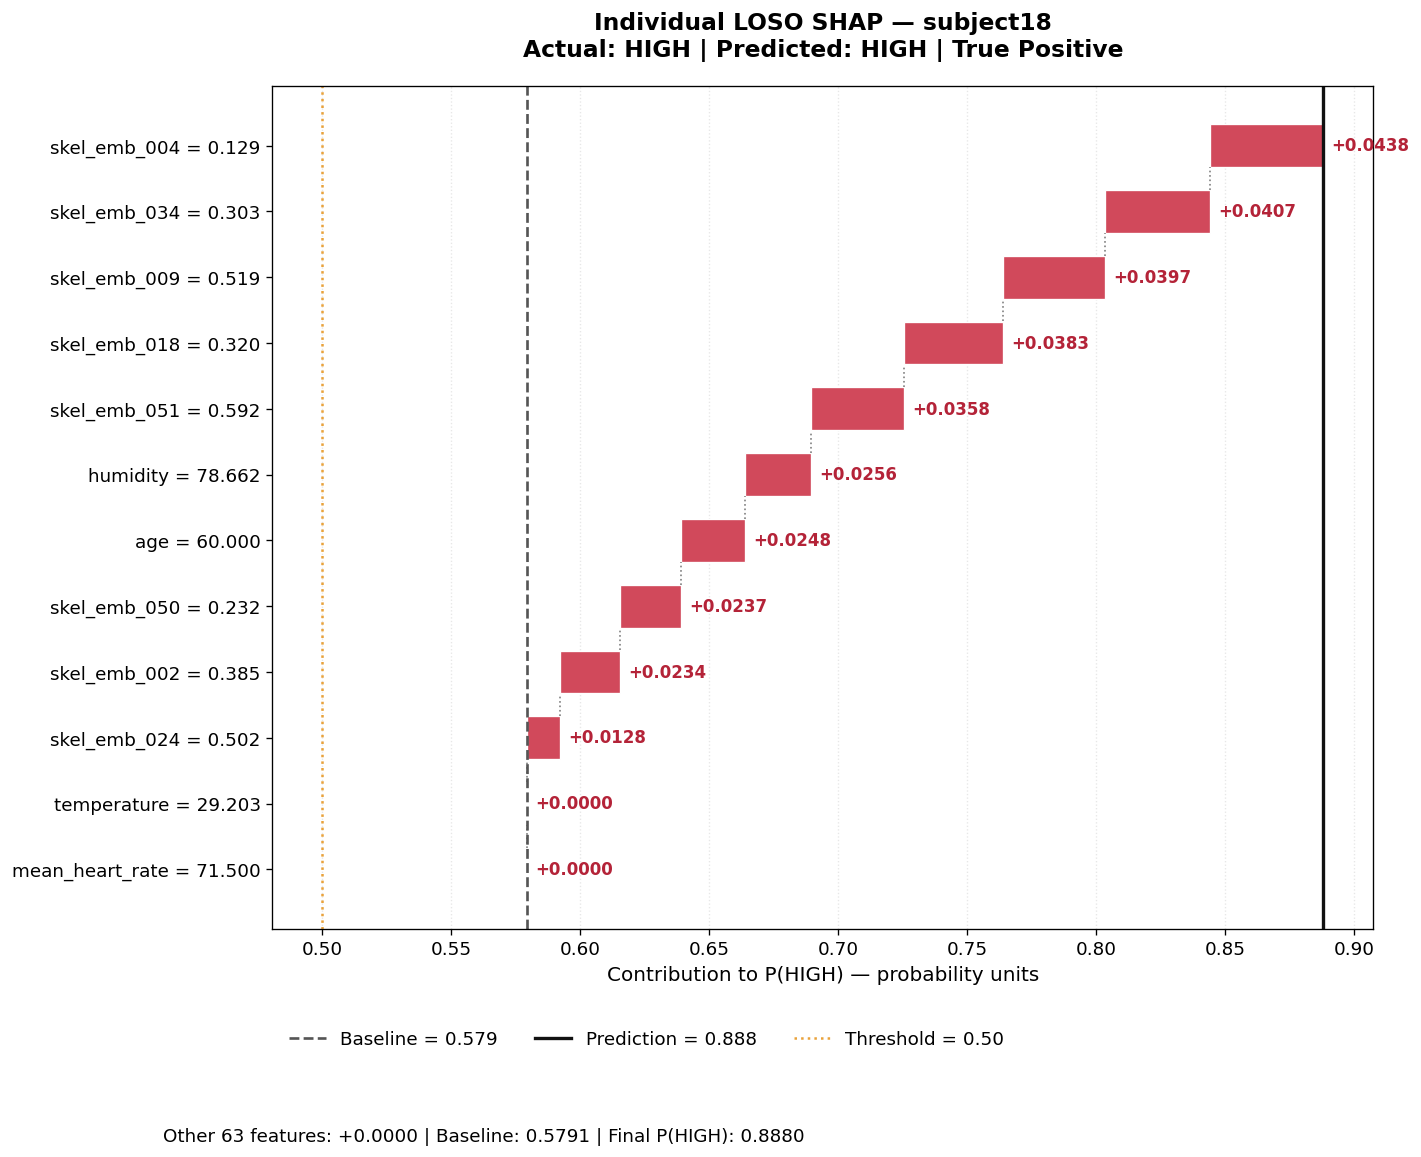

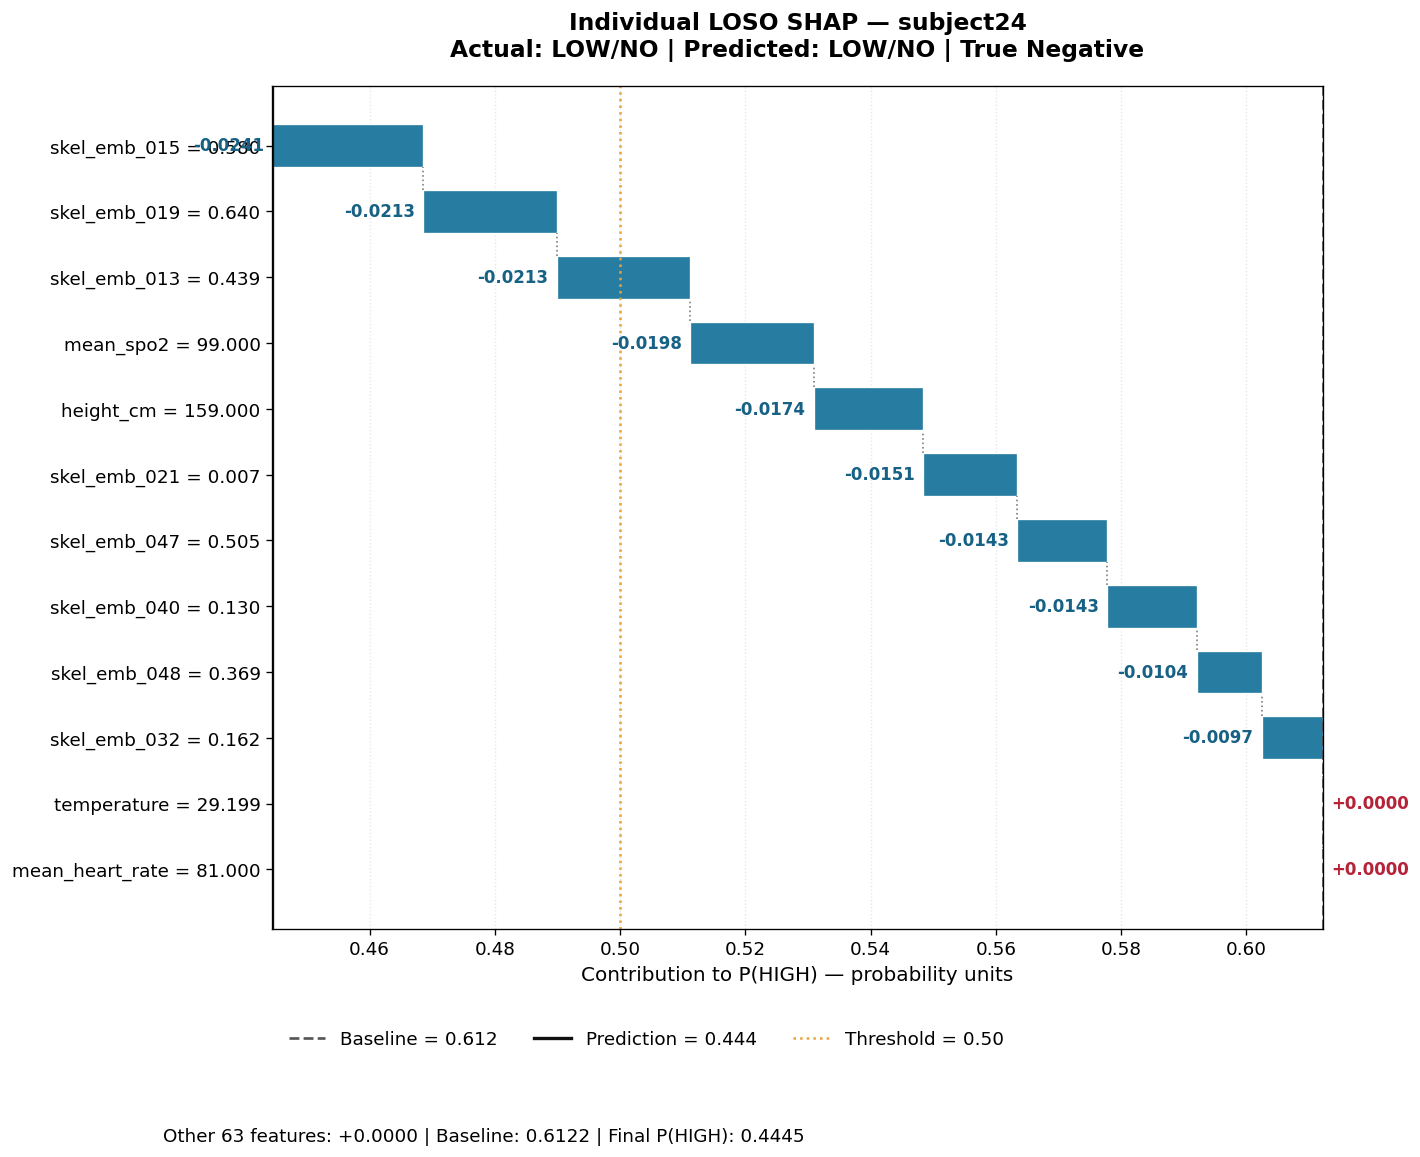

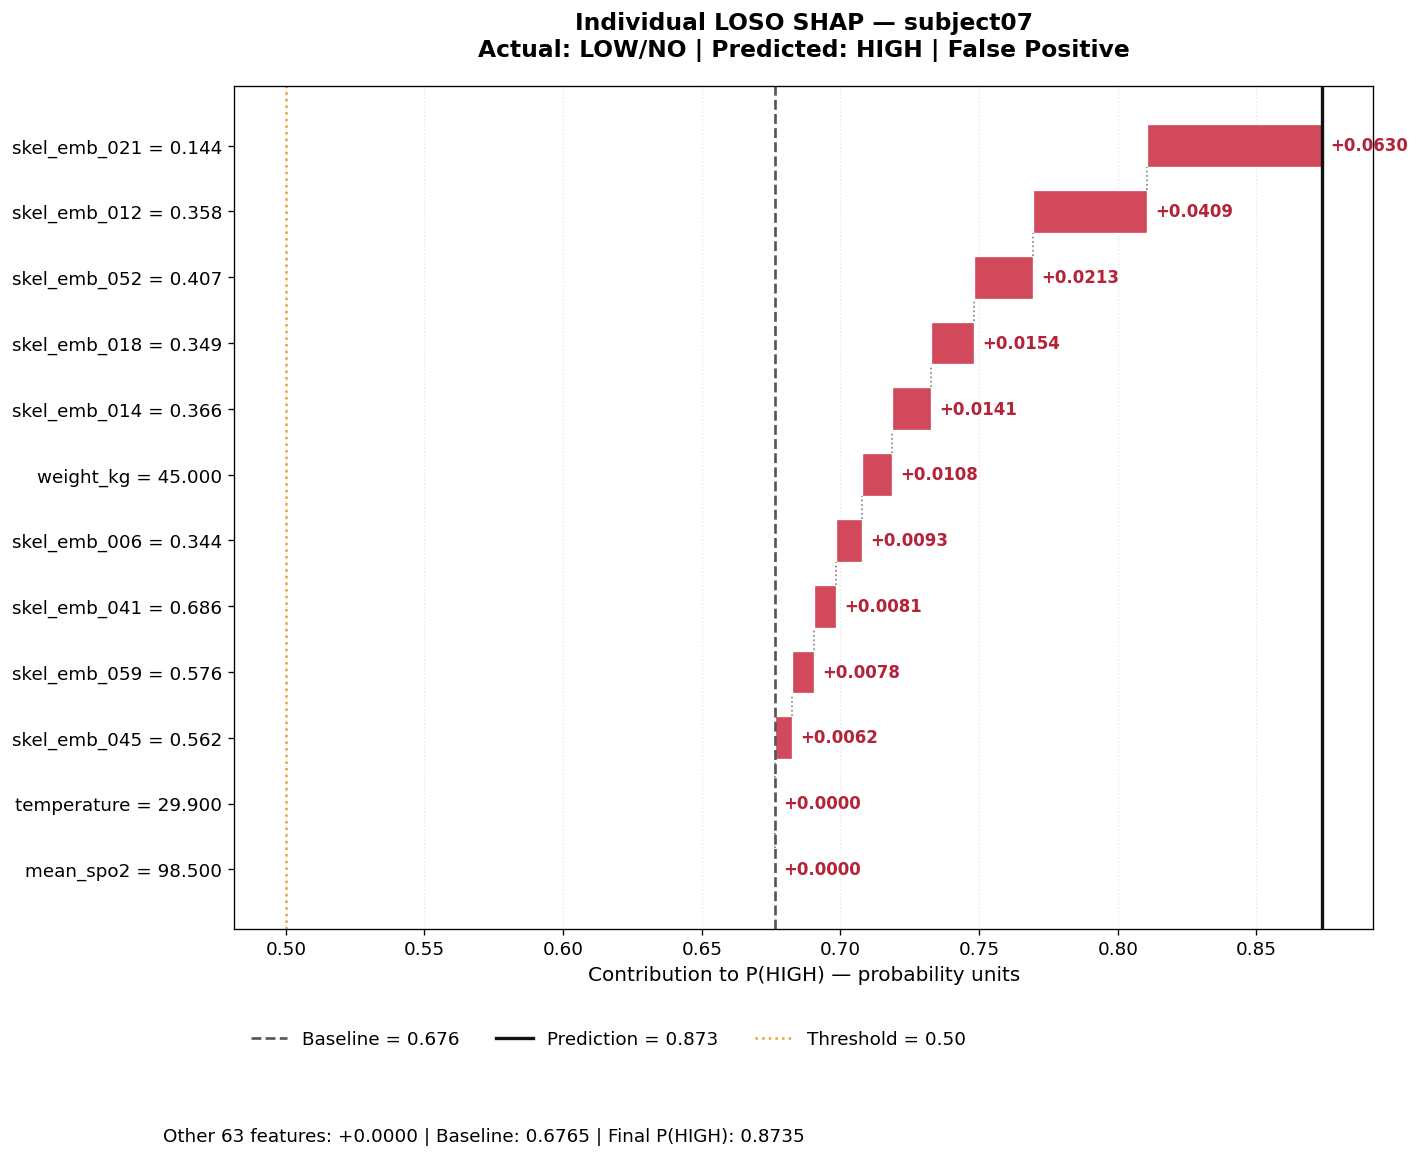

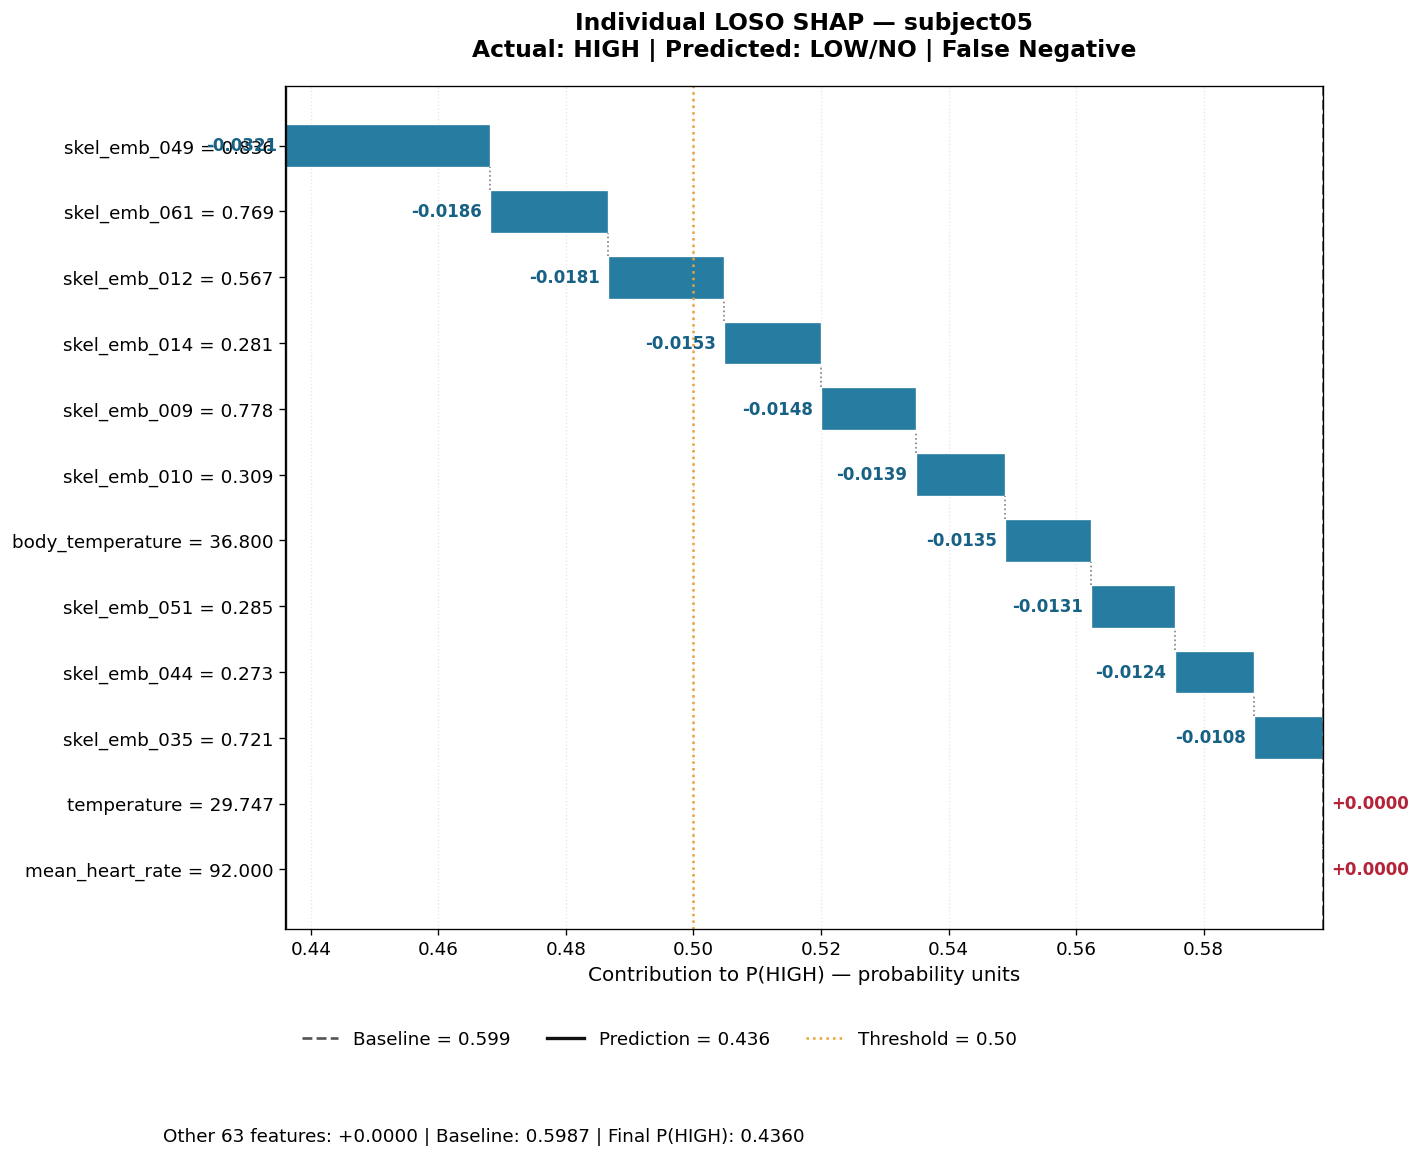


STEP 27.25 COMPLETED

Classification outcomes:


,outcome,n_subjects,mean_probability_high
0,FN,2,0.445976
1,FP,8,0.693654
2,TN,2,0.460809
3,TP,18,0.730454



Selected representative subjects:


,outcome,subject,subject_index,true_class,predicted_class,probability_high
0,TP,subject18,17,HIGH,HIGH,0.887967
1,TN,subject24,23,LOW/NO,LOW/NO,0.444465
2,FP,subject07,6,LOW/NO,HIGH,0.873478
3,FN,subject05,4,HIGH,LOW/NO,0.435992



Saved directories:
All subjects: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal/SHAP_Analysis/SVM__RBF_/All_Features/Individual_OOF_SHAP/All_Subjects
TP/TN/FP/FN examples: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/REVISI-INASS-skeleton_only-Projection_Context_Ablation_OOF_SHAP_15-10-2026/06_Head_to_Head_Baselines/original_multimodal/SHAP_Analysis/SVM__RBF_/All_Features/Individual_OOF_SHAP/TP_TN_FP_FN_Examples

Output files:
 - All_Subjects/01_subject01_TP_SHAP.png
 - All_Subjects/02_subject02_TP_SHAP.png
 - All_Subjects/03_subject03_TP_SHAP.png
 - All_Subjects/04_subject04_FP_SHAP.png
 - All_Subjects/05_subject05_FN_SHAP.png
 - All_Subjects/06_subject06_TP_SHAP.png
 - All_Subjects/07_subject07_FP_SHAP.png
 - All_Subjects/08_subject08_TP_SHAP.png
 - All_Subjects/09_subject09_TN_SHAP.png
 - All_Subjects/10_subject10_TP_SHAP.png
 - All_Subjects/11_subject1

In [ ]:

# ================================================================
# STEP 27.25 CUSTOM INDIVIDUAL OOF SHAP EXPLANATION
#          ALL SUBJECTS + TP/TN/FP/FN EXAMPLES
#
# Compatible with STEP 27:
#   shap_values_all
#   expected_values
#   oof_refit_prob
#   explained_features
#   selected_columns
#   subject_ids
#   y_shap
#   SHAP_DIR
#
# Reviewer 2: LOSO out-of-fold explanation
# Reviewer 6: Publication-ready 300 DPI, font >= 11 pt
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter
from pathlib import Path
import json

# ================================================================
# 27.25.1 CONFIGURATION
# ================================================================

INDIVIDUAL_TOP_N = 12
INDIVIDUAL_DPI = 300
INDIVIDUAL_THRESHOLD = 0.50

INDIVIDUAL_DIR = (
    Path(SHAP_DIR)
    / "Individual_OOF_SHAP"
)

ALL_SUBJECT_DIR = (
    INDIVIDUAL_DIR
    / "All_Subjects"
)

EXAMPLE_DIR = (
    INDIVIDUAL_DIR
    / "TP_TN_FP_FN_Examples"
)

for folder in [
    INDIVIDUAL_DIR,
    ALL_SUBJECT_DIR,
    EXAMPLE_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": INDIVIDUAL_DPI
})

# ================================================================
# 27.25.2 CHECK REQUIRED VARIABLES
# ================================================================

required = [
    "shap_values_all",
    "expected_values",
    "oof_refit_prob",
    "explained_features",
    "selected_columns",
    "subject_ids",
    "y_shap",
    "SHAP_DIR"
]

missing = [
    name
    for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run STEP 27 first. Missing: "
        + ", ".join(missing)
    )

SHAP_VALUES = np.asarray(
    shap_values_all,
    dtype=float
)

BASE_VALUES = np.asarray(
    expected_values,
    dtype=float
).reshape(-1)

PREDICTED_PROBABILITIES = np.asarray(
    oof_refit_prob,
    dtype=float
).reshape(-1)

FEATURE_VALUES = np.asarray(
    explained_features,
    dtype=float
)

FEATURE_NAMES = list(selected_columns)

SUBJECT_NAMES = np.asarray(
    subject_ids
).astype(str)

TRUE_LABELS = np.asarray(
    y_shap,
    dtype=int
).reshape(-1)

N_SUBJECTS = len(SUBJECT_NAMES)
N_FEATURES = len(FEATURE_NAMES)

if SHAP_VALUES.shape != (
    N_SUBJECTS,
    N_FEATURES
):
    raise ValueError(
        "Unexpected SHAP matrix shape."
    )

if FEATURE_VALUES.shape != SHAP_VALUES.shape:
    raise ValueError(
        "Feature values and SHAP values do not align."
    )

if not (
    len(BASE_VALUES)
    == len(PREDICTED_PROBABILITIES)
    == len(TRUE_LABELS)
    == N_SUBJECTS
):
    raise ValueError(
        "Subject-level arrays have different lengths."
    )

if not np.isfinite(SHAP_VALUES).all():
    raise ValueError(
        "SHAP values contain NaN or infinity."
    )

# Check SHAP additivity before plotting
RECONSTRUCTED_PROB = (
    BASE_VALUES
    + SHAP_VALUES.sum(axis=1)
)

MAX_ADDITIVITY_ERROR = float(
    np.max(
        np.abs(
            RECONSTRUCTED_PROB
            - PREDICTED_PROBABILITIES
        )
    )
)

if MAX_ADDITIVITY_ERROR > 1e-3:
    raise RuntimeError(
        "SHAP additivity validation failed: "
        f"{MAX_ADDITIVITY_ERROR}"
    )

print("=" * 72)
print("STEP 27.25 — INDIVIDUAL LOSO SHAP")
print("=" * 72)
print("Subjects:", N_SUBJECTS)
print("Features:", N_FEATURES)
print("Maximum additivity error:", MAX_ADDITIVITY_ERROR)

# ================================================================
# 27.25.3 DEFINE PREDICTION CATEGORIES
# ================================================================

PREDICTED_LABELS = (
    PREDICTED_PROBABILITIES
    >= INDIVIDUAL_THRESHOLD
).astype(int)

def classification_outcome(y_true, y_pred):

    if y_true == 1 and y_pred == 1:
        return "TP"

    if y_true == 0 and y_pred == 0:
        return "TN"

    if y_true == 0 and y_pred == 1:
        return "FP"

    return "FN"

OUTCOMES = np.array([
    classification_outcome(
        true_label,
        predicted_label
    )
    for true_label, predicted_label
    in zip(
        TRUE_LABELS,
        PREDICTED_LABELS
    )
])

OUTCOME_NAMES = {
    "TP": "True Positive",
    "TN": "True Negative",
    "FP": "False Positive",
    "FN": "False Negative"
}

LABEL_NAMES = {
    0: "LOW/NO",
    1: "HIGH"
}

# ================================================================
# 27.25.4 SUBJECT SUMMARY TABLE
# ================================================================

individual_summary_df = pd.DataFrame({
    "subject": SUBJECT_NAMES,
    "y_true": TRUE_LABELS,
    "y_pred": PREDICTED_LABELS,
    "true_class": [
        LABEL_NAMES[value]
        for value in TRUE_LABELS
    ],
    "predicted_class": [
        LABEL_NAMES[value]
        for value in PREDICTED_LABELS
    ],
    "outcome": OUTCOMES,
    "base_probability": BASE_VALUES,
    "predicted_probability_high": (
        PREDICTED_PROBABILITIES
    ),
    "total_shap_contribution": (
        SHAP_VALUES.sum(axis=1)
    ),
    "additivity_error": np.abs(
        RECONSTRUCTED_PROB
        - PREDICTED_PROBABILITIES
    )
})

individual_summary_df.to_csv(
    INDIVIDUAL_DIR
    / "Individual_OOF_SHAP_Summary.csv",
    index=False
)

print("\nClassification outcomes:")
print(
    individual_summary_df[
        "outcome"
    ].value_counts()
)

# ================================================================
# 27.25.5 CUSTOM WATERFALL PLOT
# ================================================================

def plot_individual_oof_shap(
    subject_index,
    output_path=None,
    top_n=12,
    show_plot=True
):
    """
    Individual SHAP waterfall-style chart.

    Blue:
        decreases P(HIGH)

    Red:
        increases P(HIGH)

    Contributions are expressed in probability units.
    """

    i = int(subject_index)

    values = SHAP_VALUES[i].copy()
    features = FEATURE_VALUES[i].copy()

    base = float(BASE_VALUES[i])
    final_prob = float(
        PREDICTED_PROBABILITIES[i]
    )

    # Sort by absolute SHAP contribution
    ranked_indices = np.argsort(
        np.abs(values)
    )[::-1]

    selected_idx = ranked_indices[
        :min(top_n, N_FEATURES)
    ]

    remaining_idx = ranked_indices[
        min(top_n, N_FEATURES):
    ]

    selected_values = values[
        selected_idx
    ]

    selected_names = [
        FEATURE_NAMES[j]
        for j in selected_idx
    ]

    selected_feature_values = features[
        selected_idx
    ]

    # Aggregate all unshown features
    other_contribution = float(
        values[remaining_idx].sum()
    )

    # Construct additive waterfall:
    # start at base + contributions of unshown features,
    # then add displayed features in ascending importance.
    displayed_order = np.argsort(
        np.abs(selected_values)
    )

    ordered_values = selected_values[
        displayed_order
    ]

    ordered_names = [
        selected_names[j]
        for j in displayed_order
    ]

    ordered_feature_values = (
        selected_feature_values[
            displayed_order
        ]
    )

    running = base + other_contribution

    bar_starts = []
    bar_widths = []
    bar_colors = []
    bar_ends = []

    for contribution in ordered_values:

        new_value = running + contribution

        bar_starts.append(
            min(running, new_value)
        )

        bar_widths.append(
            abs(contribution)
        )

        bar_colors.append(
            "#D1495B"
            if contribution >= 0
            else "#277DA1"
        )

        bar_ends.append(new_value)

        running = new_value

    feature_labels = [
        f"{name} = {value:.3f}"
        for name, value in zip(
            ordered_names,
            ordered_feature_values
        )
    ]

    n_bars = len(ordered_values)

    fig_height = max(
        7,
        0.52 * n_bars + 3.5
    )

    fig, ax = plt.subplots(
        figsize=(12, fig_height)
    )

    y_positions = np.arange(
        n_bars
    )

    ax.barh(
        y_positions,
        bar_widths,
        left=bar_starts,
        color=bar_colors,
        height=0.65,
        edgecolor="white",
        linewidth=0.8
    )

    # Draw connectors between contributions
    for j in range(n_bars - 1):

        ax.plot(
            [
                bar_ends[j],
                bar_ends[j]
            ],
            [
                y_positions[j] + 0.33,
                y_positions[j + 1] - 0.33
            ],
            color="gray",
            linestyle=":",
            linewidth=1
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        feature_labels,
        fontsize=11
    )

    # Baseline and final prediction
    ax.axvline(
        base,
        color="#555555",
        linestyle="--",
        linewidth=1.6,
        label=f"Baseline = {base:.3f}"
    )

    ax.axvline(
        final_prob,
        color="#111111",
        linestyle="-",
        linewidth=2,
        label=f"Prediction = {final_prob:.3f}"
    )

    ax.axvline(
        INDIVIDUAL_THRESHOLD,
        color="#E9A23B",
        linestyle=":",
        linewidth=1.5,
        label=f"Threshold = {INDIVIDUAL_THRESHOLD:.2f}"
    )

    # Contribution annotations
    for j, contribution in enumerate(
        ordered_values
    ):

        ax.annotate(
            f"{contribution:+.4f}",
            xy=(
                bar_ends[j],
                y_positions[j]
            ),
            xytext=(
                5 if contribution >= 0 else -5,
                0
            ),
            textcoords="offset points",
            ha=(
                "left"
                if contribution >= 0
                else "right"
            ),
            va="center",
            fontsize=10,
            fontweight="bold",
            color=(
                "#B42338"
                if contribution >= 0
                else "#176185"
            )
        )

    true_name = LABEL_NAMES[
        TRUE_LABELS[i]
    ]

    predicted_name = LABEL_NAMES[
        PREDICTED_LABELS[i]
    ]

    outcome = OUTCOMES[i]

    ax.set_title(
        f"Individual LOSO SHAP — {SUBJECT_NAMES[i]}\n"
        f"Actual: {true_name} | "
        f"Predicted: {predicted_name} | "
        f"{OUTCOME_NAMES[outcome]}",
        fontsize=14,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(
        "Contribution to P(HIGH) — probability units",
        fontsize=12
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.3
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(0, -0.10),
        ncol=3,
        frameon=False,
        fontsize=11
    )

    # Explain omitted contributions
    fig.text(
        0.12,
        0.015,
        (
            f"Other {len(remaining_idx)} features: "
            f"{other_contribution:+.4f} | "
            f"Baseline: {base:.4f} | "
            f"Final P(HIGH): {final_prob:.4f}"
        ),
        fontsize=11
    )

    fig.tight_layout(
        rect=[0, 0.065, 1, 1]
    )

    if output_path is not None:

        fig.savefig(
            output_path,
            dpi=INDIVIDUAL_DPI,
            bbox_inches="tight",
            facecolor="white"
        )

    if show_plot:
        plt.show()

    plt.close(fig)

# ================================================================
# 27.25.6 GENERATE ALL SUBJECT FIGURES
# ================================================================

print("\nGenerating individual SHAP figures...")

for i in range(N_SUBJECTS):

    filename = (
        f"{i + 1:02d}_"
        f"{SUBJECT_NAMES[i]}_"
        f"{OUTCOMES[i]}_SHAP.png"
    )

    plot_individual_oof_shap(
        subject_index=i,
        output_path=(
            ALL_SUBJECT_DIR / filename
        ),
        top_n=INDIVIDUAL_TOP_N,
        show_plot=False
    )

print(
    f"Saved {N_SUBJECTS} individual figures."
)

# ================================================================
# 27.25.7 SELECT TP / TN / FP / FN EXAMPLES
# ================================================================

example_rows = []

for outcome in [
    "TP",
    "TN",
    "FP",
    "FN"
]:

    candidates = np.where(
        OUTCOMES == outcome
    )[0]

    if len(candidates) == 0:

        print(
            f"No {outcome} subjects available."
        )

        continue

    # Choose the most confident prediction
    # within the outcome category.
    if outcome in ["TP", "FP"]:

        selected_i = candidates[
            np.argmax(
                PREDICTED_PROBABILITIES[
                    candidates
                ]
            )
        ]

    else:

        selected_i = candidates[
            np.argmin(
                PREDICTED_PROBABILITIES[
                    candidates
                ]
            )
        ]

    selected_i = int(selected_i)

    example_rows.append({
        "outcome": outcome,
        "subject": SUBJECT_NAMES[selected_i],
        "subject_index": selected_i,
        "true_class": LABEL_NAMES[
            TRUE_LABELS[selected_i]
        ],
        "predicted_class": LABEL_NAMES[
            PREDICTED_LABELS[selected_i]
        ],
        "probability_high": (
            PREDICTED_PROBABILITIES[selected_i]
        )
    })

    filename = (
        f"{outcome}_"
        f"{SUBJECT_NAMES[selected_i]}_SHAP.png"
    )

    plot_individual_oof_shap(
        subject_index=selected_i,
        output_path=(
            EXAMPLE_DIR / filename
        ),
        top_n=INDIVIDUAL_TOP_N,
        show_plot=True
    )

example_df = pd.DataFrame(
    example_rows
)

example_df.to_csv(
    INDIVIDUAL_DIR
    / "Selected_TP_TN_FP_FN_Examples.csv",
    index=False
)

# ================================================================
# 27.25.8 SAVE TOP FEATURE CONTRIBUTIONS PER SUBJECT
# ================================================================

individual_feature_rows = []

for i in range(N_SUBJECTS):

    ranking = np.argsort(
        np.abs(SHAP_VALUES[i])
    )[::-1]

    for rank, j in enumerate(
        ranking,
        start=1
    ):

        individual_feature_rows.append({
            "subject": SUBJECT_NAMES[i],
            "outcome": OUTCOMES[i],
            "rank": rank,
            "feature": FEATURE_NAMES[j],
            "feature_value": (
                FEATURE_VALUES[i, j]
            ),
            "shap_value": (
                SHAP_VALUES[i, j]
            ),
            "abs_shap_value": (
                abs(SHAP_VALUES[i, j])
            ),
            "direction": (
                "Increases P(HIGH)"
                if SHAP_VALUES[i, j] >= 0
                else "Decreases P(HIGH)"
            )
        })

individual_features_df = pd.DataFrame(
    individual_feature_rows
)

individual_features_df.to_csv(
    INDIVIDUAL_DIR
    / "All_Subjects_Feature_Contributions.csv",
    index=False
)

# ================================================================
# 27.25.9 SAVE METADATA
# ================================================================

individual_metadata = {
    "method": "Individual LOSO Kernel SHAP",
    "n_subjects": int(N_SUBJECTS),
    "n_features": int(N_FEATURES),
    "classification_threshold": float(
        INDIVIDUAL_THRESHOLD
    ),
    "top_features_per_figure": int(
        INDIVIDUAL_TOP_N
    ),
    "max_additivity_error": float(
        MAX_ADDITIVITY_ERROR
    ),
    "classification_counts": {
        key: int(np.sum(OUTCOMES == key))
        for key in ["TP", "TN", "FP", "FN"]
    },
    "note": (
        "SHAP explains refitted Stage 2 LOSO models. "
        "Target classes are derived from TUG duration, "
        "not independently observed future falls."
    )
}

with open(
    INDIVIDUAL_DIR / "Individual_SHAP_Metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        individual_metadata,
        file,
        indent=4
    )

# ================================================================
# 27.25.10 FINAL REPORT
# ================================================================

print("\n" + "=" * 72)
print("STEP 27.25 COMPLETED")
print("=" * 72)

print("\nClassification outcomes:")
display(
    individual_summary_df.groupby(
        "outcome"
    ).agg(
        n_subjects=("subject", "count"),
        mean_probability_high=(
            "predicted_probability_high",
            "mean"
        )
    ).reset_index()
)

print("\nSelected representative subjects:")
display(example_df)

print("\nSaved directories:")
print("All subjects:", ALL_SUBJECT_DIR)
print("TP/TN/FP/FN examples:", EXAMPLE_DIR)

print("\nOutput files:")
for file in sorted(
    INDIVIDUAL_DIR.rglob("*")
):
    if file.is_file():
        print(
            " -",
            file.relative_to(INDIVIDUAL_DIR)
        )

print("\nAll individual OOF SHAP figures generated.")


In [ ]:

# ============================================================
# STEP 28 — HYPERPARAMETER CONFIGURATION TABLE
# ============================================================

import pandas as pd

important_params = {
    "Logistic Regression": [
        "C", "penalty", "solver",
        "class_weight", "max_iter"
    ],
    "SVM (RBF)": [
        "C", "kernel", "gamma",
        "class_weight", "probability"
    ],
    "Random Forest": [
        "n_estimators", "max_depth",
        "min_samples_split",
        "min_samples_leaf",
        "class_weight"
    ],
    "Gradient Boosting": [
        "n_estimators", "learning_rate",
        "max_depth", "subsample"
    ]
}

results = []

for model_name, selected_params in important_params.items():

    estimator = make_classical_estimator(
        name=model_name,
        seed=42
    )

    classifier = estimator.named_steps["classifier"]

    all_params = classifier.get_params()

    relevant = {
        key: all_params[key]
        for key in selected_params
        if key in all_params
    }

    results.append({
        "ML Model": model_name,
        "Hyperparameter Configuration": str(relevant)
    })

hyperparameter_table = pd.DataFrame(results)

display(hyperparameter_table)

hyperparameter_table.to_csv(
    "STEP28_Hyperparameter_Configuration.csv",
    index=False
)

print("Hyperparameter table saved.")


,ML Model,Hyperparameter Configuration
0,Logistic Regression,"{'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs',..."
1,SVM (RBF),"{'C': 1.0, 'kernel': 'rbf', 'gamma': 'scale', ..."
2,Random Forest,"{'n_estimators': 300, 'max_depth': None, 'min_..."
3,Gradient Boosting,"{'n_estimators': 100, 'learning_rate': 0.05, '..."


Hyperparameter table saved.


In [ ]:

import inspect

print("=" * 65)
print("MLP HYPERPARAMETER INSPECTION")
print("=" * 65)

parameter_names = [
    "BATCH_SIZE",
    "LEARNING_RATE",
    "BENCHMARK_EPOCHS",
    "BENCHMARK_PATIENCE",
    "BENCHMARK_SEED",
    "DROPOUT_RATE",
    "MLP_HIDDEN_UNITS"
]

for name in parameter_names:
    if name in globals():
        print(f"{name}: {globals()[name]}")
    else:
        print(f"{name}: Not found")

print("\nMLP-related functions:")

for name, obj in list(globals().items()):
    if (
        callable(obj)
        and (
            "mlp" in name.lower()
            or "keras" in name.lower()
        )
        and getattr(obj, "__module__", "") == "__main__"
    ):
        print(f"\nFunction: {name}")
        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source unavailable in current session.")


MLP HYPERPARAMETER INSPECTION
BATCH_SIZE: 8
LEARNING_RATE: 0.001
BENCHMARK_EPOCHS: 200
BENCHMARK_PATIENCE: 20
BENCHMARK_SEED: 42
DROPOUT_RATE: 0.3
MLP_HIDDEN_UNITS: Not found

MLP-related functions:

Function: build_benchmark_proposed_mlp
def build_benchmark_proposed_mlp(groups):

    inputs = []
    feature_branches = []

    for group in groups:

        n_features = len(
            BENCHMARK_FEATURE_GROUPS[group]
        )

        inp = layers.Input(
            shape=(n_features,),
            name=f"{group}_input"
        )

        inputs.append(inp)
        feature_branches.append(inp)

    # Concatenate only when multiple groups are present
    if len(feature_branches) > 1:

        x = layers.Concatenate(
            name="feature_fusion"
        )(feature_branches)

    else:
        x = feature_branches[0]

    # Fixed classifier architecture
    # No skeleton projection layer
    for units in [64, 32, 16]:

        x = layers.Dense(
            units,
            activati